In [ ]:
!python --version

In [2]:
from huggingface_hub import login

login()
# login(skip_if_logged_in=False)

c:\Users\pnvss\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
import os

BASE_DIR = ""  # change this one line to run the notebook from another location

PLOTS_DIR = os.path.join(BASE_DIR, "plots")  # gloss plots
PLOTS_INCLUDE_DIR = os.path.join(PLOTS_DIR, "include")  # INCLUDE-dataset plots

In [4]:
import json
import os

# Open the file and load the data
with open(os.path.join(BASE_DIR, "env.json"), "r", encoding="utf-8") as file:
    env_config = json.load(file)

os.environ["HF_TOKEN"] = env_config["HF_TOKEN"]
os.environ["GOOGLE_DRIVE_API_KEY"] = env_config["GOOGLE_DRIVE_API_KEY"]

# Gloss


In [5]:
USE_GPU = True  # True = run on the GPU (CUDA), False = run on the CPU

TRAIN_CSV = os.path.join(
    BASE_DIR, "input/gloss.csv"
)  # English/gloss pairs used for training
TEST_CSV = os.path.join(
    BASE_DIR, "input/test_gloss.csv"
)  # your test file (english, gloss) scored with BLEU
MODEL_OUTPUT_DIR = os.path.join(
    BASE_DIR, "model/include"
)  # the trained model is saved here
RESULTS_CSV = os.path.join(
    BASE_DIR, "output/include/gloss_test_results.csv"
)  # test predictions with per-sentence BLEU

MODEL_NAME = (
    "google/flan-t5-small"  # "google/flan-t5-base" is more accurate (best with a GPU)
)

EPOCHS = 20  # upper limit; early stopping usually ends sooner
BATCH_SIZE = 32  # lower to 16 or 8 if you run out of GPU memory
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06  # fraction of training steps used to warm up the learning rate
PATIENCE = 3  # stop after this many epochs without validation improvement
VAL_FRACTION = 0.1  # share of TRAIN_CSV held out to decide when to stop
MAX_SRC_LEN = 64  # max English tokens
MAX_TGT_LEN = 64  # max gloss tokens
NUM_BEAMS = 4  # beam search width when generating gloss
SEED = 42
PREFIX = "translate English to ISL gloss: "

In [6]:
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sacrebleu.metrics import BLEU
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

print(
    f"PyTorch {torch.__version__} | CUDA GPU available: {torch.cuda.is_available()} | USE_GPU = {USE_GPU}"
)

PyTorch 2.14.1+cu126 | CUDA GPU available: True | USE_GPU = True


In [7]:
# ------------------------- device, seed, data -------------------------
def get_device():
    """Choose the device from the single USE_GPU switch."""
    if USE_GPU:
        if torch.cuda.is_available():
            return torch.device("cuda")
        print("WARNING: USE_GPU = True but no CUDA GPU was found. Falling back to CPU.")
    return torch.device("cpu")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def clean(text):
    """Collapse repeated spaces and trim."""
    return " ".join(str(text).split())


def load_pairs(path, drop_duplicates=True, verbose=True):
    """Read a tab- or comma-separated file with 'english' and 'gloss' columns."""
    with open(path, encoding="utf-8-sig") as f:
        sep = "\t" if "\t" in f.readline() else ","
    df = pd.read_csv(
        path, sep=sep, encoding="utf-8-sig", dtype=str, keep_default_na=False
    )

    df.columns = [c.strip().lower() for c in df.columns]
    if not {"english", "gloss"}.issubset(df.columns):
        print(
            f"Columns 'english' and 'gloss' not found in {path} {list(df.columns)}; using the first two columns."
        )
        df = df.iloc[:, :2]
        df.columns = ["english", "gloss"]

    df = df[["english", "gloss"]].copy()
    df["english"] = df["english"].map(clean)
    df["gloss"] = df["gloss"].map(clean).str.upper()
    df = df[(df["english"] != "") & (df["gloss"] != "")]
    if drop_duplicates:
        df = df.drop_duplicates()
    df = df.reset_index(drop=True)

    if verbose:
        sep_name = "tab" if sep == "\t" else "comma"
        print(f"Loaded {len(df)} rows from {path} ({sep_name}-separated)")
    return df


class PairDataset(Dataset):
    def __init__(self, df):
        self.src = df["english"].tolist()
        self.tgt = df["gloss"].tolist()

    def __len__(self):
        return len(self.src)

    def __getitem__(self, i):
        return self.src[i], self.tgt[i]


class Collator:
    """Turns a list of (english, gloss) pairs into padded tensors."""

    def __init__(self, tokenizer):
        self.tok = tokenizer

    def __call__(self, batch):
        src, tgt = zip(*batch)
        enc = self.tok(
            [PREFIX + s for s in src],
            max_length=MAX_SRC_LEN,
            truncation=True,
            padding=True,
            return_tensors="pt",
        )
        # The gloss is learned in lowercase (fewer, more common sub-word pieces that
        # match the English input) and turned back into UPPERCASE when generating.
        lab = self.tok(
            text_target=[t.lower() for t in tgt],
            max_length=MAX_TGT_LEN,
            truncation=True,
            padding=True,
            return_tensors="pt",
        )
        labels = lab["input_ids"]
        labels[labels == self.tok.pad_token_id] = -100  # padding is ignored by the loss
        enc["labels"] = labels
        return enc

In [8]:
# ------------------------- generation / loading -------------------------
@torch.no_grad()
def generate_gloss(
    texts, model, tokenizer, device, num_beams=None, batch_size=64, progress=False
):
    """Gloss one string or a list of strings. Returns the same shape it was given."""
    num_beams = num_beams or NUM_BEAMS
    single = isinstance(texts, str)
    texts = [texts] if single else list(texts)
    model.eval()
    results = []
    starts = range(0, len(texts), batch_size)
    for i in (tqdm(starts, desc="Generating gloss") if progress else starts):
        chunk = [PREFIX + clean(t) for t in texts[i : i + batch_size]]
        enc = tokenizer(
            chunk,
            max_length=MAX_SRC_LEN,
            truncation=True,
            padding=True,
            return_tensors="pt",
        ).to(device)
        out = model.generate(**enc, max_new_tokens=MAX_TGT_LEN, num_beams=num_beams)
        results += [
            clean(g).upper()
            for g in tokenizer.batch_decode(out, skip_special_tokens=True)
        ]
    return results[0] if single else results


def load_trained_model(device):
    if not os.path.isdir(MODEL_OUTPUT_DIR):
        raise FileNotFoundError(
            f"No trained model in '{MODEL_OUTPUT_DIR}'. Run the training cell (4) first."
        )
    tokenizer = AutoTokenizer.from_pretrained(MODEL_OUTPUT_DIR)
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_OUTPUT_DIR).to(device).eval()
    return model, tokenizer

In [9]:
# ------------------------------ scoring ------------------------------
def word_edit_distance(a, b):
    a, b = a.split(), b.split()
    prev = list(range(len(b) + 1))
    for i, wa in enumerate(a, 1):
        cur = [i] + [0] * len(b)
        for j, wb in enumerate(b, 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (wa != wb))
        prev = cur
    return prev[-1]


def gloss_scores(preds, refs):
    """Corpus BLEU-1..4 (BLEU-4 is the standard BLEU score), exact match and word error rate."""
    scores = {}
    for n in range(1, 5):
        scores[f"BLEU-{n}"] = BLEU(max_ngram_order=n).corpus_score(preds, [refs]).score
    scores["Exact match %"] = 100 * sum(p == r for p, r in zip(preds, refs)) / len(refs)
    errors = sum(word_edit_distance(p, r) for p, r in zip(preds, refs))
    scores["WER %"] = 100 * errors / max(1, sum(len(r.split()) for r in refs))
    return scores


_SENTENCE_BLEU = BLEU(effective_order=True)


def sentence_bleu(pred, ref):
    """BLEU for a single sentence (0-100)."""
    return _SENTENCE_BLEU.sentence_score(pred, [ref]).score


def print_scores(scores):
    for name, value in scores.items():
        note = "   <- standard BLEU" if name == "BLEU-4" else ""
        print(f"  {name:<14}{value:7.2f}{note}")

In [10]:
# ------------------------- training -------------------------
@torch.no_grad()
def validation_loss(model, loader, device):
    model.eval()
    total, count = 0.0, 0
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        n = batch["input_ids"].size(0)
        total += model(**batch).loss.item() * n
        count += n
    return total / max(1, count)


def prepare_gloss_data():
    """Load TRAIN_CSV, shuffle it and hold out VAL_FRACTION as the validation set. Returns (train_df, val_df)."""
    data = (
        load_pairs(TRAIN_CSV).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    )
    n_val = max(1, int(len(data) * VAL_FRACTION))
    val_df, train_df = data.iloc[:n_val], data.iloc[n_val:]
    print(f"Train: {len(train_df)}   Validation: {len(val_df)}")
    return train_df, val_df


def train_gloss_model(train_df, val_df, device):
    """
    Fine-tune MODEL_NAME on (english, gloss) pairs. The best checkpoint (lowest validation loss) is saved to
    MODEL_OUTPUT_DIR. Returns the per-epoch history (train / validation loss, validation BLEU-3 / BLEU-4).
    """
    set_seed(SEED)

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)

    collate = Collator(tokenizer)
    pin = device.type == "cuda"
    train_loader = DataLoader(
        PairDataset(train_df),
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=collate,
        pin_memory=pin,
    )
    val_loader = DataLoader(
        PairDataset(val_df),
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate,
        pin_memory=pin,
    )

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    total_steps = EPOCHS * len(train_loader)
    warmup_steps = max(1, int(WARMUP_RATIO * total_steps))
    scheduler = (
        torch.optim.lr_scheduler.LambdaLR(  # linear warm-up, then linear decay to zero
            optimizer,
            lambda step: (
                (step + 1) / warmup_steps
                if step < warmup_steps
                else max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))
            ),
        )
    )

    sample_src = val_df["english"].tolist()[:2]
    sample_ref = val_df["gloss"].tolist()[:2]
    val_src_list = val_df["english"].tolist()
    val_ref_list = val_df["gloss"].tolist()

    best_val, bad_epochs = float("inf"), 0

    # --- Initialize history lists for plotting ---
    train_losses = []
    val_losses = []
    val_bleu_4_scores, val_bleu_3_scores = [], []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running = 0.0
        for batch in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}", leave=False):
            batch = {k: v.to(device, non_blocking=pin) for k, v in batch.items()}
            loss = model(**batch).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            running += loss.item()

        train_loss = running / len(train_loader)
        val_loss = validation_loss(model, val_loader, device)

        # --- Compute validation BLEU-4 for this epoch ---
        epoch_val_preds = generate_gloss(
            val_src_list, model, tokenizer, device, num_beams=1
        )
        epoch_val_metrics = gloss_scores(epoch_val_preds, val_ref_list)
        val_bleu_3 = epoch_val_metrics["BLEU-3"]
        val_bleu_4 = epoch_val_metrics["BLEU-4"]

        # --- Record metrics in history lists ---
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_bleu_3_scores.append(val_bleu_3)
        val_bleu_4_scores.append(val_bleu_4)

        print(
            f"Epoch {epoch:2d}/{EPOCHS}   train loss {train_loss:.4f}   val loss {val_loss:.4f}   val BLEU-3 {val_bleu_3:.2f}   val BLEU-4 {val_bleu_4:.2f}"
        )
        for s, r, p in zip(sample_src, sample_ref, epoch_val_preds[:2]):
            print(f"   EN: {s}\n   REF: {r}\n   PRED: {p}")

        if val_loss < best_val - 1e-4:
            best_val, bad_epochs = val_loss, 0
            model.save_pretrained(MODEL_OUTPUT_DIR)
            tokenizer.save_pretrained(MODEL_OUTPUT_DIR)
            print(f"   -> best so far, saved to {MODEL_OUTPUT_DIR}/")
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print(f"No improvement for {PATIENCE} epochs, stopping early.")
                break

    return {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "val_bleu_3_scores": val_bleu_3_scores,
        "val_bleu_4_scores": val_bleu_4_scores,
    }

In [11]:
# ------------------------- evaluation / plots -------------------------
def evaluate_gloss_validation(model, tokenizer, device, val_df):
    """Corpus scores of the (best, loaded) model on the held-out validation split."""
    val_src_list = val_df["english"].tolist()
    val_ref_list = val_df["gloss"].tolist()
    val_preds = generate_gloss(
        val_src_list, model, tokenizer, device, num_beams=NUM_BEAMS
    )
    print(f"\nBest Model Validation Scores ({len(val_df)} sentences):")
    scores = gloss_scores(val_preds, val_ref_list)
    print_scores(scores)
    return scores


def plot_training_history(history):
    """Plot training / validation loss and validation BLEU-4 per epoch (history comes from train_gloss_model)."""
    train_losses = history["train_losses"]
    val_losses = history["val_losses"]
    val_bleu_4_scores = history["val_bleu_4_scores"]

    if len(train_losses) > 0:
        epochs_range = range(1, len(train_losses) + 1)
        plt.figure(figsize=(12, 5))

        plt.subplot(2, 2, 1)
        plt.plot(epochs_range, train_losses, label="Train Loss", marker="o")
        plt.plot(epochs_range, val_losses, label="Validation Loss", marker="o")
        plt.title("Training and Validation Loss per Epoch")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.xticks(epochs_range)
        plt.legend()
        plt.grid(True)

        plt.subplot(2, 2, 2)
        plt.plot(
            epochs_range,
            val_bleu_4_scores,
            label="Validation BLEU-4",
            color="green",
            marker="s",
        )
        plt.title("Validation BLEU-4 Score per Epoch")
        plt.xlabel("Epoch")
        plt.ylabel("BLEU-4 Score")
        plt.xticks(epochs_range)
        plt.legend()
        plt.grid(True)

        plt.tight_layout()
        os.makedirs(PLOTS_DIR, exist_ok=True)
        plt.savefig(os.path.join(PLOTS_DIR, "training_metrics.png"), dpi=300)
        plt.show()
    else:
        print("Training history is empty. Run the training step (1.4) first.")


def evaluate_gloss_test(model, tokenizer, device, eval_df, eval_name):
    """Corpus BLEU-1..4 / exact match / WER plus per-sentence BLEU; predictions are written to RESULTS_CSV."""
    preds = generate_gloss(
        eval_df["english"].tolist(),
        model,
        tokenizer,
        device,
        num_beams=NUM_BEAMS,
        progress=True,
    )
    refs = eval_df["gloss"].tolist()

    print(
        f"\nCorpus BLEU & Evaluation Metrics on {eval_name} ({len(eval_df)} sentences):"
    )
    corpus_metrics = gloss_scores(preds, refs)
    print_scores(corpus_metrics)

    # Save per-sentence predictions and sentence BLEU scores to RESULTS_CSV
    results_df = eval_df.copy()
    results_df["predicted_gloss"] = preds
    results_df["sentence_bleu"] = [
        round(sentence_bleu(p, r), 2) for p, r in zip(preds, refs)
    ]

    os.makedirs(os.path.dirname(RESULTS_CSV) or ".", exist_ok=True)
    results_df.to_csv(RESULTS_CSV, index=False, encoding="utf-8")
    print(f"\nSaved per-sentence BLEU results to '{RESULTS_CSV}'.")
    return corpus_metrics, results_df

In [11]:
device = get_device()
print(
    "Device:",
    device,
    f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "",
)

train_df, val_df = prepare_gloss_data()

Device: cuda (NVIDIA GeForce RTX 3050 Ti Laptop GPU)
Loaded 1000 rows from ../input/gloss.csv (comma-separated)
Train: 900   Validation: 100


In [12]:
gloss_history = train_gloss_model(train_df, val_df, device)

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 3871.78it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Epoch  1/20   train loss 3.0586   val loss 0.5387   val BLEU-3 71.59   val BLEU-4 65.45
   EN: This morning, the beautiful small photograph on the table was old and dirty.
   REF: TODAY MORNING TABLE PHOTOGRAPH BEAUTIFUL SMALL OLD DIRTY
   PRED: TODAY MORNING TABLE PHOTOGRAPH BEAUTIFUL SMALL OLD DIRTY
   EN: In spring, the evenings in the city are beautiful, and the nights are short.
   REF: SPRING CITY EVENING BEAUTIFUL NIGHT SHORT
   PRED: SPRING CITY EVENING BEAUTIFUL NIGHT SHORT


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.60it/s]


   -> best so far, saved to ../model/include/


Epoch  2/20   train loss 0.5604   val loss 0.0663   val BLEU-3 93.65   val BLEU-4 92.10
   EN: This morning, the beautiful small photograph on the table was old and dirty.
   REF: TODAY MORNING TABLE PHOTOGRAPH BEAUTIFUL SMALL OLD DIRTY
   PRED: TODAY MORNING TABLE PHOTOGRAPH BEAUTIFUL SMALL OLD DIRTY
   EN: In spring, the evenings in the city are beautiful, and the nights are short.
   REF: SPRING CITY EVENING BEAUTIFUL NIGHT SHORT
   PRED: SPRING CITY EVENING BEAUTIFUL NIGHT SHORT


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.32it/s]


... (17 outputs left out)

   -> best so far, saved to ../model/include/


Epoch 10/20   train loss 0.0133   val loss 0.0001   val BLEU-3 100.00   val BLEU-4 100.00
   EN: This morning, the beautiful small photograph on the table was old and dirty.
   REF: TODAY MORNING TABLE PHOTOGRAPH BEAUTIFUL SMALL OLD DIRTY
   PRED: TODAY MORNING TABLE PHOTOGRAPH BEAUTIFUL SMALL OLD DIRTY
   EN: In spring, the evenings in the city are beautiful, and the nights are short.
   REF: SPRING CITY EVENING BEAUTIFUL NIGHT SHORT
   PRED: SPRING CITY EVENING BEAUTIFUL NIGHT SHORT


Epoch 11/20   train loss 0.0142   val loss 0.0001   val BLEU-3 100.00   val BLEU-4 100.00
   EN: This morning, the beautiful small photograph on the table was old and dirty.
   REF: TODAY MORNING TABLE PHOTOGRAPH BEAUTIFUL SMALL OLD DIRTY
   PRED: TODAY MORNING TABLE PHOTOGRAPH BEAUTIFUL SMALL OLD DIRTY
   EN: In spring, the evenings in the city are beautiful, and the nights are short.
   REF: SPRING CITY EVENING BEAUTIFUL NIGHT SHORT
   PRED: SPRING CITY EVENING BEAUTIFUL NIGHT SHORT


Epoch 12/20   train loss 0.0125   val loss 0.0001   val BLEU-3 100.00   val BLEU-4 100.00
   EN: This morning, the beautiful small photograph on the table was old and dirty.
   REF: TODAY MORNING TABLE PHOTOGRAPH BEAUTIFUL SMALL OLD DIRTY
   PRED: TODAY MORNING TABLE PHOTOGRAPH BEAUTIFUL SMALL OLD DIRTY
   EN: In spring, the evenings in the city are beautiful, and the nights are short.
   REF: SPRING CITY EVENING BEAUTIFUL NIGHT SHORT
   PRED: SPRING CITY EVENING BEAUTIFUL NIGHT SHORT
No improvement for 3 epochs, stopping early.


In [13]:
# Always loads the best checkpoint from disk (also after a kernel restart).
if device.type == "cuda":
    torch.cuda.empty_cache()
model, tokenizer = load_trained_model(device)
print(f"Loaded model from {MODEL_OUTPUT_DIR}/ on {device}")

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 8234.07it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Loaded model from ../model/include/ on cuda


In [14]:
gloss_val_scores = evaluate_gloss_validation(model, tokenizer, device, val_df)


Best Model Validation Scores (100 sentences):
  BLEU-1         100.00
  BLEU-2         100.00
  BLEU-3         100.00
  BLEU-4         100.00   <- standard BLEU
  Exact match %  100.00
  WER %            0.00


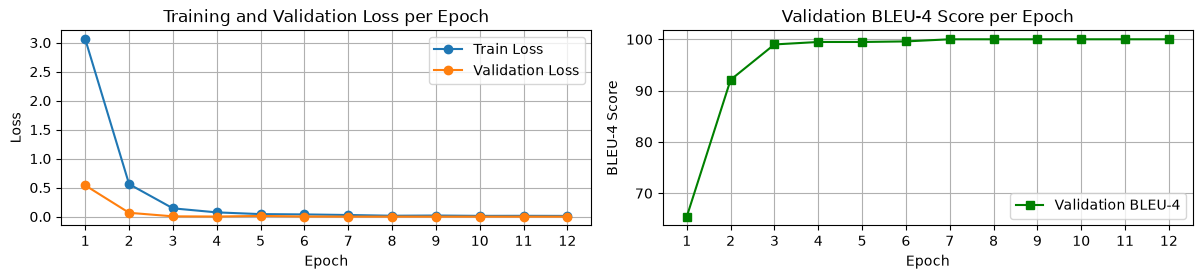

In [15]:
plot_training_history(gloss_history)

In [16]:
# Test file if it exists, otherwise the validation split.
eval_df = load_pairs(TEST_CSV) if os.path.exists(TEST_CSV) else val_df.copy()
eval_name = TEST_CSV if os.path.exists(TEST_CSV) else "Validation Split"

gloss_test_scores, gloss_results_df = evaluate_gloss_test(
    model, tokenizer, device, eval_df, eval_name
)

Loaded 100 rows from ../input/test_gloss.csv (comma-separated)


Generating gloss: 100%|██████████| 2/2 [00:00<00:00,  2.01it/s]


Corpus BLEU & Evaluation Metrics on ../input/test_gloss.csv (100 sentences):
  BLEU-1         100.00
  BLEU-2         100.00
  BLEU-3         100.00
  BLEU-4         100.00   <- standard BLEU
  Exact match %  100.00
  WER %            0.00

Saved per-sentence BLEU results to '../output/include/gloss_test_results.csv'.


# Datasets


In [ ]:
import re
import shutil
import tempfile
import zipfile
from pathlib import Path

from kaggle.api.kaggle_api_extended import KaggleApi


def list_kaggle_files(api, dataset):
    """All file paths of a Kaggle dataset (follows the page tokens), sorted, with '\\' replaced by '/'."""
    print("Fetching dataset file list...")

    response = api.dataset_list_files(dataset, page_size=200)
    all_files = list(response.files)

    page_token = getattr(response, "nextPageToken", None)

    while page_token:
        response = api.dataset_list_files(dataset, page_size=200, page_token=page_token)
        all_files.extend(response.files)
        page_token = getattr(response, "nextPageToken", None)

    return sorted(f.name.replace("\\", "/") for f in all_files)


def get_file_name(file_path):
    """Local file name = the last path component."""
    return Path(file_path).name


def download_kaggle_videos_per_word(
    api, dataset, word_files, output_dir, videos_per_word, relative_name
):
    """
    Download up to `videos_per_word` videos for every word into output_dir/<word>/<relative_name(path)>.
    Files that already exist are counted and not downloaded again. Returns the number of downloaded videos.
    """
    total_downloaded = 0

    for word, files in sorted(word_files.items()):
        files = sorted(files)
        word_dir = output_dir / word
        word_dir.mkdir(parents=True, exist_ok=True)

        # Count downloaded files by matching the relative filename.
        existing_files = set()

        for file_path in files:
            local_path = word_dir / relative_name(file_path)
            if local_path.is_file():
                existing_files.add(file_path)

        M = len(existing_files)

        print(f"\nWord: {word}")
        print(f"Existing videos: {M}/{videos_per_word}")

        if M >= videos_per_word:
            print("Limit reached. Skipping.")
            continue

        missing_files = [path for path in files if path not in existing_files]

        for file_path in missing_files[: videos_per_word - M]:
            relative_filename = relative_name(file_path)
            local_path = word_dir / relative_filename
            local_path.parent.mkdir(parents=True, exist_ok=True)

            print(f"Downloading: {file_path}")

            try:
                with tempfile.TemporaryDirectory() as temp:
                    api.dataset_download_file(dataset, file_path, path=temp, force=True)

                    temp_dir = Path(temp)
                    archives = list(temp_dir.glob("*.zip"))

                    if archives:
                        with zipfile.ZipFile(archives[0]) as archive:
                            target_name = Path(relative_filename).name
                            matches = [
                                name
                                for name in archive.namelist()
                                if Path(name).name == target_name
                                and not name.endswith("/")
                            ]

                            if not matches:
                                raise FileNotFoundError(
                                    f"{target_name} was not found in ZIP."
                                )

                            with archive.open(matches[0]) as src:
                                with local_path.open("wb") as dst:
                                    shutil.copyfileobj(src, dst)
                    else:
                        matches = [
                            p
                            for p in temp_dir.rglob("*")
                            if p.is_file() and p.name == Path(relative_filename).name
                        ]

                        if not matches:
                            raise FileNotFoundError(
                                f"Download not found for {file_path}"
                            )

                        shutil.copy2(matches[0], local_path)

                total_downloaded += 1
                print(f"Saved: {local_path}")

            except Exception as error:
                if local_path.exists():
                    local_path.unlink()

                print(f"ERROR: {file_path}: {error}")

    return total_downloaded

## Include


In [ ]:
INCLUDE_DATASET = "ravijavitharana/include50g"
INCLUDE_OUTPUT_DIR = Path(BASE_DIR) / "input/include/include_dataset"

INCLUDE_VIDEOS_PER_WORD = 5  # videos downloaded per word

INCLUDE_CATEGORIES = None
INCLUDE_WORDS = None
INCLUDE_FILES = None

# Kaggle folder name (after removing the "12. " number) -> local word folder(s).
# One entry with several folders = the same videos are saved in each folder.
# An empty list = skip that folder. Keys are matched case-insensitively.
WORD_NAME_OVERRIDES = {
    "small little": ["small", "little"],
    "big large": ["big", "large"],
    "Street or Road": ["Street", "Road"],
    "Store or Shop": ["Store", "Shop"],
    "Ex. Monsoon": ["Monsoon"],
    "Race (ethnicity)": ["Race"],
    "you (plural)": [],  # a "you" folder already exists
}
WORD_NAME_OVERRIDES = {
    " ".join(k.split()).lower(): v for k, v in WORD_NAME_OVERRIDES.items()
}

In [ ]:
def clean_word_name(word):
    # "1. Actor" -> "Actor"
    # "12. Happy" -> "Happy"
    return re.sub(r"^\s*\d+\s*\.\s*", "", word).strip()


def get_relative_filename(file_path):
    # Category/Word/Extra/video.mp4 -> video.mp4 (the "Extra" sub-folder is merged into the word folder)
    parts = file_path.split("/")[2:]
    return "/".join(p for p in parts if p.lower() != "extra")


def get_word_names(original_word):
    """Local word folder name(s) for a Kaggle word folder ("12. Happy" -> ["Happy"]), see WORD_NAME_OVERRIDES."""
    clean = clean_word_name(original_word)
    key = " ".join(clean.split()).lower()
    return WORD_NAME_OVERRIDES.get(key, [clean] if clean else [])


def group_include_files(file_paths, categories=None, words=None, files=None):
    """Filter the Kaggle file list (category / word / file selections) and group it by cleaned word name."""
    word_files = {}

    for file_path in file_paths:
        parts = file_path.split("/")

        if len(parts) < 3:
            continue

        category, original_word = parts[0], parts[1]
        filename = get_relative_filename(file_path)

        if categories is not None and category not in categories:
            continue

        if words is not None:
            selected_words = words.get(category)
            if selected_words is not None and original_word not in selected_words:
                continue

        if files is not None:
            category_rules = files.get(category, {})
            selected_names = category_rules.get(original_word)

            if selected_names is not None and filename not in selected_names:
                continue

        for word in get_word_names(original_word):
            word_files.setdefault(word, []).append(file_path)

    return word_files

In [ ]:
# Sanity check that the Kaggle CLI is installed and authenticated.
import subprocess

result = subprocess.run(
    ["kaggle", "datasets", "files", "-d", INCLUDE_DATASET],
    capture_output=True,
    text=True,
)

print("Return code:", result.returncode)
print("STDOUT:", repr(result.stdout))
print("STDERR:", repr(result.stderr))

In [ ]:
# List every category and word of the dataset.
api = KaggleApi()
api.authenticate()

file_paths = list_kaggle_files(api, INCLUDE_DATASET)
print(f"Total files found: {len(file_paths)}")

# =====================================================
# EXTRACT ALL CATEGORIES AND WORDS
# =====================================================

categories = {}

for file_path in file_paths:
    parts = file_path.split("/")

    # Expected structure: category/word/filename
    if len(parts) < 3:
        continue

    category = parts[0]
    word = parts[1]

    if category not in categories:
        categories[category] = set()

    categories[category].add(word)

# =====================================================
# DISPLAY ALL WORDS BY CATEGORY
# =====================================================

include_all_words = []
total_words = 0

for category in sorted(categories):
    words = sorted(categories[category])

    # print(f"\n{category} ({len(words)} words)")
    # print("-" * 50)

    # for word in words:
    #     print(word)

    include_all_words.extend(words)
    total_words += len(words)

print("\n" + "=" * 50)
print(f"Total categories: {len(categories)}")
print(f"Total unique category-word combinations: {total_words}")
print(include_all_words)

In [ ]:
# Download INCLUDE_VIDEOS_PER_WORD videos per word into INCLUDE_OUTPUT_DIR.
if INCLUDE_VIDEOS_PER_WORD < 1:
    raise ValueError("N must be at least 1.")

INCLUDE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

api = KaggleApi()
api.authenticate()

file_paths = list_kaggle_files(api, INCLUDE_DATASET)
print(f"Found {len(file_paths)} files.")

word_files = group_include_files(
    file_paths, INCLUDE_CATEGORIES, INCLUDE_WORDS, INCLUDE_FILES
)

total_downloaded = download_kaggle_videos_per_word(
    api,
    INCLUDE_DATASET,
    word_files,
    INCLUDE_OUTPUT_DIR,
    INCLUDE_VIDEOS_PER_WORD,
    relative_name=get_relative_filename,
)

print(f"\nFinished. Downloaded {total_downloaded} videos.")

Extra: \
Adjectives/Beautiful \
Animals/Bird \
Places/Bank \
Places/Ground \
Places/Court \
Places/House \
Places/India \
Places/Location \
Places/Market \
Places/Park \
Places/Train Station \
Places/Temple \
Places/University

Name: \
small little \
big large \
Ex. Monsoon \
you (plural) \
Street or Road \
Store or Shop \
Race (ethnicity)


## iSign


In [ ]:
import os
import requests
import zipfile
from huggingface_hub import hf_hub_url

ISIGN_REPO_ID = "Exploration-Lab/iSign"
ISIGN_REPO_TYPE = "dataset"

ISIGN_PARTS = [
    "iSign-videos_v1.1_part_aa",
    "iSign-videos_v1.1_part_ab",
]


class RemoteConcatFile:
    """
    Makes two remote files behave like one large seekable file.

    No full download happens.
    Only requested byte ranges are downloaded.
    """

    def __init__(self, urls, sizes, headers):
        self.urls = urls
        self.sizes = sizes
        self.headers = headers
        self.offsets = []

        total = 0

        for size in sizes:
            self.offsets.append(total)
            total += size

        self.total_size = total
        self.position = 0

    def tell(self):
        return self.position

    def seek(self, offset, whence=0):
        if whence == 0:
            new_position = offset
        elif whence == 1:
            new_position = self.position + offset
        elif whence == 2:
            new_position = self.total_size + offset
        else:
            raise ValueError("Invalid whence")

        if new_position < 0:
            raise ValueError("Negative seek position")

        self.position = new_position
        return self.position

    def _find_part(self, position):
        for i in range(len(self.sizes) - 1, -1, -1):
            if position >= self.offsets[i]:
                return i

        raise ValueError("Invalid position")

    def read(self, size=-1):
        if self.position >= self.total_size:
            return b""

        if size is None or size < 0:
            size = self.total_size - self.position

        size = min(size, self.total_size - self.position)

        result = bytearray()

        remaining = size

        while remaining > 0:
            part_index = self._find_part(self.position)

            part_start = self.offsets[part_index]
            part_size = self.sizes[part_index]

            position_inside_part = self.position - part_start

            available = part_size - position_inside_part
            to_read = min(remaining, available)

            start = position_inside_part
            end = start + to_read - 1

            headers = dict(self.headers)
            headers["Range"] = f"bytes={start}-{end}"

            response = requests.get(self.urls[part_index], headers=headers, timeout=120)

            response.raise_for_status()

            data = response.content

            if len(data) != to_read:
                raise IOError(
                    f"Expected {to_read} bytes, " f"received {len(data)} bytes"
                )

            result.extend(data)

            self.position += len(data)
            remaining -= len(data)

        return bytes(result)

    def readable(self):
        return True

    def seekable(self):
        return True


def _isign_remote_file_info(filename, token):
    """
    Get final URL and size for a gated Hugging Face file.
    """

    url = hf_hub_url(
        repo_id=ISIGN_REPO_ID, filename=filename, repo_type=ISIGN_REPO_TYPE
    )

    headers = {"Authorization": f"Bearer {token}"}

    # Ask for the first byte.
    response = requests.get(
        url,
        headers={**headers, "Range": "bytes=0-0"},
        allow_redirects=True,
        timeout=120,
    )

    response.raise_for_status()

    content_range = response.headers.get("Content-Range")

    if content_range:
        # Example:
        # bytes 0-0/32200000000
        total_size = int(content_range.split("/")[-1])
    else:
        # Some servers may return the whole response.
        total_size = int(response.headers["Content-Length"])

    return response.url, total_size


def download_isign_video(
    uid, output_dir=os.path.join(BASE_DIR, "input/isign/isign_dataset/isign_videos")
):
    """
    Download exactly one iSign video corresponding to a UID.

    Example:
        download_isign_video("1782bea75c7d-7")

    Or:
        download_isign_video(train[0]["uid"])
    """

    token = os.environ.get("HF_TOKEN")

    if not token:
        raise RuntimeError(
            "HF_TOKEN is not set. Set it with os.environ['HF_TOKEN'] = 'your_token'"
        )

    # ---------------------------------------------------------
    # Extract video_id from UID
    # ---------------------------------------------------------

    video_id, sequence_number = uid.rsplit("-", 1)

    print("UID:", uid)
    print("Video ID:", video_id)
    print("Sequence:", sequence_number)

    # ---------------------------------------------------------
    # Get remote URLs and sizes
    # ---------------------------------------------------------

    urls = []
    sizes = []

    print("\nGetting remote archive information...")

    for part in ISIGN_PARTS:
        print("Checking:", part)

        url, size = _isign_remote_file_info(part, token)

        urls.append(url)
        sizes.append(size)

        print(f"  Size: {size / (1024**3):.2f} GB")

    total_size = sum(sizes)

    print(f"\nLogical ZIP size: {total_size / (1024**3):.2f} GB")

    # ---------------------------------------------------------
    # Create virtual concatenated ZIP
    # ---------------------------------------------------------

    remote_file = RemoteConcatFile(
        urls=urls, sizes=sizes, headers={"Authorization": f"Bearer {token}"}
    )

    # ---------------------------------------------------------
    # Read ZIP central directory remotely
    # ---------------------------------------------------------

    print("\nReading ZIP index remotely...")

    with zipfile.ZipFile(remote_file, "r") as z:
        names = z.namelist()

        print(f"ZIP contains {len(names):,} entries")

        # -----------------------------------------------------
        # Find the requested video
        # -----------------------------------------------------

        target_filename = f"{uid}.mp4"

        candidates = [
            name for name in names if os.path.basename(name) == target_filename
        ]

        # -----------------------------------------------------
        # If no match, show useful candidates
        # -----------------------------------------------------

        if not candidates:
            raise FileNotFoundError(f"Could not find exact video: {target_filename}")

        video_name = candidates[0]

        print("Found exact video:")
        print(video_name)

        # -----------------------------------------------------
        # Output path
        # -----------------------------------------------------

        os.makedirs(output_dir, exist_ok=True)

        extension = os.path.splitext(video_name)[1]

        if not extension:
            extension = ".mp4"

        output_path = os.path.join(output_dir, f"{video_id}{extension}")

        # -----------------------------------------------------
        # Download ONLY this ZIP entry
        # -----------------------------------------------------

        info = z.getinfo(video_name)

        print(f"\nVideo compressed size: {info.compress_size / (1024**2):.2f} MB")
        print(f"Video uncompressed size: {info.file_size / (1024**2):.2f} MB")
        print("\nDownloading requested video...")

        with z.open(info, "r") as source, open(output_path, "wb") as destination:
            while True:
                chunk = source.read(1024 * 1024)

                if not chunk:
                    break

                destination.write(chunk)

        print("\nDone!")
        print("Saved to:", output_path)

        return output_path


def get_isign_sample_by_index(train_split, index):
    row = train_split[index]

    uid = row["uid"]
    text = row["text"]

    video_path = download_isign_video(uid)

    return {"uid": uid, "video": video_path, "text": text}


def get_isign_sample(uid):
    video_path = download_isign_video(uid)

    return {"uid": uid, "video": video_path}

In [ ]:
# List sentences
from datasets import load_dataset

ds = load_dataset("Exploration-Lab/iSign", "iSign_v1.1")

train = ds["train"]

print(train)
print(train.column_names)

for i in range(10):
    print(train[i])

In [ ]:
sample = get_isign_sample_by_index(6)
print(sample)

In [ ]:
sample = get_isign_sample("1782bea75c7d-7")
print(sample)

## ISLRTC


In [ ]:
import os
from pathlib import Path
import gdown

VIDEO_EXTENSIONS = {".mp4", ".mov", ".avi", ".mkv", ".webm", ".flv", ".wmv"}


def download_videos_from_drive_folder(
    folder_url_or_id: str,
    output_dir: str = "../input/islrtc",
    keep_only_videos: bool = True,
):
    """Downloads all files from a public Google Drive folder and filters for video formats.

    :param folder_url_or_id: Public Google Drive folder URL or Folder ID.
    :param output_dir: Local directory where videos will be stored.
    :param keep_only_videos: If True, deletes any non-video files downloaded.
    """
    os.makedirs(output_dir, exist_ok=True)

    # Format URL if raw ID was provided
    if not folder_url_or_id.startswith("http"):
        folder_url = f"https://drive.google.com/drive/folders/{folder_url_or_id}"
    else:
        folder_url = folder_url_or_id

    print(f"Downloading folder contents to '{output_dir}'...")
    # Download entire folder contents
    downloaded_files = gdown.download_folder(
        url=folder_url, output=output_dir, quiet=False, use_cookies=False
    )

    if not downloaded_files:
        print("No files retrieved. Ensure the folder is set to 'Anyone with the link'.")
        return []

    # Filter and collect video files
    video_files = []
    for file_path in Path(output_dir).rglob("*"):
        if file_path.is_file():
            if file_path.suffix.lower() in VIDEO_EXTENSIONS:
                video_files.append(str(file_path))
            elif keep_only_videos:
                file_path.unlink()  # Remove non-video file

    print(f"\nCompleted! Total video files downloaded: {len(video_files)}")
    return video_files

In [ ]:
def download_videos_from_drive_file_list(
    ids: dict,
    output_dir: str = os.path.join(BASE_DIR, "input/islrtc"),
):
    """
    Downloads Google Drive videos into individual folders.

    Uses dictionary keys as folder and file names.
    Skips files that already exist.
    """
    os.makedirs(output_dir, exist_ok=True)
    downloaded_paths = []

    for index, (filename, file_id) in enumerate(ids.items(), start=1):
        print(f"\n[{index}/{len(ids)}] Processing: {filename}")

        # Create folder using dictionary key
        folder_path = os.path.join(output_dir, filename)
        os.makedirs(folder_path, exist_ok=True)

        # Destination file path
        dest_path = os.path.join(folder_path, f"{filename}.mp4")

        # Skip if file already exists
        if os.path.exists(dest_path):
            print(f"Already exists. Skipping: {dest_path}")
            downloaded_paths.append(dest_path)
            continue

        # Download directly to destination
        downloaded_file = gdown.download(
            id=file_id,
            output=dest_path,
            quiet=False,
        )

        if downloaded_file:
            downloaded_paths.append(downloaded_file)
            print(f"Saved: {dest_path}")
        else:
            print(f"Download failed: {filename}")

    print(f"\nCompleted! Successfully processed " f"{len(downloaded_paths)} files.")

    return downloaded_paths

In [ ]:
FOLDER_LINK = "https://drive.google.com/drive/folders/1U-Pr4r1-cupgNOOq9NH_uTsQnPSVEKco"
# Or simply: FOLDER_LINK = "YOUR_PUBLIC_FOLDER_ID"

download_videos_from_drive_folder(
    folder_url_or_id=FOLDER_LINK,
    output_dir=os.path.join(BASE_DIR, "input/islrtc"),
)

In [ ]:
FILE_LIST = {
    "Abortion": "1nIXeomLtAocWimCTGpXtk7QJzWtsXEPF",
    "Above": "1V9MD3wwA7by74CQ-g4Zh6h5BOHbd_jiK",
    "Abstract": "1Q8SQn0m8-UhfyX_12AZXD06yK9qi8fL2",
    "Accept": "1iFWVC1XWHfot1jJ_X9xk-UYiMzEL5ODa",
    "Accident": "10AXisyIhDcvXcNLLLRYn2JCrFnYQZDTh",
    "Ache": "18lhm1GbHPCOiqjc3ugXUWLpbpdOLpehB",
    "Achieve": "1w31oluFGQ1PTZRjqSU5Q-NXknIVg31TB",
    "Address": "1ftpXqJO53LeVCmBouFw9Ql4H5RTw02ml",
    "Adopt": "1e3fPfoc1QPdefLkO0vkb6IhTd4KD2gUv",
    "Adult": "1mDIXBL1X9DIi4wu6cxCD3kdJoiFFNoQ5",
    "Advantage": "1Iqs6qWAw4hi4UmMxQ-TCZUXVOAywxIjr",
    "Aeroplane": "1d6Mi6AZPaz7IzLX7Z99a9pzt0tFperXW",
    "Africa": "1TP7jizucoMM0uUwsh_ZuFYkMPexeB3A0",
    "After": "1FBfOFXFqlTjAFtVemlzp6iMQUKUyl16O",
    "Afternoon": "1KRXCHtxEzcw1jU0ALfm84iFDzjTVZPck",
    "Air": "1WwB5fcruvvjNdWx7yS6D0SfvBi6sgGUj",
    "Already": "1Q0j6xAJA-lcPKaw7dWM5ljybaDcgaYXi",
    "Analysis": "1wyKKVQe1pwssY47Lo_dGi1WYdqJ5R7Vs",
    "Angel": "19Q-YMoRF4NpTmNcohmUmyxhksBd91Kch",
    "Angry": "1O6VR1BxmvY9CfGlngROYb5HdYlUedf_1",
    "Answer": "1J1qaClGbHNSEzaHI0MSxUML0XGIs1luK",
    "Ant": "1iUaM6LMH8ueomKKFuEPT-KZZ-7xcIvRD",
    "Apartment": "1vZWxGteY-ZnllyDuLlnflw0lgr2DKjrm",
    "Applause": "1_3VGzWTNqXuyFOsZv7v7tAHdSlKDAT-D",
    "Apple": "17kTTMK5vkL1avoCssvTHsDxvkQov6zv_",
    "Application": "1Wqh0sJ7x9mwRl6fD8fs_xpHpAb0Vs2t5",
    "Apply": "18d_H0_ALOErxR21I3Gc_tqhUfZOMJbJZ",
    "Approve": "1FGL6V2X1Gw-TwvIGO7YQSNho9DiyRiFY",
    "April": "1f3Roj7SsTgYbQLM55RhQrQWisStsdDdd",
}

download_videos_from_drive_file_list(
    ids=FILE_LIST,
    output_dir=os.path.join(BASE_DIR, "input/islrtc"),
)

## CISLR


In [ ]:
import os
import requests
import zipfile
import pandas as pd
from huggingface_hub import hf_hub_url, hf_hub_download

CISLR_REPO_ID = "Exploration-Lab/CISLR"
CISLR_REPO_TYPE = "dataset"
CISLR_ARCHIVE_NAME = "CISLR_v1.5-a_videos/CISLR_v1.5-a_videos.zip"


class RemoteFile:
    """
    Makes a remote file behave like a local seekable file.
    Only requested byte ranges are downloaded via HTTP Range headers.
    """

    def __init__(self, url, size, headers):
        self.url = url
        self.total_size = size
        self.headers = headers
        self.position = 0

    def tell(self):
        return self.position

    def seek(self, offset, whence=0):
        if whence == 0:
            new_position = offset
        elif whence == 1:
            new_position = self.position + offset
        elif whence == 2:
            new_position = self.total_size + offset
        else:
            raise ValueError("Invalid whence")

        if new_position < 0:
            raise ValueError("Negative seek position")

        self.position = new_position
        return self.position

    def read(self, size=-1):
        if self.position >= self.total_size:
            return b""

        if size is None or size < 0:
            size = self.total_size - self.position

        size = min(size, self.total_size - self.position)
        if size == 0:
            return b""

        start = self.position
        end = start + size - 1

        headers = dict(self.headers)
        headers["Range"] = f"bytes={start}-{end}"

        response = requests.get(self.url, headers=headers, timeout=120)
        response.raise_for_status()

        data = response.content
        if len(data) != size:
            raise IOError(f"Expected {size} bytes, received {len(data)} bytes")

        self.position += len(data)
        return data

    def readable(self):
        return True

    def seekable(self):
        return True


def _cislr_remote_file_info(filename, token):
    """Get final redirect URL and total size for a Hugging Face file."""
    url = hf_hub_url(
        repo_id=CISLR_REPO_ID, filename=filename, repo_type=CISLR_REPO_TYPE
    )
    headers = {"Authorization": f"Bearer {token}"} if token else {}

    response = requests.get(
        url,
        headers={**headers, "Range": "bytes=0-0"},
        allow_redirects=True,
        timeout=120,
    )
    response.raise_for_status()

    content_range = response.headers.get("Content-Range")
    if content_range:
        total_size = int(content_range.split("/")[-1])
    else:
        total_size = int(response.headers["Content-Length"])

    return response.url, total_size


def load_cislr_metadata():
    """Helper to download and load the CSV into a pandas DataFrame."""
    print("Loading dataset.csv...")
    csv_path = hf_hub_download(
        repo_id=CISLR_REPO_ID,
        filename="dataset.csv",
        repo_type=CISLR_REPO_TYPE,
        token=os.environ.get("HF_TOKEN"),
    )
    return pd.read_csv(csv_path)


def download_cislr_video(uid, df, target_dir=os.path.join(BASE_DIR, "input/cislr")):
    """
    Extracts exactly one CISLR video from the remote ZIP without downloading the whole archive.
    Automatically looks up the 'gloss' from the provided dataframe based on the uid.
    """
    token = os.environ.get("HF_TOKEN")
    if not token:
        raise RuntimeError(
            "HF_TOKEN is not set. Set it with os.environ['HF_TOKEN'] = 'your_token'"
        )

    # ---------------------------------------------------------
    # Look up gloss from DataFrame using the uid
    # ---------------------------------------------------------
    uid_clean = str(uid).strip().replace(".mp4", "")

    # Try looking in 'uid' column first, fallback to 'video' if 'uid' doesn't exist
    col_name = "uid" if "uid" in df.columns else "video"

    match = df[df[col_name].astype(str) == uid_clean]

    if match.empty:
        print(
            f"[Warning] UID '{uid_clean}' not found in dataset.csv. Defaulting gloss to 'unknown'."
        )
        gloss = "unknown"
    else:
        gloss = str(match.iloc[0].get("gloss", "unknown")).strip()

    print(f"\nTarget UID: {uid_clean} | Resolved Gloss: {gloss}")

    # ---------------------------------------------------------
    # Set up local paths
    # ---------------------------------------------------------
    filename_mp4 = f"{uid_clean}.mp4"
    gloss_folder = os.path.join(target_dir, gloss)
    os.makedirs(gloss_folder, exist_ok=True)

    local_file_path = os.path.join(gloss_folder, filename_mp4)

    # Skip if already downloaded
    if os.path.exists(local_file_path) and os.path.getsize(local_file_path) > 0:
        print(f"Skipping, already exists locally: {local_file_path}")
        return local_file_path

    # ---------------------------------------------------------
    # Stream from Remote Archive
    # ---------------------------------------------------------
    print("Fetching remote archive metadata...")
    url, size = _cislr_remote_file_info(CISLR_ARCHIVE_NAME, token)

    remote_file = RemoteFile(
        url=url, size=size, headers={"Authorization": f"Bearer {token}"}
    )

    print("Reading ZIP index remotely...")
    with zipfile.ZipFile(remote_file, "r") as z:
        names = z.namelist()

        candidates = [name for name in names if os.path.basename(name) == filename_mp4]

        if not candidates:
            raise FileNotFoundError(
                f"Could not find exact video: {filename_mp4} in archive."
            )

        video_name = candidates[0]
        info = z.getinfo(video_name)

        print(f"Found video! Size: {info.file_size / (1024**2):.2f} MB")
        print(f"Streaming {video_name} -> {local_file_path}...")

        # Stream chunk by chunk (1MB at a time) to prevent memory overload
        with z.open(info, "r") as source, open(local_file_path, "wb") as destination:
            while True:
                chunk = source.read(1024 * 1024)
                if not chunk:
                    break
                destination.write(chunk)

    print(f"Download complete: {local_file_path}")
    return local_file_path


def get_cislr_sample_by_index(
    df, index, target_dir=os.path.join(BASE_DIR, "input/cislr")
):
    """
    Downloads a video by its integer row index in the DataFrame.
    """
    row = df.iloc[index]

    # Extract the uid (accounting for different possible column names)
    uid = str(row.get("uid", row.get("video", ""))).strip()
    # Remove .mp4 extension if present in the CSV so the download function handles it cleanly
    uid_clean = uid.replace(".mp4", "")

    # The download function will handle finding the gloss and downloading the file
    video_path = download_cislr_video(uid_clean, df, target_dir)

    # Return a dictionary with the sample metadata and the local path
    return {
        "uid": uid_clean,
        "gloss": str(row.get("gloss", "unknown")).strip(),
        "video_path": video_path,
    }

In [ ]:
# List the CSV files of the dataset repository
from huggingface_hub import list_repo_files

# Specify the dataset repository ID
repo_id = CISLR_REPO_ID
repo_type = CISLR_REPO_TYPE

# List all files in the repository
all_files = list_repo_files(repo_id=repo_id, repo_type=repo_type)

# Filter out only the CSV files
csv_files = [f for f in all_files if f.endswith(".csv")]

print("Available CSV files in the CISLR dataset:")
for csv_file in csv_files:
    print(f" - {csv_file}")

In [ ]:
# Preview dataset.csv
from huggingface_hub import hf_hub_download

try:
    # Download/locate the CSV file from Hugging Face cache
    csv_path = hf_hub_download(
        repo_id=CISLR_REPO_ID,
        filename="dataset.csv",
        repo_type=CISLR_REPO_TYPE,
    )

    # Read the CSV using pandas
    df = pd.read_csv(csv_path)

    print(f"Total Rows: {len(df)}")
    print(f"Columns: {list(df.columns)}")
    print("\nFirst 5 rows:")
    print(df.head())
    print("\n")

except Exception as e:
    print(f"[Error] Could not read dataset.csv: {e}\n")

In [ ]:
df_cislr = load_cislr_metadata()

In [ ]:
download_cislr_video("", df_cislr)

In [ ]:
print("\n--- Testing Download by Index ---")
sample = get_cislr_sample_by_index(df_cislr, index=0)
print("Sample retrieved:", sample)

## Indian Sign Language Video Dataset


In [ ]:
ISLVD_DATASET = "prasadshet/indian-sign-language-video-dataset"
ISLVD_OUTPUT_DIR = Path("../input/islvd")

ISLVD_VIDEOS_PER_WORD = 2  # videos downloaded per word


def group_islvd_files(file_paths):
    """Group the Kaggle file list by word (skips the 'Sample Videos' folder)."""
    word_files = {}

    for file_path in file_paths:
        parts = file_path.split("/")

        # 1. Skip the 'Sample Videos' folder entirely
        if parts[0] == "Sample Videos":
            continue

        # 2. Extract from Video_Dataset
        # Expected structure: Video_Dataset/Video_Dataset/Word/filename.mp4
        if len(parts) >= 4 and parts[0] == "Video_Dataset":
            word = parts[2].strip()

            if not word:
                continue

            word_files.setdefault(word, []).append(file_path)

    return word_files

In [ ]:
# List every word of the dataset.
api = KaggleApi()
api.authenticate()

file_paths = list_kaggle_files(api, ISLVD_DATASET)
print(f"Total files found: {len(file_paths)}")

# =====================================================
# EXTRACT ALL WORDS
# =====================================================

islvd_all_words = set()
for file_path in file_paths:
    parts = file_path.split("/")

    if parts[0] == "Sample Videos":
        continue

    # Expected structure: Video_Dataset/word/filename
    if len(parts) != 4 or parts[0] != "Video_Dataset" or parts[1] != "Video_Dataset":
        continue

    word = parts[2]
    islvd_all_words.add(word)


# =====================================================
# DISPLAY ALL WORDS
# =====================================================


print("\n" + "=" * 50)
print(f"Total unique words: {len(islvd_all_words)}")
print(islvd_all_words)

In [ ]:
# Download ISLVD_VIDEOS_PER_WORD videos per word into ISLVD_OUTPUT_DIR.
if ISLVD_VIDEOS_PER_WORD < 1:
    raise ValueError("N must be at least 1.")

ISLVD_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

api = KaggleApi()
api.authenticate()

file_paths = list_kaggle_files(api, ISLVD_DATASET)
print(f"Found {len(file_paths)} files.")

word_files = group_islvd_files(file_paths)

total_downloaded = download_kaggle_videos_per_word(
    api,
    ISLVD_DATASET,
    word_files,
    ISLVD_OUTPUT_DIR,
    ISLVD_VIDEOS_PER_WORD,
    relative_name=get_file_name,
)

print(f"\nFinished. Downloaded {total_downloaded} videos.")

# Landmarks and annotations (SMPL-X)

**SMPL-X model file** (needed for expression fitting and the exact rest skeleton) is licence-protected and cannot be downloaded automatically:

1. `pip install smplx`
2. Register at https://smpl-x.is.tue.mpg.de and download "SMPL-X v1.1 (NPZ+PKL)"
3. Put `SMPLX_NEUTRAL.npz` at `SMPLX_MODEL_FILE` (see the config cell below)

Without it body / hand / jaw / eye parameters still work with an approximate rest skeleton.


In [12]:
import concurrent.futures
import gc
import glob
import os
import pickle
import threading
import traceback
import urllib.request
from types import SimpleNamespace

import cv2
import imageio
import imageio_ffmpeg
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import torch
from PIL import Image
from scipy.ndimage import gaussian_filter1d
from scipy.spatial.transform import Rotation as R
from transformers import pipeline

In [13]:
# Configuration + kinematic tree
SMPLX_MODEL_FILE = os.path.join(BASE_DIR, "model/SMPLX_NEUTRAL.npz")
SMPLX_NUM_BETAS = 10
SMPLX_NUM_EXPRESSION = 10

# All SMPL-X NPZ files are written here (kept separate from the old quaternion NPZs)
SMPLX_OUTPUT_DIR = os.path.join(BASE_DIR, "output/include")
NPZ_DIR = os.path.join(SMPLX_OUTPUT_DIR, "npz")

# Skeleton preview videos
SKELETON_DIR = os.path.join(
    SMPLX_OUTPUT_DIR, "skeleton"
)  # other previews (e.g. fingerspelling demo)
ACTUAL_DIR = os.path.join(
    SKELETON_DIR, "actual"
)  # rendered from the dataset .npz (before training)
PREDICTED_DIR = os.path.join(SKELETON_DIR, "predicted")  # generated words / sentences
PREDICTED_NPZ_DIR = os.path.join(
    SMPLX_OUTPUT_DIR, "predicted_npz"
)  # generated words / sentences

# ---------------------------------------------------------
# SMPL-X KINEMATIC TREE (55 joints, official order)
# ---------------------------------------------------------
SMPLX_JOINT_NAMES = [
    "pelvis",
    "left_hip",
    "right_hip",
    "spine1",
    "left_knee",
    "right_knee",
    "spine2",
    "left_ankle",
    "right_ankle",
    "spine3",
    "left_foot",
    "right_foot",
    "neck",
    "left_collar",
    "right_collar",
    "head",
    "left_shoulder",
    "right_shoulder",
    "left_elbow",
    "right_elbow",
    "left_wrist",
    "right_wrist",
    "jaw",
    "left_eye",
    "right_eye",
    "left_index1",
    "left_index2",
    "left_index3",
    "left_middle1",
    "left_middle2",
    "left_middle3",
    "left_pinky1",
    "left_pinky2",
    "left_pinky3",
    "left_ring1",
    "left_ring2",
    "left_ring3",
    "left_thumb1",
    "left_thumb2",
    "left_thumb3",
    "right_index1",
    "right_index2",
    "right_index3",
    "right_middle1",
    "right_middle2",
    "right_middle3",
    "right_pinky1",
    "right_pinky2",
    "right_pinky3",
    "right_ring1",
    "right_ring2",
    "right_ring3",
    "right_thumb1",
    "right_thumb2",
    "right_thumb3",
]
SMPLX_JOINT_INDEX = {n: i for i, n in enumerate(SMPLX_JOINT_NAMES)}
SMPLX_PARENTS = [
    -1,
    0,
    0,
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    9,
    9,
    12,
    13,
    14,
    16,
    17,
    18,
    19,
    15,
    15,
    15,
    20,
    25,
    26,
    20,
    28,
    29,
    20,
    31,
    32,
    20,
    34,
    35,
    20,
    37,
    38,
    21,
    40,
    41,
    21,
    43,
    44,
    21,
    46,
    47,
    21,
    49,
    50,
    21,
    52,
    53,
]

# Extra surface points that smplx returns after the 55 joints (indices 55..75)
SMPLX_EXTRA_NAMES = [
    "nose",
    "right_eye_surface",
    "left_eye_surface",
    "right_ear",
    "left_ear",
    "left_big_toe",
    "left_small_toe",
    "left_heel",
    "right_big_toe",
    "right_small_toe",
    "right_heel",
    "left_thumb_tip",
    "left_index_tip",
    "left_middle_tip",
    "left_ring_tip",
    "left_pinky_tip",
    "right_thumb_tip",
    "right_index_tip",
    "right_middle_tip",
    "right_ring_tip",
    "right_pinky_tip",
]
SMPLX_EXTRA_PARENTS = [
    15,
    15,
    15,
    15,
    15,
    10,
    10,
    7,
    11,
    11,
    8,
    39,
    27,
    30,
    36,
    33,
    54,
    42,
    45,
    51,
    48,
]
NUM_SKELETON_POINTS = 55 + len(SMPLX_EXTRA_NAMES)  # 76

# Finger chains: SMPL-X joints, their child point, and the matching MediaPipe hand landmarks
# MediaPipe hand: 0 wrist | 1-4 thumb | 5-8 index | 9-12 middle | 13-16 ring | 17-20 pinky
FINGER_CHAINS = {
    "left": [
        ([25, 26, 27], [26, 27, 67], [(5, 6), (6, 7), (7, 8)]),  # index
        ([28, 29, 30], [29, 30, 68], [(9, 10), (10, 11), (11, 12)]),  # middle
        ([31, 32, 33], [32, 33, 70], [(17, 18), (18, 19), (19, 20)]),  # pinky
        ([34, 35, 36], [35, 36, 69], [(13, 14), (14, 15), (15, 16)]),  # ring
        ([37, 38, 39], [38, 39, 66], [(1, 2), (2, 3), (3, 4)]),  # thumb
    ],
    "right": [
        ([40, 41, 42], [41, 42, 72], [(5, 6), (6, 7), (7, 8)]),
        ([43, 44, 45], [44, 45, 73], [(9, 10), (10, 11), (11, 12)]),
        ([46, 47, 48], [47, 48, 75], [(17, 18), (18, 19), (19, 20)]),
        ([49, 50, 51], [50, 51, 74], [(13, 14), (14, 15), (15, 16)]),
        ([52, 53, 54], [53, 54, 71], [(1, 2), (2, 3), (3, 4)]),
    ],
}

In [14]:
# Rest skeleton + SMPL-X model loading
def _approx_rest_skeleton():
    """
    Approximate SMPL-X neutral rest skeleton (T-pose, metres, pelvis at origin).
    SMPL-X axes: +X = subject's left, +Y = up, +Z = forward (the way the body faces).
    Used only when SMPLX_NEUTRAL.npz is not available.
    """
    J = np.zeros((NUM_SKELETON_POINTS, 3), dtype=np.float64)
    body = {
        0: (0.0, 0.0, 0.0),
        1: (0.06, -0.09, -0.01),
        2: (-0.06, -0.09, -0.01),
        3: (0.0, 0.11, -0.02),
        4: (0.11, -0.47, -0.01),
        5: (-0.11, -0.47, -0.01),
        6: (0.0, 0.25, -0.01),
        7: (0.09, -0.87, -0.04),
        8: (-0.09, -0.87, -0.04),
        9: (0.0, 0.30, 0.01),
        10: (0.12, -0.93, 0.08),
        11: (-0.12, -0.93, 0.08),
        12: (0.0, 0.52, -0.02),
        13: (0.07, 0.43, -0.01),
        14: (-0.07, 0.43, -0.01),
        15: (0.0, 0.60, 0.03),
        16: (0.17, 0.45, -0.02),
        17: (-0.17, 0.45, -0.02),
        18: (0.43, 0.43, -0.04),
        19: (-0.43, 0.43, -0.04),
        20: (0.68, 0.44, -0.04),
        21: (-0.68, 0.44, -0.04),
        22: (0.0, 0.62, 0.05),
        23: (0.03, 0.68, 0.09),
        24: (-0.03, 0.68, 0.09),
    }
    for j, p in body.items():
        J[j] = p
    # Left hand offsets from the wrist (palm down, fingers along +X, thumb side toward +Z)
    left_hand = [
        (0.088, 0.004, 0.026),
        (0.125, 0.002, 0.029),
        (0.150, 0.000, 0.030),  # index 1-3
        (0.095, 0.006, 0.003),
        (0.137, 0.004, 0.003),
        (0.164, 0.002, 0.003),  # middle 1-3
        (0.078, 0.000, -0.033),
        (0.104, -0.002, -0.040),
        (0.121, -0.003, -0.043),  # pinky 1-3
        (0.088, 0.004, -0.016),
        (0.127, 0.002, -0.019),
        (0.152, 0.000, -0.021),  # ring 1-3
        (0.025, -0.010, 0.030),
        (0.050, -0.018, 0.055),
        (0.075, -0.022, 0.070),  # thumb 1-3
    ]
    tips = [
        (0.098, -0.024, 0.082),
        (0.172, 0.0, 0.031),
        (0.188, 0.0, 0.003),
        (0.175, 0.0, -0.021),
        (0.140, -0.004, -0.046),
    ]  # thumb, index, middle, ring, pinky
    mirror = np.array([-1.0, 1.0, 1.0])
    for k, off in enumerate(left_hand):
        J[25 + k] = J[20] + np.array(off)
        J[40 + k] = J[21] + np.array(off) * mirror
    extras = {
        55: (0.0, 0.66, 0.13),
        56: (-0.03, 0.68, 0.10),
        57: (0.03, 0.68, 0.10),
        58: (-0.075, 0.66, 0.0),
        59: (0.075, 0.66, 0.0),
        60: (0.12, -0.97, 0.15),
        61: (0.15, -0.97, 0.13),
        62: (0.08, -0.97, -0.06),
        63: (-0.12, -0.97, 0.15),
        64: (-0.15, -0.97, 0.13),
        65: (-0.08, -0.97, -0.06),
    }
    for j, p in extras.items():
        J[j] = p
    for k, off in enumerate(tips):
        J[66 + k] = J[20] + np.array(off)
        J[71 + k] = J[21] + np.array(off) * mirror
    return J


# ---------------------------------------------------------
# SMPL-X MODEL LOADING (cached, thread-safe)
# ---------------------------------------------------------
_SMPLX_MODELS = {}
_SMPLX_LOCK = threading.Lock()
_REST_CACHE = {}


def smplx_model_available():
    return os.path.exists(SMPLX_MODEL_FILE)


def get_smplx_model(device="cpu"):
    """Returns a cached smplx.SMPLX model on `device`, or None if the model file is missing."""
    device = torch.device(device)
    key = str(device)
    with _SMPLX_LOCK:
        if key in _SMPLX_MODELS:
            return _SMPLX_MODELS[key]
        if not smplx_model_available():
            return None
        import smplx

        model = smplx.create(
            SMPLX_MODEL_FILE,
            model_type="smplx",
            gender="neutral",
            use_pca=False,  # full 15x3 axis-angle per hand
            flat_hand_mean=True,  # zero hand pose = flat hand (matches our IK)
            num_betas=SMPLX_NUM_BETAS,
            num_expression_coeffs=SMPLX_NUM_EXPRESSION,
            use_face_contour=False,  # 51 face landmarks at the end of output.joints
        ).to(device)
        model.eval()
        model.requires_grad_(False)
        _SMPLX_MODELS[key] = model
        return model


def run_smplx(model, batch_size, device, **overrides):
    """Runs SMPL-X with every parameter given explicitly (zeros unless overridden)."""
    z = lambda *shape: torch.zeros(batch_size, *shape, device=device)
    args = dict(
        betas=z(SMPLX_NUM_BETAS),
        expression=z(SMPLX_NUM_EXPRESSION),
        global_orient=z(3),
        body_pose=z(63),
        jaw_pose=z(3),
        leye_pose=z(3),
        reye_pose=z(3),
        left_hand_pose=z(45),
        right_hand_pose=z(45),
        transl=z(3),
    )
    args.update(overrides)
    return model(**args, return_verts=True)


def get_rest_joints():
    """(76, 3) rest skeleton: from the SMPL-X model when available, otherwise the approximation."""
    key = smplx_model_available()
    if key in _REST_CACHE:
        return _REST_CACHE[key]
    if key:
        model = get_smplx_model("cpu")
        with torch.no_grad():
            joints = run_smplx(model, 1, torch.device("cpu")).joints[
                0, :NUM_SKELETON_POINTS
            ]
        rest = joints.numpy().astype(np.float64)
        rest = rest - rest[0]
        source = "smplx_model"
    else:
        rest = _approx_rest_skeleton()
        source = "approximate_template"
    _REST_CACHE[key] = (rest, source)
    return rest, source

In [15]:
# Face landmarks + rotation helpers
# ---------------------------------------------------------
# FACE LANDMARKS (MediaPipe 478 -> iBUG-68 points 17..67 = SMPL-X's 51 face landmarks)
# ---------------------------------------------------------
MP_FACE_TO_IBUG51 = [
    70,
    63,
    105,
    66,
    107,  # right brow (iBUG 17-21)
    336,
    296,
    334,
    293,
    300,  # left brow  (22-26)
    168,
    197,
    5,
    4,  # nose bridge (27-30)
    75,
    97,
    2,
    326,
    305,  # nose base (31-35)
    33,
    160,
    158,
    133,
    153,
    144,  # right eye (36-41)
    362,
    385,
    387,
    263,
    373,
    380,  # left eye (42-47)
    61,
    39,
    37,
    0,
    267,
    269,
    291,
    405,
    314,
    17,
    84,
    181,  # outer lips (48-59)
    78,
    82,
    13,
    312,
    308,
    317,
    14,
    87,  # inner lips (60-67)
]
FACE_RIGID_51 = [
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    22,
    25,
    28,
]  # nose + eye corners
FACE_BROW_51 = list(range(0, 10))


def smplx_face_landmarks(model, expression, jaw_pose, betas=None):
    """(T, 51, 3) SMPL-X face landmarks for given expression / jaw (body at rest)."""
    T = expression.shape[0]
    extra = {"betas": betas} if betas is not None else {}
    out = run_smplx(
        model, T, expression.device, expression=expression, jaw_pose=jaw_pose, **extra
    )
    return out.joints[:, -51:, :]


# ---------------------------------------------------------
# ROTATION HELPERS
# ---------------------------------------------------------
def rotmat_to_rot6d(mats):
    """(..., 3, 3) -> (..., 6): first two columns (Zhou et al., CVPR 2019)."""
    return np.concatenate([mats[..., :, 0], mats[..., :, 1]], axis=-1)


def rot6d_to_rotmat(x):
    """(..., 6) -> (..., 3, 3) using Gram-Schmidt."""
    a1, a2 = x[..., 0:3], x[..., 3:6]
    b1 = a1 / np.maximum(np.linalg.norm(a1, axis=-1, keepdims=True), 1e-8)
    b2 = a2 - np.sum(b1 * a2, axis=-1, keepdims=True) * b1
    b2 = b2 / np.maximum(np.linalg.norm(b2, axis=-1, keepdims=True), 1e-8)
    b3 = np.cross(b1, b2)
    return np.stack([b1, b2, b3], axis=-1)


def rotvec_to_rotmat(rv):
    shape = rv.shape[:-1]
    return R.from_rotvec(rv.reshape(-1, 3)).as_matrix().reshape(*shape, 3, 3)


def rotmat_to_rotvec(m):
    shape = m.shape[:-2]
    return R.from_matrix(m.reshape(-1, 3, 3)).as_rotvec().reshape(*shape, 3)


def geodesic_angle_deg(m1, m2):
    """Angle (degrees) between two batches of rotation matrices."""
    rel = np.einsum("...ji,...jk->...ik", m1, m2)
    cos = (np.trace(rel, axis1=-2, axis2=-1) - 1.0) / 2.0
    return np.degrees(np.arccos(np.clip(cos, -1.0, 1.0)))

In [16]:
# Motion vector <-> SMPL-X parameters, forward kinematics, SLERP joining
# ---------------------------------------------------------
# SMPL-X PARAMETER <-> MOTION VECTOR
# ---------------------------------------------------------
# Joints the motion model learns (legs stay at rest for signing):
# root, spine1-3, neck, collars, head, shoulders, elbows, wrists, jaw, eyes, 30 finger joints
MOTION_JOINTS = [0, 3, 6, 9, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24] + list(
    range(25, 55)
)
NUM_MOTION_JOINTS = len(MOTION_JOINTS)  # 47
ROT_DIMS = NUM_MOTION_JOINTS * 6  # 282 (6D rotation per joint)
EXPR_SLICE = slice(ROT_DIMS, ROT_DIMS + SMPLX_NUM_EXPRESSION)
MOTION_DIM = ROT_DIMS + SMPLX_NUM_EXPRESSION  # 292
EXPRESSION_CLIP = 3.0
SMPLX_PARAM_KEYS = [
    "betas",
    "global_orient",
    "body_pose",
    "jaw_pose",
    "leye_pose",
    "reye_pose",
    "left_hand_pose",
    "right_hand_pose",
    "expression",
    "transl",
]


def motion_joint_slice(joint_name):
    """Columns of the motion vector that hold the 6D rotation of a SMPL-X joint."""
    k = MOTION_JOINTS.index(SMPLX_JOINT_INDEX[joint_name])
    return slice(6 * k, 6 * k + 6)


def smplx_full_pose(params):
    """SMPL-X params dict -> (T, 55, 3) axis-angle in official joint order."""
    T = np.asarray(params["global_orient"]).shape[0]
    parts = [
        np.asarray(params["global_orient"]).reshape(T, 1, 3),
        np.asarray(params["body_pose"]).reshape(T, 21, 3),
        np.asarray(params["jaw_pose"]).reshape(T, 1, 3),
        np.asarray(params["leye_pose"]).reshape(T, 1, 3),
        np.asarray(params["reye_pose"]).reshape(T, 1, 3),
        np.asarray(params["left_hand_pose"]).reshape(T, 15, 3),
        np.asarray(params["right_hand_pose"]).reshape(T, 15, 3),
    ]
    return np.concatenate(parts, axis=1).astype(np.float64)


def smplx_params_from_full_pose(full_pose, expression=None, betas=None, transl=None):
    T = full_pose.shape[0]
    return {
        "betas": (
            np.zeros(SMPLX_NUM_BETAS, np.float32)
            if betas is None
            else np.asarray(betas, np.float32)
        ),
        "global_orient": full_pose[:, 0].astype(np.float32),
        "body_pose": full_pose[:, 1:22].astype(np.float32),
        "jaw_pose": full_pose[:, 22].astype(np.float32),
        "leye_pose": full_pose[:, 23].astype(np.float32),
        "reye_pose": full_pose[:, 24].astype(np.float32),
        "left_hand_pose": full_pose[:, 25:40].astype(np.float32),
        "right_hand_pose": full_pose[:, 40:55].astype(np.float32),
        "expression": (
            np.zeros((T, SMPLX_NUM_EXPRESSION), np.float32)
            if expression is None
            else np.asarray(expression, np.float32)
        ),
        "transl": (
            np.zeros((T, 3), np.float32)
            if transl is None
            else np.asarray(transl, np.float32)
        ),
    }


def smplx_to_motion_vector(params):
    """SMPL-X params dict -> (T, MOTION_DIM) = [6D rotations of MOTION_JOINTS | expression]."""
    full = smplx_full_pose(params)
    T = full.shape[0]
    rot6d = rotmat_to_rot6d(rotvec_to_rotmat(full[:, MOTION_JOINTS])).reshape(
        T, ROT_DIMS
    )
    expr = np.asarray(params["expression"], dtype=np.float64).reshape(T, -1)[
        :, :SMPLX_NUM_EXPRESSION
    ]
    return np.concatenate([rot6d, expr], axis=1).astype(np.float32)


def motion_vector_to_smplx(motion):
    """(T, MOTION_DIM) -> SMPL-X params dict (legs and betas at zero, transl at zero)."""
    motion = np.asarray(motion, dtype=np.float64)
    T = motion.shape[0]
    full = np.zeros((T, 55, 3))
    mats = rot6d_to_rotmat(motion[:, :ROT_DIMS].reshape(T, NUM_MOTION_JOINTS, 6))
    full[:, MOTION_JOINTS] = rotmat_to_rotvec(mats)
    return smplx_params_from_full_pose(full, expression=motion[:, EXPR_SLICE])


def project_motion_vector(motion):
    """Makes every 6D block a valid rotation and clips expression (use on network output)."""
    motion = np.array(motion, dtype=np.float32, copy=True)
    T = motion.shape[0]
    rot = motion[:, :ROT_DIMS].reshape(T, NUM_MOTION_JOINTS, 6)
    motion[:, :ROT_DIMS] = rotmat_to_rot6d(rot6d_to_rotmat(rot)).reshape(T, ROT_DIMS)
    motion[:, EXPR_SLICE] = np.clip(
        motion[:, EXPR_SLICE], -EXPRESSION_CLIP, EXPRESSION_CLIP
    )
    return motion


def rest_motion(num_frames):
    """Neutral rest pose as a motion vector."""
    eye = np.tile(rotmat_to_rot6d(np.eye(3)), NUM_MOTION_JOINTS)
    motion = np.zeros((num_frames, MOTION_DIM), dtype=np.float32)
    motion[:, :ROT_DIMS] = eye
    return motion


def save_smplx_npz(path, params, fps, **extra):
    """Saves SMPL-X parameters in the standard key layout plus metadata."""
    if os.path.dirname(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
    np.savez_compressed(
        path,
        **{k: np.asarray(params[k], dtype=np.float32) for k in SMPLX_PARAM_KEYS},
        fps=np.float32(fps),
        smplx_gender=np.array("neutral"),
        smplx_flat_hand_mean=np.array(True),
        smplx_use_pca=np.array(False),
        **extra,
    )


def save_predicted_motion(path, motion, fps, **extra):
    """Save a generated motion vector as ONE .npz: SMPL-X parameters (skeleton / Blender) + the motion vector itself."""
    save_smplx_npz(
        path,
        motion_vector_to_smplx(motion),
        fps=fps,
        motion_vector=np.asarray(motion, dtype=np.float32),
        **extra,
    )


def load_predicted_motion(path):
    """Motion vector (T, MOTION_DIM) stored in a predicted .npz."""
    return np.asarray(
        np.load(path, allow_pickle=True)["motion_vector"], dtype=np.float32
    )


def load_smplx_params(npz):
    return {k: np.asarray(npz[k]) for k in SMPLX_PARAM_KEYS}


# ---------------------------------------------------------
# FORWARD KINEMATICS (for previews, stroke detection, validation)
# ---------------------------------------------------------
def smplx_forward_kinematics(params, rest_joints=None):
    """
    Returns joint positions (T, 76, 3) and global joint rotations (T, 55, 3, 3)
    using the rest skeleton (pelvis at origin, SMPL-X axes).
    """
    rest = get_rest_joints()[0] if rest_joints is None else rest_joints
    full = smplx_full_pose(params)
    T = full.shape[0]
    local = rotvec_to_rotmat(full)
    G = np.zeros((T, 55, 3, 3))
    P = np.zeros((T, NUM_SKELETON_POINTS, 3))
    transl = np.asarray(params.get("transl", np.zeros((T, 3)))).reshape(T, 3)
    for j in range(55):
        p = SMPLX_PARENTS[j]
        if p < 0:
            G[:, j] = local[:, j]
            P[:, j] = rest[j] + transl
        else:
            G[:, j] = G[:, p] @ local[:, j]
            P[:, j] = P[:, p] + np.einsum("tij,j->ti", G[:, p], rest[j] - rest[p])
    for e, p in enumerate(SMPLX_EXTRA_PARENTS):
        P[:, 55 + e] = P[:, p] + np.einsum("tij,j->ti", G[:, p], rest[55 + e] - rest[p])
    return P, G


# ---------------------------------------------------------
# SMOOTH JOINING OF MOTIONS (SLERP per joint, linear for expression)
# ---------------------------------------------------------
def quaternion_slerp(q1, q2, t):
    """Vectorised SLERP. q1, q2: (N, 4) quaternions, t in [0, 1]."""
    dot = np.sum(q1 * q2, axis=-1, keepdims=True)
    q2_aligned = np.where(dot < 0, -q2, q2)
    dot = np.clip(np.abs(dot), -1.0, 1.0)
    theta = np.arccos(dot)
    sin_theta = np.sin(theta)
    q_interp = np.zeros_like(q1)
    mask = (sin_theta > 1e-6).flatten()
    if np.any(mask):
        q_interp[mask] = (np.sin((1 - t) * theta[mask]) / sin_theta[mask]) * q1[
            mask
        ] + (np.sin(t * theta[mask]) / sin_theta[mask]) * q2_aligned[mask]
    if np.any(~mask):
        q_interp[~mask] = (1 - t) * q1[~mask] + t * q2_aligned[~mask]
    norms = np.linalg.norm(q_interp, axis=-1, keepdims=True)
    norms[norms == 0] = 1e-6
    return q_interp / norms


def join_smplx_motions(motion1, motion2, trans_frames=5):
    """[motion1] + SLERP transition + [motion2] for SMPL-X motion vectors."""
    if len(motion1) == 0:
        return np.asarray(motion2, dtype=np.float32)
    if len(motion2) == 0:
        return np.asarray(motion1, dtype=np.float32)
    if trans_frames <= 0:
        return np.concatenate([motion1, motion2], axis=0).astype(np.float32)

    t_vals = np.linspace(0, 1, trans_frames + 2)[1:-1]
    q_start = R.from_matrix(
        rot6d_to_rotmat(motion1[-1, :ROT_DIMS].reshape(NUM_MOTION_JOINTS, 6))
    ).as_quat()
    q_end = R.from_matrix(
        rot6d_to_rotmat(motion2[0, :ROT_DIMS].reshape(NUM_MOTION_JOINTS, 6))
    ).as_quat()
    e_start, e_end = motion1[-1, EXPR_SLICE], motion2[0, EXPR_SLICE]

    trans = np.zeros((trans_frames, MOTION_DIM), dtype=np.float32)
    for i, t in enumerate(t_vals):
        q = quaternion_slerp(q_start, q_end, t)
        trans[i, :ROT_DIMS] = rotmat_to_rot6d(R.from_quat(q).as_matrix()).reshape(
            ROT_DIMS
        )
        trans[i, EXPR_SLICE] = (1 - t) * e_start + t * e_end
    return np.concatenate([motion1, trans, motion2], axis=0).astype(np.float32)

In [17]:
# Skeleton preview video
# ---------------------------------------------------------
# SKELETON PREVIEW (matplotlib 3D -> MP4)
# ---------------------------------------------------------
LEG_JOINTS = {1, 2, 4, 5, 7, 8, 10, 11}
BODY_EDGES_SMPLX = [
    (SMPLX_PARENTS[j], j)
    for j in range(1, 25)
    if j not in LEG_JOINTS and j not in (22, 23, 24)
]
FACE_EDGES_SMPLX = [(15, 55), (15, 56), (15, 57), (15, 58), (15, 59), (15, 22)]


def _hand_edges(side):
    edges = []
    for joints, children, _ in FINGER_CHAINS[side]:
        chain = [20 if side == "left" else 21] + joints + [children[-1]]
        edges += list(zip(chain[:-1], chain[1:]))
    return edges


LEFT_HAND_EDGES_SMPLX = _hand_edges("left")
RIGHT_HAND_EDGES_SMPLX = _hand_edges("right")


def render_smplx_skeleton_video(params, output_path, fps=25.0, title="SMPL-X Preview"):
    """Draws the SMPL-X skeleton (forward kinematics of the parameters) to an MP4."""

    P, _ = smplx_forward_kinematics(params)
    centre = P[:, 9:10, :].mean(axis=0, keepdims=True)  # spine3, fixed over the clip
    P = P - centre
    total_frames = P.shape[0]

    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection="3d")

    def draw(points, edges, color, lw):
        for a, b in edges:
            xs = [points[a, 0], points[b, 0]]
            ys = [points[a, 2], points[b, 2]]  # SMPL-X Z (forward) -> plot depth
            zs = [points[a, 1], points[b, 1]]  # SMPL-X Y (up)      -> plot up
            ax.plot(xs, ys, zs, c=color, linewidth=lw)
            ax.scatter(xs, ys, zs, c=color, s=10)

    def update(frame):
        ax.clear()
        ax.set_xlim([-0.8, 0.8])
        ax.set_ylim([-0.8, 0.8])
        ax.set_zlim([-0.6, 0.8])
        ax.set_xlabel("X (Left/Right)")
        ax.set_ylabel("Z (Depth)")
        ax.set_zlabel("Y (Up/Down)")
        ax.set_title(f"{title}\nFrame: {frame}/{total_frames}")
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        ax.set_zticklabels([])
        ax.view_init(elev=10, azim=-90)
        pts = P[frame]
        draw(pts, BODY_EDGES_SMPLX, "blue", 2)
        draw(pts, FACE_EDGES_SMPLX, "orange", 1.5)
        draw(pts, LEFT_HAND_EDGES_SMPLX, "magenta", 1.2)
        draw(pts, RIGHT_HAND_EDGES_SMPLX, "cyan", 1.2)

    ani = animation.FuncAnimation(fig, update, frames=total_frames, interval=1000 / fps)
    plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
    if os.path.dirname(output_path):
        os.makedirs(os.path.dirname(output_path), exist_ok=True)
    ani.save(output_path, writer=animation.FFMpegWriter(fps=fps, bitrate=2000))
    plt.close(fig)
    return output_path

In [18]:
# Hand helpers (pose-anchored hands)
# =========================================================
# CONSTANTS & SCHEMA DEFINITIONS
# =========================================================

# 11 key upper-body MediaPipe Pose indices:
# [nose, L_eye, R_eye, L_ear, R_ear, L_shoulder, R_shoulder, L_elbow, R_elbow, L_wrist, R_wrist]
UPPER_BODY_INDICES = [0, 2, 5, 7, 8, 11, 12, 13, 14, 15, 16]

# =========================================================
# POSE-ANCHORED HAND HELPERS
# =========================================================


def landmarks_to_array(landmarks):
    """Convert a list of 21 landmarks to a (21, 2) float32 numpy array."""
    return np.array([[lm.x, lm.y] for lm in landmarks], dtype=np.float32)


def landmarks_to_array_3d(landmarks):
    """Convert a list of landmarks to an (N, 3) float32 numpy array (x, y, z)."""
    return np.array(
        [[float(lm.x), float(lm.y), float(getattr(lm, "z", 0.0))] for lm in landmarks],
        dtype=np.float32,
    )


def is_valid_hand_size(landmarks, min_size=0.02, max_size=0.20):
    """
    Reject giant distorted false-positive hands on the background wall.
    A real hand in a waist-up video spans roughly 2% to 20% of the frame.
    """
    pts = landmarks_to_array(landmarks)
    width = float(np.max(pts[:, 0]) - np.min(pts[:, 0]))
    height = float(np.max(pts[:, 1]) - np.min(pts[:, 1]))
    return (min_size <= width <= max_size) and (min_size <= height <= max_size)


def build_hand_from_pose(pose_landmarks, pose_world, side, w, h):
    """
    Construct a body-anchored 21-point hand from MediaPipe Pose.
    Generates both 2D normalized and 3D metric world coordinates.
    """
    if side == "Left":
        elbow, wrist = pose_landmarks[13], pose_landmarks[15]
        pinky, index, thumb = pose_landmarks[17], pose_landmarks[19], pose_landmarks[21]

        w_elbow, w_wrist = pose_world[13], pose_world[15]
        w_pinky, w_index, w_thumb = pose_world[17], pose_world[19], pose_world[21]
    else:
        elbow, wrist = pose_landmarks[14], pose_landmarks[16]
        pinky, index, thumb = pose_landmarks[18], pose_landmarks[20], pose_landmarks[22]

        w_elbow, w_wrist = pose_world[14], pose_world[16]
        w_pinky, w_index, w_thumb = pose_world[18], pose_world[20], pose_world[22]

    if (
        getattr(wrist, "visibility", 1.0) < 0.35
        or not (0.02 <= wrist.x <= 0.98)
        or not (0.02 <= wrist.y <= 0.98)
    ):
        return None, None, None

    # --- 1. Compute 2D Screen Landmarks ---
    W = np.array([wrist.x, wrist.y], dtype=np.float32)
    E = np.array([elbow.x, elbow.y], dtype=np.float32)
    T = np.array([thumb.x, thumb.y], dtype=np.float32)
    I = np.array([index.x, index.y], dtype=np.float32)
    P = np.array([pinky.x, pinky.y], dtype=np.float32)

    def clamp_vec(vec, max_len=0.065):
        norm = float(np.linalg.norm(vec))
        if norm < 1e-4:
            forearm = W - E
            f_norm = float(np.linalg.norm(forearm))
            return (
                (forearm / f_norm) * 0.04
                if f_norm > 1e-4
                else np.array([0.0, -0.04], dtype=np.float32)
            )
        if norm > max_len:
            return vec * (max_len / norm)
        return vec

    v_thumb, v_index, v_pinky = (
        clamp_vec(T - W, 0.055),
        clamp_vec(I - W, 0.070),
        clamp_vec(P - W, 0.065),
    )
    v_middle, v_ring = 0.67 * v_index + 0.33 * v_pinky, 0.33 * v_index + 0.67 * v_pinky

    pts = np.zeros((21, 2), dtype=np.float32)
    pts[0] = W
    for k, scale in enumerate([0.35, 0.65, 0.90, 1.15], start=1):
        pts[k] = W + v_thumb * scale
    for k, scale in enumerate([0.55, 0.80, 1.00, 1.20], start=5):
        pts[k] = W + v_index * scale
    for k, scale in enumerate([0.55, 0.82, 1.05, 1.25], start=9):
        pts[k] = W + v_middle * scale
    for k, scale in enumerate([0.55, 0.80, 1.00, 1.18], start=13):
        pts[k] = W + v_ring * scale
    for k, scale in enumerate([0.55, 0.78, 0.95, 1.10], start=17):
        pts[k] = W + v_pinky * scale

    wrist_z = float(getattr(wrist, "z", 0.0))
    landmarks = [
        SimpleNamespace(
            x=float(np.clip(pt[0], 0.0, 1.0)),
            y=float(np.clip(pt[1], 0.0, 1.0)),
            z=wrist_z,
        )
        for pt in pts
    ]
    confidence = float(getattr(wrist, "visibility", 0.5))

    # --- 2. Compute 3D Metric World Landmarks ---
    W_w = np.array([w_wrist.x, w_wrist.y, w_wrist.z], dtype=np.float32)
    T_w = np.array([w_thumb.x, w_thumb.y, w_thumb.z], dtype=np.float32)
    I_w = np.array([w_index.x, w_index.y, w_index.z], dtype=np.float32)
    P_w = np.array([w_pinky.x, w_pinky.y, w_pinky.z], dtype=np.float32)

    vw_thumb, vw_index, vw_pinky = T_w - W_w, I_w - W_w, P_w - W_w
    vw_middle, vw_ring = (
        0.67 * vw_index + 0.33 * vw_pinky,
        0.33 * vw_index + 0.67 * vw_pinky,
    )

    pts_w = np.zeros((21, 3), dtype=np.float32)
    pts_w[0] = W_w
    for k, scale in enumerate([0.35, 0.65, 0.90, 1.15], start=1):
        pts_w[k] = W_w + vw_thumb * scale
    for k, scale in enumerate([0.55, 0.80, 1.00, 1.20], start=5):
        pts_w[k] = W_w + vw_index * scale
    for k, scale in enumerate([0.55, 0.82, 1.05, 1.25], start=9):
        pts_w[k] = W_w + vw_middle * scale
    for k, scale in enumerate([0.55, 0.80, 1.00, 1.18], start=13):
        pts_w[k] = W_w + vw_ring * scale
    for k, scale in enumerate([0.55, 0.78, 0.95, 1.10], start=17):
        pts_w[k] = W_w + vw_pinky * scale

    world_landmarks = [
        SimpleNamespace(x=float(pt[0]), y=float(pt[1]), z=float(pt[2])) for pt in pts_w
    ]

    return landmarks, world_landmarks, confidence


def detect_hand_around_pose_wrist(hand_landmarker_crop, frame_rgb, pose_wrist, w, h):
    """
    Crop a small box centered strictly on the signer's Pose wrist and run
    HandLandmarker. Rejects any detection that isn't attached to the wrist.
    """
    if (
        getattr(pose_wrist, "visibility", 1.0) < 0.35
        or not (0.02 <= pose_wrist.x <= 0.98)
        or not (0.02 <= pose_wrist.y <= 0.98)
    ):
        return None, None, None

    cx = int(pose_wrist.x * w)
    cy = int(pose_wrist.y * h)
    half_box = int(max(w, h) * 0.12)

    x1 = max(0, cx - half_box)
    y1 = max(0, cy - half_box)
    x2 = min(w, cx + half_box)
    y2 = min(h, cy + half_box)

    crop_w = x2 - x1
    crop_h = y2 - y1
    if crop_w < 30 or crop_h < 30:
        return None, None, None

    crop_rgb = np.ascontiguousarray(frame_rgb[y1:y2, x1:x2])
    mp_crop = mp.Image(image_format=mp.ImageFormat.SRGB, data=crop_rgb)
    res = hand_landmarker_crop.detect(mp_crop)

    if not res.hand_landmarks:
        return None, None, None

    mapped = []
    for lm in res.hand_landmarks[0]:
        mapped.append(
            SimpleNamespace(
                x=float((x1 + lm.x * crop_w) / w),
                y=float((y1 + lm.y * crop_h) / h),
                z=float(lm.z),
            )
        )

    if not is_valid_hand_size(mapped):
        return None, None, None

    dist_to_pose_wrist = np.hypot(
        mapped[0].x - pose_wrist.x, mapped[0].y - pose_wrist.y
    )
    if dist_to_pose_wrist > 0.09:
        return None, None, None

    conf = float(res.handedness[0][0].score) if res.handedness else 0.5
    world = res.hand_world_landmarks[0] if res.hand_world_landmarks else None
    return mapped, world, conf

In [19]:
# Head pose, hand movement, smoothing
# =========================================================
# HEAD POSE & 3D ROTATION CONVERSIONS
# =========================================================


def rotation_matrix_to_euler_angles(R):
    """Convert 3x3 rotation matrix to pitch, yaw, roll in degrees."""
    sy = np.sqrt(R[0, 0] ** 2 + R[1, 0] ** 2)
    singular = sy < 1e-6

    if not singular:
        pitch = np.arctan2(R[2, 1], R[2, 2])
        yaw = np.arctan2(-R[2, 0], sy)
        roll = np.arctan2(R[1, 0], R[0, 0])
    else:
        pitch = np.arctan2(-R[1, 2], R[1, 1])
        yaw = np.arctan2(-R[2, 0], sy)
        roll = 0

    return (np.degrees(pitch), np.degrees(yaw), np.degrees(roll))


def rotation_matrix_to_quaternion(R):
    """Convert 3x3 rotation matrix to unit quaternion [w, x, y, z]."""
    trace = float(np.trace(R))
    if trace > 0.0:
        s = 0.5 / np.sqrt(trace + 1.0)
        w = 0.25 / s
        x = (R[2, 1] - R[1, 2]) * s
        y = (R[0, 2] - R[2, 0]) * s
        z = (R[1, 0] - R[0, 1]) * s
    elif R[0, 0] > R[1, 1] and R[0, 0] > R[2, 2]:
        s = 2.0 * np.sqrt(1.0 + R[0, 0] - R[1, 1] - R[2, 2])
        w = (R[2, 1] - R[1, 2]) / s
        x = 0.25 * s
        y = (R[0, 1] + R[1, 0]) / s
        z = (R[0, 2] + R[2, 0]) / s
    elif R[1, 1] > R[2, 2]:
        s = 2.0 * np.sqrt(1.0 + R[1, 1] - R[0, 0] - R[2, 2])
        w = (R[0, 2] - R[2, 0]) / s
        x = (R[0, 1] + R[1, 0]) / s
        y = 0.25 * s
        z = (R[1, 2] + R[2, 1]) / s
    else:
        s = 2.0 * np.sqrt(1.0 + R[2, 2] - R[0, 0] - R[1, 1])
        w = (R[1, 0] - R[0, 1]) / s
        x = (R[0, 2] + R[2, 0]) / s
        y = (R[1, 2] + R[2, 1]) / s
        z = 0.25 * s

    q = np.array([w, x, y, z], dtype=np.float32)
    norm = np.linalg.norm(q)
    return q / norm if norm > 1e-6 else np.array([1.0, 0.0, 0.0, 0.0], dtype=np.float32)


def rotation_matrix_to_rot6d(R):
    """
    Extract continuous 6D rotation representation (Zhou et al., CVPR 2019)
    from the first two column vectors of the 3x3 rotation matrix.
    """
    return np.concatenate([R[:, 0], R[:, 1]], axis=0).astype(np.float32)


def calculate_head_pose(
    face_landmarks,
    image_width,
    image_height,
    crop_offset=(0, 0),
    crop_size=None,
):
    """
    Estimate head orientation using MediaPipe Face Landmarker.
    Returns (yaw, pitch, roll, quat_wxyz, rot6d, rotation_matrix_camera).
    """
    landmark_ids = {
        "nose": 1,
        "chin": 152,
        "left_eye": 33,
        "right_eye": 263,
        "left_mouth": 61,
        "right_mouth": 291,
    }

    crop_x1, crop_y1 = crop_offset
    crop_w, crop_h = crop_size if crop_size is not None else (image_width, image_height)

    image_points = []
    for name, idx in landmark_ids.items():
        landmark = face_landmarks[idx]
        x = crop_x1 + (landmark.x * crop_w)
        y = crop_y1 + (landmark.y * crop_h)
        image_points.append([x, y])

    image_points = np.array(image_points, dtype=np.float64)

    model_points = np.array(
        [
            [0.0, 0.0, 0.0],  # nose
            [0.0, -330.0, -65.0],  # chin
            [-225.0, 170.0, -135.0],  # left eye
            [225.0, 170.0, -135.0],  # right eye
            [-150.0, -150.0, -125.0],  # left mouth
            [150.0, -150.0, -125.0],  # right mouth
        ],
        dtype=np.float64,
    )

    focal_length = image_width
    camera_matrix = np.array(
        [
            [focal_length, 0, image_width / 2],
            [0, focal_length, image_height / 2],
            [0, 0, 1],
        ],
        dtype=np.float64,
    )

    distortion_coeffs = np.zeros((4, 1))

    # Start from a frontal face at a distance matching the eye spacing; without this guess the
    # iterative solver can converge to an upside-down / mirrored head for turned faces.
    eye_px = max(float(np.linalg.norm(image_points[2] - image_points[3])), 1.0)
    rvec_guess = np.array([[np.pi], [0.0], [0.0]], dtype=np.float64)
    tvec_guess = np.array(
        [[0.0], [0.0], [focal_length * 450.0 / eye_px]], dtype=np.float64
    )
    success, rotation_vector, _ = cv2.solvePnP(
        model_points,
        image_points,
        camera_matrix,
        distortion_coeffs,
        rvec=rvec_guess,
        tvec=tvec_guess,
        useExtrinsicGuess=True,
        flags=cv2.SOLVEPNP_ITERATIVE,
    )

    if not success:
        return None, None, None, None, None, None

    rotation_matrix, _ = cv2.Rodrigues(rotation_vector)
    pitch, yaw, roll = rotation_matrix_to_euler_angles(rotation_matrix)
    pitch = (pitch + 360.0) % 360.0 - 180.0

    quat = rotation_matrix_to_quaternion(rotation_matrix)
    rot6d = rotation_matrix_to_rot6d(rotation_matrix)

    return float(yaw), float(pitch), float(roll), quat, rot6d, rotation_matrix


# =========================================================
# HAND MOVEMENT & SMOOTHING HELPERS
# =========================================================


def calculate_hand_movement(current_landmarks, previous_landmarks, fps):
    """Calculate movement of the entire hand using all 21 landmarks."""
    current_points = landmarks_to_array(current_landmarks)

    if previous_landmarks is None:
        return None, None, "UNKNOWN"

    previous_points = landmarks_to_array(previous_landmarks)

    if len(current_points) != len(previous_points) or len(current_points) == 0:
        return None, None, "UNKNOWN"

    displacement = np.linalg.norm(current_points - previous_points, axis=1)
    movement = float(np.mean(displacement))
    speed = movement * fps

    if movement < 0.003:
        movement_label = "STILL"
    elif movement < 0.015:
        movement_label = "LOW"
    elif movement < 0.04:
        movement_label = "MEDIUM"
    else:
        movement_label = "HIGH"

    return movement, speed, movement_label


def interpolate_and_smooth_series(data, valid_mask):
    """
    Linearly interpolate missing frames (where valid_mask == False) and apply
    a 3-frame temporal low-pass filter to remove detector jitter.
    Works on arrays of shape (T, ...).
    """
    T = data.shape[0]
    if T == 0:
        return data

    flat = data.reshape(T, -1).copy()
    valid_idx = np.where(valid_mask)[0]

    if len(valid_idx) == 0:
        return data

    all_idx = np.arange(T)
    for d in range(flat.shape[1]):
        flat[:, d] = np.interp(all_idx, valid_idx, flat[valid_idx, d])

    # Lightweight 3-tap temporal smoothing [0.25, 0.50, 0.25] when T >= 3
    if T >= 3:
        smoothed = flat.copy()
        smoothed[1:-1] = 0.25 * flat[:-2] + 0.50 * flat[1:-1] + 0.25 * flat[2:]
        flat = smoothed

    return flat.reshape(data.shape).astype(np.float32)

In [20]:
# MediaPipe -> SMPL-X: blendshapes, arm / hand IK, torso solver
# =========================================================
# MEDIAPIPE -> SMPL-X CONVERSION
# =========================================================

# MediaPipe camera axes (x right, y down, z away) -> SMPL-X axes (x subject-left, y up, z forward)
MP_TO_SMPLX_AXES = np.array([1.0, -1.0, -1.0], dtype=np.float32)

# MediaPipe face blendshape order (52 ARKit-style names; index 0 is "_neutral")
ARKIT_BLENDSHAPE_NAMES = [
    "_neutral",
    "browDownLeft",
    "browDownRight",
    "browInnerUp",
    "browOuterUpLeft",
    "browOuterUpRight",
    "cheekPuff",
    "cheekSquintLeft",
    "cheekSquintRight",
    "eyeBlinkLeft",
    "eyeBlinkRight",
    "eyeLookDownLeft",
    "eyeLookDownRight",
    "eyeLookInLeft",
    "eyeLookInRight",
    "eyeLookOutLeft",
    "eyeLookOutRight",
    "eyeLookUpLeft",
    "eyeLookUpRight",
    "eyeSquintLeft",
    "eyeSquintRight",
    "eyeWideLeft",
    "eyeWideRight",
    "jawForward",
    "jawLeft",
    "jawOpen",
    "jawRight",
    "mouthClose",
    "mouthDimpleLeft",
    "mouthDimpleRight",
    "mouthFrownLeft",
    "mouthFrownRight",
    "mouthFunnel",
    "mouthLeft",
    "mouthLowerDownLeft",
    "mouthLowerDownRight",
    "mouthPressLeft",
    "mouthPressRight",
    "mouthPucker",
    "mouthRight",
    "mouthRollLower",
    "mouthRollUpper",
    "mouthShrugLower",
    "mouthShrugUpper",
    "mouthSmileLeft",
    "mouthSmileRight",
    "mouthStretchLeft",
    "mouthStretchRight",
    "mouthUpperUpLeft",
    "mouthUpperUpRight",
    "noseSneerLeft",
    "noseSneerRight",
]
BS = {name: i for i, name in enumerate(ARKIT_BLENDSHAPE_NAMES)}

JAW_OPEN_MAX_RAD = 0.5  # jawOpen = 1.0 -> ~29 degrees
JAW_SIDE_MAX_RAD = 0.2
EYE_PITCH_MAX_RAD = 0.45
EYE_YAW_MAX_RAD = 0.5


def mp_to_smplx_axes(arr):
    return (np.asarray(arr, dtype=np.float32) * MP_TO_SMPLX_AXES).astype(np.float32)


def _unit(v, eps=1e-8):
    n = np.linalg.norm(v, axis=-1, keepdims=True)
    return v / np.maximum(n, eps), n[..., 0]


def _frame(primary, secondary, fallback=None):
    """Right-handed frame with columns [primary, secondary (orthogonalised), primary x secondary]."""
    p, _ = _unit(primary)
    s = secondary - np.sum(secondary * p, axis=-1, keepdims=True) * p
    s_hat, s_len = _unit(s)
    if fallback is not None:
        f = np.broadcast_to(fallback, p.shape)
        f = f - np.sum(f * p, axis=-1, keepdims=True) * p
        f_hat, _ = _unit(f)
        bad = s_len < 1e-6
        s_hat = np.where(bad[..., None], f_hat, s_hat)
    n = np.cross(p, s_hat)
    return np.stack([p, s_hat, n], axis=-1)


def _swing_rotvec(rest_dir, target_dir):
    """Smallest rotation (axis-angle) taking rest_dir onto target_dir. Both (..., 3) unit vectors."""
    rest_dir = np.broadcast_to(rest_dir, target_dir.shape)
    axis = np.cross(rest_dir, target_dir)
    s = np.linalg.norm(axis, axis=-1)
    c = np.sum(rest_dir * target_dir, axis=-1)
    angle = np.arctan2(s, c)
    rv = axis / np.maximum(s, 1e-8)[..., None] * angle[..., None]
    flipped = (s < 1e-6) & (c < 0)
    if np.any(flipped):
        perp = np.cross(rest_dir[flipped], np.array([0.0, 1.0, 0.0]))
        small = np.linalg.norm(perp, axis=-1) < 1e-6
        perp[small] = np.cross(rest_dir[flipped][small], np.array([1.0, 0.0, 0.0]))
        rv[flipped] = _unit(perp)[0] * np.pi
    return rv


def interpolate_quaternions(quats_xyzw, valid_mask):
    """Hemisphere-aligned linear interpolation + smoothing of quaternions, then renormalised."""
    q = np.array(quats_xyzw, dtype=np.float64)
    for t in range(1, len(q)):
        if np.dot(q[t], q[t - 1]) < 0:
            q[t] = -q[t]
    q = interpolate_and_smooth_series(q.astype(np.float32), valid_mask).astype(
        np.float64
    )
    return q / np.maximum(np.linalg.norm(q, axis=-1, keepdims=True), 1e-8)


def _arm_and_hand_ik(side, pose, hand, hand_present, R_chest, rest):
    """Shoulder / elbow / wrist / finger local rotations (axis-angle) for one side."""
    T = pose.shape[0]
    if side == "left":
        mp_s, mp_e, mp_w = 11, 13, 15
        j_sh, j_el, j_wr = 16, 18, 20
        j_idx1, j_mid1, j_pky1 = 25, 28, 31
    else:
        mp_s, mp_e, mp_w = 12, 14, 16
        j_sh, j_el, j_wr = 17, 19, 21
        j_idx1, j_mid1, j_pky1 = 40, 43, 46

    local = {}

    # ---- Upper arm and forearm: hinge-consistent frames ----
    a_hat, _ = _unit(pose[:, mp_e] - pose[:, mp_s])
    f_hat, _ = _unit(pose[:, mp_w] - pose[:, mp_e])

    a0, _ = _unit(rest[j_el] - rest[j_sh])
    f0, _ = _unit(rest[j_wr] - rest[j_el])
    n0, _ = _unit(
        np.cross(a0, np.array([0.0, 0.0, 1.0]))
    )  # forearm bends forward (+Z) at rest
    F_up_rest = np.stack([a0, np.cross(n0, a0), n0], axis=-1)
    n0f, _ = _unit(n0 - np.dot(n0, f0) * f0)
    F_fore_rest = np.stack([f0, np.cross(n0f, f0), n0f], axis=-1)

    chest_fwd = R_chest[:, :, 2]
    n = np.zeros((T, 3))
    prev = None
    for t in range(T):
        a = a_hat[t]
        fb = prev if prev is not None else np.cross(a, chest_fwd[t])
        fb = fb - np.dot(fb, a) * a
        if np.linalg.norm(fb) < 1e-6:
            fb = np.cross(a, chest_fwd[t])
        fb = fb / max(np.linalg.norm(fb), 1e-8)
        c = np.cross(a, f_hat[t])
        sin_theta = np.linalg.norm(c)
        if sin_theta > 1e-6:
            w = float(np.clip((sin_theta - 0.10) / 0.15, 0.0, 1.0))
            nt = w * (c / sin_theta) + (1.0 - w) * fb
        else:
            nt = fb
        nt = nt - np.dot(nt, a) * a
        nt = nt / max(np.linalg.norm(nt), 1e-8)
        n[t] = nt
        prev = nt

    F_up = np.stack([a_hat, np.cross(n, a_hat), n], axis=-1)
    R_up = F_up @ F_up_rest.T
    nf, _ = _unit(n - np.sum(n * f_hat, axis=-1, keepdims=True) * f_hat)
    F_fore = np.stack([f_hat, np.cross(nf, f_hat), nf], axis=-1)
    R_fore = F_fore @ F_fore_rest.T

    R_collar = R_chest  # collars kept at rest
    local[j_sh] = rotmat_to_rotvec(np.einsum("tji,tjk->tik", R_collar, R_up))
    local[j_el] = rotmat_to_rotvec(np.einsum("tji,tjk->tik", R_up, R_fore))

    # ---- Wrist: palm frame from the hand landmarks ----
    if not hand_present:
        local[j_wr] = np.zeros((T, 3))
        for joints, _, _ in FINGER_CHAINS[side]:
            for j in joints:
                local[j] = np.zeros((T, 3))
        return local

    F_palm = _frame(hand[:, 9] - hand[:, 0], hand[:, 5] - hand[:, 17], fallback=nf)
    F_palm_rest = _frame(rest[j_mid1] - rest[j_wr], rest[j_idx1] - rest[j_pky1])
    R_palm = F_palm @ F_palm_rest.T
    local[j_wr] = rotmat_to_rotvec(np.einsum("tji,tjk->tik", R_fore, R_palm))

    # ---- Fingers: swing rotations along each chain ----
    for joints, children, mp_pairs in FINGER_CHAINS[side]:
        G_parent = R_palm
        for j, child, (mp_j, mp_c) in zip(joints, children, mp_pairs):
            v, _ = _unit(hand[:, mp_c] - hand[:, mp_j])
            target = np.einsum(
                "tji,tj->ti", G_parent, v
            )  # direction in parent's local frame
            r0, _ = _unit(rest[child] - rest[j])
            rv = _swing_rotvec(r0, target)
            local[j] = rv
            G_parent = G_parent @ rotvec_to_rotmat(rv)
    return local


def _torso_directions(theta, rest):
    """
    Predicted unit directions [hip line, shoulder line, hip-mid -> shoulder-mid] for
    theta = [pelvis rotvec (3), per-spine-joint rotvec (3)] (same rotation on spine1/2/3).
    """
    Rp = rotvec_to_rotmat(theta[:, :3])
    S = rotvec_to_rotmat(theta[:, 3:])
    G3 = Rp @ S
    G6 = G3 @ S
    G9 = G6 @ S
    hip = np.einsum("tij,j->ti", Rp, rest[1] - rest[2])
    sh = np.einsum("tij,j->ti", G9, rest[16] - rest[17])
    p3 = np.einsum("tij,j->ti", Rp, rest[3] - rest[0])
    p6 = p3 + np.einsum("tij,j->ti", G3, rest[6] - rest[3])
    p9 = p6 + np.einsum("tij,j->ti", G6, rest[9] - rest[6])
    sh_mid = p9 + np.einsum("tij,j->ti", G9, 0.5 * (rest[16] + rest[17]) - rest[9])
    hip_mid = np.einsum("tij,j->ti", Rp, 0.5 * (rest[1] + rest[2]) - rest[0])
    return np.concatenate(
        [_unit(hip)[0], _unit(sh)[0], _unit(sh_mid - hip_mid)[0]], axis=1
    )


def _solve_torso(observed_dirs, theta0, rest, iters=40, damping=1e-4):
    """Batched damped Gauss-Newton fit of pelvis + spine rotations to the observed torso directions."""
    theta = theta0.copy()
    eps = 1e-5
    for _ in range(iters):
        r = _torso_directions(theta, rest) - observed_dirs  # (T, 9)
        J = np.zeros((theta.shape[0], 9, 6))
        for k in range(6):
            d = np.zeros(6)
            d[k] = eps
            J[:, :, k] = (_torso_directions(theta + d, rest) - observed_dirs - r) / eps
        JtJ = np.einsum("tki,tkj->tij", J, J) + damping * np.eye(6)
        Jtr = np.einsum("tki,tk->ti", J, r)
        step = np.linalg.solve(JtJ, Jtr[..., None])[..., 0]
        theta = theta - step
        if np.max(np.abs(step)) < 1e-7:
            break
    return theta


def blendshapes_to_jaw_eyes(blendshapes):
    """Initial jaw / eye axis-angle from the ARKit blendshapes (refined later by the face fit)."""
    b = np.asarray(blendshapes, dtype=np.float64)
    T = b.shape[0]
    jaw = np.zeros((T, 3))
    jaw[:, 0] = JAW_OPEN_MAX_RAD * b[:, BS["jawOpen"]]
    jaw[:, 1] = JAW_SIDE_MAX_RAD * (b[:, BS["jawLeft"]] - b[:, BS["jawRight"]])
    leye = np.zeros((T, 3))
    reye = np.zeros((T, 3))
    leye[:, 0] = EYE_PITCH_MAX_RAD * (
        b[:, BS["eyeLookDownLeft"]] - b[:, BS["eyeLookUpLeft"]]
    )
    reye[:, 0] = EYE_PITCH_MAX_RAD * (
        b[:, BS["eyeLookDownRight"]] - b[:, BS["eyeLookUpRight"]]
    )
    leye[:, 1] = EYE_YAW_MAX_RAD * (
        b[:, BS["eyeLookOutLeft"]] - b[:, BS["eyeLookInLeft"]]
    )
    reye[:, 1] = EYE_YAW_MAX_RAD * (
        b[:, BS["eyeLookInRight"]] - b[:, BS["eyeLookOutRight"]]
    )
    return jaw, leye, reye

In [21]:
# Torso mode, SMPL-X parameters, expression fit, stroke bounds
# =========================================================
# TORSO MODE  (fixes "spine bends randomly")
# =========================================================
# "upright" : straight spine. The chest orientation comes from the SHOULDER line + gravity only
#             (the hip landmarks are never used: hips are usually cropped, hidden by the hands or
#             guessed by the pose model, and fitting them bent the chained spine from frame to frame).
#             The signer's own neutral posture is removed, the sway is smoothed and limited.
# "tracked" : the original per-frame pelvis + chained-spine fit from the hip landmarks.
TORSO_MODE = "upright"
TORSO_MAX_DEG = 8.0  # largest chest sway kept, relative to the signer's neutral posture
TORSO_SMOOTH_SIGMA = 4.0  # Gaussian smoothing of the chest rotation, in frames


def estimate_upright_chest(pose, rest, max_deg=None, sigma=None):
    """Smooth, bounded chest rotations (T,3,3) from the shoulder line; spine joints stay identity."""
    max_deg = TORSO_MAX_DEG if max_deg is None else max_deg
    sigma = TORSO_SMOOTH_SIGMA if sigma is None else sigma
    T = pose.shape[0]
    world_up = np.array([0.0, 1.0, 0.0])
    F = _frame(pose[:, 11] - pose[:, 12], np.tile(world_up, (T, 1)), fallback=world_up)
    F_rest = _frame(rest[16] - rest[17], world_up)
    R_raw = F @ F_rest.T
    # neutral posture of this clip = chordal mean; the avatar stands upright and faces the camera
    U, _, Vt = np.linalg.svd(R_raw.sum(0))
    R_ref = U @ np.diag([1.0, 1.0, np.sign(np.linalg.det(U @ Vt))]) @ Vt
    rv = R.from_matrix(np.einsum("ji,tjk->tik", R_ref, R_raw)).as_rotvec()
    if sigma > 0 and T > 3:
        rv = gaussian_filter1d(rv, sigma, axis=0, mode="nearest")
    ang = np.linalg.norm(rv, axis=1, keepdims=True)
    lim = np.radians(max_deg)
    rv = rv * np.where(ang > lim, lim / np.maximum(ang, 1e-9), 1.0)
    return rotvec_to_rotmat(rv)


def mediapipe_to_smplx_params(
    pose_xyz, pose_visibility, lh_xyz, rh_xyz, head_quat_world, blendshapes, valid_mask
):
    """
    Converts cleaned MediaPipe tracks (already in SMPL-X axes) into SMPL-X axis-angle parameters.
    valid_mask columns: [pose, left_hand_world, right_hand_world, face]
    """
    T = pose_xyz.shape[0]
    rest, _ = get_rest_joints()
    full = np.zeros((T, 55, 3))

    if not np.any(valid_mask[:, 0]):
        print("Warning: no body pose detected in this video -> body kept at rest pose.")
        jaw, leye, reye = blendshapes_to_jaw_eyes(blendshapes)
        full[:, 22], full[:, 23], full[:, 24] = jaw, leye, reye
        return smplx_params_from_full_pose(full)

    pose = pose_xyz.astype(np.float64)
    up = 0.5 * (pose[:, 11] + pose[:, 12]) - 0.5 * (pose[:, 23] + pose[:, 24])
    rest_up = 0.5 * (rest[16] + rest[17]) - 0.5 * (rest[1] + rest[2])
    world_up = np.array([0.0, 1.0, 0.0])

    F_chest = _frame(pose[:, 11] - pose[:, 12], up, fallback=world_up)
    F_chest_rest = _frame(rest[16] - rest[17], rest_up)
    R_chest = F_chest @ F_chest_rest.T

    if TORSO_MODE == "upright":
        # Straight spine: chest from shoulders + gravity, neutral posture removed, smoothed + bounded.
        # spine1/2/3 and the collars stay identity (they are never written).
        R_chest = estimate_upright_chest(pose, rest)
        full[:, 0] = rotmat_to_rotvec(R_chest)
    else:
        # Root + spine: when the hips are visible, fit pelvis and spine (same rotation on spine1/2/3)
        # to the hip line, shoulder line and torso direction; otherwise keep the spine straight
        # and let the root follow the chest.
        hip_vis = (
            np.median(pose_visibility[valid_mask[:, 0]][:, [23, 24]])
            if np.any(valid_mask[:, 0])
            else 0.0
        )
        if hip_vis >= 0.5:
            F_pel = _frame(pose[:, 23] - pose[:, 24], up, fallback=world_up)
            F_pel_rest = _frame(rest[1] - rest[2], rest_up)
            R_pel0 = F_pel @ F_pel_rest.T
            theta0 = np.concatenate(
                [
                    rotmat_to_rotvec(R_pel0),
                    rotmat_to_rotvec(np.einsum("tji,tjk->tik", R_pel0, R_chest)) / 3.0,
                ],
                axis=1,
            )
            observed = np.concatenate(
                [
                    _unit(pose[:, 23] - pose[:, 24])[0],
                    _unit(pose[:, 11] - pose[:, 12])[0],
                    _unit(up)[0],
                ],
                axis=1,
            )
            theta = _solve_torso(observed, theta0, rest)
            # Temporal consistency: where a frame jumps away from the previous one (another exact
            # solution or no convergence), re-solve warm-started from the previous frame and keep
            # whichever solution fits at least as well and stays closer in time.
            resid = np.linalg.norm(_torso_directions(theta, rest) - observed, axis=1)
            jumps = np.linalg.norm(np.diff(theta, axis=0), axis=1)
            jump_limit = 3.0 * float(np.median(jumps)) + 1e-3 if len(jumps) else 0.0
            for t in range(1, T):
                if (
                    np.linalg.norm(theta[t] - theta[t - 1]) < jump_limit
                    and resid[t] < 1e-6
                ):
                    continue
                cand = _solve_torso(observed[t : t + 1], theta[t - 1 : t], rest)
                r = float(
                    np.linalg.norm(_torso_directions(cand, rest) - observed[t : t + 1])
                )
                closer = np.linalg.norm(cand[0] - theta[t - 1]) < np.linalg.norm(
                    theta[t] - theta[t - 1]
                )
                if r <= resid[t] + 1e-6 and (closer or r < resid[t] - 1e-6):
                    theta[t], resid[t] = cand[0], r
            full[:, 0] = theta[:, :3]
            for j in (3, 6, 9):
                full[:, j] = theta[:, 3:]
            S = rotvec_to_rotmat(theta[:, 3:])
            R_chest = rotvec_to_rotmat(theta[:, :3]) @ S @ S @ S
        else:
            full[:, 0] = rotmat_to_rotvec(R_chest)

    # Neck + head: head orientation (PnP) relative to the chest, split half/half
    if np.any(valid_mask[:, 3]):
        R_head = R.from_quat(head_quat_world).as_matrix()
        head_rv = rotmat_to_rotvec(np.einsum("tji,tjk->tik", R_chest, R_head)) / 2.0
        full[:, 12] = head_rv
        full[:, 15] = head_rv

    # Arms, wrists, fingers
    for side, hand, present in (
        ("left", lh_xyz, np.any(valid_mask[:, 1])),
        ("right", rh_xyz, np.any(valid_mask[:, 2])),
    ):
        local = _arm_and_hand_ik(
            side, pose, hand.astype(np.float64), present, R_chest, rest
        )
        for j, rv in local.items():
            full[:, j] = rv

    jaw, leye, reye = blendshapes_to_jaw_eyes(blendshapes)
    full[:, 22], full[:, 23], full[:, 24] = jaw, leye, reye
    return smplx_params_from_full_pose(full)


def _umeyama(src, dst):
    """Similarity transform (s, R, t) with dst ~= s * R @ src + t."""
    mu_s, mu_d = src.mean(0), dst.mean(0)
    X, Y = src - mu_s, dst - mu_d
    cov = Y.T @ X / len(src)
    U, D, Vt = np.linalg.svd(cov)
    S = np.eye(3)
    if np.linalg.det(U) * np.linalg.det(Vt) < 0:
        S[2, 2] = -1
    Rm = U @ S @ Vt
    var_s = (X**2).sum() / len(src)
    s = np.trace(np.diag(D) @ S) / max(var_s, 1e-12)
    return s, Rm, mu_d - s * Rm @ mu_s


def fit_smplx_expression(
    face_lmk51, face_valid, jaw_init, device=None, iters=150, lr=0.03
):
    """
    Fits SMPL-X expression (T, 10) and refines jaw_pose (T, 3) so the SMPL-X face landmarks
    match the MediaPipe face landmarks. Head rotation/scale are removed with a per-frame
    similarity alignment on the rigid nose + eye-corner points.
    Returns (expression, jaw_pose, fitted_flag).
    """
    T = len(face_lmk51)
    valid_idx = np.where(face_valid)[0]
    jaw_init = np.asarray(jaw_init, dtype=np.float32)
    if len(valid_idx) == 0:
        return np.zeros((T, SMPLX_NUM_EXPRESSION), np.float32), jaw_init, False

    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    model = get_smplx_model(device)
    if model is None:
        raise FileNotFoundError(
            f"SMPL-X model not found at {SMPLX_MODEL_FILE}. Download SMPLX_NEUTRAL.npz from "
            "https://smpl-x.is.tue.mpg.de or set FIT_SMPLX_EXPRESSION = False."
        )

    jaw0 = torch.tensor(jaw_init, dtype=torch.float32, device=device)
    with torch.no_grad():
        pred0 = (
            smplx_face_landmarks(
                model, torch.zeros(T, SMPLX_NUM_EXPRESSION, device=device), jaw0
            )
            .cpu()
            .numpy()[valid_idx]
        )

    obs = np.asarray(face_lmk51, dtype=np.float64)[valid_idx]
    obs_model = np.zeros_like(obs)
    for k in range(len(valid_idx)):
        s, Rm, t = _umeyama(obs[k, FACE_RIGID_51], pred0[k, FACE_RIGID_51])
        obs_model[k] = (s * (Rm @ obs[k].T)).T + t
    target = torch.tensor(obs_model, dtype=torch.float32, device=device)
    vidx = torch.tensor(valid_idx, device=device)
    axis_w = torch.tensor(
        [1.0, 1.0, 0.3], device=device
    )  # MediaPipe depth is less reliable

    expr = torch.zeros(T, SMPLX_NUM_EXPRESSION, device=device, requires_grad=True)
    jaw = jaw0.clone().requires_grad_(True)
    opt = torch.optim.Adam([expr, jaw], lr=lr)

    for _ in range(iters):
        opt.zero_grad()
        lm = smplx_face_landmarks(model, expr, jaw)[vidx]
        data = ((((lm - target) * 1000.0) ** 2) * axis_w).sum(-1).mean()  # mm^2
        loss = (
            data
            + 0.02 * (expr**2).sum(-1).mean()
            + 10.0 * ((jaw - jaw0) ** 2).sum(-1).mean()
        )
        if T > 1:
            loss = (
                loss
                + 0.5 * ((expr[1:] - expr[:-1]) ** 2).sum(-1).mean()
                + 20.0 * ((jaw[1:] - jaw[:-1]) ** 2).sum(-1).mean()
            )
        loss.backward()
        opt.step()

    expression = (
        expr.detach()
        .clamp(-EXPRESSION_CLIP, EXPRESSION_CLIP)
        .cpu()
        .numpy()
        .astype(np.float32)
    )
    return expression, jaw.detach().cpu().numpy().astype(np.float32), True


def compute_stroke_bounds_smplx(params):
    """Active sign stroke [start, end] from wrist speed of the SMPL-X skeleton (shoulder-width units)."""
    P, _ = smplx_forward_kinematics(params)
    T = P.shape[0]
    if T <= 2:
        return np.array([0, max(0, T - 1)], dtype=np.int32)
    origin = 0.5 * (P[:, 16] + P[:, 17])
    scale = max(float(np.median(np.linalg.norm(P[:, 16] - P[:, 17], axis=1))), 1e-3)
    lw = (P[:, 20] - origin) / scale
    rw = (P[:, 21] - origin) / scale
    vel = np.maximum(
        np.linalg.norm(np.diff(lw, axis=0), axis=1),
        np.linalg.norm(np.diff(rw, axis=0), axis=1),
    )
    threshold = max(0.015, 0.15 * float(np.max(vel)))
    active = np.where(vel >= threshold)[0]
    if len(active) == 0:
        return np.array([0, T - 1], dtype=np.int32)
    return np.array(
        [max(0, int(active[0]) - 2), min(T - 1, int(active[-1]) + 2)], dtype=np.int32
    )

In [22]:
# Main annotation pipeline (one video -> annotated MP4 + SMPL-X NPZ)
# =========================================================
# MAIN ANNOTATION PIPELINE
# =========================================================

# Global variable for the worker processes
global_emotion_classifier = None


def get_classifier():
    """Initializes the model strictly inside the spawned worker process."""
    global global_emotion_classifier
    if global_emotion_classifier is None:
        DEVICE = 0 if torch.cuda.is_available() else -1
        global_emotion_classifier = pipeline(
            "image-classification",
            model="dima806/facial_emotions_image_detection",
            device=DEVICE,
            model_kwargs=({"torch_dtype": torch.float16} if DEVICE != -1 else {}),
        )
    return global_emotion_classifier


def annotate_emotion_head_hand(
    *,
    video_path,
    output_path,
    npz_path,
    word_gloss,
    face_landmarker_model=os.path.join(BASE_DIR, "model/include/face_landmarker.task"),
    hand_landmarker_model=os.path.join(BASE_DIR, "model/include/hand_landmarker.task"),
    pose_landmarker_model=os.path.join(
        BASE_DIR, "model/include/pose_landmarker_full.task"
    ),
    generate_video=False,
    fit_expression=True,
):
    if not os.path.exists(video_path):
        print(f"Error: Video file not found at {video_path}")
        return

    # Infer word gloss from video filename if not explicitly passed
    if word_gloss is None:
        word_gloss = os.path.splitext(os.path.basename(video_path))[0]

    for path in [output_path, npz_path]:
        if path and os.path.dirname(path):
            os.makedirs(os.path.dirname(path), exist_ok=True)

    # ---------------------------------------------------------
    # MEDIAPIPE INITIALIZATION
    # ---------------------------------------------------------

    print("Initializing MediaPipe Face, Pose, and Hand Landmarkers...")

    BaseOptions = mp.tasks.BaseOptions
    FaceLandmarker = mp.tasks.vision.FaceLandmarker
    FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
    HandLandmarker = mp.tasks.vision.HandLandmarker
    HandLandmarkerOptions = mp.tasks.vision.HandLandmarkerOptions
    PoseLandmarker = mp.tasks.vision.PoseLandmarker
    PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions
    RunningMode = mp.tasks.vision.RunningMode

    # Enable output_face_blendshapes=True for 52 continuous ARKit facial blendshapes
    face_landmarker_options = FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=face_landmarker_model),
        running_mode=RunningMode.IMAGE,
        num_faces=1,
        min_face_detection_confidence=0.2,
        min_face_presence_confidence=0.2,
        output_face_blendshapes=True,
    )

    hand_landmarker_options = HandLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=hand_landmarker_model),
        running_mode=RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5,
        min_tracking_confidence=0.5,
    )

    hand_landmarker_crop_options = HandLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=hand_landmarker_model),
        running_mode=RunningMode.IMAGE,
        num_hands=1,
        min_hand_detection_confidence=0.35,
        min_hand_presence_confidence=0.35,
    )

    pose_landmarker_options = PoseLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=pose_landmarker_model),
        running_mode=RunningMode.VIDEO,
        num_poses=1,
        min_pose_detection_confidence=0.5,
        min_pose_presence_confidence=0.5,
        min_tracking_confidence=0.5,
    )

    # ---------------------------------------------------------
    # OPEN VIDEO & INITIALIZE NPZ BUFFERS
    # ---------------------------------------------------------

    reader = imageio.get_reader(video_path)
    metadata = reader.get_meta_data()
    fps = float(metadata.get("fps", 30.0))

    print(f"Video FPS: {fps} | Word Gloss: '{word_gloss}'")

    if generate_video:
        writer = imageio.get_writer(output_path, fps=fps, codec="libx264")

    previous_hand_landmarks = {"Left": None, "Right": None}

    # Per-frame MediaPipe buffers (converted to SMPL-X parameters after the loop)
    npz_timestamps = []
    npz_pose_world = []  # (T, 33, 4) -> metric x, y, z (MediaPipe axes), visibility
    npz_left_hand_world = []  # (T, 21, 3) -> metric x, y, z (MediaPipe axes)
    npz_right_hand_world = []  # (T, 21, 3)
    npz_head_quat_world = []  # (T, 4) -> head rotation in SMPL-X axes, [x, y, z, w]
    npz_face_blendshapes = []  # (T, 52) -> 52 ARKit blendshapes (initialise jaw / eyes)
    npz_face_lmk51 = []  # (T, 51, 3) -> face landmarks for the SMPL-X expression fit
    npz_valid_mask = []  # (T, 4) -> [pose, left_hand, right_hand, face]

    video_w, video_h = 0, 0

    hand_connections = [
        (0, 1),
        (1, 2),
        (2, 3),
        (3, 4),
        (0, 5),
        (5, 6),
        (6, 7),
        (7, 8),
        (5, 9),
        (9, 10),
        (10, 11),
        (11, 12),
        (9, 13),
        (13, 14),
        (14, 15),
        (15, 16),
        (13, 17),
        (17, 18),
        (18, 19),
        (19, 20),
        (0, 17),
    ]

    with (
        FaceLandmarker.create_from_options(face_landmarker_options) as face_landmarker,
        HandLandmarker.create_from_options(hand_landmarker_options) as hand_landmarker,
        HandLandmarker.create_from_options(
            hand_landmarker_crop_options
        ) as hand_landmarker_crop,
        PoseLandmarker.create_from_options(pose_landmarker_options) as pose_landmarker,
    ):
        last_timestamp_ms = -1

        last_emotion_label = "UNKNOWN"
        last_emotion_conf = 0.0
        EMOTION_SKIP_FRAMES = 5  # Runs the heavy model only once every 5 frames

        for frame_idx, frame in enumerate(reader):
            if frame_idx % 30 == 0:
                print(f"Processing frame {frame_idx}...")

            annotated_frame = frame.copy()
            h, w, _ = frame.shape
            video_w, video_h = w, h
            timestamp_seconds = frame_idx / fps

            rgb_frame = np.ascontiguousarray(frame)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)

            timestamp_ms = max(int(timestamp_seconds * 1000), last_timestamp_ms + 1)
            last_timestamp_ms = timestamp_ms

            # -------------------------------------------------
            # 1. DETECT BODY POSE (METRIC 3D)
            # -------------------------------------------------

            pose_body = None
            pose_world = None
            frame_pose_3d = np.zeros((33, 4), dtype=np.float32)
            pose_valid = False

            try:
                pose_results = pose_landmarker.detect_for_video(mp_image, timestamp_ms)
                if pose_results.pose_landmarks and pose_results.pose_world_landmarks:
                    pose_body = pose_results.pose_landmarks[0]
                    pose_world = pose_results.pose_world_landmarks[0]
                    pose_valid = True
                    # Map the 3D metric coordinates but preserve the 2D visibility score
                    for idx, (lm_2d, lm_world) in enumerate(zip(pose_body, pose_world)):
                        frame_pose_3d[idx] = [
                            float(lm_world.x),
                            float(lm_world.y),
                            float(lm_world.z),
                            float(getattr(lm_2d, "visibility", 1.0)),
                        ]
            except Exception as e:
                print(f"MediaPipe pose error on frame {frame_idx}: {e}")

            # -------------------------------------------------
            # 2. DETECT HANDS (WITH STRICT POSE-WRIST FILTERING)
            # -------------------------------------------------

            try:
                hand_results = hand_landmarker.detect_for_video(mp_image, timestamp_ms)
                raw_hands = hand_results.hand_landmarks
                raw_world_hands = hand_results.hand_world_landmarks
                raw_handedness = hand_results.handedness
            except Exception as e:
                print(f"MediaPipe hand error on frame {frame_idx}: {e}")
                raw_hands = []
                raw_world_hands = []
                raw_handedness = []

            hand_data = {
                side: {
                    "index": None,
                    "label": None,
                    "confidence": None,
                    "wrist_x": None,
                    "wrist_y": None,
                    "movement": None,
                    "speed": None,
                    "movement_label": "UNKNOWN",
                    "landmarks": None,
                    "world_landmarks": None,
                    "source": 0,  # 0=Missing, 1=Full, 2=Crop, 3=PoseFallback
                }
                for side in ["Left", "Right"]
            }

            if pose_body is not None:
                pose_wrists = {"Left": pose_body[15], "Right": pose_body[16]}

                for side in ["Left", "Right"]:
                    pw = pose_wrists[side]
                    best_lms = None
                    best_conf = None
                    best_source = 0
                    best_dist = 0.12

                    best_world_lms = None

                    for h_idx, h_lms in enumerate(raw_hands):
                        if not is_valid_hand_size(h_lms):
                            continue

                        dist = float(np.hypot(h_lms[0].x - pw.x, h_lms[0].y - pw.y))
                        if dist < best_dist:
                            best_dist = dist
                            best_lms = h_lms
                            best_world_lms = (
                                raw_world_hands[h_idx]
                                if h_idx < len(raw_world_hands)
                                else None
                            )
                            best_source = 1
                            best_conf = (
                                float(raw_handedness[h_idx][0].score)
                                if h_idx < len(raw_handedness)
                                else 0.7
                            )

                    # Fallback A: Tight crop detection right around the Pose wrist
                    if best_lms is None:
                        best_lms, best_world_lms, best_conf = (
                            detect_hand_around_pose_wrist(
                                hand_landmarker_crop, rgb_frame, pw, w, h
                            )
                        )
                        if best_lms is not None:
                            best_source = 2

                    # Fallback B: Hand is heavily blurred -> use Pose metric wrist & palm points
                    if best_lms is None:
                        best_lms, best_world_lms, best_conf = build_hand_from_pose(
                            pose_body, pose_world, side, w, h
                        )
                        if best_lms is not None:
                            best_source = 3

                    if best_lms is not None:
                        movement, speed, movement_label = calculate_hand_movement(
                            best_lms, previous_hand_landmarks[side], fps
                        )
                        previous_hand_landmarks[side] = best_lms

                        wrist = best_lms[0]
                        hand_data[side] = {
                            "index": 0 if side == "Left" else 1,
                            "label": side,
                            "confidence": best_conf,
                            "wrist_x": float(wrist.x),
                            "wrist_y": float(wrist.y),
                            "movement": movement,
                            "speed": speed,
                            "movement_label": movement_label,
                            "landmarks": best_lms,
                            "world_landmarks": best_world_lms,
                            "source": best_source,
                        }
            else:
                for hand_idx, hand_landmarks in enumerate(raw_hands):
                    if hand_idx >= len(raw_handedness) or not is_valid_hand_size(
                        hand_landmarks
                    ):
                        continue

                    world_landmarks = (
                        raw_world_hands[hand_idx]
                        if hand_idx < len(raw_world_hands)
                        else None
                    )
                    classification = raw_handedness[hand_idx][0]
                    hand_label = (
                        "Left"
                        if classification.category_name.lower() == "left"
                        else "Right"
                    )
                    hand_confidence = float(classification.score)

                    movement, speed, movement_label = calculate_hand_movement(
                        hand_landmarks, previous_hand_landmarks[hand_label], fps
                    )
                    previous_hand_landmarks[hand_label] = hand_landmarks

                    wrist = hand_landmarks[0]
                    hand_data[hand_label] = {
                        "index": hand_idx,
                        "label": hand_label,
                        "confidence": hand_confidence,
                        "wrist_x": float(wrist.x),
                        "wrist_y": float(wrist.y),
                        "movement": movement,
                        "speed": speed,
                        "movement_label": movement_label,
                        "landmarks": hand_landmarks,
                        "world_landmarks": world_landmarks,
                        "source": 1,
                    }

            # -------------------------------------------------
            # DRAW VALIDATED HANDS ON FRAME
            # -------------------------------------------------

            if generate_video:
                for hand_label in ["Left", "Right"]:
                    h_info = hand_data[hand_label]
                    hand_landmarks = h_info["landmarks"]
                    if hand_landmarks is None:
                        continue

                    for landmark in hand_landmarks:
                        px = int(landmark.x * w)
                        py = int(landmark.y * h)
                        cv2.circle(annotated_frame, (px, py), 4, (0, 255, 255), -1)

                    for start_idx, end_idx in hand_connections:
                        start = hand_landmarks[start_idx]
                        end = hand_landmarks[end_idx]
                        x1, y1 = int(start.x * w), int(start.y * h)
                        x2, y2 = int(end.x * w), int(end.y * h)
                        cv2.line(annotated_frame, (x1, y1), (x2, y2), (255, 0, 255), 2)

                    wrist = hand_landmarks[0]
                    hand_text = f"{hand_label} {h_info['movement_label']}"
                    text_x = int(wrist.x * w)
                    text_y = int(wrist.y * h) - 15

                    cv2.putText(
                        annotated_frame,
                        hand_text,
                        (text_x, max(20, text_y)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.5,
                        (255, 0, 255),
                        2,
                        cv2.LINE_AA,
                    )

            # -------------------------------------------------
            # 3. PROCESS FACE(S) AND EMOTION
            # -------------------------------------------------

            # Default frame-level face values for NPZ
            primary_head_quat = np.array(
                [0.0, 0.0, 0.0, 1.0], dtype=np.float32
            )  # [x, y, z, w]
            primary_blendshapes = np.zeros(52, dtype=np.float32)
            primary_face_lmk51 = np.zeros((51, 3), dtype=np.float32)
            face_valid = False

            yaw, pitch, roll = None, None, None
            x, y, box_w, box_h = 0, 0, 0, 0

            # A. Get Bounding Box using MediaPipe POSE (0-10 are facial landmarks)
            # This completely replaces the heavy face_recognition library
            if pose_body is not None:
                head_lms = pose_body[0:11]
                x_coords = [int(lm.x * w) for lm in head_lms]
                y_coords = [int(lm.y * h) for lm in head_lms]

                x_min, x_max = max(0, min(x_coords)), min(w, max(x_coords))
                y_min, y_max = max(0, min(y_coords)), min(h, max(y_coords))

                face_w = x_max - x_min
                face_h = y_max - y_min

                # Add padding to capture the forehead and chin properly
                pad_w = int(face_w * 0.4)
                pad_h = int(face_h * 0.6)

                x = max(0, x_min - pad_w)
                y = max(0, y_min - pad_h)
                box_w = min(w - x, face_w + 2 * pad_w)
                box_h = min(h - y, face_h + 2 * pad_h)

            # B. Process the cropped face for Emotion and Blendshapes
            if box_w > 0 and box_h > 0:
                try:
                    face_crop = frame[y : y + box_h, x : x + box_w]

                    if face_crop.shape[0] > 0 and face_crop.shape[1] > 0:
                        pil_face = Image.fromarray(face_crop)

                        # 1. Run Emotion Classifier (every 5 frames)
                        if frame_idx % EMOTION_SKIP_FRAMES == 0:
                            predictions = get_classifier()(pil_face)
                            if predictions:
                                last_emotion_label = predictions[0]["label"].upper()
                                last_emotion_conf = float(predictions[0]["score"])

                        # 2. Run Face Landmarker on the PADDED CROP (Highly reliable)
                        face_crop_rgb = np.ascontiguousarray(face_crop)
                        mp_face_image = mp.Image(
                            image_format=mp.ImageFormat.SRGB, data=face_crop_rgb
                        )
                        mesh_results = face_landmarker.detect(mp_face_image)

                        if mesh_results.face_landmarks:
                            flms = mesh_results.face_landmarks[0]

                            # Get Head Pose (pass crop offset to map calculations back to full frame)
                            yaw, pitch, roll, quat, rot6d, head_rot_cam = (
                                calculate_head_pose(
                                    flms,
                                    w,
                                    h,
                                    crop_offset=(x, y),
                                    crop_size=(box_w, box_h),
                                )
                            )
                            if head_rot_cam is not None:
                                # Camera axes -> SMPL-X axes; keep only upright heads facing the camera
                                head_rot_world = (
                                    np.diag(MP_TO_SMPLX_AXES) @ head_rot_cam
                                )
                                if (
                                    head_rot_world[2, 2] > 0.2
                                    and head_rot_world[1, 1] > 0.3
                                ):
                                    face_valid = True
                                    primary_head_quat[:] = R.from_matrix(
                                        head_rot_world
                                    ).as_quat()

                            # 51 face landmarks (crop pixels) for the SMPL-X expression fit
                            primary_face_lmk51[:] = mp_to_smplx_axes(
                                [
                                    [
                                        flms[i].x * box_w,
                                        flms[i].y * box_h,
                                        flms[i].z * box_w,
                                    ]
                                    for i in MP_FACE_TO_IBUG51
                                ]
                            )

                            if mesh_results.face_blendshapes:
                                scores = [
                                    b.score for b in mesh_results.face_blendshapes[0]
                                ]
                                primary_blendshapes[: min(52, len(scores))] = scores[
                                    :52
                                ]

                except Exception as e:
                    print(f"Face/Emotion error on frame {frame_idx}: {e}")

            # Apply the tracked emotion to the current frame
            emotion_label = last_emotion_label
            confidence = last_emotion_conf

            # C. DRAW FACE BOX, EMOTION & HEAD POSE
            if generate_video:
                if box_w > 0 and box_h > 0:
                    cv2.rectangle(
                        annotated_frame, (x, y), (x + box_w, y + box_h), (0, 255, 0), 2
                    )

                    label_text = f"{emotion_label} ({confidence:.1%})"
                    cv2.putText(
                        annotated_frame,
                        label_text,
                        (x, max(25, y - 10)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.6,
                        (0, 255, 0),
                        2,
                        cv2.LINE_AA,
                    )

                if yaw is not None:
                    pose_text = f"Yaw:{yaw:.1f} Pitch:{pitch:.1f} Roll:{roll:.1f}"
                    cv2.putText(
                        annotated_frame,
                        pose_text,
                        (x, y + box_h + 25),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.5,
                        (255, 255, 0),
                        2,
                        cv2.LINE_AA,
                    )

            # -------------------------------------------------
            # 4. RECORD SYNCHRONIZED FRAME DATA FOR NPZ
            # -------------------------------------------------

            # 2D landmarks needed for the valid_mask check
            lh_lms = hand_data["Left"]["landmarks"]
            rh_lms = hand_data["Right"]["landmarks"]

            # 3D Metric landmarks needed for the avatar rotations
            lh_world = hand_data["Left"]["world_landmarks"]
            rh_world = hand_data["Right"]["world_landmarks"]

            # Store the 3D metric world arrays into the NPZ structure
            lh_arr = (
                landmarks_to_array_3d(lh_world)
                if lh_world is not None
                else np.zeros((21, 3), dtype=np.float32)
            )
            rh_arr = (
                landmarks_to_array_3d(rh_world)
                if rh_world is not None
                else np.zeros((21, 3), dtype=np.float32)
            )

            # Append everything to the lists
            npz_timestamps.append(timestamp_seconds)
            npz_pose_world.append(frame_pose_3d)
            npz_left_hand_world.append(lh_arr)
            npz_right_hand_world.append(rh_arr)
            npz_head_quat_world.append(primary_head_quat.copy())
            npz_face_blendshapes.append(primary_blendshapes.copy())
            npz_face_lmk51.append(primary_face_lmk51.copy())

            # Hands count as valid only when 3D landmarks exist (they drive the SMPL-X rotations)
            npz_valid_mask.append(
                [pose_valid, lh_world is not None, rh_world is not None, face_valid]
            )

            if generate_video:
                writer.append_data(annotated_frame)

    reader.close()
    if generate_video:
        writer.close()

    # ---------------------------------------------------------
    # CONVERT TO SMPL-X PARAMETERS & SAVE NPZ
    # ---------------------------------------------------------

    if npz_path:
        print("Building SMPL-X motion NPZ...")

        pose_arr = np.asarray(npz_pose_world, dtype=np.float32)
        valid_mask_arr = np.asarray(npz_valid_mask, dtype=bool)

        # Interpolate missing frames + temporal smoothing, in SMPL-X axes
        pose_xyz = interpolate_and_smooth_series(
            mp_to_smplx_axes(pose_arr[:, :, :3]), valid_mask_arr[:, 0]
        )
        lh_xyz = interpolate_and_smooth_series(
            mp_to_smplx_axes(np.asarray(npz_left_hand_world, dtype=np.float32)),
            valid_mask_arr[:, 1],
        )
        rh_xyz = interpolate_and_smooth_series(
            mp_to_smplx_axes(np.asarray(npz_right_hand_world, dtype=np.float32)),
            valid_mask_arr[:, 2],
        )
        head_quat = interpolate_quaternions(
            np.asarray(npz_head_quat_world), valid_mask_arr[:, 3]
        )
        blendshapes_clean = interpolate_and_smooth_series(
            np.asarray(npz_face_blendshapes, dtype=np.float32), valid_mask_arr[:, 3]
        )

        # Body, hands, head, jaw, eyes -> SMPL-X axis-angle
        smplx_params = mediapipe_to_smplx_params(
            pose_xyz,
            pose_arr[:, :, 3],
            lh_xyz,
            rh_xyz,
            head_quat,
            blendshapes_clean,
            valid_mask_arr,
        )

        # Expression (+ jaw refinement) by fitting the SMPL-X face to the MediaPipe landmarks
        expression_fitted = False
        if fit_expression:
            expression, jaw_pose, expression_fitted = fit_smplx_expression(
                np.asarray(npz_face_lmk51, dtype=np.float32),
                valid_mask_arr[:, 3],
                smplx_params["jaw_pose"],
            )
            smplx_params["expression"] = expression
            smplx_params["jaw_pose"] = jaw_pose

        motion_vector = smplx_to_motion_vector(smplx_params)  # (T, MOTION_DIM)
        stroke_bounds = compute_stroke_bounds_smplx(smplx_params)

        save_smplx_npz(
            npz_path,
            smplx_params,
            fps,
            word_gloss=np.array(str(word_gloss)),
            timestamps=np.asarray(npz_timestamps, dtype=np.float32),
            stroke_bounds=stroke_bounds,
            valid_mask=valid_mask_arr,
            motion_vector=motion_vector,
            expression_fitted=np.array(bool(expression_fitted)),
            rest_skeleton_source=np.array(get_rest_joints()[1]),
        )

    print("Finished!")
    if generate_video:
        print(f"Video saved to: {output_path}")
    if npz_path:
        print(f"NPZ saved to:   {npz_path}")

In [23]:
# ------------------------- configuration -------------------------
ANNOTATION_INPUT_DIR = os.path.join(BASE_DIR, "input/include/include_dataset")
ANNOTATION_OUTPUT_DIR = (
    SMPLX_OUTPUT_DIR  # BASE_DIR/output/include (set in the SMPL-X utilities cell)
)

GENERATE_VIDEO = False  # write the annotated MP4 for every input video
FIT_SMPLX_EXPRESSION = (
    True  # fit SMPL-X expression to the face (needs SMPLX_NEUTRAL.npz)
)

ANNOTATION_VIDEO_EXTENSIONS = (".mp4", ".avi", ".mov", ".mkv")

# 2 workers is perfect for a 4GB VRAM GPU.
MAX_WORKERS = 2

MEDIAPIPE_MODELS = [
    (
        os.path.join(BASE_DIR, "model/include/face_landmarker.task"),
        "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task",
    ),
    (
        os.path.join(BASE_DIR, "model/include/hand_landmarker.task"),
        "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task",
    ),
    (
        os.path.join(BASE_DIR, "model/include/pose_landmarker_full.task"),
        "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task",
    ),
]

In [24]:
# ------------------------- batch functions -------------------------
def process_one_video(video_path):
    relative_path = os.path.relpath(video_path, ANNOTATION_INPUT_DIR)
    relative_stem = os.path.splitext(relative_path)[0]

    final_video = os.path.join(
        ANNOTATION_OUTPUT_DIR + "/include_dataset", relative_stem + ".mp4"
    )
    final_npz = os.path.join(ANNOTATION_OUTPUT_DIR + "/npz", relative_stem + ".npz")

    os.makedirs(os.path.dirname(final_video), exist_ok=True)

    def outputs_done():
        return os.path.exists(final_npz) and (
            not GENERATE_VIDEO or os.path.exists(final_video)
        )

    # Skip only when every requested output already exists.
    if outputs_done():
        print(f"[SKIP] {relative_path}")
        return "skipped"

    print(f"[START] {relative_path}")

    try:
        annotate_emotion_head_hand(
            video_path=video_path,
            output_path=final_video,
            npz_path=final_npz,
            word_gloss=os.path.basename(os.path.dirname(video_path)),
            generate_video=GENERATE_VIDEO,
            fit_expression=FIT_SMPLX_EXPRESSION,
        )

        if outputs_done():
            print(f"[DONE] {relative_path}")
            return "completed"

        print(f"[INCOMPLETE] {relative_path}: an expected output is missing")
        return "failed"

    except Exception as exc:
        print(f"[ERROR] {relative_path}: {exc}")
        traceback.print_exc()

        return "failed"

    finally:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


def download_mediapipe_models():
    """Safe pre-download (runs once in the main process)."""
    os.makedirs(os.path.join(BASE_DIR, "model/include"), exist_ok=True)
    for model_path, url in MEDIAPIPE_MODELS:
        if not os.path.exists(model_path):
            print(f"Downloading {model_path}...")
            urllib.request.urlretrieve(url, model_path)


def check_smplx_model():
    """SMPL-X model check (licence-protected, must be downloaded manually)."""
    if FIT_SMPLX_EXPRESSION:
        if not smplx_model_available():
            raise FileNotFoundError(
                f"SMPL-X model not found at {SMPLX_MODEL_FILE}.\n"
                "Register at https://smpl-x.is.tue.mpg.de, download SMPL-X v1.1 (NPZ+PKL), and place "
                "SMPLX_NEUTRAL.npz there, or set FIT_SMPLX_EXPRESSION = False to skip expression fitting."
            )
        # Load once in the main thread so worker threads share the cached model
        get_smplx_model("cuda" if torch.cuda.is_available() else "cpu")
        print(f"SMPL-X model loaded from {SMPLX_MODEL_FILE}")
    print(f"Rest skeleton for SMPL-X conversion: {get_rest_joints()[1]}")


def find_videos(input_dir):
    videos = []
    for root, _, filenames in os.walk(input_dir):
        for name in filenames:
            if name.lower().endswith(ANNOTATION_VIDEO_EXTENSIONS):
                videos.append(os.path.join(root, name))

    videos.sort()
    return videos


def run_annotation_batch(videos, max_workers):
    """Annotate all videos with a thread pool (Jupyter/Windows safe). Returns the counts."""
    counts = {"completed": 0, "skipped": 0, "failed": 0}

    print(f"Starting ThreadPoolExecutor with {max_workers} concurrent workers...")

    # ThreadPoolExecutor instead of ProcessPoolExecutor
    with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers) as executor:
        future_to_video = {executor.submit(process_one_video, v): v for v in videos}

        for index, future in enumerate(
            concurrent.futures.as_completed(future_to_video), start=1
        ):
            video_path = future_to_video[future]
            try:
                result = future.result()
                counts[result] += 1
                print(
                    f"[{index}/{len(videos)}] {os.path.basename(video_path)} -> {result.upper()}"
                )
            except Exception as exc:
                counts["failed"] += 1
                print(
                    f"[{index}/{len(videos)}] {os.path.basename(video_path)} generated an exception: {exc}"
                )

                traceback.print_exc()

    print("\n========== SUMMARY ==========")
    print(f"Completed this run: {counts['completed']}")
    print(f"Skipped:            {counts['skipped']}")
    print(f"Failed:             {counts['failed']}")
    return counts

In [30]:
# SMPL-X rest skeleton used for the conversion
rest, rest_source = get_rest_joints()
print(
    f"SMPL-X utilities ready | motion vector: {MOTION_DIM} dims "
    f"({NUM_MOTION_JOINTS} joints x 6D + {SMPLX_NUM_EXPRESSION} expression) | rest skeleton: {rest_source}"
)
if not smplx_model_available():
    print(
        f"Note: {SMPLX_MODEL_FILE} not found -> expression fitting is unavailable until it is added."
    )

SMPL-X utilities ready | motion vector: 292 dims (47 joints x 6D + 10 expression) | rest skeleton: approximate_template
Note: ../model/SMPLX_NEUTRAL.npz not found -> expression fitting is unavailable until it is added.


In [32]:
# Prevent OpenCV and MediaPipe from fighting for CPU threads and causing deadlocks
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
cv2.setNumThreads(0)

download_mediapipe_models()
check_smplx_model()

videos = find_videos(ANNOTATION_INPUT_DIR)
print(f"Found {len(videos)} videos to process.")

annotation_counts = run_annotation_batch(videos, MAX_WORKERS)

SMPL-X model loaded from ../model/SMPLX_NEUTRAL.npz
Rest skeleton for SMPL-X conversion: smplx_model
Found 1323 videos to process.
Starting ThreadPoolExecutor with 2 concurrent workers...
[START] Actor\MVI_4517.MOV
[START] Actor\MVI_4516.MOV
Initializing MediaPipe Face, Pose, and Hand Landmarkers...
Initializing MediaPipe Face, Pose, and Hand Landmarkers...
Video FPS: 25.0 | Word Gloss: 'Actor'
Video FPS: 25.0 | Word Gloss: 'Actor'
Processing frame 0...Processing frame 0...



[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 200/200 [00:00<00:00, 1015.22it/s]


Processing frame 30...


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Processing frame 30...
Processing frame 60...
Processing frame 60...
Building SMPL-X motion NPZ...
Building SMPL-X motion NPZ...
Finished!
NPZ saved to:   ../output/include/npz\Actor\MVI_4517.npz
[DONE] Actor\MVI_4517.MOV
[1/1323] MVI_4517.MOV -> COMPLETED
[START] Actor\MVI_4518.MOV
Initializing MediaPipe Face, Pose, and Hand Landmarkers...
Video FPS: 25.0 | Word Gloss: 'Actor'
Finished!
NPZ saved to:   ../output/include/npz\Actor\MVI_4516.npz
[DONE] Actor\MVI_4516.MOV
[2/1323] MVI_4516.MOV -> COMPLETED
[START] Actor\MVI_4519.MOV
Initializing MediaPipe Face, Pose, and Hand Landmarkers...
Processing frame 0...
Video FPS: 25.0 | Word Gloss: 'Actor'
Processing frame 0...
Processing frame 30...
Processing frame 30...
Processing frame 60...
Processing frame 60...
Building SMPL-X motion NPZ...
Building SMPL-X motion NPZ...
Finished!
NPZ saved to:   ../output/include/npz\Actor\MVI_4518.npz
[DONE] Actor\MVI_4518.MOV
[3/1323] MVI_4518.MOV -> COMPLETED
[START] Actor\MVI_4791.MOV
Initializing Med

In [25]:
SAMPLE_WORD = "Actor"
SAMPLE_NPZ_FILE = os.path.join(NPZ_DIR, SAMPLE_WORD, "MVI_4516.npz")
SAMPLE_PREVIEW_MP4 = os.path.join(ACTUAL_DIR, f"{SAMPLE_WORD}_skeleton_preview.mp4")


def inspect_npz_clip(npz_file):
    """Print gloss, frame count, stroke window and the shape of every SMPL-X parameter."""
    data = np.load(npz_file)

    word = str(data["word_gloss"])
    fps = float(data["fps"])
    start_f, end_f = data["stroke_bounds"]  # Active sign stroke window

    # Slice out idle resting frames at the beginning and end of the clip
    params = load_smplx_params(data)
    active = {
        k: (v[start_f : end_f + 1] if k != "betas" else v) for k, v in params.items()
    }
    active_motion_vec = data["motion_vector"][
        start_f : end_f + 1
    ]  # (T_stroke, MOTION_DIM)

    print(
        f"Gloss: {word} | Total frames: {len(data['timestamps'])} | Active stroke: {start_f}..{end_f}"
    )
    print(
        f"Expression fitted: {bool(data['expression_fitted'])} | Rest skeleton: {str(data['rest_skeleton_source'])}"
    )
    for k, v in active.items():
        print(f"  {k:<16} {tuple(v.shape)}")
    print(f"  {'motion_vector':<16} {tuple(active_motion_vec.shape)}")


def get_velocity(coord_seq, fps):
    """Compute frame-to-frame velocity from continuous (T, D) coordinates."""
    if len(coord_seq) < 2:
        return np.zeros(len(coord_seq), dtype=np.float32)

    # Calculate Euclidean distance between consecutive frames
    vel = np.linalg.norm(np.diff(coord_seq, axis=0), axis=1) * fps
    return np.pad(vel, (1, 0), mode="edge")


def plot_motion_signals(npz_file):
    """Plot wrist / head velocity of a clip with the detected sign stroke."""
    if os.path.exists(npz_file):
        data = np.load(npz_file, allow_pickle=True)
        timestamps = data["timestamps"]
        fps = float(data["fps"]) if "fps" in data else 30.0
        start_f, end_f = data["stroke_bounds"]

        # Forward kinematics of the SMPL-X parameters -> joint positions and global rotations
        joints_3d, global_rots = smplx_forward_kinematics(load_smplx_params(data))

        # ---------------------------------------------------------
        # 1. EXTRACT WRIST VELOCITY (SMPL-X joints 20 = left wrist, 21 = right wrist)
        # ---------------------------------------------------------
        shoulder_mid = 0.5 * (joints_3d[:, 16] + joints_3d[:, 17])
        left_wrist_coords = joints_3d[:, 20] - shoulder_mid
        right_wrist_coords = joints_3d[:, 21] - shoulder_mid

        left_wrist_velocity = get_velocity(left_wrist_coords, fps)
        right_wrist_velocity = get_velocity(right_wrist_coords, fps)

        # Normalize Left and Right Wrist velocities to [0, 1]
        max_wrist_vel = max(
            float(np.max(left_wrist_velocity)),
            float(np.max(right_wrist_velocity)),
            1e-6,
        )
        left_wrist_vel_norm = left_wrist_velocity / max_wrist_vel
        right_wrist_vel_norm = right_wrist_velocity / max_wrist_vel

        # ---------------------------------------------------------
        # 2. EXTRACT HEAD MOVEMENT VELOCITY (angular speed of the SMPL-X head joint)
        # ---------------------------------------------------------
        head_rots = global_rots[:, 15]
        head_angle_step = np.zeros(len(head_rots))
        if len(head_rots) > 1:
            head_angle_step[1:] = geodesic_angle_deg(head_rots[:-1], head_rots[1:])
            head_angle_step[0] = head_angle_step[1]
        head_movement_velocity = head_angle_step * fps  # degrees per second

        # Normalize to [0, 1]
        head_movement_norm = head_movement_velocity / (
            np.max(head_movement_velocity) + 1e-6
        )

        # ---------------------------------------------------------
        # 3. PLOT SIGNALS
        # ---------------------------------------------------------
        plt.figure(figsize=(10, 5))

        plt.plot(
            timestamps,
            left_wrist_vel_norm,
            label="Left Wrist Motion Velocity (Norm)",
            color="blue",
            linewidth=1.8,
            alpha=0.85,
        )

        plt.plot(
            timestamps,
            right_wrist_vel_norm,
            label="Right Wrist Motion Velocity (Norm)",
            color="green",
            linewidth=1.8,
            alpha=0.85,
        )

        plt.plot(
            timestamps,
            head_movement_norm,
            label="Head Angular Velocity (Norm)",
            color="orange",
            linestyle="--",
            alpha=0.7,
        )

        stroke_start_time = (
            timestamps[start_f] if start_f < len(timestamps) else timestamps[0]
        )
        stroke_end_time = (
            timestamps[end_f] if end_f < len(timestamps) else timestamps[-1]
        )

        plt.axvspan(
            stroke_start_time,
            stroke_end_time,
            color="yellow",
            alpha=0.3,
            label="Detected Sign Stroke",
        )

        plt.title(
            f"Wrist & Head Motion Signals (SMPL-X) Over Time for Gloss: '{str(data['word_gloss'])}'"
        )
        plt.xlabel("Time (seconds)")
        plt.ylabel("Normalized Movement Feature Magnitude")
        plt.legend(loc="upper right")
        plt.grid(True)

        plt.tight_layout()
        save_path = os.path.join(PLOTS_INCLUDE_DIR, "motion_signals.png")
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=300)
        plt.show()

        print(f"Saved motion signals time-series plot to {save_path}")

    else:
        print(f"NPZ file not found at {npz_file}. Run annotation cell first.")


def render_npz_skeleton_preview(npz_file, output_preview):
    """Render the skeleton preview video of a clip (rebuilt from the SMPL-X parameters)."""
    # The skeleton is rebuilt from the saved SMPL-X parameters by forward kinematics
    # (blue = body, orange = head/face points, magenta = left hand, cyan = right hand).

    if os.path.exists(npz_file):
        data = np.load(npz_file, allow_pickle=True)
        fps = float(data["fps"]) if "fps" in data else 30.0
        params = load_smplx_params(data)
        total_frames = params["global_orient"].shape[0]

        print(f"Rendering {total_frames} frames to {output_preview}...")
        render_smplx_skeleton_video(
            params,
            output_preview,
            fps=fps,
            title=f"SMPL-X Parameter Preview | Gloss: {str(data['word_gloss']) if 'word_gloss' in data else str(data['gloss_sequence'])}",
        )
        print("Render complete!")

    else:
        print(f"NPZ file not found at {npz_file}.")

In [ ]:
inspect_npz_clip(SAMPLE_NPZ_FILE)

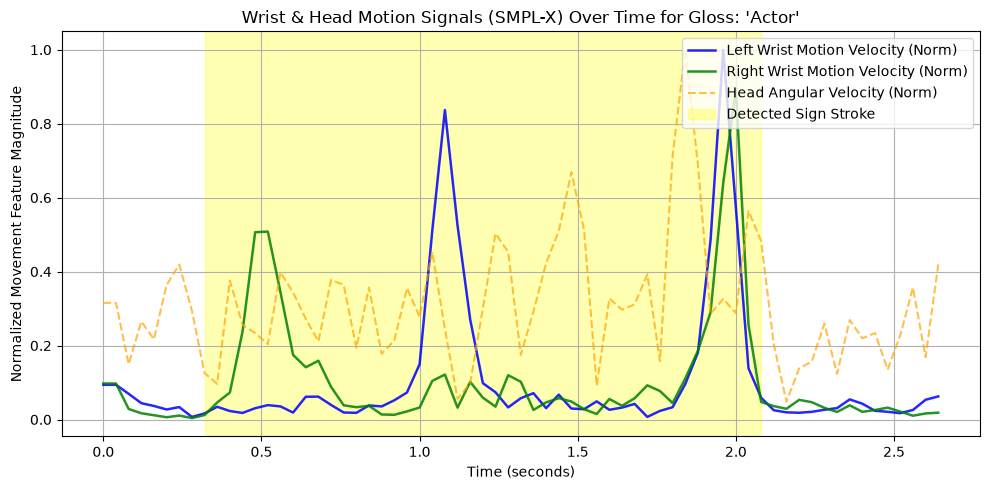

Saved motion signals time-series plot to ../plots\include\motion_signals.png


In [34]:
plot_motion_signals(SAMPLE_NPZ_FILE)

In [35]:
render_npz_skeleton_preview(SAMPLE_NPZ_FILE, SAMPLE_PREVIEW_MP4)

Rendering 67 frames to ../output/include\actual\Actor_skeleton_preview.mp4...
Render complete!


# Skeleton prediction

**Methods compared on held-out real clips** (one clip per word hidden): `linear_mean` (naive), `medoid` (most central real clip), `dba` (DTW barycentre of all clips, left-handed signers mirrored, outliers dropped) and, on a GPU, `softdtw` (gloss-embedding network trained with soft-DTW + differentiable FK). The training cell prints the table, keeps the best method and saves it.


In [26]:
import contextlib
import copy
import difflib
import glob
import inspect
import io
import json
import math
import os
import pickle
import random
import re
import time
from dataclasses import dataclass, replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from scipy.interpolate import interp1d
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import least_squares
from scipy.spatial.distance import cdist
from scipy.spatial.transform import Rotation as Rot

# Plot colours shared by all result plots
C_BEST, C_OTHER, C_ACCENT = "#2e9d5b", "#6c8ebf", "#e08a3c"

In [27]:
# State shared by training / inference / evaluation (in-memory caches)
_BANK = {
    "bank": None
}  # motion bank cache used by train_motion_model() and get_motion_bank()
clips = None  # all recordings (set by train_motion_model, lazily loaded by the evaluation functions)

In [28]:
# Configuration, canonical torso, rotation helpers
MODEL_DIR = os.path.join(BASE_DIR, "model/include/train")
MODEL_PATH = os.path.join(MODEL_DIR, "motion_templates.pkl")
RESULTS_PATH = os.path.join(
    MODEL_DIR, "benchmark_results.pkl"
)  # saved benchmark (for the plots)
REPRESENTATION = "smplx_rot6d_expression_canonical"

TARGET_FPS = 25.0  # every clip / template lives at this frame rate
MIN_CLIP_FRAMES = 8
SMOOTH_SIGMA = 1.0  # frames of gaussian smoothing on generated motion

# Hard anatomical limits (degrees). Chest = sway relative to the signer's own average posture;
# neck / head = rotation relative to the parent joint. These make it *impossible* for the head
# to leave the top of the torso.
CHEST_MAX_DEG = 8.0  # real chests barely move while signing; larger 'sway' in the data is pose-estimation noise
CHEST_SMOOTH_SIGMA = 4.0  # frames (Gaussian) applied to the chest rotation
NECK_MAX_DEG = 30.0
HEAD_MAX_DEG = 30.0

_KJ = {
    n: MOTION_JOINTS.index(SMPLX_JOINT_INDEX[n])
    for n in [
        "pelvis",
        "spine1",
        "spine2",
        "spine3",
        "neck",
        "left_collar",
        "right_collar",
        "head",
    ]
}


# ---------------------------------------------------------------------
# ALL-CAPS gloss keys
# ---------------------------------------------------------------------
def gloss_key(name) -> str:
    """Canonical gloss key: ALL CAPS, single spaces ('Good_morning' / 'good morning' -> 'GOOD MORNING')."""
    return " ".join(str(name).replace("_", " ").split()).upper()


# ---------------------------------------------------------------------
# rotation helpers (numpy)
# ---------------------------------------------------------------------
def motion_to_R(motion):
    """(T,292) -> (T,47,3,3) rotation matrices."""
    motion = np.asarray(motion, np.float64)
    T = motion.shape[0]
    return rot6d_to_rotmat(motion[:, :ROT_DIMS].reshape(T, NUM_MOTION_JOINTS, 6))


def R_to_motion(R, expr):
    T = R.shape[0]
    out = np.empty((T, MOTION_DIM), np.float32)
    out[:, :ROT_DIMS] = rotmat_to_rot6d(R).reshape(T, ROT_DIMS)
    out[:, EXPR_SLICE] = expr
    return out


def chordal_mean_R(Rs):
    """Mean of rotation matrices (N,3,3) on SO(3) (projection of the arithmetic mean)."""
    U, _, Vt = np.linalg.svd(Rs.sum(0))
    d = np.sign(np.linalg.det(U @ Vt))
    return U @ np.diag([1.0, 1.0, d]) @ Vt


def clamp_rotation(R, max_deg):
    """Limit the rotation angle of every matrix in R (...,3,3) to max_deg."""
    flat = R.reshape(-1, 3, 3)
    rv = Rot.from_matrix(flat).as_rotvec()
    ang = np.linalg.norm(rv, axis=-1, keepdims=True)
    lim = np.radians(max_deg)
    scale = np.where(ang > lim, lim / np.maximum(ang, 1e-9), 1.0)
    return Rot.from_rotvec(rv * scale).as_matrix().reshape(R.shape)


def enforce_limits(motion):
    """Apply the torso/head limits to a (T,292) motion. Spines/collars are identity by definition."""
    R = motion_to_R(motion)
    I = np.eye(3)
    for n in ("spine1", "spine2", "spine3", "left_collar", "right_collar"):
        R[:, _KJ[n]] = I
    R[:, _KJ["pelvis"]] = clamp_rotation(R[:, _KJ["pelvis"]], CHEST_MAX_DEG)
    R[:, _KJ["neck"]] = clamp_rotation(R[:, _KJ["neck"]], NECK_MAX_DEG)
    R[:, _KJ["head"]] = clamp_rotation(R[:, _KJ["head"]], HEAD_MAX_DEG)
    return R_to_motion(
        R, np.clip(motion[:, EXPR_SLICE], -EXPRESSION_CLIP, EXPRESSION_CLIP)
    )


def canonicalize_motion(motion):
    """
    Canonical torso: the chest orientation is the only torso quantity that matters. We
      1. compute the global chest orientation  G = pelvis @ spine1 @ spine2 @ spine3,
      2. remove the signer's own average posture (static yaw / lean from the camera or habit),
      3. smooth the remaining sway (pose-estimation jitter) and limit it to CHEST_MAX_DEG,
      4. store it in the pelvis slot, set spine1-3 and the collars to identity,
      5. re-express the shoulders and the head so that their orientation, as MEASURED, is unchanged
         (otherwise correcting the chest would drag the arms and the head along).
    Arms, hands and face are untouched, so all clips share ONE well-defined torso and can be averaged.
    """
    motion = np.asarray(motion, np.float32)
    R = motion_to_R(motion)
    T = len(R)
    G = (
        R[:, _KJ["pelvis"]]
        @ R[:, _KJ["spine1"]]
        @ R[:, _KJ["spine2"]]
        @ R[:, _KJ["spine3"]]
    )
    Q = chordal_mean_R(G).T  # static posture removal
    Gq = np.einsum("ij,tjk->tik", Q, G)
    rv = Rot.from_matrix(Gq).as_rotvec()
    if T > 3 and CHEST_SMOOTH_SIGMA > 0:
        rv = gaussian_filter1d(rv, CHEST_SMOOTH_SIGMA, axis=0, mode="nearest")
    ang = np.linalg.norm(rv, axis=1, keepdims=True)
    lim = np.radians(CHEST_MAX_DEG)
    rv = rv * np.where(ang > lim, lim / np.maximum(ang, 1e-9), 1.0)
    Gn = Rot.from_rotvec(rv).as_matrix()
    A = np.einsum(
        "tji,tjk->tik", Gn, Gq
    )  # Gn^T Gq : keeps world orientation of shoulders / head
    for n in ("left_shoulder", "right_shoulder"):
        k = MOTION_JOINTS.index(SMPLX_JOINT_INDEX[n])
        R[:, k] = A @ R[:, k]
    nk, hk = _KJ["neck"], _KJ["head"]
    half = (
        Rot.from_matrix(A @ R[:, nk] @ R[:, hk]).as_rotvec() / 2.0
    )  # neck and head share the rotation
    R[:, nk] = R[:, hk] = Rot.from_rotvec(half).as_matrix()
    R[:, _KJ["pelvis"]] = Gn
    return enforce_limits(R_to_motion(R, motion[:, EXPR_SLICE]))


# ---------------------------------------------------------------------
# time resampling (linear on the 6D representation, re-projected afterwards)
# ---------------------------------------------------------------------
def resample_motion(motion, n_out):
    motion = np.asarray(motion, np.float32)
    T = len(motion)
    n_out = max(int(n_out), 2)
    if T == 1:
        return np.repeat(motion, n_out, 0)
    idx = np.linspace(0, T - 1, n_out)
    i0 = np.floor(idx).astype(int)
    i1 = np.minimum(i0 + 1, T - 1)
    w = (idx - i0)[:, None].astype(np.float32)
    return ((1 - w) * motion[i0] + w * motion[i1]).astype(np.float32)

In [29]:
# Forward kinematics + DTW
_REST_NP_CACHE = {}


def _rest_np():
    if "rest" not in _REST_NP_CACHE:
        _REST_NP_CACHE["rest"] = np.asarray(get_rest_joints()[0], np.float64)
    return _REST_NP_CACHE["rest"]


def fk_points(motion):
    """(T,292) motion -> (T,76,3) joint + landmark positions (metres, pelvis at the origin)."""
    rest = _rest_np()
    T = len(motion)
    local = np.tile(np.eye(3), (T, 55, 1, 1))
    local[:, MOTION_JOINTS] = motion_to_R(motion)
    G = np.zeros((T, 55, 3, 3))
    P = np.zeros((T, 76, 3))
    for j in range(55):
        p = SMPLX_PARENTS[j]
        if p < 0:
            G[:, j] = local[:, j]
            P[:, j] = rest[j]
        else:
            G[:, j] = G[:, p] @ local[:, j]
            P[:, j] = P[:, p] + G[:, p] @ (rest[j] - rest[p])
    for e, p in enumerate(SMPLX_EXTRA_PARENTS):
        P[:, 55 + e] = P[:, p] + G[:, p] @ (rest[55 + e] - rest[p])
    return P


# points used to compare / align motions
ELBOWS, WRISTS = [18, 19], [20, 21]
FINGERTIPS = list(range(66, 76))
KEY_POINTS = ELBOWS + WRISTS + FINGERTIPS  # 14 points = what the viewer actually reads
NOSE, SHOULDERS = 55, (16, 17)


def _shoulder_width():
    r = _rest_np()
    return float(np.linalg.norm(r[16] - r[17]))


def clip_features(motion):
    """Chest-relative, shoulder-width-normalised key-point positions, (T, 42). Used for DTW."""
    P = fk_points(motion)
    origin = 0.5 * (P[:, 16] + P[:, 17])
    return ((P[:, KEY_POINTS] - origin[:, None]) / _shoulder_width()).reshape(
        len(P), -1
    )


# ---------------------------------------------------------------------
# DTW (anti-diagonal vectorised, Sakoe-Chiba style band)
# ---------------------------------------------------------------------
def dtw_path(A, B, band=0.4):
    """
    Dynamic time warping between feature sequences A (N,D) and B (M,D).
    Returns (path, mean_cost): path = array of (i, j) pairs from (0,0) to (N-1,M-1).
    """
    N, M = len(A), len(B)
    C = cdist(A, B)
    ii, jj = np.mgrid[0:N, 0:M]
    off = np.abs(ii / max(N - 1, 1) - jj / max(M - 1, 1))
    C = np.where(off <= band, C, np.inf)
    D = np.full((N + 1, M + 1), np.inf)
    D[0, 0] = 0.0
    for k in range(2, N + M + 1):
        i = np.arange(max(1, k - M), min(N, k - 1) + 1)
        j = k - i
        best = np.minimum(np.minimum(D[i - 1, j - 1], D[i - 1, j]), D[i, j - 1])
        D[i, j] = C[i - 1, j - 1] + best
    i, j = N, M
    path = [(i - 1, j - 1)]
    while i > 1 or j > 1:
        cand = [
            (D[i - 1, j - 1], i - 1, j - 1),
            (D[i - 1, j], i - 1, j),
            (D[i, j - 1], i, j - 1),
        ]
        _, i, j = min(cand, key=lambda c: c[0])
        path.append((i - 1, j - 1))
    path = np.array(path[::-1])
    return path, float(D[N, M] / len(path))


def warp_to_reference(motion, path, n_ref):
    """Re-time `motion` onto a reference timeline of n_ref frames using a DTW path (ref_idx, motion_idx)."""
    sums = np.zeros((n_ref, motion.shape[1]))
    cnt = np.zeros(n_ref)
    np.add.at(sums, path[:, 0], motion[path[:, 1]])
    np.add.at(cnt, path[:, 0], 1.0)
    return sums / np.maximum(cnt, 1)[:, None]

In [30]:
# Mirroring, per-word consensus (DBA), post-processing, metrics
# ---------------------------------------------------------------------
# left <-> right mirroring (some signers are left-handed)
# ---------------------------------------------------------------------
_PAIRS = [(13, 14), (16, 17), (18, 19), (20, 21), (23, 24)] + [
    (25 + i, 40 + i) for i in range(15)
]
_MSWAP = list(range(NUM_MOTION_JOINTS))
for _a, _b in _PAIRS:
    ka, kb = MOTION_JOINTS.index(_a), MOTION_JOINTS.index(_b)
    _MSWAP[ka], _MSWAP[kb] = kb, ka
_PSWAP = list(range(76))  # same swap for the 76 skeleton points
for _a, _b in _PAIRS + [(56, 57), (58, 59)] + [(66 + i, 71 + i) for i in range(5)]:
    _PSWAP[_a], _PSWAP[_b] = _b, _a
_MIRROR_SIGN = np.array(
    [[1, -1, -1], [-1, 1, 1], [-1, 1, 1]], np.float64
)  # conjugation by diag(-1,1,1)


def mirror_motion(motion):
    """Left-right mirror a (T,292) motion (reflect through the x=0 plane, swap L/R joints)."""
    R = motion_to_R(motion)[:, _MSWAP] * _MIRROR_SIGN
    return R_to_motion(R, motion[:, EXPR_SLICE])


# ---------------------------------------------------------------------
# per-word consensus  =  orient (mirror) -> reject outliers -> DBA
# ---------------------------------------------------------------------
def _pairwise_dtw(feats, band):
    K = len(feats)
    Dm = np.zeros((K, K))
    for a in range(K):
        for b in range(a + 1, K):
            Dm[a, b] = Dm[b, a] = dtw_path(feats[a], feats[b], band)[1]
    return Dm


def dba_average(motions, feats, init_idx, n_iter=6, band=0.4, history=None):
    """
    DTW Barycentre Averaging: the mean *shape* of several clips of different speed.
    Minimises the mean DTW distance between the clips and the barycentre; `history` (a list) receives that
    objective at the start of every iteration, which is the 'loss curve' of this method.
    """
    ref = motions[init_idx].astype(np.float64)
    for _ in range(n_iter):
        fref = clip_features(project_motion_vector(ref))
        acc = np.zeros_like(ref)
        costs = []
        for m, f in zip(motions, feats):
            path, cost = dtw_path(fref, f, band)
            costs.append(cost)
            acc += warp_to_reference(m.astype(np.float64), path, len(ref))
        if history is not None:
            history.append(float(np.mean(costs)))
        new = project_motion_vector(acc / len(motions)).astype(np.float64)
        delta = float(np.abs(new - ref).mean())
        ref = new
        if delta < 1e-4:
            break
    return ref.astype(np.float32)


def orient_and_filter(motions, band=0.4, mirror=True, reject=True):
    """
    Clean the clips of ONE word: flip left-handed signers to the majority hand, drop outlier clips.
    Returns (clean_motions, info) with info = dict(kept, mirrored, medoid) (indices into `motions`).
    """
    motions = [np.asarray(m, np.float32) for m in motions]
    K = len(motions)
    if K < 2:
        return motions, dict(kept=list(range(K)), mirrored=[], medoid=0)
    feats = [clip_features(m) for m in motions]
    Dm = _pairwise_dtw(feats, band)
    medoid = int(np.argmin(Dm.sum(1)))
    mirrored = []
    if mirror and K >= 3:
        for k in range(K):
            if k == medoid:
                continue
            mm = mirror_motion(motions[k])
            fm = clip_features(mm)
            if dtw_path(feats[medoid], fm, band)[1] < 0.75 * Dm[medoid, k]:
                motions[k], feats[k] = mm, fm
                mirrored.append(k)
        if mirrored:
            Dm = _pairwise_dtw(feats, band)
            medoid = int(np.argmin(Dm.sum(1)))
    kept = list(range(K))
    if reject and K >= 4:
        s = Dm.sum(1) / (K - 1)
        med = np.median(s)
        mad = 1.4826 * np.median(np.abs(s - med))
        ok = s <= med + 2.5 * max(mad, 0.15 * med)
        kept = [k for k in range(K) if ok[k]]
        if len(kept) < max(3, math.ceil(K / 2)):
            kept = list(np.argsort(s)[: max(3, math.ceil(K / 2))])
        kept = sorted(int(k) for k in kept)
        if medoid not in kept:
            medoid = min(kept, key=lambda k: Dm[k, kept].sum())
    return [motions[k] for k in kept], dict(
        kept=kept,
        mirrored=[k for k in mirrored if k in kept],
        medoid=kept.index(medoid),
    )


def word_consensus(motions, band=0.4, mirror=True, reject=True, n_iter=6):
    """
    Combine the clips of ONE word into a template (orient -> reject outliers -> DBA).
    Returns dict(template, duration, kept, mirrored, aligned): template (T_ref,292) mean shape,
    duration = median clip length (frames), aligned = kept clips re-timed onto the template timeline.
    """
    sel, info = orient_and_filter(motions, band, mirror, reject)
    if len(sel) == 1:
        return dict(
            template=sel[0],
            duration=len(sel[0]),
            kept=info["kept"],
            mirrored=[],
            aligned=[sel[0].astype(np.float64)],
            history=[],
        )
    sfe = [clip_features(m) for m in sel]
    hist = []
    tmpl = dba_average(sel, sfe, info["medoid"], n_iter=n_iter, band=band, history=hist)
    fref = clip_features(tmpl)
    paths = [dtw_path(fref, f, band) for f in sfe]
    hist.append(
        float(np.mean([c for _, c in paths]))
    )  # objective of the final barycentre
    aligned = [
        warp_to_reference(m.astype(np.float64), p, len(tmpl))
        for m, (p, _) in zip(sel, paths)
    ]
    return dict(
        template=tmpl,
        duration=float(np.median([len(m) for m in sel])),
        kept=info["kept"],
        mirrored=info["mirrored"],
        aligned=aligned,
        history=hist,
    )


# ---------------------------------------------------------------------
# post-processing shared by every method
# ---------------------------------------------------------------------
def finalize_motion(motion, n_frames=None, smooth=SMOOTH_SIGMA):
    """resample -> smooth -> valid rotations -> torso/head limits. Always returns a safe (T,292) motion."""
    m = np.asarray(motion, np.float32)
    if n_frames is not None and int(round(n_frames)) != len(m):
        m = resample_motion(m, int(round(n_frames)))
    if smooth and len(m) > 3:
        m = gaussian_filter1d(m, smooth, axis=0, mode="nearest").astype(np.float32)
    return enforce_limits(project_motion_vector(m))


# ---------------------------------------------------------------------
# metrics  (positions in cm; all compare a prediction with a REAL held-out clip)
# ---------------------------------------------------------------------
def _chest_frames(motion):
    """(T,3,3) global chest orientation of a motion (pelvis @ spines)."""
    R = motion_to_R(motion)
    G = (
        R[:, _KJ["pelvis"]]
        @ R[:, _KJ["spine1"]]
        @ R[:, _KJ["spine2"]]
        @ R[:, _KJ["spine3"]]
    )
    return np.transpose(G, (0, 2, 1))  # G^T : world -> chest frame


def _chest_points(motion):
    P = fk_points(motion)
    sh = 0.5 * (P[:, 16] + P[:, 17])
    return np.einsum("tij,tkj->tki", _chest_frames(motion), P - sh[:, None])


def head_above_shoulders_ratio(motion):
    """Fraction of frames where the nose is above the shoulder line (measured in the chest frame)."""
    return float(np.mean(_chest_points(motion)[:, NOSE, 1] > 0.0))


def evaluate_prediction(pred, gt, band=0.5):
    """Compare a predicted motion with a real clip. Positions are in the chest frame, in cm."""
    pp, pg = _chest_points(pred), _chest_points(gt)
    fp, fg = clip_features(pred), clip_features(gt)
    path, _ = dtw_path(fp, fg, band)
    d_kp = np.linalg.norm(
        pp[path[:, 0]][:, KEY_POINTS] - pg[path[:, 1]][:, KEY_POINTS], axis=-1
    )
    d_wr = np.linalg.norm(
        pp[path[:, 0]][:, WRISTS] - pg[path[:, 1]][:, WRISTS], axis=-1
    )
    d_nose = np.linalg.norm(pp[path[:, 0], NOSE] - pg[path[:, 1], NOSE], axis=-1)
    tips = FINGERTIPS
    wr_of = [20] * 5 + [21] * 5
    loc_p = pp[:, tips] - pp[:, wr_of]
    loc_g = pg[:, tips] - pg[:, wr_of]
    d_hand = np.linalg.norm(loc_p[path[:, 0]] - loc_g[path[:, 1]], axis=-1)
    # strict (no time warping): both resampled to the real clip length
    rp = resample_motion(pred, len(gt))
    ps = _chest_points(rp)
    d_strict = np.linalg.norm(ps[:, KEY_POINTS] - pg[:, KEY_POINTS], axis=-1)

    def speed(p):  # mean wrist speed (m/s) from chest-frame points
        return (
            np.linalg.norm(np.diff(p[:, WRISTS], axis=0), axis=-1).mean() * TARGET_FPS
        )

    return {
        "mpjpe_dtw_cm": 100 * d_kp.mean(),
        "wrist_cm": 100 * d_wr.mean(),
        "handshape_cm": 100 * d_hand.mean(),
        "nose_cm": 100 * d_nose.mean(),
        "strict_cm": 100 * d_strict.mean(),
        "dur_err_pct": 100 * abs(len(pred) - len(gt)) / len(gt),
        "energy_ratio": speed(pp) / max(speed(pg), 1e-6),
        "head_above_pct": 100 * head_above_shoulders_ratio(pred),
    }

In [31]:
# Signer normalisation
# =====================================================================
# MOTION MODEL: SIGNER NORMALISATION
#   (different signers / near or far from the camera / left- or right-handed)
# =====================================================================
# Every word of a sentence may come from a different signer. Joint ROTATIONS are already independent of
# body size and of the distance to the camera (SMPL-X angles do not change when the signer is near or far,
# tall or short; the avatar always uses the same neutral skeleton), and canonicalize_motion() removes the
# signer's static lean / camera yaw. What is left, and what this cell removes, is:
#   1. HANDEDNESS: a left-handed signer's word is mirrored so that every template is signed with the
#      SAME dominant hand (otherwise the active hand would swap from one word to the next).
#   2. RESTING FACE / HEAD / GAZE: the expression fit uses a neutral face shape, so each signer's own
#      resting face, habitual head tilt and gaze stay in the data and would jump between words. The
#      signer's resting values (frames before the sign starts, or after it ends) are subtracted.
DOMINANT_HAND = "right"  # every template is converted to this dominant hand
HANDEDNESS_RATIO = 1.3  # mirror when the non-dominant wrist is this much more active
MIN_HAND_ACTIVITY = (
    0.12  # shoulder widths; below this the clip is treated as two-handed / ambiguous
)
NORMALIZE_HANDEDNESS = True
NORMALIZE_SIGNER_FACE = (
    True  # remove the resting expression / jaw / gaze of each signer
)
NORMALIZE_SIGNER_HEAD = True  # remove the habitual head tilt of each signer
MAX_HEAD_OFFSET_DEG = (
    25.0  # never remove more than this (protects against bad rest frames)
)

_HEAD_SLOTS = (MOTION_JOINTS.index(12), MOTION_JOINTS.index(15))  # neck, head
_FACE_ROT_SLOTS = [
    MOTION_JOINTS.index(j) for j in (22, 23, 24)
]  # jaw, left eye, right eye


def wrist_activity(motion):
    """
    How much each hand is used in a clip: mean distance of the wrist from its own lowest (resting) position,
    in shoulder widths, measured relative to the chest. Returns (left, right).
    """
    P = fk_points(np.asarray(motion, np.float32))
    sh = 0.5 * (P[:, 16] + P[:, 17])
    rel = (P[:, [20, 21]] - sh[:, None]) / _shoulder_width()  # (T, 2, 3)
    low = rel[np.argmin(rel[:, :, 1], axis=0), [0, 1]]  # lowest frame of each wrist
    return np.linalg.norm(rel - low[None], axis=-1).mean(0)


def dominant_hand_of(motion):
    """'left', 'right' or 'both' (two-handed / undecided)."""
    a_left, a_right = wrist_activity(motion)
    if max(a_left, a_right) < MIN_HAND_ACTIVITY:
        return "both"
    if a_left > HANDEDNESS_RATIO * a_right:
        return "left"
    if a_right > HANDEDNESS_RATIO * a_left:
        return "right"
    return "both"


def normalize_handedness(motion):
    """Mirror the clip when it is clearly signed with the non-dominant hand. Returns (motion, mirrored)."""
    if not NORMALIZE_HANDEDNESS:
        return motion, False
    hand = dominant_hand_of(motion)
    if hand != "both" and hand != DOMINANT_HAND:
        return mirror_motion(np.asarray(motion, np.float32)), True
    return motion, False


def remove_signer_offsets(motion, rest):
    """
    Subtract the signer's resting face / head / gaze (taken from `rest`, frames where the signer is not
    signing) from `motion`. Both are canonical (T, 292) motions of the same recording.
    """
    if rest is None or len(rest) == 0:
        return motion
    R = motion_to_R(motion)
    R_rest = motion_to_R(rest)
    expr = np.asarray(motion[:, EXPR_SLICE], np.float64)
    if NORMALIZE_SIGNER_HEAD:
        nk, hk = _HEAD_SLOTS
        A = R[:, nk] @ R[:, hk]  # neck + head together
        A0 = chordal_mean_R(R_rest[:, nk] @ R_rest[:, hk])
        A0 = clamp_rotation(A0[None], MAX_HEAD_OFFSET_DEG)[0]
        half = Rot.from_matrix(np.einsum("ji,tjk->tik", A0, A)).as_rotvec() / 2.0
        R[:, nk] = R[:, hk] = Rot.from_rotvec(half).as_matrix()
    if NORMALIZE_SIGNER_FACE:
        for k in _FACE_ROT_SLOTS:
            R0 = clamp_rotation(
                chordal_mean_R(R_rest[:, k])[None], MAX_HEAD_OFFSET_DEG
            )[0]
            R[:, k] = np.einsum("ji,tjk->tik", R0, R[:, k])
        expr = expr - np.asarray(rest[:, EXPR_SLICE], np.float64).mean(0, keepdims=True)
    return enforce_limits(
        R_to_motion(R, np.clip(expr, -EXPRESSION_CLIP, EXPRESSION_CLIP))
    )


def rest_frame_indices(n_frames, start, end, min_frames=3):
    """Frames of a recording where the signer is resting: before the stroke, otherwise after it."""
    if start - 1 >= min_frames:
        return list(range(0, start - 1))
    if n_frames - (end + 2) >= min_frames:
        return list(range(end + 2, n_frames))
    return []


def prepare_clip(segment, rest_frames=None, handedness=True):
    """
    Raw stroke (T,292) -> canonical, signer-normalised stroke.
      canonical torso -> same dominant hand -> signer's resting face / head / gaze removed.
    Returns (motion, info) with info = {"mirrored": bool, "rest_frames": int}.
    """
    seg = canonicalize_motion(np.asarray(segment, np.float32))
    rest = None
    if rest_frames is not None and len(rest_frames):
        rest = canonicalize_motion(np.asarray(rest_frames, np.float32))
    mirrored = False
    if handedness:
        seg, mirrored = normalize_handedness(seg)
        if mirrored and rest is not None:
            rest = mirror_motion(rest)
    if rest is not None:
        seg = remove_signer_offsets(seg, rest)
    return seg, {"mirrored": mirrored, "rest_frames": 0 if rest is None else len(rest)}


def load_npz_clip(path):
    """One SMPL-X .npz recording -> (prepared stroke at TARGET_FPS, info) or (None, reason)."""
    d = np.load(path, allow_pickle=True)
    mv = np.asarray(d["motion_vector"], np.float32)
    if mv.ndim != 2 or mv.shape[1] != MOTION_DIM or not np.isfinite(mv).all():
        return None, "format"
    s, e = (int(v) for v in d["stroke_bounds"])
    fps = float(d["fps"]) if "fps" in d.files else TARGET_FPS
    seg = mv[s : e + 1]
    if abs(fps - TARGET_FPS) > 0.5:  # bring everything to 25 fps
        seg = project_motion_vector(
            resample_motion(seg, round(len(seg) * TARGET_FPS / fps))
        )
    rest_idx = rest_frame_indices(len(mv), s, e)
    motion, info = prepare_clip(seg, mv[rest_idx] if rest_idx else None)
    info.update(start=s, end=e, fps=fps, rest_idx=rest_idx)
    return motion, info

In [32]:
# Loading the recordings
# ---------------------------------------------------------------------
# load every clip of the dataset (stroke only), canonicalised, keyed by ALL-CAPS gloss
# ---------------------------------------------------------------------
NEUTRAL_POSE = {"pose": None}  # (1,292) 'hands down' pose, set by load_clips()


def load_clips(data_dir=None, verbose=True):
    """
    Every recording's stroke, canonical torso + signer-normalised (same dominant hand, the signer's
    resting face / head / gaze removed; see the signer-normalisation cell), keyed by ALL-CAPS gloss.
    """
    data_dir = data_dir or NPZ_DIR
    clips, skipped, neutral_frames, n_mirrored, n_rest = {}, 0, [], 0, 0
    for folder in sorted(os.listdir(data_dir)):
        fdir = os.path.join(data_dir, folder)
        if not os.path.isdir(fdir):
            continue
        key = gloss_key(folder)
        for path in sorted(glob.glob(os.path.join(fdir, "*.npz"))):
            try:
                motion, info = load_npz_clip(path)
            except Exception:
                motion, info = None, "error"
            if motion is None or len(motion) < MIN_CLIP_FRAMES:
                skipped += 1
                continue
            n_mirrored += int(info["mirrored"])
            n_rest += int(info["rest_frames"] > 0)
            if (
                info["start"] >= 3 and abs(info["fps"] - TARGET_FPS) <= 0.5
            ):  # signer is still resting before the sign starts
                mv = np.asarray(np.load(path)["motion_vector"], np.float32)
                rest = mv[info["rest_idx"]] if info["rest_idx"] else None
                neutral_frames.append(prepare_clip(mv[:1], rest, handedness=False)[0])
            clips.setdefault(key, []).append(
                {
                    "motion": motion,
                    "path": path,
                    "gloss": key,
                    "mirrored": info["mirrored"],
                }
            )
    if neutral_frames:  # average resting pose of all recordings (hands down, upright)
        mean = np.concatenate(neutral_frames).mean(0, keepdims=True)
        mean[:, EXPR_SLICE] = 0.0
        NEUTRAL_POSE["pose"] = project_motion_vector(mean)
    if verbose:
        n = sum(len(v) for v in clips.values())
        lens = [len(c["motion"]) for v in clips.values() for c in v]
        print(
            f"Loaded {n} clips for {len(clips)} glosses ({skipped} skipped). "
            f"Frames/clip: median {np.median(lens):.0f}, min {min(lens)}, max {max(lens)}"
        )
        print(
            f"Signer normalisation: {n_mirrored} clips mirrored to a {DOMINANT_HAND}-hand signer, "
            f"resting face/head removed in {n_rest} clips."
        )
    return clips

In [33]:
# MotionBank
class MotionBank:
    """GLOSS (ALL CAPS) -> template motion.  This is what generate_gloss_motion() uses."""

    def __init__(self, method, templates, meta=None):
        self.method = method
        self.templates = templates  # GLOSS -> {"motion": (T,292), "n_frames": float, "n_clips": int, ...}
        self.meta = meta or {}

    @property
    def vocab(self):
        return sorted(self.templates)

    def lookup_key(self, word):
        key = gloss_key(word)
        if key not in self.templates:
            close = difflib.get_close_matches(key, self.templates, n=5, cutoff=0.6)
            raise KeyError(
                f"'{word}' is not in the motion vocabulary. Use ALL CAPS gloss names. "
                f"Closest: {close if close else 'none'}"
            )
        return key

    def __contains__(self, word):
        return gloss_key(word) in self.templates

    def generate(self, word, n_frames=None, speed=1.0):
        """Return a safe (T,292) motion for one gloss. `speed` > 1 makes the sign faster."""
        t = self.templates[self.lookup_key(word)]
        n = (n_frames if n_frames is not None else t["n_frames"]) / max(speed, 1e-3)
        return finalize_motion(t["motion"], n_frames=n)

    def save(self, path=MODEL_PATH):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        with open(path, "wb") as f:
            pickle.dump(
                {
                    "representation": REPRESENTATION,
                    "method": self.method,
                    "templates": self.templates,
                    "meta": self.meta,
                },
                f,
            )
        return path

    @staticmethod
    def load(path=MODEL_PATH):
        with open(path, "rb") as f:
            d = pickle.load(f)
        assert d["representation"] == REPRESENTATION, "unknown motion-bank format"
        return MotionBank(d["method"], d["templates"], d.get("meta"))


def _entry(motion, n_frames, n_clips, **info):
    return {
        "motion": np.asarray(motion, np.float32),
        "n_frames": float(n_frames),
        "n_clips": int(n_clips),
        **info,
    }

In [34]:
# Candidate methods: linear mean, medoid, DBA
# ---------------------------------------------------------------------
# method 1: linear mean  (naive: stretch every clip to the same length and average -> blurry)
# ---------------------------------------------------------------------
def fit_linear_mean(clips, **_):
    out = {}
    for g, items in clips.items():
        ms = [c["motion"] for c in items]
        n = int(round(np.median([len(m) for m in ms])))
        mean = np.mean([resample_motion(m, n) for m in ms], axis=0)
        out[g] = _entry(project_motion_vector(mean), n, len(ms))
    return out


# ---------------------------------------------------------------------
# method 2: medoid  (the single most 'central' real clip of the word - always natural looking)
# ---------------------------------------------------------------------
def fit_medoid(clips, band=0.4, **_):
    out = {}
    for g, items in clips.items():
        ms = [c["motion"] for c in items]
        if len(ms) == 1:
            k = 0
        else:
            k = int(
                np.argmin(_pairwise_dtw([clip_features(m) for m in ms], band).sum(1))
            )
        out[g] = _entry(
            ms[k], np.median([len(m) for m in ms]), len(ms), source=items[k]["path"]
        )
    return out


# ---------------------------------------------------------------------
# method 3: DBA  (outlier-robust DTW barycentre of all clips of the word)
# ---------------------------------------------------------------------
# method name -> training curves of the last fit (used by the result graphs)
FIT_HISTORY = {}


def fit_dba(clips, band=0.4, mirror=True, **_):
    out, curves = {}, []
    for g, items in clips.items():
        r = word_consensus([c["motion"] for c in items], band=band, mirror=mirror)
        out[g] = _entry(
            r["template"],
            r["duration"],
            len(r["kept"]),
            kept=r["kept"],
            mirrored=r["mirrored"],
            dropped=[k for k in range(len(items)) if k not in r["kept"]],
        )
        if r["history"]:
            curves.append(r["history"])
    if (
        curves
    ):  # mean over words, per iteration (words that converged early keep their last value)
        L = max(len(c) for c in curves)
        M = np.array([c + [c[-1]] * (L - len(c)) for c in curves])
        FIT_HISTORY["dba"] = {
            "kind": "dba",
            "iteration": list(range(L)),
            "objective": M.mean(0).tolist(),
            "p25": np.percentile(M, 25, 0).tolist(),
            "p75": np.percentile(M, 75, 0).tolist(),
        }
    return out

In [35]:
# Neural candidate (1/2): soft-DTW + differentiable FK + network
# =====================================================================
# MOTION MODEL: neural candidate  =  gloss embedding -> word prototype,
#                          trained with SOFT-DTW + differentiable forward kinematics
# =====================================================================
# Why this instead of the old CVAE?
#  * deterministic: one prototype per word (a CVAE sampled with z~N(0,I) adds random jitter)
#  * soft-DTW loss: a signer who is 20% slower is NOT penalised, so the network learns a SHARP
#    prototype instead of a blurry average (this is the neural counterpart of DBA)
#  * the loss is computed on WHERE the wrists / elbows / fingertips are (differentiable FK), so
#    errors are weighted by how visible they are, not by raw rotation numbers
#  * duration is not learned (the old length head never converged): the median of the word's clips is used

BIG = 1e5


def rot6d_to_R_t(x):
    a1, a2 = x[..., 0:3], x[..., 3:6]
    b1 = F.normalize(a1, dim=-1, eps=1e-8)
    b2 = F.normalize(a2 - (b1 * a2).sum(-1, keepdim=True) * b1, dim=-1, eps=1e-8)
    return torch.stack([b1, b2, torch.cross(b1, b2, dim=-1)], dim=-1)


class TorchFK:
    """Differentiable twin of clip_features(): (B,T,47,6) rotations -> (B,T,42) key-point features."""

    def __init__(self, device):
        self.device = device
        self.rest = torch.tensor(_rest_np(), dtype=torch.float32, device=device)
        self.sw = _shoulder_width()

    def features(self, rot6d):
        R = rot6d_to_R_t(rot6d)  # (B,T,47,3,3)
        B, T = R.shape[:2]
        eye = torch.eye(3, device=R.device).expand(B, T, 3, 3)
        slot = {j: k for k, j in enumerate(MOTION_JOINTS)}
        G, P = [None] * 55, [None] * 55
        for j in range(55):
            loc = R[:, :, slot[j]] if j in slot else eye
            p = SMPLX_PARENTS[j]
            if p < 0:
                G[j], P[j] = loc, self.rest[j].expand(B, T, 3)
            else:
                G[j] = G[p] @ loc
                P[j] = P[p] + (
                    G[p] @ (self.rest[j] - self.rest[p]).unsqueeze(-1)
                ).squeeze(-1)
        tips = []
        for e in range(66 - 55, 76 - 55):
            p = SMPLX_EXTRA_PARENTS[e]
            tips.append(
                P[p]
                + (G[p] @ (self.rest[55 + e] - self.rest[p]).unsqueeze(-1)).squeeze(-1)
            )
        origin = 0.5 * (P[16] + P[17])
        pts = [P[18], P[19], P[20], P[21]] + tips  # == KEY_POINTS order
        return (
            (torch.stack(pts, dim=2) - origin.unsqueeze(2))
            .div(self.sw)
            .reshape(B, T, -1)
        )


def soft_dtw(C, lengths, gamma=0.1, band=0.5):
    """
    Batched soft-DTW. C: (B,N,Mmax) pairwise cost, lengths: (B,) valid columns per item.
    Anti-diagonal vectorised (no in-place writes -> cheap autograd). Returns (B,) soft-DTW values.
    """
    B, N, M = C.shape
    dev = C.device
    ii = torch.arange(1, N + 1, device=dev)
    ks = torch.arange(2, N + M + 1, device=dev)
    jj = ks[:, None] - ii[None, :]  # (K,N) column of cell (i, k-i)
    ok = (jj >= 1) & (jj <= M)
    jc = (jj - 1).clamp(0, M - 1)
    Cs = C[:, ii[None, :].expand_as(jc) - 1, jc]  # (B,K,N) skewed costs
    L = lengths.to(dev).float()[:, None, None]  # (B,1,1)
    off = (
        (ii.float() / N)[None, None, :] - jj[None].float() / L
    ).abs()  # (B,K,N) |i/N - j/L|
    inband = (off <= band) & ok[None] & (jj[None].float() <= L)
    Cs = torch.where(inband, Cs, torch.full_like(Cs, BIG))
    prev2 = torch.full((B, N + 1), BIG, device=dev)
    prev2[:, 0] = 0.0
    prev1 = torch.full((B, N + 1), BIG, device=dev)
    res = torch.zeros(B, device=dev)
    for t, k in enumerate(range(2, N + M + 1)):
        stack = torch.stack([prev2[:, :-1], prev1[:, :-1], prev1[:, 1:]], 0)
        smin = -gamma * torch.logsumexp(-stack / gamma, dim=0)
        cur = torch.cat(
            [torch.full((B, 1), BIG, device=dev), Cs[:, t] + smin], 1
        ).clamp(max=BIG)
        hit = lengths.to(dev) + N == k
        res = torch.where(hit, cur[:, N], res)
        prev2, prev1 = prev1, cur
    return res


class ProtoNet(nn.Module):
    """gloss id -> prototype sequence (n_out frames x 292)."""

    def __init__(self, n_words, base, n_out=40, emb=96, hidden=512):
        super().__init__()
        self.n_out = n_out
        self.emb = nn.Embedding(n_words, emb)
        nn.init.normal_(self.emb.weight, std=1.0)
        self.mlp = nn.Sequential(
            nn.Linear(emb, hidden),
            nn.GELU(),
            nn.Linear(hidden, hidden),
            nn.GELU(),
            nn.Linear(hidden, n_out * MOTION_DIM),
        )
        nn.init.normal_(self.mlp[-1].weight, std=1e-3)
        nn.init.zeros_(self.mlp[-1].bias)
        self.register_buffer("base", torch.as_tensor(base, dtype=torch.float32))

    def forward(self, ids):
        return self.base + self.mlp(self.emb(ids)).view(-1, self.n_out, MOTION_DIM)

In [36]:
# Neural candidate (2/2): training of the soft-DTW network
def fit_softdtw(
    clips,
    n_out=40,
    epochs=150,
    batch=48,
    lr=2e-3,
    gamma=0.1,
    w_rot=0.25,
    w_expr=0.05,
    w_smooth=0.05,
    device=None,
    seed=0,
    band=0.5,
    verbose=True,
    val=None,
    eval_every=None,
    **_,
):
    """val = optional list of (gloss, held-out clip): the held-out error is then tracked during training."""
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    words = sorted(clips)
    wid = {g: i for i, g in enumerate(words)}
    # 1) clean clips (flip left-handers, drop outliers) -- same preprocessing as DBA
    items, durations, n_used = [], {}, {}
    for g in words:
        sel, info = orient_and_filter([c["motion"] for c in clips[g]])
        durations[g], n_used[g] = float(np.median([len(m) for m in sel])), len(sel)
        items += [(wid[g], m) for m in sel]
    Mmax = max(len(m) for _, m in items)
    fk = TorchFK(device)
    X = torch.zeros(len(items), Mmax, MOTION_DIM)
    Ffeat = torch.zeros(len(items), Mmax, 42)
    lens = torch.tensor([len(m) for _, m in items])
    ids = torch.tensor([w for w, _ in items])
    for i, (_, m) in enumerate(items):
        X[i, : len(m)] = torch.from_numpy(m)
        Ffeat[i, : len(m)] = torch.from_numpy(clip_features(m).astype(np.float32))
    X, Ffeat, lens, ids = (
        X.to(device),
        Ffeat.to(device),
        lens.to(device),
        ids.to(device),
    )
    base = np.mean(np.concatenate([m for _, m in items]), 0)
    net = ProtoNet(len(words), base, n_out=n_out).to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)
    steps = epochs * math.ceil(len(items) / batch)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=lr, total_steps=steps, pct_start=0.1
    )

    def sqdist(a, b):
        return (
            (a * a).sum(-1)[:, :, None]
            + (b * b).sum(-1)[:, None, :]
            - 2 * a @ b.transpose(1, 2)
        ).clamp(min=0)

    hist = {"epoch": [], "loss": [], "val_epoch": [], "val_mpjpe_median": []}
    eval_every = eval_every or max(1, epochs // 10)

    def val_error():
        net.eval()
        with torch.no_grad():
            protos = net(torch.arange(len(words), device=device)).cpu().numpy()
        net.train()
        tmpl = {
            g: _entry(project_motion_vector(protos[wid[g]]), durations[g], n_used[g])
            for g in words
        }
        return float(
            evaluate_bank(MotionBank("softdtw", tmpl), val)["mpjpe_dtw_cm"].median()
        )

    t0, step = time.time(), 0
    for ep in range(epochs):
        perm = rng.permutation(len(items))
        run = 0.0
        for s in range(0, len(items), batch):
            b = torch.from_numpy(perm[s : s + batch]).to(device)
            M = int(lens[b].max())
            pred = net(ids[b])  # (B,N,292)
            prot = pred[:, :, :ROT_DIMS]
            pfeat = fk.features(prot.reshape(len(b), n_out, NUM_MOTION_JOINTS, 6))
            y, yf = X[b, :M], Ffeat[b, :M]
            C = (
                sqdist(pfeat, yf)
                + w_rot * sqdist(prot, y[:, :, :ROT_DIMS])
                + w_expr * sqdist(pred[:, :, ROT_DIMS:], y[:, :, ROT_DIMS:])
            )
            sdtw = soft_dtw(C, lens[b], gamma=gamma, band=band) / (
                n_out + lens[b].float()
            )
            smooth = (pred[:, 2:] - 2 * pred[:, 1:-1] + pred[:, :-2]).pow(2).mean()
            loss = sdtw.mean() + w_smooth * smooth
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 5.0)
            opt.step()
            sched.step()
            run += float(loss) * len(b)
            step += 1
        hist["epoch"].append(ep + 1)
        hist["loss"].append(run / len(items))
        if val and ((ep + 1) % eval_every == 0 or ep == epochs - 1):
            hist["val_epoch"].append(ep + 1)
            hist["val_mpjpe_median"].append(val_error())
        if verbose and (ep % max(1, epochs // 10) == 0 or ep == epochs - 1):
            print(
                f"    soft-DTW epoch {ep + 1:3d}/{epochs} loss {run / len(items):.4f} ({time.time() - t0:.0f}s)"
            )
    FIT_HISTORY["softdtw"] = {"kind": "softdtw", **hist}
    net.eval()
    out = {}
    with torch.no_grad():
        protos = net(torch.arange(len(words), device=device)).cpu().numpy()
    for g in words:
        out[g] = _entry(project_motion_vector(protos[wid[g]]), durations[g], n_used[g])
    return out

In [37]:
# Benchmark on held-out clips
# =====================================================================
# MOTION MODEL: fair benchmark on HELD-OUT real clips
# =====================================================================
# For every word with >= 3 clips one real clip is hidden. Each method is fitted on the rest, asked
# to generate that word, and compared with the hidden real clip (never seen during fitting).
# Metrics (cm, chest frame):
#   mpjpe_dtw_cm  arms + fingertips error after time alignment (shape accuracy); the MEDIAN over words
#                 (mpjpe_dtw_median) is the selection metric because it ignores mis-tracked clips
#   strict_cm     same but WITHOUT time alignment (shape + timing)
#   wrist_cm / handshape_cm / nose_cm   wrists, fingertips relative to wrist, head
#   dur_err_pct   duration error          energy_ratio  motion amplitude vs real (1 = same, <1 = too static)
#   head_above_pct  % of frames where the head is above the shoulders (must be 100)

BENCH_HISTORY = (
    {}
)  # training curves of every method fitted on the TRAIN split (set by benchmark())

METHODS = {
    "linear_mean": fit_linear_mean,
    "medoid": fit_medoid,
    "dba": fit_dba,
}  # + "softdtw" (cell 5)


def split_train_val(clips, seed=0, min_clips=3):
    rng = random.Random(seed)
    train, val = {}, []
    for g, items in clips.items():
        items = list(items)
        if len(items) >= min_clips:
            v = rng.randrange(len(items))
            val.append((g, items[v]))
            items = items[:v] + items[v + 1 :]
        train[g] = items
    return train, val


def evaluate_bank(bank, val, verbose=False):
    rows = []
    for g, c in val:
        pred = bank.generate(g)
        rows.append({"gloss": g, **evaluate_prediction(pred, c["motion"])})
    return pd.DataFrame(rows)


def benchmark(clips, methods=None, seed=0):
    """Fit every method on the train split, score on the held-out clips. Returns (summary_df, per_method_rows)."""
    methods = methods or METHODS
    train, val = split_train_val(clips, seed)
    print(
        f"Benchmark: {sum(len(v) for v in train.values())} training clips, {len(val)} held-out clips "
        f"({len(val)} words)"
    )
    summary, detail = {}, {}
    for name, fit in methods.items():
        t0 = time.time()
        FIT_HISTORY.pop(name, None)
        kw = {"val": val} if "val" in inspect.signature(fit).parameters else {}
        bank = MotionBank(name, fit(train, **kw))
        fit_s = time.time() - t0
        if name in FIT_HISTORY:
            BENCH_HISTORY[name] = FIT_HISTORY[name]
        df = evaluate_bank(bank, val)
        detail[name] = df
        summary[name] = {
            **df.mean(numeric_only=True).to_dict(),
            "mpjpe_dtw_median": df["mpjpe_dtw_cm"].median(),
            "fit_s": fit_s,
        }
        print(
            f"  {name:12s} mpjpe_dtw mean {summary[name]['mpjpe_dtw_cm']:.2f} / median {summary[name]['mpjpe_dtw_median']:.2f} cm | strict {summary[name]['strict_cm']:.2f} cm"
            f" | handshape {summary[name]['handshape_cm']:.2f} cm | head_above {summary[name]['head_above_pct']:.1f}% "
            f"| fit {fit_s:.0f}s"
        )
    table = pd.DataFrame(summary).T.sort_values("mpjpe_dtw_median")
    return table, detail


def pick_best(table, min_energy=0.5):
    """Lowest MEDIAN time-aligned error (robust to mis-tracked held-out clips) among methods that keep the head
    on the body and do not flatten the motion."""
    table = table[~table.index.str.startswith("legacy")]
    ok = table[
        (table["head_above_pct"] >= 99.9) & (table["energy_ratio"] >= min_energy)
    ]
    return (ok if len(ok) else table).sort_values("mpjpe_dtw_median").index[0]

In [38]:
# Training: benchmark every method, keep the best, save
def save_training_results(table, detail, best, path=None):
    """
    Saves everything plot_training_results() needs, so the plots can be redrawn after a kernel restart
    without training again: benchmark_results.pkl (+ readable benchmark_table.csv / benchmark_per_word.csv).
    """
    import pandas as pd

    path = path or globals().get(
        "RESULTS_PATH", os.path.join(MODEL_DIR, "benchmark_results.pkl")
    )
    os.makedirs(os.path.dirname(path), exist_ok=True)
    payload = {
        "table": table,
        "detail": detail,
        "best": best,
        "histories": dict(BENCH_HISTORY),
        "meta": {
            "seed": MOTION_SEED,
            "trained": time.strftime("%Y-%m-%d %H:%M"),
            "neural": RUN_NEURAL,
            "neural_epochs": NEURAL_EPOCHS,
        },
    }
    with open(path, "wb") as f:
        pickle.dump(payload, f)
    folder = os.path.dirname(path)
    table.round(4).to_csv(os.path.join(folder, "benchmark_table.csv"))
    pd.concat([df.assign(method=name) for name, df in detail.items()]).to_csv(
        os.path.join(folder, "benchmark_per_word.csv"), index=False
    )
    print(
        f"Saved benchmark results to {path}  (redraw any time: plot_training_results())"
    )


def train_motion_model():
    """Loads all clips, benchmarks every method on held-out clips, fits + saves the best one."""
    global clips
    clips = load_clips(NPZ_DIR)

    table, detail = benchmark(clips, METHODS, seed=MOTION_SEED)
    print(
        "\n=== HELD-OUT RESULTS (cm, lower is better; ranked by mpjpe_dtw_median; head_above_pct must be 100) ==="
    )
    print(table.round(2).to_string())

    best = FORCE_METHOD or pick_best(table)
    print(f"\n>>> Selected method: {best}")
    save_training_results(table, detail, best)

    # ---- fit the chosen method on ALL clips and save ----
    t0 = time.time()
    templates = METHODS[best](clips)
    bank = MotionBank(
        best,
        templates,
        meta={
            "benchmark": table.round(3).to_dict(),
            "seed": MOTION_SEED,
            "n_words": len(templates),
            "history": BENCH_HISTORY.get(best),
            "all_histories": dict(BENCH_HISTORY),
            "neutral_pose": NEUTRAL_POSE[
                "pose"
            ],  # hands-down pose used to start / end sentences
            "n_clips": sum(len(v) for v in clips.values()),
            "trained": time.strftime("%Y-%m-%d %H:%M"),
        },
    )
    path = bank.save()
    _BANK["bank"], _BANK["path"] = (
        bank,
        path,
    )  # in-memory copy used by generate_gloss_motion
    print(
        f"Fitted '{best}' on all clips in {time.time() - t0:.0f}s -> {path}  ({len(templates)} words)"
    )

    # ---- diagnostics: what did the cleaning step do? ----
    dropped = {g: t["dropped"] for g, t in templates.items() if t.get("dropped")}
    mirrored = {g: t["mirrored"] for g, t in templates.items() if t.get("mirrored")}
    if dropped:
        print(
            f"Outlier clips ignored in {len(dropped)} words (e.g. {list(dropped.items())[:3]})"
        )
    if mirrored:
        print(
            f"Left-handed clips mirrored in {len(mirrored)} words (e.g. {list(mirrored.items())[:3]})"
        )

    # ---- safety check on every word: the head must stay on the body ----
    worst = {"head_above": 100.0, "neck_deg": 0.0, "chest_deg": 0.0}
    for g in bank.vocab:
        m = bank.generate(g)
        assert np.isfinite(m).all(), f"NaN in {g}"
        worst["head_above"] = min(
            worst["head_above"], 100 * head_above_shoulders_ratio(m)
        )
        Rm = motion_to_R(m)
        ang = lambda k: np.degrees(
            np.linalg.norm(Rot.from_matrix(Rm[:, _KJ[k]]).as_rotvec(), axis=1)
        ).max()
        worst["neck_deg"] = max(worst["neck_deg"], ang("neck"))
        worst["chest_deg"] = max(worst["chest_deg"], ang("pelvis"))
    print(
        f"All {len(bank.vocab)} words generated. Head above shoulders in >= {worst['head_above']:.0f}% of frames; "
        f"max neck {worst['neck_deg']:.0f} deg, max chest sway {worst['chest_deg']:.0f} deg."
    )

    # ---- hardest words (worst held-out error) ----
    d = detail[best].sort_values("mpjpe_dtw_cm", ascending=False).head(8)
    print(
        "\nWords with the largest held-out error (usually inconsistent signers / mis-tracked clips):"
    )
    print(
        d[["gloss", "mpjpe_dtw_cm", "handshape_cm", "dur_err_pct"]]
        .round(1)
        .to_string(index=False)
    )

    return bank, table, detail

In [39]:
# Fingerspelling (1/3): handshapes
# =====================================================================
# FINGERSPELLING (A-Z): fallback for words that are not in the motion vocabulary
# =====================================================================
# Every letter is BUILT from reference recordings of the ISL alphabet (Deaf Enabled Foundation video;
# I and O from the ISL image dataset):
#   * a handshape per hand (finger curls; the thumb is placed by a small optimisation, e.g. "thumb tip on
#     the index tip" for O),
#   * where each hand is and which way the fingers / palm point,
#   * which points of the two hands touch (e.g. D: the left index tip touches the right index tip),
# and an arm solver finds the shoulder / elbow / wrist rotations that satisfy all of that.
# H, J and Y move: one hand moves along the other, which stays still; the other letters are held still.
# Only the arms and hands are produced: the torso, head and face are filled in by the caller
# (static neutral pose for a single word; taken from the neighbouring signs inside a sentence).
# Letters are solved once and cached in MODEL_DIR/fingerspelling_letters.pkl.

FINGERSPELL_FALLBACK = True  # spell out-of-vocabulary words letter by letter
FS_HOLD_FRAMES = 8  # frames each static letter is held
FS_TRANSITION_FRAMES = 6  # frames to move from one letter to the next
FS_MOVE_FRAMES = 14  # duration of the movement of H / J / Y
FS_EDGE_FRAMES = (
    12  # neutral pose -> first letter and last letter -> neutral (single word)
)
FS_CACHE_PATH = os.path.join(MODEL_DIR, "fingerspelling_letters.pkl")
FS_VERSION = 5

ARM_HAND_JOINTS = [16, 17, 18, 19, 20, 21] + list(range(25, 55))
ARM_HAND_SLOTS = [MOTION_JOINTS.index(j) for j in ARM_HAND_JOINTS]
BODY_SLOTS = [k for k in range(NUM_MOTION_JOINTS) if k not in ARM_HAND_SLOTS]
_SIDE = {
    "R": dict(
        sh=17,
        el=19,
        wr=21,
        fingers=list(range(40, 55)),
        tips=[71, 72, 73, 74, 75],
        mirror=False,
    ),
    "L": dict(
        sh=16,
        el=18,
        wr=20,
        fingers=list(range(25, 40)),
        tips=[66, 67, 68, 69, 70],
        mirror=True,
    ),
}

# ------------------------------------------------------------------ handshapes
# Finger curls in degrees (MCP, PIP, DIP, spread), defined for the RIGHT hand; the left hand is mirrored.
_CURL = (85, 100, 60, 0)
_STRAIGHT = (0, 0, 0, 0)
HANDSHAPES = {
    "flat": dict(
        index=(0, 0, 0, 2),
        middle=_STRAIGHT,
        ring=(0, 0, 0, -2),
        pinky=(0, 0, 0, -4),
        thumb="flat",
    ),
    "relaxed": dict(
        index=(15, 20, 10, 2),
        middle=(18, 22, 10, 0),
        ring=(20, 25, 12, -2),
        pinky=(22, 25, 12, -4),
        thumb="relaxed",
    ),
    "fist": dict(index=_CURL, middle=_CURL, ring=_CURL, pinky=_CURL, thumb="across"),
    "fist_thumb_up": dict(
        index=_CURL, middle=_CURL, ring=_CURL, pinky=_CURL, thumb="up"
    ),
    "index": dict(index=_STRAIGHT, middle=_CURL, ring=_CURL, pinky=_CURL, thumb="tuck"),
    "L": dict(index=_STRAIGHT, middle=_CURL, ring=_CURL, pinky=_CURL, thumb="out"),
    "U": dict(index=_STRAIGHT, middle=_CURL, ring=_CURL, pinky=_CURL, thumb="parallel"),
    "V": dict(
        index=(0, 0, 0, 10),
        middle=(0, 0, 0, -8),
        ring=_CURL,
        pinky=_CURL,
        thumb="tuck_ring",
    ),
    "two": dict(
        index=(0, 0, 0, 1),
        middle=(0, 0, 0, -1),
        ring=_CURL,
        pinky=_CURL,
        thumb="tuck_ring",
    ),
    "three": dict(
        index=(0, 0, 0, 3),
        middle=_STRAIGHT,
        ring=(0, 0, 0, -3),
        pinky=_CURL,
        thumb="tuck_pinky",
    ),
    "pinky": dict(
        index=_CURL, middle=_CURL, ring=_CURL, pinky=(0, 0, 0, -6), thumb="tuck"
    ),
    "C": dict(
        index=(30, 40, 25, 0),
        middle=(32, 42, 25, 0),
        ring=(34, 44, 25, 0),
        pinky=(36, 46, 25, 0),
        thumb="C",
    ),
    "O": dict(
        index=(45, 65, 40, 0),
        middle=(48, 65, 40, 0),
        ring=(50, 65, 40, 0),
        pinky=(52, 65, 40, 0),
        thumb="touch_index_middle",
    ),
    "ring": dict(
        index=(45, 65, 45, 0),
        middle=_CURL,
        ring=_CURL,
        pinky=_CURL,
        thumb="touch_index",
    ),
    "half_C": dict(
        index=(30, 45, 30, 0), middle=_CURL, ring=_CURL, pinky=_CURL, thumb="C_index"
    ),
    "hook": dict(
        index=(10, 95, 70, 0), middle=_CURL, ring=_CURL, pinky=_CURL, thumb="tuck"
    ),
    "ok": dict(
        index=(40, 70, 45, 0),
        middle=(0, 0, 0, 6),
        ring=(0, 0, 0, -4),
        pinky=(0, 0, 0, -12),
        thumb="touch_index",
    ),
    "pinky_down": dict(
        index=_CURL, middle=_CURL, ring=_CURL, pinky=(80, 0, 0, 0), thumb="tuck"
    ),
    "spread": dict(
        index=(5, 0, 0, 10),
        middle=(5, 0, 0, 2),
        ring=(5, 0, 0, -6),
        pinky=(5, 0, 0, -14),
        thumb="flat",
    ),
}
_FINGER_ORDER = [
    "index",
    "middle",
    "pinky",
    "ring",
]  # SMPL-X order inside each hand (then thumb)


def _rest_rel(side):
    """Rest positions of the hand joints/tips relative to the wrist (the hand FK works in wrist space)."""
    rest = _rest_np()
    s = _SIDE[side]
    return {j: rest[j] - rest[s["wr"]] for j in s["fingers"] + s["tips"] + [s["wr"]]}


def _mirror_rv(rv):
    """Mirror axis-angle rotations of the right hand onto the left hand (reflection through x = 0)."""
    rv = np.array(rv, np.float64)
    rv[..., 1:] *= -1
    return rv


def hand_fk(side, finger_rv):
    """
    finger_rv (15,3) local axis-angle of the hand joints (SMPL-X order) ->
    dict joint -> position in the WRIST frame (wrist at the origin, rest orientation).
    """
    s, rel = _SIDE[side], _rest_rel(side)
    G = {s["wr"]: np.eye(3)}
    P = {s["wr"]: np.zeros(3)}
    rots = Rot.from_rotvec(np.asarray(finger_rv).reshape(15, 3)).as_matrix()
    for k, j in enumerate(s["fingers"]):
        p = SMPLX_PARENTS[j]
        P[j] = P[p] + G[p] @ (rel[j] - rel[p])
        G[j] = G[p] @ rots[k]
    for t, p in zip(
        s["tips"],
        [
            s["fingers"][14],
            s["fingers"][2],
            s["fingers"][5],
            s["fingers"][11],
            s["fingers"][8],
        ],
    ):
        P[t] = P[p] + G[p] @ (
            rel[t] - rel[p]
        )  # tips: thumb, index, middle, ring, pinky
    return P


def _named_points(side, P):
    """Named contact points of one hand in the wrist frame."""
    s = _SIDE[side]
    f = s["fingers"]
    idx, mid, pky, rng, thb = f[0:3], f[3:6], f[6:9], f[9:12], f[12:15]
    tt, ti, tm, tr, tp = s["tips"]
    fdir = P[mid[0]] - P[s["wr"]]
    across = P[idx[0]] - P[pky[0]]
    normal = np.cross(fdir, across) if side == "L" else np.cross(across, fdir)
    normal = normal / np.linalg.norm(normal)
    palm = (P[s["wr"]] + P[idx[0]] + P[pky[0]]) / 3.0
    return {
        "wrist": P[s["wr"]],
        "thumb_tip": P[tt],
        "index_tip": P[ti],
        "middle_tip": P[tm],
        "ring_tip": P[tr],
        "pinky_tip": P[tp],
        "index_mid": 0.5 * (P[idx[1]] + P[idx[2]]),
        "middle_mid": 0.5 * (P[mid[1]] + P[mid[2]]),
        "pinky_mid": 0.5 * (P[pky[1]] + P[pky[2]]),
        "index_base": P[idx[0]],
        "middle_base": P[mid[0]],
        "pinky_base": P[pky[0]],
        "palm": palm + 0.012 * normal,
        "back": palm - 0.02 * normal,
        "fist_front": P[mid[1]],
        "ring_center": 0.5 * (P[idx[1]] + P[tt]),
        "thumb_web": 0.5 * (P[thb[1]] + P[idx[0]]),
    }


def _hand_frame_rest(side):
    """Finger direction and palm normal of the hand at rest (wrist frame)."""
    rel, s = _rest_rel(side), _SIDE[side]
    f = rel[s["fingers"][3]] - rel[s["wr"]]
    a = rel[s["fingers"][0]] - rel[s["fingers"][6]]
    f = f / np.linalg.norm(f)
    n = np.cross(f, a) if side == "L" else np.cross(a, f)
    return f, n / np.linalg.norm(n)


def _thumb_target(name, P, side):
    """Where the thumb tip should be for a handshape (wrist frame, rest orientation)."""
    s = _SIDE[side]
    f = s["fingers"]
    idx, mid, pky, rng, thb = f[0:3], f[3:6], f[6:9], f[9:12], f[12:15]
    tt, ti, tm, tr, tp = s["tips"]
    fdir, nrm = _hand_frame_rest(side)
    across = (
        P[idx[0]] - P[pky[0]]
    )  # toward the thumb side of the hand (pinky knuckle -> index knuckle)
    side_dir = across - (across @ fdir) * fdir - (across @ nrm) * nrm
    side_dir /= np.linalg.norm(side_dir)
    base = P[thb[0]]
    if name == "flat":
        return P[idx[0]] + 0.035 * fdir + 0.012 * side_dir - 0.004 * nrm
    if name == "relaxed":
        return P[idx[0]] + 0.03 * fdir + 0.02 * side_dir + 0.012 * nrm
    if name == "across":  # over the curled index / middle fingers, in front of the fist
        return 0.5 * (P[idx[1]] + P[mid[1]]) + 0.016 * nrm - 0.01 * fdir
    if name in (
        "up",
        "out",
    ):  # thumbs-up / L: away from the hand, perpendicular to the index
        d = side_dir + 0.15 * fdir - 0.05 * nrm
        return base + 0.07 * d / np.linalg.norm(d)
    if name == "parallel":  # U: thumb up next to the index
        d = fdir + 0.55 * side_dir
        return base + 0.07 * d / np.linalg.norm(d)
    if name == "tuck":  # holds the curled middle finger
        return 0.5 * (P[mid[1]] + P[mid[2]]) + 0.012 * nrm
    if name == "tuck_ring":
        return 0.5 * (P[rng[1]] + P[rng[2]]) + 0.012 * nrm
    if name == "tuck_pinky":
        return 0.5 * (P[pky[1]] + P[pky[2]]) + 0.012 * nrm
    if name == "C":
        return P[ti] + 0.055 * nrm + 0.01 * fdir
    if name == "C_index":
        return P[ti] + 0.05 * nrm + 0.012 * fdir
    if name == "touch_index":
        return P[ti]
    if name == "touch_index_middle":
        return 0.5 * (P[ti] + P[tm])
    raise KeyError(name)


def build_handshape(name, side):
    """(15,3) local axis-angle for the SMPL-X hand joints of `side` ('R' or 'L')."""
    spec = HANDSHAPES[name]
    rv = np.zeros((15, 3))
    for k, finger in enumerate(
        _FINGER_ORDER
    ):  # right-hand convention: flex about +z, spread about +y
        mcp, pip, dip, spread = spec[finger]
        rv[3 * k + 0] = np.radians([0.0, spread, mcp])
        rv[3 * k + 1] = np.radians([0.0, 0.0, pip])
        rv[3 * k + 2] = np.radians([0.0, 0.0, dip])
    if side == "L":
        rv = _mirror_rv(rv)
    P0 = hand_fk(side, rv)
    target = _thumb_target(spec["thumb"], P0, side)
    tip = _SIDE[side]["tips"][0]

    def resid(x):
        r = rv.copy()
        r[12:15] = x.reshape(3, 3)
        return np.concatenate([40.0 * (hand_fk(side, r)[tip] - target), 0.08 * x])

    x0 = np.zeros(9)
    sol = least_squares(resid, x0, method="lm", max_nfev=400)
    rv[12:15] = sol.x.reshape(3, 3)
    return rv

In [40]:
# Fingerspelling (2/3): letter specifications
# ------------------------------------------------------------------ letter specifications
# Reference: "Alphabet (Indian Sign Language)", Deaf Enabled Foundation (variants E1, J1, Z1), and the
# I / O images of the ISL image dataset.  The signer spells low and close to the body: elbows down by the
# sides, forearms angled up, hands in front of the mid / upper chest.  Right hand = dominant.
# SMPL-X axes: +x = signer's left, +y = up, +z = forward.  pos = where the PALM point of the hand is,
# fing = direction the fingers point (wrist -> knuckles), palm = direction the palm faces.
_Y, _Z = (
    0.27,
    0.20,
)  # mid-chest (shoulders are at y ~ 0.45), ~20 cm in front of the body
UP, DOWN, FWD, BACK, TO_L, TO_R = (
    (0, 1, 0),
    (0, -1, 0),
    (0, 0, 1),
    (0, 0, -1),
    (1, 0, 0),
    (-1, 0, 0),
)


def _H(shape, pos=None, fing=None, palm=None):
    return dict(shape=shape, pos=pos, fing=fing, palm=palm)


def _P(dx=0.0, dy=0.0, dz=0.0):
    return (dx, _Y + dy, _Z + dz)


# base hand while the dominant hand spells a one-handed letter: relaxed, low, in front of the waist
READY_L = _H(
    "relaxed", _P(0.10, -0.14, -0.05), fing=(-0.5, 0.1, 0.8), palm=(-0.3, 0.6, -0.3)
)
LETTERS = {
    # A: two fists, thumbs up, thumb tips touching in the middle ("^")
    "A": dict(
        R=_H("fist_thumb_up", _P(-0.05), (-0.2, 1, 0.3), (0.4, 0, -1)),
        L=_H("fist_thumb_up", _P(0.05), (0.2, 1, 0.3), (-0.4, 0, -1)),
        contacts=[("R.thumb_tip", "L.thumb_tip")],
    ),
    # B: each hand makes a thumb-index ring (other fingers up, spread); the two rings touch side by side
    "B": dict(
        R=_H("ok", _P(-0.045, 0.05), (-0.25, 1, 0), FWD),
        L=_H("ok", _P(0.045, 0.05), (0.25, 1, 0), FWD),
        contacts=[("R.ring_center", "L.ring_center", (-0.03, 0, 0))],
    ),
    # C: one hand, C on its side - index curved over the top, thumb below, opening toward the middle
    "C": dict(R=_H("C", _P(-0.05, 0.06), TO_L, DOWN)),
    # D: right half-C closes around the tip of the left index, which points up
    "D": dict(
        R=_H("half_C", _P(-0.04, 0.05), TO_L, DOWN),
        L=_H("index", _P(0.03, -0.01), (-0.3, 1, 0), BACK),
        contacts=[
            ("R.index_tip", "L.index_tip", (0, 0.008, 0.008)),
            ("R.thumb_tip", "L.index_mid", (0, 0, 0.01)),
        ],
    ),
    # E (variant 1): both index fingers make a triangle - right index up-across, tip on the left index
    "E": dict(
        R=_H("index", _P(-0.05, -0.01), (0.75, 0.65, 0), BACK),
        L=_H("index", _P(0.03, 0.0), (-0.2, 1, 0), BACK),
        contacts=[("R.index_tip", "L.index_mid", (0, 0, 0.01))],
    ),
    # F: right fist high; left index + middle point up toward it and touch its underside
    "F": dict(
        R=_H("fist", _P(-0.03, 0.07), TO_L, BACK),
        L=_H("two", _P(0.02, -0.05), (-0.6, 0.8, 0), BACK),
        contacts=[("L.index_tip", "R.pinky_mid", (0, -0.012, 0.0))],
    ),
    # G: two fists stacked, right on top of left
    "G": dict(
        R=_H("fist", _P(-0.01, 0.05), TO_L, BACK),
        L=_H("fist", _P(0.01, -0.03), TO_R, BACK),
        contacts=[("R.pinky_mid", "L.index_mid", (0, 0.022, 0))],
    ),
    # H (moves): left palm up, still; the right fingers brush across it and off toward the right
    "H": dict(
        R=_H("flat", _P(-0.04, 0.02), (0.8, 0, 0.6), DOWN),
        L=_H("flat", _P(0.04, -0.02), (-0.6, 0, 0.8), UP),
        contacts=[("R.middle_tip", "L.palm", (0, 0.012, 0))],
        move=dict(
            mover="R", contacts=[("R.middle_tip", "L.middle_tip", (-0.04, 0.015, 0))]
        ),
    ),
    # I (dataset): one hand, little finger up, other fingers closed
    "I": dict(R=_H("pinky", _P(-0.05, 0.03), (0.35, 1, 0.1), BACK)),
    # J (variant 1, moves): left "L" hand (thumb up, index toward the right hand) still; the right index
    # traces from the tip of the left index up to the tip of the left thumb
    "J": dict(
        R=_H("index", _P(-0.05, 0.0), (0.9, 0.3, 0.2), BACK),
        L=_H("L", _P(0.06, 0.0), TO_R, BACK),
        contacts=[("R.index_tip", "L.index_tip", (0, 0, 0.012))],
        move=dict(mover="R", contacts=[("R.index_tip", "L.thumb_tip", (0, 0, 0.012))]),
    ),
    # K: right index + middle horizontal on top, the up-pointing left index touches them from below
    "K": dict(
        R=_H("two", _P(-0.04, 0.06), TO_L, BACK),
        L=_H("index", _P(0.03, -0.03), UP, TO_R),
        contacts=[("L.index_tip", "R.index_mid", (0, -0.012, 0.0))],
    ),
    # L: one hand, index up, thumb out toward the middle, palm forward
    "L": dict(R=_H("L", _P(-0.05, 0.05), UP, FWD)),
    # M / N: left hand open, palm forward, fingers up; right 3 / 2 fingers laid across the palm
    "M": dict(
        R=_H("three", _P(-0.01, -0.03, 0.04), (0.6, 0.8, 0), BACK),
        L=_H("flat", _P(0.04, 0.03), (0.3, 1, 0), (-0.3, 0, 1)),
        contacts=[("R.middle_mid", "L.palm", (0, 0, 0.012))],
    ),
    "N": dict(
        R=_H("two", _P(-0.01, -0.03, 0.04), (0.6, 0.8, 0), BACK),
        L=_H("flat", _P(0.04, 0.03), (0.3, 1, 0), (-0.3, 0, 1)),
        contacts=[("R.index_mid", "L.palm", (0, 0, 0.012))],
    ),
    # O (dataset): one hand, all fingertips closed on the thumb
    "O": dict(R=_H("O", _P(-0.05, 0.05), TO_L, DOWN)),
    # P: right thumb-index ring pinches the tip of the left index
    "P": dict(
        R=_H("ring", _P(-0.03, 0.06), TO_L, DOWN),
        L=_H("index", _P(0.03, -0.02), (-0.3, 1, 0), BACK),
        contacts=[("R.ring_center", "L.index_tip")],
    ),
    # Q: left hand open; right thumb-index ring pinches it at the base of the thumb
    "Q": dict(
        R=_H("ring", _P(-0.02, -0.04), (0.3, 1, 0), TO_L),
        L=_H("flat", _P(0.05, 0.05), (0.3, 1, 0), (-0.6, 0, 0.8)),
        contacts=[("R.ring_center", "L.thumb_web")],
    ),
    # R: right hooked index (from above) on the tips of the left index + middle (pointing up)
    "R": dict(
        R=_H("hook", _P(-0.02, 0.07), TO_L, DOWN),
        L=_H("two", _P(0.02, -0.04), (-0.2, 1, 0), TO_R),
        contacts=[("R.index_tip", "L.index_tip", (0, 0.01, 0))],
    ),
    # S: little fingers hooked - left on top pointing down, right below pointing up
    "S": dict(
        R=_H("pinky", _P(-0.01, -0.04), (0.2, 1, 0.1), BACK),
        L=_H("pinky_down", _P(0.02, 0.07), TO_R, DOWN),
        contacts=[
            ("R.pinky_tip", "L.pinky_mid", (0, 0, -0.01)),
            ("L.pinky_tip", "R.pinky_mid", (0, 0, 0.01)),
        ],
    ),
    # T: left index horizontal on top; right index vertical below, touching its middle
    "T": dict(
        R=_H("index", _P(-0.01, -0.04), UP, BACK),
        L=_H("index", _P(0.04, 0.05), TO_R, DOWN),
        contacts=[("R.index_tip", "L.index_mid", (0, -0.01, 0))],
    ),
    # U / V: one hand, palm forward
    "U": dict(R=_H("U", _P(-0.05, 0.05), UP, (0.4, 0, 1))),
    "V": dict(R=_H("V", _P(-0.05, 0.05), (0.15, 1, 0), FWD)),
    # W: the fingers of both hands interlaced, pointing toward each other, palms toward the body
    "W": dict(
        R=_H("spread", _P(-0.03), (1, 0.25, 0), BACK),
        L=_H("spread", _P(0.03), (-1, 0.25, 0), BACK),
        contacts=[("R.index_mid", "L.middle_mid", (0, 0.008, -0.015))],
    ),
    # X: the two index fingers cross near the tips
    "X": dict(
        R=_H("index", _P(-0.04, 0.0), (0.6, 1, 0), BACK),
        L=_H("index", _P(0.03, 0.0), (-0.1, 1, 0), BACK),
        contacts=[("R.index_mid", "L.index_mid", (0, 0, 0.012))],
    ),
    # Y (moves): left "L" hand (index up, thumb toward the right) still; the right index slides from the
    # left thumb tip into the angle between thumb and index
    "Y": dict(
        R=_H("index", _P(-0.05, -0.03), (0.6, 0.8, 0), BACK),
        L=_H("L", _P(0.05, 0.05), UP, (-0.5, 0, -1)),
        contacts=[("R.index_tip", "L.thumb_tip", (0, 0, 0.01))],
        move=dict(mover="R", contacts=[("R.index_tip", "L.thumb_web", (0, 0, 0.012))]),
    ),
    # Z (variant 1): left flat hand upright, palm toward the middle; right flat hand horizontal, fingertips on it
    "Z": dict(
        R=_H("flat", _P(-0.04, 0.03), TO_L, BACK),
        L=_H("flat", _P(0.05, 0.04), UP, TO_R),
        contacts=[("R.middle_tip", "L.palm", (-0.012, 0, 0))],
    ),
}
MOVING_LETTERS = sorted(k for k, v in LETTERS.items() if "move" in v)

In [41]:
# Fingerspelling (3/3): arm solver, cached alphabet, letters -> motion
# ------------------------------------------------------------------ arm solver
def _hinge_axis(side):
    """(flexion axis, forearm axis) of the elbow at rest."""
    rest = _rest_np()
    s = _SIDE[side]
    a0 = rest[s["el"]] - rest[s["sh"]]
    n0 = np.cross(a0 / np.linalg.norm(a0), [0.0, 0.0, 1.0])
    f0 = rest[s["wr"]] - rest[s["el"]]
    return n0 / np.linalg.norm(n0), f0 / np.linalg.norm(f0)


def _arm_fk(side, x):
    """x = [shoulder rv, elbow rv, wrist rv] (9,) -> (wrist position, global wrist rotation, elbow position)."""
    rest = _rest_np()
    s = _SIDE[side]
    Rs, Re, Rw = Rot.from_rotvec(x.reshape(3, 3)).as_matrix()
    Pe = rest[s["sh"]] + Rs @ (rest[s["el"]] - rest[s["sh"]])
    Ge = Rs @ Re
    Pw = Pe + Ge @ (rest[s["wr"]] - rest[s["el"]])
    return Pw, Ge @ Rw, Pe


def _hand_world(side, x, local_pts):
    Pw, Gw, Pe = _arm_fk(side, x)
    return {k: Pw + Gw @ v for k, v in local_pts.items()}, Gw, Pe


def _unit_vec(v):
    v = np.asarray(v, np.float64)
    return v / np.linalg.norm(v)


def _cpoint(world, ref):
    """A contact point: "R.index_tip" style name, or a fixed world position."""
    if isinstance(ref, str):
        side, name = ref.split(".")
        return world[side][name]
    return np.asarray(ref, np.float64)


def solve_letter_arms(hands, contacts, x_init=None):
    """
    hands: {"R": spec, "L": spec}; contacts: [(a, b[, offset])].  Returns {side: (9,) arm rotations}.
    Minimises: contacts (strong) + palm position + finger / palm direction + natural elbow + joint limits.
    """
    sides = list(hands)
    local = {s: _named_points(s, hand_fk(s, hands[s]["rv"])) for s in sides}
    frames = {s: _hand_frame_rest(s) for s in sides}
    hinge = {s: _hinge_axis(s) for s in sides}
    rest = _rest_np()

    def unpack(x):
        return {s: x[9 * i : 9 * i + 9] for i, s in enumerate(sides)}

    def resid(x):
        xs = unpack(x)
        world, out = {}, []
        for s in sides:
            pts, Gw, Pe = _hand_world(s, xs[s], local[s])
            world[s] = pts
            h = hands[s]
            if h.get("pos") is not None:
                out.append(15.0 * (pts["palm"] - np.asarray(h["pos"])))
            if h.get("fing") is not None:
                out.append(1.0 * (Gw @ frames[s][0] - _unit_vec(h["fing"])))
            if h.get("palm") is not None:
                out.append(1.0 * (Gw @ frames[s][1] - _unit_vec(h["palm"])))
            sh = _SIDE[s]["sh"]
            out_dir = -1.0 if s == "R" else 1.0
            out.append(
                0.8 * (Pe - (rest[sh] + np.array([0.07 * out_dir, -0.23, 0.07])))
            )  # elbow low, by the side
            re = xs[s][3:6]
            n_ax, f_ax = hinge[s]
            flex, twist = float(re @ n_ax), float(re @ f_ax)
            out.append(
                3.0 * (re - flex * n_ax - twist * f_ax)
            )  # elbow: flexion + forearm twist only
            out.append(
                [
                    3.0 * min(0.0, flex),
                    3.0 * max(0.0, flex - 2.6),
                    2.0 * max(0.0, abs(twist) - 1.6),
                ]
            )
            out.append(
                [1.5 * max(0.0, np.linalg.norm(xs[s][6:9]) - 1.4)]
            )  # wrist range
            out.append(0.02 * xs[s][:3])
        for c in contacts:
            off = np.asarray(c[2]) if len(c) > 2 else np.zeros(3)
            out.append(60.0 * (_cpoint(world, c[0]) - _cpoint(world, c[1]) - off))
        return np.concatenate([np.ravel(o) for o in out])

    if x_init is None:
        x0 = []
        for s in sides:
            sgn = (
                1.0 if s == "R" else -1.0
            )  # upper arm down by the side, elbow bent ~90 deg (forearm forward)
            x0 += [0.0, 0.0, sgn * 1.1, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
            x0[-6:-3] = list(1.4 * hinge[s][0])
        x0 = np.array(x0)
    else:
        x0 = np.concatenate([x_init[s] for s in sides])
    best = None
    for jitter in (0.0, 0.25, -0.25):  # a few starts: keep the best fit
        sol = least_squares(
            resid,
            x0 + jitter * np.r_[[0, 1, 0, 0, 0, 0, 0, 1, 0] * len(sides)],
            max_nfev=3000,
        )
        if best is None or sol.cost < best.cost:
            best = sol
    xs = unpack(best.x)
    err = {}
    world = {s: _hand_world(s, xs[s], local[s])[0] for s in sides}
    for s in sides:
        if hands[s].get("pos") is not None:
            err[f"{s}.palm~target"] = float(
                np.linalg.norm(world[s]["palm"] - np.asarray(hands[s]["pos"]))
            )
    for c in contacts:
        off = np.asarray(c[2]) if len(c) > 2 else np.zeros(3)
        name = c[1] if isinstance(c[1], str) else "point"
        err[f"{c[0]}~{name}"] = float(
            np.linalg.norm(_cpoint(world, c[0]) - _cpoint(world, c[1]) - off)
        )
    return xs, err


# ------------------------------------------------------------------ letter poses (cached)
_FS_CACHE = {}


def _letter_pose(arms, hands):
    """(47,3,3) local rotations of the motion joints for the arms + hands of one letter (body = identity)."""
    R = np.tile(np.eye(3), (NUM_MOTION_JOINTS, 1, 1))
    for s, x in arms.items():
        side = _SIDE[s]
        for j, rv in zip((side["sh"], side["el"], side["wr"]), x.reshape(3, 3)):
            R[MOTION_JOINTS.index(j)] = Rot.from_rotvec(rv).as_matrix()
        for k, j in enumerate(side["fingers"]):
            R[MOTION_JOINTS.index(j)] = Rot.from_rotvec(hands[s]["rv"][k]).as_matrix()
    return R


def build_fingerspelling_alphabet(verbose=True, force=False):
    """Solves every letter (and the start / end of H, J, Y). Cached on disk."""
    import hashlib

    spec_hash = hashlib.md5(repr((LETTERS, HANDSHAPES, READY_L)).encode()).hexdigest()[
        :12
    ]
    key = (
        FS_VERSION,
        get_rest_joints()[1],
        spec_hash,
    )  # any edit of the letters / handshapes re-solves
    if not force and key in _FS_CACHE:
        return _FS_CACHE[key]
    if not force and os.path.exists(FS_CACHE_PATH):
        with open(FS_CACHE_PATH, "rb") as f:
            d = pickle.load(f)
        if d.get("key") == key:
            _FS_CACHE[key] = d["letters"]
            return d["letters"]
    t0 = time.time()
    shapes = {}

    def hand(spec, side):
        k = (spec["shape"], side)
        if k not in shapes:
            shapes[k] = build_handshape(spec["shape"], side)
        return {**spec, "rv": shapes[k]}

    ready_arm, _ = solve_letter_arms({"L": hand(READY_L, "L")}, [])
    letters = {}
    for ch, spec in LETTERS.items():
        hands = {s: hand(spec[s], s) for s in ("R", "L") if s in spec}
        arms, err = solve_letter_arms(hands, spec.get("contacts", []))
        if "L" not in hands:  # one-handed letter: the base hand waits, relaxed
            hands["L"] = hand(READY_L, "L")
            arms["L"] = ready_arm["L"]
        entry = {
            "start": _letter_pose(arms, hands),
            "contact_err_cm": {k: 100 * v for k, v in err.items()},
        }
        if (
            "move" in spec
        ):  # end of the movement: the moving hand follows the new contact only
            # end of the movement: only the moving hand is solved again; the other hand stays exactly where it is
            mover = spec["move"]["mover"]
            local = {s: _named_points(s, hand_fk(s, hands[s]["rv"])) for s in hands}
            world = {s: _hand_world(s, arms[s], local[s])[0] for s in hands}

            def _fixed(contacts_):
                out = []
                for c in contacts_:
                    a, b = c[0], c[1]
                    off = np.asarray(c[2]) if len(c) > 2 else np.zeros(3)
                    if not a.startswith(
                        mover
                    ):  # write every contact as  mover point  ->  fixed world point
                        a, b, off = b, a, -off
                    out.append((a, _cpoint(world, b) + off))
                return out

            end_c, start_c = _fixed(spec["move"]["contacts"]), _fixed(
                spec.get("contacts", [])
            )
            shift = np.mean([p for _, p in end_c], 0) - np.mean(
                [p for _, p in start_c], 0
            )
            end_hand = {
                mover: {
                    **hands[mover],
                    "pos": tuple(np.asarray(hands[mover]["pos"]) + shift),
                }
            }
            arms_end, err_end = solve_letter_arms(
                end_hand, end_c, x_init={mover: arms[mover]}
            )
            arms_end = {**arms, **arms_end}
            entry["end"] = _letter_pose(arms_end, hands)
            entry["contact_err_cm"].update(
                {f"end:{k}": 100 * v for k, v in err_end.items()}
            )
        letters[ch] = entry
    if os.path.dirname(FS_CACHE_PATH):
        os.makedirs(os.path.dirname(FS_CACHE_PATH), exist_ok=True)
    with open(FS_CACHE_PATH, "wb") as f:
        pickle.dump({"key": key, "letters": letters}, f)
    _FS_CACHE[key] = letters
    if verbose:
        worst = max(v for e in letters.values() for v in e["contact_err_cm"].values())
        print(
            f"Fingerspelling alphabet solved in {time.time() - t0:.0f}s (largest contact gap {worst:.1f} cm) -> {FS_CACHE_PATH}"
        )
    return letters


# ------------------------------------------------------------------ letters -> motion
def _slerp_R(Ra, Rb, w):
    """Per-joint SLERP of (J,3,3) rotations for weights w (n,) -> (n,J,3,3)."""
    rel = Rot.from_matrix(np.einsum("jki,jkl->jil", Ra, Rb)).as_rotvec()  # (J,3)
    steps = Rot.from_rotvec((w[:, None, None] * rel[None]).reshape(-1, 3)).as_matrix()
    return Ra[None] @ steps.reshape(len(w), len(Ra), 3, 3)


def _ease(n):
    t = np.linspace(0.0, 1.0, n + 2)[1:-1]
    return t * t * (3 - 2 * t)  # smoothstep: zero speed at both ends


def spell_letters(word):
    """Letters of a word that can be fingerspelled (A-Z); other characters are dropped."""
    letters = [c for c in gloss_key(word).replace(" ", "") if "A" <= c <= "Z"]
    return letters


def fingerspell_motion(word, body_frame=None, hold=None, transition=None, move=None):
    """
    (T,292) motion that spells `word`. Only the arms and hands move; every other joint and the face
    are copied from `body_frame` (a (292,) frame; default the neutral pose) and stay still.
    """
    hold = FS_HOLD_FRAMES if hold is None else hold
    transition = FS_TRANSITION_FRAMES if transition is None else transition
    move = FS_MOVE_FRAMES if move is None else move
    letters = spell_letters(word)
    if not letters:
        raise ValueError(f"'{word}' has no letters A-Z to fingerspell.")
    alpha = build_fingerspelling_alphabet(verbose=False)
    body = _fs_body_frame(body_frame)
    Rbody = motion_to_R(body[None])[0]
    seq = []  # list of (n,47,3,3) arm/hand rotations
    for i, ch in enumerate(letters):
        e = alpha[ch]
        if (
            seq
        ):  # glide from the previous letter (smoothstep: no speed jump when the hand stops)
            seq.append(_slerp_R(seq[-1][-1], e["start"], _ease(transition)))
        if (
            "end" in e
        ):  # moving letter: short hold, movement along the arrow, short hold
            n_hold = max(2, hold // 3)
            t = np.linspace(0.0, 1.0, move)
            seq.append(np.repeat(e["start"][None], n_hold, 0))
            seq.append(_slerp_R(e["start"], e["end"], t * t * (3 - 2 * t)))
            seq.append(np.repeat(e["end"][None], n_hold, 0))
        else:
            seq.append(np.repeat(e["start"][None], hold, 0))
        if i < len(letters) - 1 and letters[i + 1] == ch:
            # double letter (e.g. "LL"): the hand dips slightly toward rest and comes back, so it reads as two
            dip = _slerp_R(
                e["start"],
                Rbody,
                0.15 * np.sin(np.pi * np.linspace(0, 1, transition + 2))[1:-1],
            )
            seq.append(dip)
    Rarm = np.concatenate(seq, 0)
    if (
        globals().get("DOMINANT_HAND", "right") == "left"
    ):  # spell with the same dominant hand as the templates
        Rarm = motion_to_R(
            mirror_motion(
                R_to_motion(Rarm, np.zeros((len(Rarm), SMPLX_NUM_EXPRESSION)))
            )
        )
    R = np.repeat(Rbody[None], len(Rarm), 0)
    R[:, ARM_HAND_SLOTS] = Rarm[:, ARM_HAND_SLOTS]
    expr = np.repeat(body[None, EXPR_SLICE], len(R), 0)
    return R_to_motion(R, expr)


def _fs_body_frame(body_frame=None):
    if body_frame is not None:
        return np.asarray(body_frame, np.float32).reshape(-1)
    neutral = None
    try:
        neutral = get_motion_bank().meta.get("neutral_pose")
    except Exception:
        neutral = NEUTRAL_POSE.get("pose")
    if neutral is None:
        return rest_motion(1)[0]
    return np.asarray(neutral, np.float32).reshape(-1)


def fingerspell_word_motion(word, edge_frames=None, body_frame=None):
    """
    Stand-alone fingerspelled word: neutral hands-down pose -> letters -> neutral pose.
    The torso, head and face stay STILL at the neutral pose (only the hands spell).
    """
    edge = FS_EDGE_FRAMES if edge_frames is None else edge_frames
    body = _fs_body_frame(body_frame)
    core = fingerspell_motion(word, body_frame=body)
    Rn = motion_to_R(body[None])[0]
    Rc = motion_to_R(core)
    lead = _slerp_R(Rn, Rc[0], _ease(edge))
    tail = _slerp_R(Rc[-1], Rn, _ease(edge))
    R = np.concatenate([Rn[None].repeat(3, 0), lead, Rc, tail, Rn[None].repeat(3, 0)])
    expr = np.repeat(body[None, EXPR_SLICE], len(R), 0)
    return R_to_motion(R, expr)

In [42]:
# Inference: motion for one gloss (words that are not in the vocabulary are fingerspelled)
def get_motion_bank(path=MODEL_PATH, reload=False):
    """Loads (and caches) the motion bank written by the training cell."""
    if reload or _BANK["bank"] is None or _BANK.get("path") != path:
        if not os.path.exists(path):
            raise FileNotFoundError(f"{path} not found. Run the training cell first.")
        _BANK["bank"], _BANK["path"] = MotionBank.load(path), path
    return _BANK["bank"]


def is_fingerspelled(gloss_text, bank=None):
    """True when the word is not in the motion vocabulary and will be fingerspelled (A-Z)."""
    bank = bank or get_motion_bank()
    return (
        FINGERSPELL_FALLBACK
        and gloss_text not in bank
        and len(spell_letters(gloss_text)) > 0
    )


def generate_gloss_motion(gloss_text, speed=1.0, save=True, bank=None):
    """
    Motion for one sign, e.g. generate_gloss_motion("BEAUTIFUL").
    Glosses are ALL CAPS ("GOOD MORNING", "BEAUTIFUL"); the vocabulary is stored in capitals and the
    input is normalised to capitals.
    A word that is NOT in the vocabulary is FINGERSPELLED (A-Z, see the fingerspelling cell): only the hands
    spell it, the torso / head / face stay still at the neutral pose. Set FINGERSPELL_FALLBACK = False to get
    the old KeyError (with the closest matches) instead.
    speed > 1 plays the sign faster.  Returns a (T, 292) motion vector at 25 fps.
    """
    bank = bank or get_motion_bank()
    if is_fingerspelled(gloss_text, bank):
        key = gloss_key(gloss_text)
        motion = fingerspell_word_motion(key, body_frame=bank.meta.get("neutral_pose"))
        if speed != 1.0:
            motion = finalize_motion(
                motion, n_frames=len(motion) / max(speed, 1e-3), smooth=0
            )
        print(
            f"'{key}' is not in the vocabulary -> fingerspelled {len(spell_letters(key))} letters "
            f"({'-'.join(spell_letters(key))}): {len(motion)} frames, hands only (body and face static)."
        )
        source = "fingerspell"
    else:
        key = bank.lookup_key(gloss_text)
        motion = bank.generate(key, speed=speed)
        print(
            f"Generated {len(motion)} frames of avatar-ready motion for gloss '{key}' [{bank.method}]."
        )
        source = bank.method
    if save:
        os.makedirs(PREDICTED_NPZ_DIR, exist_ok=True)
        fname = key.replace(" ", "_")
        save_predicted_motion(
            os.path.join(PREDICTED_NPZ_DIR, f"{fname}.npz"),
            motion,
            fps=TARGET_FPS,
            word_gloss=np.array(key),
            source=np.array(source),
        )
        print(
            f"Saved SMPL-X parameters + motion vector to {PREDICTED_NPZ_DIR}/{fname}.npz"
        )
    return motion

In [43]:
# Results plots: best method vs the others + training curve
# =====================================================================
# RESULTS FOR THE REPORT: best method vs the others + the best model's training curve
# =====================================================================
# This cell is SELF-CONTAINED. The training cell saves its results to disk, so after a kernel restart you only
# need to run THIS cell (plot_training_results() is called at the bottom); nothing has to be trained again.
#   saved file : <MODEL_DIR>/benchmark_results.pkl  (+ benchmark_table.csv, benchmark_per_word.csv)
#   If that file does not exist yet, the table and training curve stored inside the trained motion bank
#   (motion_templates.pkl) are used, so an already trained model can be plotted without retraining.
_PALETTE = ["#6c8ebf", "#9b7fc4", "#4fb3bf", "#c49b7f", "#8fa65a"]


def _model_dir():
    return globals().get("MODEL_DIR", os.path.join(BASE_DIR, "model/include/train"))


def _plot_dir():
    return PLOTS_INCLUDE_DIR


def load_training_results(path=None):
    """
    Returns dict(table, detail, best, histories, meta, source).
    detail = per-word results of every method (None when only the trained bank was found).
    """
    path = path or os.path.join(_model_dir(), "benchmark_results.pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            r = pickle.load(f)
        r["source"] = path
        return r
    bank_path = globals().get(
        "MODEL_PATH", os.path.join(_model_dir(), "motion_templates.pkl")
    )
    if os.path.exists(bank_path):  # fall back to what the trained bank remembers
        with open(bank_path, "rb") as f:
            d = pickle.load(f)
        meta = d.get("meta", {})
        table = pd.DataFrame(meta.get("benchmark", {}))
        if len(table):
            print(
                "benchmark_results.pkl not found: using the summary stored in the trained motion bank "
                "(no per-word distributions). Run the training cell once to save everything."
            )
            return {
                "table": table,
                "detail": None,
                "best": d["method"],
                "histories": meta.get("all_histories") or {},
                "meta": meta,
                "source": bank_path,
            }
    raise FileNotFoundError(
        f"No saved training results in {_model_dir()}. Run the training cell once."
    )


def _colors(names, best):
    out, k = [], 0
    for n in names:
        if n == best:
            out.append(C_BEST)
        else:
            out.append(_PALETTE[k % len(_PALETTE)])
            k += 1
    return out


def plot_training_results(results=None, save_dir=None):
    """
    Figure 1 (2 panels): per-word held-out error of every method, and the error by body part.
    Figure 2: training curve of the best model (loss for soft-DTW, objective for DBA).
    Call it with no arguments after a kernel restart: it reads the saved results.
    """
    r = results or load_training_results()
    table, detail, best, hist = (
        r["table"],
        r["detail"],
        r["best"],
        (r.get("histories") or {}).get(r["best"]),
    )
    save_dir = save_dir or _plot_dir()
    os.makedirs(save_dir, exist_ok=True)
    sort_col = "mpjpe_dtw_median" if "mpjpe_dtw_median" in table else "mpjpe_dtw_cm"
    names = list(table.sort_values(sort_col).index)
    cols = _colors(names, best)

    # ---- numbers for the report (median over held-out words) ----
    parts = [
        ("mpjpe_dtw_cm", "arm + fingertips"),
        ("wrist_cm", "wrists"),
        ("handshape_cm", "handshape"),
        ("nose_cm", "head"),
    ]
    if detail:
        summary = pd.DataFrame(
            {n: {lab: detail[n][c].median() for c, lab in parts} for n in names}
        ).T
        summary["duration error %"] = [detail[n]["dur_err_pct"].median() for n in names]
        note = "median over held-out words"
    else:
        summary = pd.DataFrame(
            {n: {lab: table.loc[n, c] for c, lab in parts} for n in names}
        ).T
        summary["duration error %"] = [table.loc[n, "dur_err_pct"] for n in names]
        note = "mean over held-out words"
    print(f"Held-out results in cm ({note}); best = {best}")
    print(summary.round(2).to_string())

    # ------------------------------ figure 1 ------------------------------
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    a = ax[0]
    if detail:
        data = [detail[n]["mpjpe_dtw_cm"].values for n in names]
        bp = a.boxplot(
            data,
            patch_artist=True,
            showfliers=False,
            medianprops={"color": "black", "lw": 2},
        )
        for patch, c in zip(bp["boxes"], cols):
            patch.set_facecolor(c)
            patch.set_alpha(0.85)
        for i, d in enumerate(data, 1):  # the median, written above the box
            a.text(
                i,
                np.percentile(d, 75),
                f"{np.median(d):.2f}",
                ha="center",
                va="bottom",
                fontsize=9,
                fontweight="bold",
            )
        a.set_xticks(range(1, len(names) + 1))
        a.set_xticklabels(names)
        a.set_title("Held-out error per word (box = middle 50 %, line = median)")
    else:
        vals = [table.loc[n, sort_col] for n in names]
        bars = a.bar(names, vals, color=cols)
        a.bar_label(bars, fmt="%.2f", fontsize=9)
        a.set_title("Held-out error, arm + fingertips (median over words)")
    a.set_ylabel("cm  (lower is better)")
    a.grid(axis="y", alpha=0.3)

    a = ax[1]
    w = 0.8 / len(names)
    for i, n in enumerate(names):
        a.bar(
            np.arange(len(parts)) + i * w,
            summary.loc[n, [lab for _, lab in parts]].values,
            w,
            label=n,
            color=cols[i],
            edgecolor="black" if n == best else "none",
        )
    a.set_xticks(np.arange(len(parts)) + 0.4 - w / 2)
    a.set_xticklabels([lab for _, lab in parts])
    a.set_title(f"Error by body part ({'median' if detail else 'mean'} over words)")
    a.set_ylabel("cm  (lower is better)")
    a.legend(fontsize=9)
    a.grid(axis="y", alpha=0.3)
    fig.suptitle(
        f"Motion model comparison on held-out recordings (best: {best})",
        fontsize=13,
        fontweight="bold",
    )
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(os.path.join(save_dir, "method_comparison.png"), dpi=140)
    plt.show()

    # ------------------------------ figure 2: training curve of the best model ------------------------------
    kind = (hist or {}).get("kind")
    if kind == "softdtw":
        fig, ax = plt.subplots(
            1, 2 if hist.get("val_epoch") else 1, figsize=(12, 4.2), squeeze=False
        )
        ax = ax[0]
        ax[0].plot(hist["epoch"], hist["loss"], color=C_BEST, lw=2)
        ax[0].set_yscale("log")
        ax[0].set_title("Training loss")
        ax[0].set_xlabel("epoch")
        ax[0].set_ylabel("loss (log scale)")
        ax[0].grid(alpha=0.3)
        if hist.get("val_epoch"):
            ax[1].plot(
                hist["val_epoch"], hist["val_mpjpe_median"], "o-", color=C_ACCENT, lw=2
            )
            k = int(np.argmin(hist["val_mpjpe_median"]))
            ax[1].annotate(
                f"best {hist['val_mpjpe_median'][k]:.2f} cm",
                (hist["val_epoch"][k], hist["val_mpjpe_median"][k]),
                textcoords="offset points",
                xytext=(10, 12),
                arrowprops={"arrowstyle": "->"},
            )
            ax[1].set_title("Held-out error during training (median)")
            ax[1].set_xlabel("epoch")
            ax[1].set_ylabel("cm")
            ax[1].grid(alpha=0.3)
    elif kind == "dba":
        fig, a = plt.subplots(figsize=(7, 4.2))
        it = hist["iteration"]
        a.plot(it, hist["objective"], "o-", color=C_BEST, lw=2, label="mean over words")
        a.fill_between(
            it,
            hist["p25"],
            hist["p75"],
            color=C_BEST,
            alpha=0.2,
            label="25-75 % of words",
        )
        a.set_title(
            "Training curve: DBA objective\n(mean DTW distance between the recordings and the template)"
        )
        a.set_xlabel("iteration (0 = most central real recording)")
        a.set_ylabel("DTW distance (shoulder widths)")
        a.xaxis.set_major_locator(MaxNLocator(integer=True))
        a.grid(alpha=0.3)
        a.legend()
    else:
        fig, a = plt.subplots(figsize=(7, 2.4))
        a.axis("off")
        a.text(
            0.5,
            0.5,
            f"'{best}' needs no training, so there is no loss curve.\n"
            "(DBA and soft-DTW are the methods that have one.)",
            ha="center",
            va="center",
            fontsize=11,
        )
    if kind != "dba":  # the DBA figure has a single self-explanatory panel title
        fig.suptitle(f"Best model: {best}", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=(0, 0, 1, 0.93 if kind != "dba" else 1))
    fig.savefig(os.path.join(save_dir, "best_model_training_curve.png"), dpi=140)
    plt.show()
    print(
        f"Figures saved to {save_dir}   (results read from {r.get('source', 'memory')})"
    )

In [44]:
# Fingerspelling alphabet plot
# =====================================================================
# FINGERSPELLING: check the alphabet against the reference video
# =====================================================================
# Front view of every letter, as seen by a person facing the signer (like the reference video: the signer's RIGHT
# hand, teal, is on the viewer's LEFT). Faded = end of the movement for H / J / Y.
# To change a letter, edit LETTERS / HANDSHAPES in the fingerspelling cell and re-run it: the cache is keyed
# on those definitions, so the letters are solved again automatically.
def plot_fingerspelling_alphabet(save_dir=None, letters=None):
    alpha = build_fingerspelling_alphabet(verbose=False)
    letters = letters or sorted(alpha)
    body = _fs_body_frame()
    Rbody = motion_to_R(body[None])[0]
    cols = 7
    rows = int(np.ceil(len(letters) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(3 * cols, 3.3 * rows))
    for ax in np.ravel(axs):
        ax.axis("off")
    for ax, ch in zip(np.ravel(axs), letters):
        e = alpha[ch]
        for key, a in (("start", 1.0), ("end", 0.35)):
            if key not in e:
                continue
            R = Rbody.copy()
            R[ARM_HAND_SLOTS] = e[key][ARM_HAND_SLOTS]
            P = fk_points(R_to_motion(R[None], body[None, EXPR_SLICE]))[0]
            for edges, c, lw in (
                (BODY_EDGES_SMPLX, "#4a5bd4", 1.2),
                (FACE_EDGES_SMPLX, "orange", 1.0),
                (LEFT_HAND_EDGES_SMPLX, "magenta", 1.8),
                (RIGHT_HAND_EDGES_SMPLX, "teal", 1.8),
            ):
                for i, j in edges:
                    ax.plot([P[i, 0], P[j, 0]], [P[i, 1], P[j, 1]], c=c, lw=lw, alpha=a)
        c = P[[20, 21]].mean(0)
        ax.set_xlim(c[0] - 0.22, c[0] + 0.22)
        ax.set_ylim(c[1] - 0.17, c[1] + 0.25)
        ax.set_aspect("equal")
        gap = max(e["contact_err_cm"].values(), default=0.0)
        ax.set_title(
            f"{ch}{'  (moves)' if 'end' in e else ''}", fontsize=14, fontweight="bold"
        )
    fig.suptitle(
        "ISL fingerspelling (front view; teal = signer's right hand, magenta = left; faded = end of the movement)",
        fontsize=13,
        fontweight="bold",
    )
    plt.tight_layout(rect=(0, 0, 1, 0.96))
    save_dir = save_dir or PLOTS_INCLUDE_DIR
    os.makedirs(save_dir, exist_ok=True)
    path = os.path.join(save_dir, "fingerspelling_alphabet.png")
    fig.savefig(path, dpi=110)
    plt.show()
    print(f"Saved {path}")
    worst = sorted(
        (
            (k, ch, v)
            for ch, e in alpha.items()
            for k, v in e["contact_err_cm"].items()
            if "~target" not in k
        ),
        key=lambda x: -x[2],
    )[:3]
    print("Largest contact gaps (cm):", [(ch, k, round(v, 1)) for k, ch, v in worst])

In [45]:
# Single-word visualisation: curves and comparison with a real clip
def plot_generated_curves(generated_tensor, gloss_text):
    """
    The output is SMPL-X 6D joint rotations + expression coefficients.
    Plot the right shoulder rotation (axis-angle, radians) and the first 5 expression
    coefficients to verify smooth generation and interpolation.
    """
    frames = range(generated_tensor.shape[0])
    params = motion_vector_to_smplx(project_motion_vector(generated_tensor))

    plt.figure(figsize=(16, 5))

    # 1. Right shoulder rotation (SMPL-X joint 17 -> body_pose index 16)
    plt.subplot(1, 2, 1)
    plt.plot(
        frames,
        params["body_pose"][:, SMPLX_JOINT_INDEX["right_shoulder"] - 1],
        alpha=0.85,
        linewidth=2,
    )
    plt.title(f"Right Shoulder Axis-Angle (Gloss: {gloss_text})")
    plt.xlabel("Frames")
    plt.ylabel("Rotation [rad] (x, y, z)")
    plt.legend(["x", "y", "z"])
    plt.grid(True, alpha=0.3)

    # 2. Facial expression (first 5 SMPL-X expression coefficients)
    plt.subplot(1, 2, 2)
    plt.plot(frames, params["expression"][:, :5], alpha=0.85, linewidth=2)
    plt.title(f"SMPL-X Expression Coefficients 0-4 (Gloss: {gloss_text})")
    plt.xlabel("Frames")
    plt.ylabel("Coefficient")
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    os.makedirs(PLOTS_INCLUDE_DIR, exist_ok=True)
    plt.savefig(
        os.path.join(
            PLOTS_INCLUDE_DIR,
            f"{str(gloss_text).replace(' ', '_')}_generated_curves.png",
        ),
        dpi=140,
    )
    plt.show()


# Test the plot


def _joint_angles_deg(motion, joint_name):
    """Rotation angle (degrees, away from the rest pose) of one SMPL-X joint per frame."""
    sl = motion_joint_slice(joint_name)
    mats = rot6d_to_rotmat(np.asarray(motion, dtype=np.float64)[:, sl])
    return geodesic_angle_deg(np.broadcast_to(np.eye(3), mats.shape), mats)


def _jaw_open_deg(motion):
    """Jaw opening (rotation about the SMPL-X x axis) in degrees."""
    params = motion_vector_to_smplx(motion)
    return np.degrees(params["jaw_pose"][:, 0])


def compare_motion_trajectories(original_tensor, generated_tensor, gloss_text):
    """
    Compares the original (ground truth) and generated SMPL-X motion sequences.
    Plots the rotation angle of both shoulders and both wrists, and the jaw opening.
    """
    # Time axes (Number of frames)
    t_orig = np.arange(original_tensor.shape[0])
    t_gen = np.arange(generated_tensor.shape[0])

    fig, axs = plt.subplots(5, 1, figsize=(12, 16))
    fig.suptitle(
        f"Motion Comparison: Original vs Generated (Gloss: '{gloss_text}')",
        fontsize=16,
        fontweight="bold",
    )

    features = [
        ("left_shoulder", "Left Shoulder", "teal", "darkorange"),
        ("right_shoulder", "Right Shoulder", "blue", "orange"),
        ("left_wrist", "Left Wrist", "olive", "indianred"),
        ("right_wrist", "Right Wrist", "green", "red"),
    ]
    for ax, (joint, label, c_orig, c_gen) in zip(axs[:4], features):
        ax.plot(
            t_orig,
            _joint_angles_deg(original_tensor, joint),
            label=f"Original ({label})",
            color=c_orig,
            linewidth=2,
        )
        ax.plot(
            t_gen,
            _joint_angles_deg(generated_tensor, joint),
            label=f"Generated ({label})",
            color=c_gen,
            linestyle="--",
            linewidth=2.5,
        )
        ax.set_title(f"{label} Angular Trajectory (SMPL-X)")
        ax.set_ylabel("Rotation from rest [deg]")
        ax.legend(loc="upper right")
        ax.grid(True, alpha=0.4)

    # Jaw opening (SMPL-X jaw_pose, x axis)
    axs[4].plot(
        t_orig,
        _jaw_open_deg(original_tensor),
        label="Original (jaw open)",
        color="purple",
        linewidth=2,
    )
    axs[4].plot(
        t_gen,
        _jaw_open_deg(generated_tensor),
        label="Generated (jaw open)",
        color="magenta",
        linestyle="--",
        linewidth=2.5,
    )
    axs[4].set_title("Facial Trajectory (SMPL-X Jaw Open)")
    axs[4].set_xlabel("Frames")
    axs[4].set_ylabel("Jaw pitch [deg]")
    axs[4].legend(loc="upper right")
    axs[4].grid(True, alpha=0.4)

    # Add a slight top margin so the suptitle doesn't overlap the first plot
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    os.makedirs(PLOTS_INCLUDE_DIR, exist_ok=True)
    fig.savefig(
        os.path.join(
            PLOTS_INCLUDE_DIR,
            f"{str(gloss_text).replace(' ', '_')}_motion_comparison.png",
        ),
        dpi=140,
    )
    plt.show()

In [46]:
# Single-word evaluation
def evaluate_motion_generation(original_tensor, generated_tensor, gloss_text):
    """
    Temporally aligns the generated tensor to the original tensor's length,
    then computes MAE, RMSE, Cosine Similarity and the SMPL-X joint angle error.
    """
    T_orig = original_tensor.shape[0]
    T_gen = generated_tensor.shape[0]

    # ---------------------------------------------------------
    # 1. TEMPORAL ALIGNMENT (Linear Interpolation)
    # ---------------------------------------------------------
    if T_orig != T_gen:
        # Create time axes normalized from 0.0 to 1.0
        t_gen = np.linspace(0, 1, T_gen)
        t_orig = np.linspace(0, 1, T_orig)

        # Interpolate the generated tensor to match original length
        interpolator = interp1d(t_gen, generated_tensor, axis=0, kind="linear")
        aligned_gen = interpolator(t_orig)
    else:
        aligned_gen = generated_tensor

    # ---------------------------------------------------------
    # 2. CALCULATE METRICS
    # ---------------------------------------------------------
    # A. Mean Absolute Error (MAE) - Average absolute difference per value
    # Lower is better (0.0 is perfect)
    aligned_gen = project_motion_vector(aligned_gen)
    overall_mae = np.mean(np.abs(original_tensor - aligned_gen))
    skeleton_mae = np.mean(
        np.abs(original_tensor[:, :ROT_DIMS] - aligned_gen[:, :ROT_DIMS])
    )
    face_mae = np.mean(
        np.abs(original_tensor[:, EXPR_SLICE] - aligned_gen[:, EXPR_SLICE])
    )

    # Mean per-joint rotation error (geodesic angle between SMPL-X joint rotations)
    rot_orig = rot6d_to_rotmat(
        original_tensor[:, :ROT_DIMS].reshape(T_orig, NUM_MOTION_JOINTS, 6)
    )
    rot_gen = rot6d_to_rotmat(
        aligned_gen[:, :ROT_DIMS].reshape(T_orig, NUM_MOTION_JOINTS, 6)
    )
    joint_angle_err = float(np.mean(geodesic_angle_deg(rot_orig, rot_gen)))

    # B. Root Mean Squared Error (RMSE) - Penalizes large errors more heavily
    # Lower is better (0.0 is perfect)
    overall_rmse = np.sqrt(np.mean((original_tensor - aligned_gen) ** 2))

    # C. Frame-wise Cosine Similarity - Measures directional alignment of the pose
    # Higher is better (1.0 is perfect alignment, 0.0 is orthogonal)
    # Cosine Sim = (A dot B) / (||A|| * ||B||)
    dot_product = np.sum(original_tensor * aligned_gen, axis=1)
    norm_orig = np.linalg.norm(original_tensor, axis=1)
    norm_gen = np.linalg.norm(aligned_gen, axis=1)

    # Avoid division by zero
    valid_norms = (norm_orig > 0) & (norm_gen > 0)
    frame_similarities = np.zeros(T_orig)
    frame_similarities[valid_norms] = dot_product[valid_norms] / (
        norm_orig[valid_norms] * norm_gen[valid_norms]
    )

    avg_cosine_sim = np.mean(frame_similarities)

    # ---------------------------------------------------------
    # 3. PRINT REPORT
    # ---------------------------------------------------------
    print("=" * 50)
    print(f"MOTION EVALUATION REPORT: '{gloss_text}'")
    print("=" * 50)
    print(f"Original Length : {T_orig} frames")
    print(f"Generated Length: {T_gen} frames (Aligned to {T_orig})")
    print("-" * 50)
    print("1. MEAN ABSOLUTE ERROR (MAE) [Lower is better]")
    print(f"   Overall MAE       : {overall_mae:.4f}")
    print(f"   Skeleton (6D rot) : {skeleton_mae:.4f}")
    print(f"   Face (Expression) : {face_mae:.4f}")
    print("-" * 50)
    print("2. ROOT MEAN SQUARED ERROR (RMSE) [Lower is better]")
    print(f"   Overall RMSE      : {overall_rmse:.4f}")
    print("-" * 50)
    print("3. POSE ALIGNMENT [Higher is better, Max 1.0]")
    print(f"   Cosine Similarity : {avg_cosine_sim:.4f}")
    print("-" * 50)
    print("4. SMPL-X JOINT ROTATION ERROR [Lower is better]")
    print(f"   Mean Joint Angle  : {joint_angle_err:.2f} deg")
    print("=" * 50)

    return {
        "mae_overall": overall_mae,
        "mae_skeleton": skeleton_mae,
        "mae_face": face_mae,
        "rmse": overall_rmse,
        "cosine_sim": avg_cosine_sim,
        "joint_angle_err_deg": joint_angle_err,
    }

In [47]:
# All-words evaluation (1/2): report plot (redraws from all_words_evaluation.csv)
def _all_words_csv():
    return os.path.join(
        globals().get("SMPLX_OUTPUT_DIR", os.path.join(BASE_DIR, "output/include")),
        "all_words_evaluation.csv",
    )


def plot_all_words_report(df=None, save_dir=None, top=15):
    """2 panels: how the per-word error is distributed, and which words are the hardest. df=None reads the saved CSV."""
    csv = _all_words_csv()
    if df is None:
        df = pd.read_csv(csv)
        print(
            f"Reading {csv} (saved {time.strftime('%Y-%m-%d %H:%M', time.localtime(os.path.getmtime(csv)))})"
        )
    save_dir = save_dir or PLOTS_INCLUDE_DIR
    os.makedirs(save_dir, exist_ok=True)
    e = df["mpjpe_dtw_cm"]

    cols = [
        ("mpjpe_dtw_cm", "arm + fingertips"),
        ("wrist_cm", "wrists"),
        ("handshape_cm", "handshape"),
        ("nose_cm", "head"),
    ]
    summary = pd.DataFrame(
        {
            lab: {"median": df[c].median(), "mean": df[c].mean(), "worst": df[c].max()}
            for c, lab in cols
            if c in df
        }
    ).T
    print(
        f"Error of {len(df)} predicted words against all their recordings (cm, time-aligned):"
    )
    print(summary.round(2).to_string())

    fig, ax = plt.subplots(
        1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.1]}
    )
    ax[0].hist(e, bins=30, color=C_OTHER, edgecolor="white")
    ax[0].axvline(e.median(), color="k", ls="--", label=f"median {e.median():.2f} cm")
    ax[0].axvline(e.mean(), color=C_ACCENT, ls="--", label=f"mean {e.mean():.2f} cm")
    ax[0].set_title("Distribution of the per-word error")
    ax[0].set_xlabel("arm + fingertip error (cm)")
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].set_ylabel("number of words")
    ax[0].legend()

    worst = df.sort_values("mpjpe_dtw_cm", ascending=False).head(top).iloc[::-1]
    ax[1].barh(worst["gloss"], worst["mpjpe_dtw_cm"], color=C_ACCENT)
    ax[1].set_title(f"The {top} words with the largest error")
    ax[1].set_xlabel("cm")
    fig.suptitle(
        f"Prediction error of all {len(df)} words", fontsize=13, fontweight="bold"
    )
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(os.path.join(save_dir, "all_words_report.png"), dpi=140)
    plt.show()

In [48]:
# All-words evaluation (2/2): predict every word -> predicted_npz/ -> error of every predicted word
def predict_all_words(words=None, save=True, bank=None, render_worst=0, verbose=True):
    """
    1. generates the motion of every word (default: the whole vocabulary) and saves it into predicted_npz/
       (<GLOSS>.npz, same files as generate_gloss_motion),
    2. reads every saved .npz back and compares it with ALL real recordings of that word,
       with the same metrics as evaluate_motion_generation() plus the arm/hand/head errors in cm.
    Returns a DataFrame with one row per word (also saved as all_words_evaluation.csv).
    NOTE: the recordings were used to build the templates, so these errors are 'how well does the model
    reproduce its own training words'. The honest held-out numbers are in the benchmark table above.
    """
    global clips
    bank = bank or get_motion_bank()
    if "clips" not in globals() or clips is None:
        clips = load_clips(NPZ_DIR)
    words = [gloss_key(w) for w in (words or bank.vocab)]
    npz_dir = PREDICTED_NPZ_DIR
    os.makedirs(npz_dir, exist_ok=True)

    # ---- 1. predict + save every word ----
    t0 = time.time()
    for g in words:
        fname = g.replace(" ", "_")
        motion = bank.generate(g)
        if save:
            save_predicted_motion(
                os.path.join(npz_dir, f"{fname}.npz"),
                motion,
                fps=TARGET_FPS,
                word_gloss=np.array(g),
            )
    if verbose:
        print(f"Predicted {len(words)} words in {time.time() - t0:.0f}s -> {npz_dir}")

    # ---- 2. evaluate every word found in predicted_npz/ against every real recording ----
    rows = []
    for g in words:
        path = os.path.join(npz_dir, f"{g.replace(' ', '_')}.npz")
        pred = (
            load_predicted_motion(path)
            if (save and os.path.exists(path))
            else bank.generate(g)
        )
        refs = [c["motion"] for c in clips.get(g, [])]
        if not refs:
            continue
        per_clip = []
        for ref in refs:
            cm = evaluate_prediction(pred, ref)
            with contextlib.redirect_stdout(
                io.StringIO()
            ):  # reuse the single-word report, silently
                m = evaluate_motion_generation(ref, pred, g)
            per_clip.append(
                {
                    **cm,
                    "mae": m["mae_overall"],
                    "rmse": m["rmse"],
                    "cosine_sim": m["cosine_sim"],
                    "joint_angle_deg": m["joint_angle_err_deg"],
                }
            )
        d = pd.DataFrame(per_clip)
        row = {
            "gloss": g,
            "n_recordings": len(refs),
            "pred_frames": len(pred),
            "real_frames_mean": float(np.mean([len(r) for r in refs])),
        }
        row.update(d.mean().to_dict())
        row["mpjpe_dtw_best_clip"] = float(d["mpjpe_dtw_cm"].min())
        row["mpjpe_dtw_worst_clip"] = float(d["mpjpe_dtw_cm"].max())
        rows.append(row)
    df = (
        pd.DataFrame(rows)
        .sort_values("mpjpe_dtw_cm", ascending=False)
        .reset_index(drop=True)
    )
    csv = os.path.join(SMPLX_OUTPUT_DIR, "all_words_evaluation.csv")
    df.to_csv(csv, index=False)

    if verbose:
        print("\n" + "=" * 78)
        print(
            f"ALL-WORDS EVALUATION: {len(df)} words, {int(df['n_recordings'].sum())} recordings  (saved: {csv})"
        )
        print("=" * 78)
        for col, label in [
            ("mpjpe_dtw_cm", "arm + fingertip error (cm, time-aligned)"),
            ("handshape_cm", "handshape error (cm)"),
            ("nose_cm", "head error (cm)"),
            ("strict_cm", "error without time-warp (cm)"),
            ("joint_angle_deg", "mean joint angle error (deg)"),
            ("mae", "MAE"),
            ("rmse", "RMSE"),
            ("cosine_sim", "cosine similarity (higher is better)"),
            ("dur_err_pct", "duration error (%)"),
            ("head_above_pct", "head above shoulders (% of frames)"),
        ]:
            print(
                f"{label:<42s} mean {df[col].mean():8.3f} | median {df[col].median():8.3f} | "
                f"worst {df[col].max() if col not in ('cosine_sim', 'head_above_pct') else df[col].min():8.3f}"
            )
        print("\nWords with the largest error:")
        print(
            df[["gloss", "n_recordings", "mpjpe_dtw_cm", "handshape_cm", "dur_err_pct"]]
            .head(10)
            .round(2)
            .to_string(index=False)
        )
    plot_all_words_report(df)
    if render_worst:
        for g in df["gloss"].head(render_worst):
            npz_file = os.path.join(npz_dir, f"{g.replace(' ', '_')}.npz")
            out = os.path.join(
                PREDICTED_DIR, f"{g.replace(' ', '_')}_skeleton_preview.mp4"
            )
            render_npz_skeleton_preview(npz_file, out)
            print(f"Rendered {out}")
    return df

In [59]:
# ----------------------------- settings ------------------------------
RUN_NEURAL = (
    torch.cuda.is_available()
)  # the soft-DTW network is fast on a GPU; set True to force it on CPU
NEURAL_EPOCHS = 150
FORCE_METHOD = None  # e.g. "dba" / "medoid" / "softdtw" to skip the automatic choice
MOTION_SEED = 0
# ---------------------------------------------------------------------

if RUN_NEURAL:
    # `val` lets the network report its held-out error while it trains (for the loss graph)
    METHODS["softdtw"] = lambda c, val=None: fit_softdtw(
        c, epochs=NEURAL_EPOCHS, val=val
    )

In [60]:
motion_bank, benchmark_table, benchmark_detail = train_motion_model()

Loaded 1323 clips for 265 glosses (0 skipped). Frames/clip: median 47, min 16, max 117
Signer normalisation: 8 clips mirrored to a right-hand signer, resting face/head removed in 1181 clips.
Benchmark: 1058 training clips, 265 held-out clips (265 words)
  linear_mean  mpjpe_dtw mean 6.32 / median 5.36 cm | strict 9.18 cm | handshape 4.49 cm | head_above 100.0% | fit 0s
  medoid       mpjpe_dtw mean 6.30 / median 4.85 cm | strict 9.96 cm | handshape 4.46 cm | head_above 100.0% | fit 4s
  dba          mpjpe_dtw mean 5.96 / median 4.84 cm | strict 9.70 cm | handshape 4.24 cm | head_above 100.0% | fit 18s


C:\Users\pnvss\AppData\Local\Temp\ipykernel_20324\2892446916.py:104: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  run += float(loss) * len(b)


    soft-DTW epoch   1/150 loss 8.2458 (4s)
    soft-DTW epoch  16/150 loss 1.6547 (59s)
    soft-DTW epoch  31/150 loss 1.1674 (113s)
    soft-DTW epoch  46/150 loss 1.0076 (167s)
    soft-DTW epoch  61/150 loss 0.9089 (222s)
    soft-DTW epoch  76/150 loss 0.8249 (277s)
    soft-DTW epoch  91/150 loss 0.7544 (331s)
    soft-DTW epoch 106/150 loss 0.7137 (435s)
    soft-DTW epoch 121/150 loss 0.6942 (565s)
    soft-DTW epoch 136/150 loss 0.6845 (666s)
    soft-DTW epoch 150/150 loss 0.6821 (761s)
  softdtw      mpjpe_dtw mean 5.99 / median 5.18 cm | strict 14.49 cm | handshape 4.16 cm | head_above 100.0% | fit 770s

=== HELD-OUT RESULTS (cm, lower is better; ranked by mpjpe_dtw_median; head_above_pct must be 100) ===
             mpjpe_dtw_cm  wrist_cm  handshape_cm  nose_cm  strict_cm  dur_err_pct  energy_ratio  head_above_pct  mpjpe_dtw_median   fit_s
dba                  5.96      4.66          4.24     1.61       9.70        12.15          0.92           100.0              4.84   

Held-out results in cm (median over held-out words); best = dba
             arm + fingertips  wrists  handshape  head  duration error %
dba                      4.84    3.52       3.70  1.42              8.77
medoid                   4.85    3.54       4.06  1.57              8.33
softdtw                  5.18    3.80       3.72  1.39              8.77
linear_mean              5.36    4.01       4.16  1.44              8.33


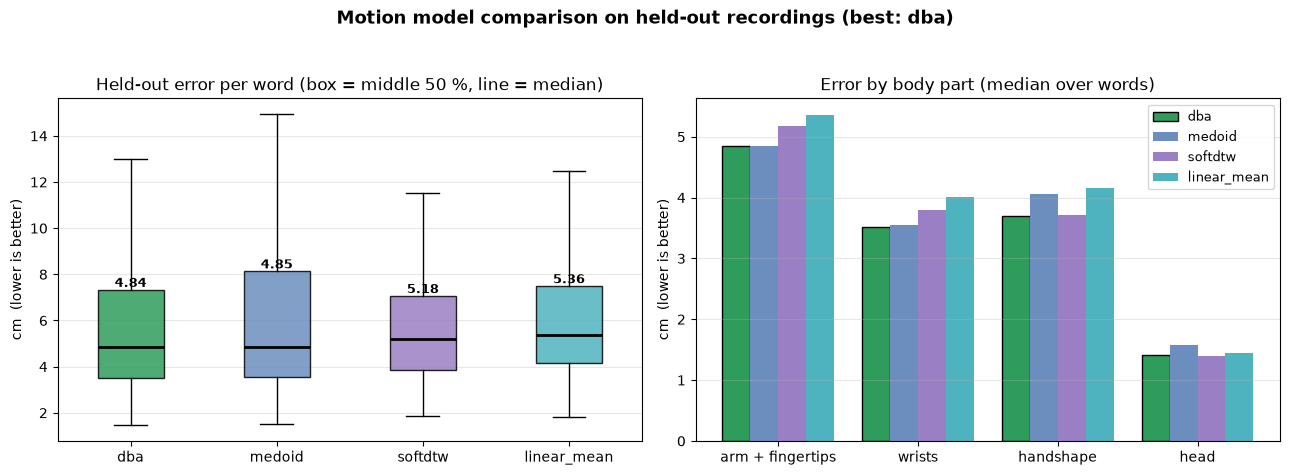

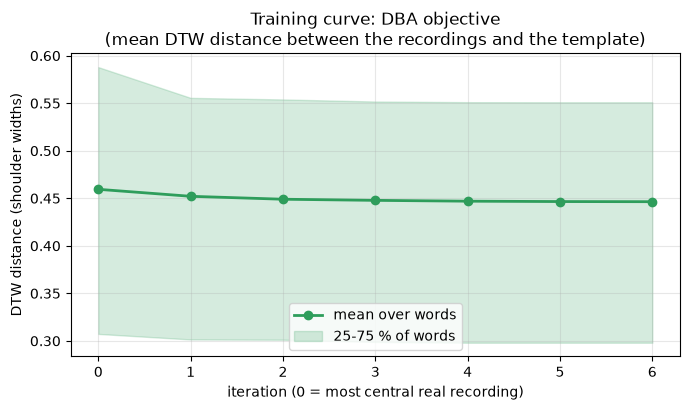

Figures saved to ../plots\include   (results read from ../model/include/train\benchmark_results.pkl)


In [61]:
plot_training_results()

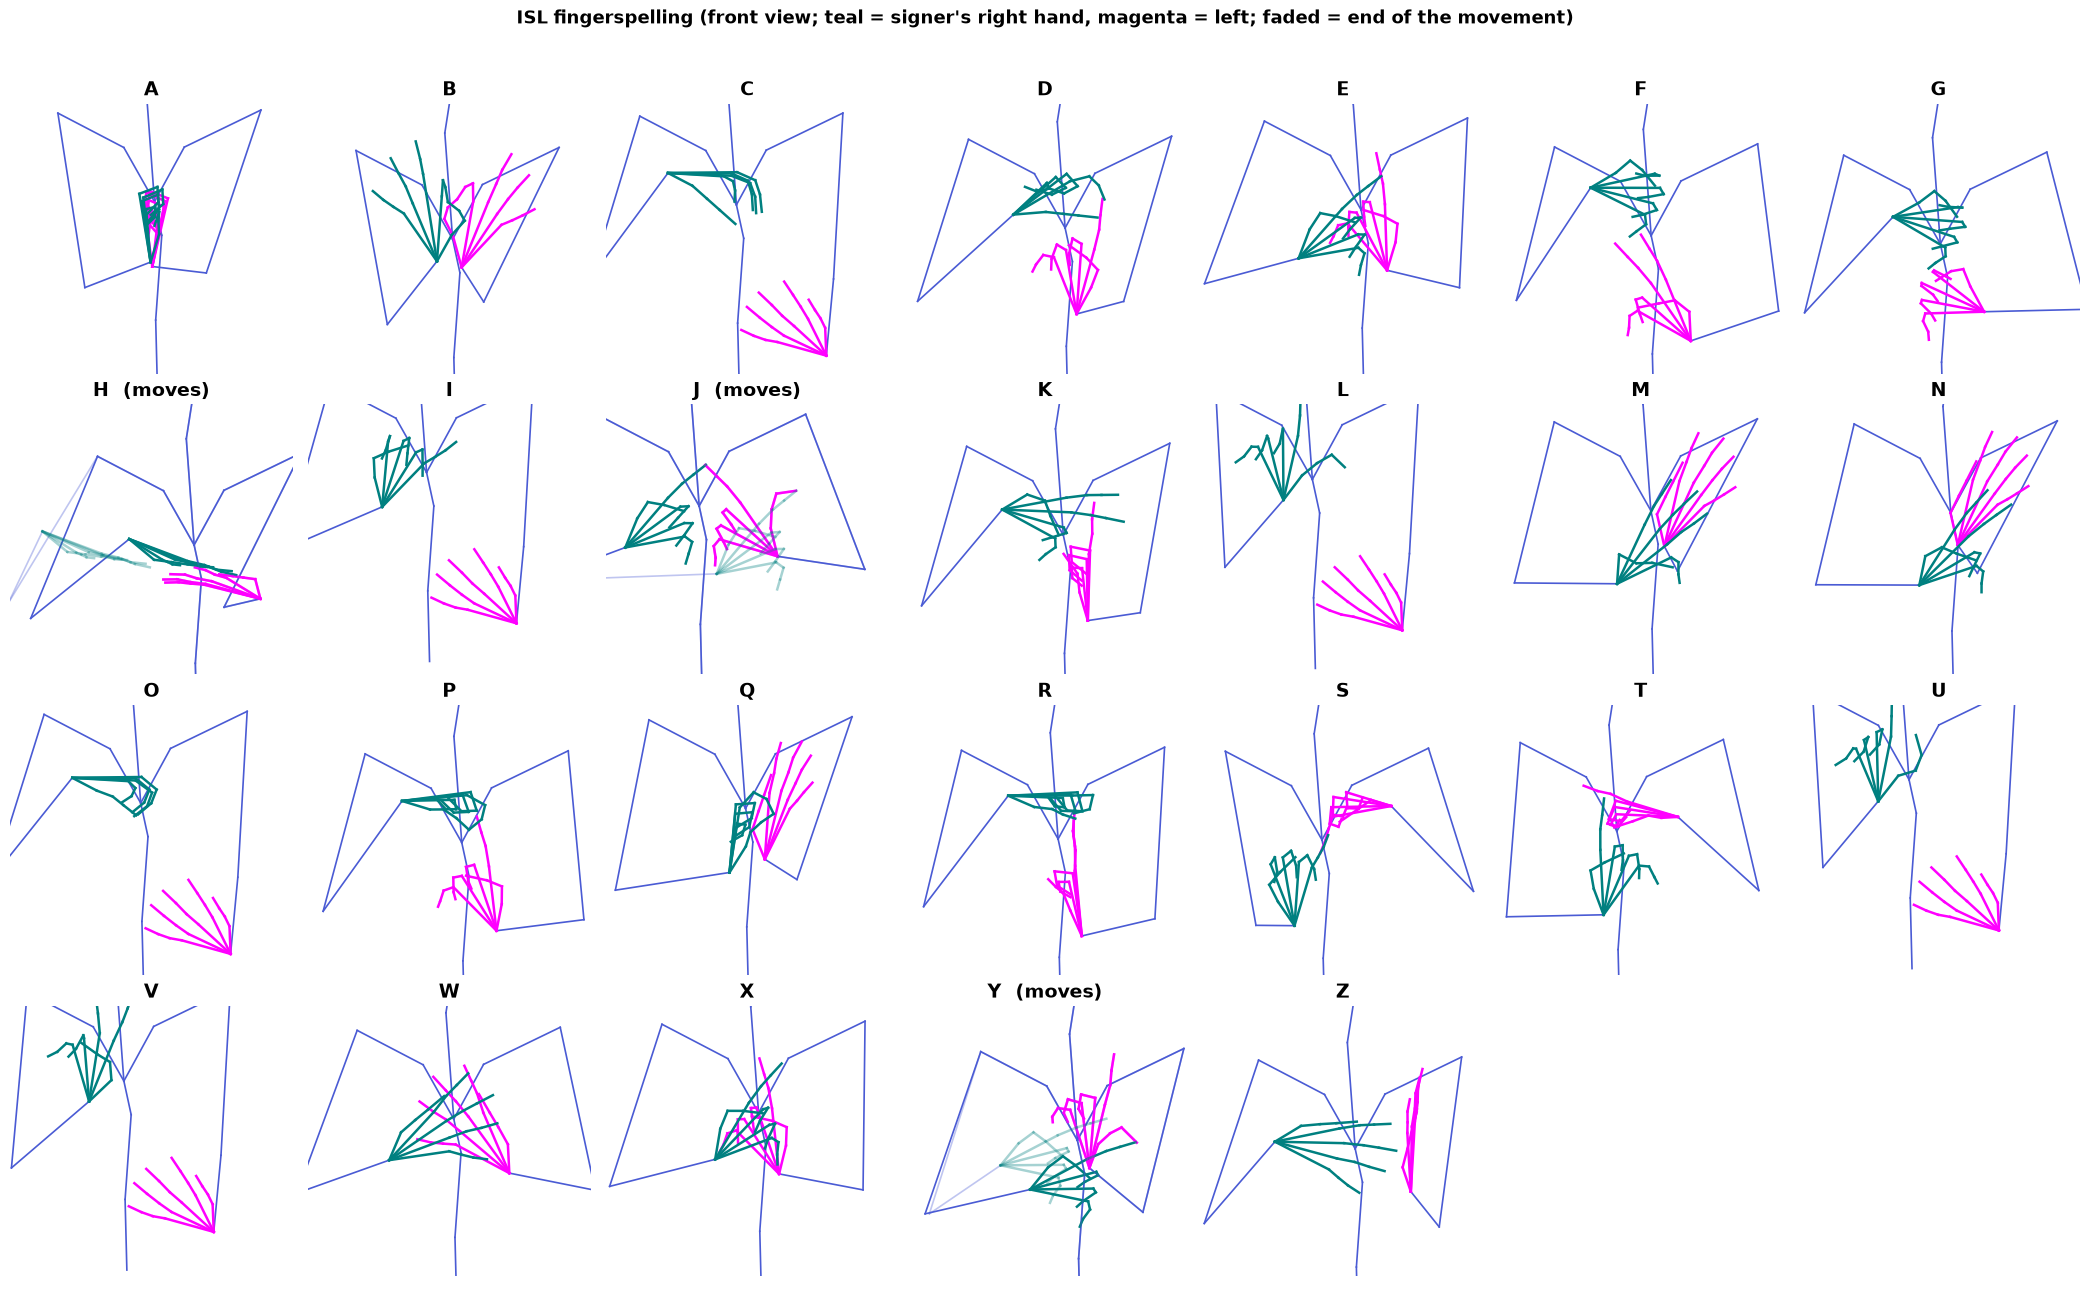

Saved ../plots\include\fingerspelling_alphabet.png
Largest contact gaps (cm): [('D', 'R.index_tip~L.index_tip', 0.9), ('D', 'R.thumb_tip~L.index_mid', 0.8), ('S', 'R.pinky_tip~L.pinky_mid', 0.4)]


In [62]:
plot_fingerspelling_alphabet()

In [63]:
m = fingerspell_word_motion("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
render_smplx_skeleton_video(
    motion_vector_to_smplx(m),
    os.path.join(SKELETON_DIR, "ABCDEFGHIJKLMNOPQRSTUVWXYZ_fingerspelled.mp4"),
    fps=TARGET_FPS,
    title="Fingerspelling: ABCDEFGHIJKLMNOPQRSTUVWXYZ",
)

'../output/include\\skeleton\\ABCDEFGHIJKLMNOPQRSTUVWXYZ_fingerspelled.mp4'

In [74]:
pred_word = "ACTOR"  # glosses are ALL CAPS
motion = generate_gloss_motion(pred_word)

Generated 44 frames of avatar-ready motion for gloss 'ACTOR' [dba].
Saved SMPL-X parameters + motion vector to ../output/include\predicted_npz/ACTOR.npz


In [75]:
npz_file = os.path.join(PREDICTED_NPZ_DIR, f"{pred_word}.npz")
output_preview = os.path.join(PREDICTED_DIR, f"{pred_word}_skeleton_preview.mp4")
render_npz_skeleton_preview(npz_file, output_preview)

Rendering 44 frames to ../output/include\skeleton\predicted\ACTOR_skeleton_preview.mp4...
Render complete!


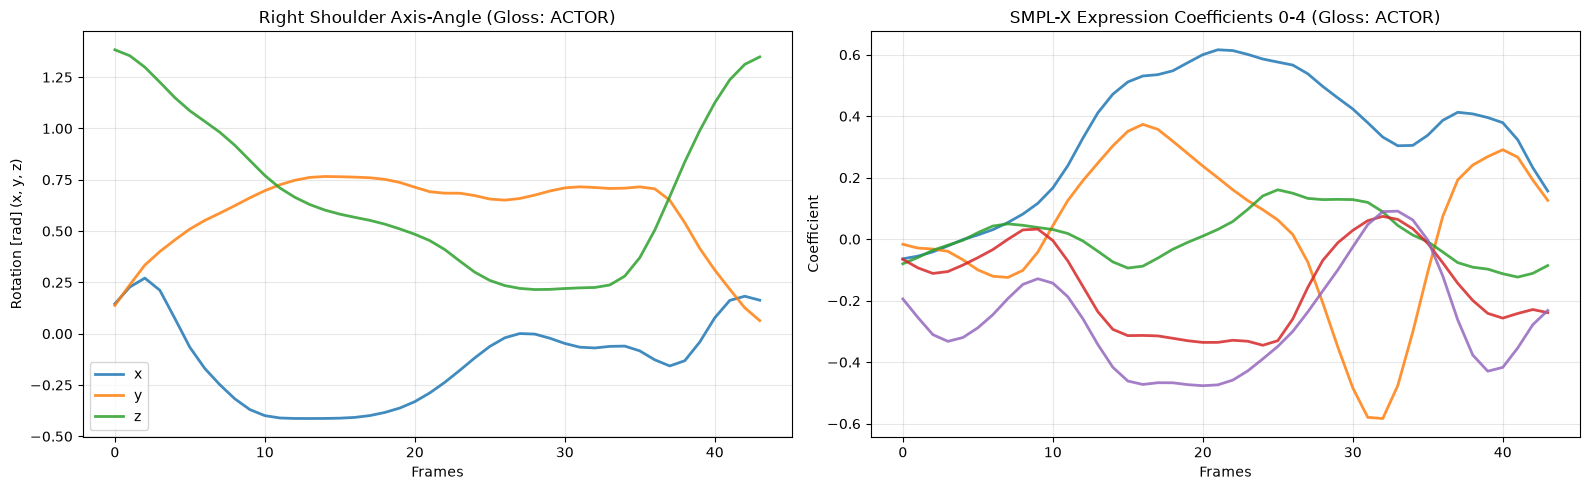

In [76]:
# Test the plot
plot_generated_curves(motion, pred_word)

Generated 44 frames of avatar-ready motion for gloss 'ACTOR' [dba].


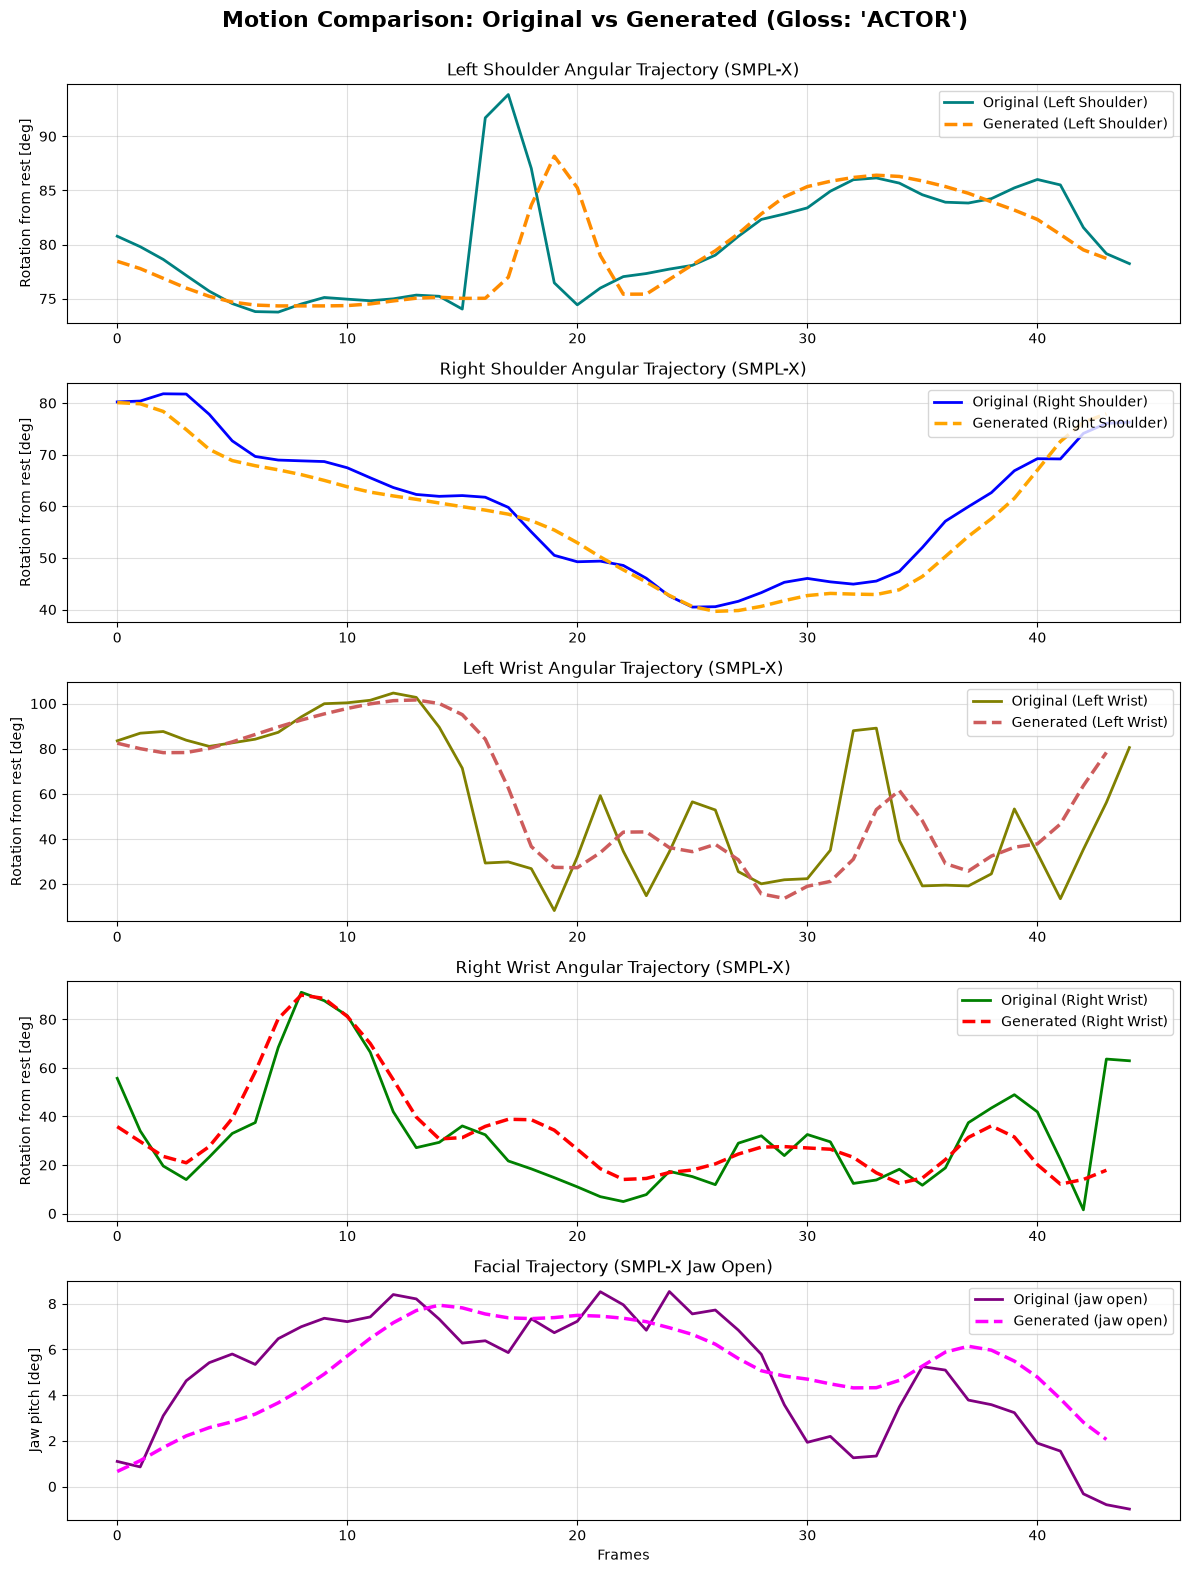

{'mpjpe_dtw_cm': 4.32, 'wrist_cm': 3.22, 'handshape_cm': 3.4, 'nose_cm': 0.7, 'strict_cm': 6.98, 'dur_err_pct': 2.22, 'energy_ratio': 0.91, 'head_above_pct': 100.0}


In [77]:
# 1. A REAL recording of this word, in the same canonical torso form the model is trained on
#    (first clip of the word; it is part of the training data, see the held-out benchmark for an unbiased score)
if "clips" not in globals() or clips is None:
    clips = load_clips(NPZ_DIR)
word_key = gloss_key(pred_word)
if word_key in clips:
    original_motion = clips[word_key][0]["motion"]

    # 2. Generate the sequence from the motion bank
    generated_motion = generate_gloss_motion(pred_word, save=False)

    # 3. Compare them!
    compare_motion_trajectories(original_motion, generated_motion, pred_word)
    print(
        {
            k: round(float(v), 2)
            for k, v in evaluate_prediction(generated_motion, original_motion).items()
        }
    )
else:
    print(f"Could not find original .npz files for gloss '{pred_word}'")

In [78]:
if gloss_key(pred_word) in clips:
    metrics = evaluate_motion_generation(original_motion, generated_motion, pred_word)
else:
    print(
        f"'{gloss_key(pred_word)}' was fingerspelled: there is no recording of it to evaluate against."
    )

MOTION EVALUATION REPORT: 'ACTOR'
Original Length : 45 frames
Generated Length: 44 frames (Aligned to 45)
--------------------------------------------------
1. MEAN ABSOLUTE ERROR (MAE) [Lower is better]
   Overall MAE       : 0.0711
   Skeleton (6D rot) : 0.0625
   Face (Expression) : 0.3151
--------------------------------------------------
2. ROOT MEAN SQUARED ERROR (RMSE) [Lower is better]
   Overall RMSE      : 0.1495
--------------------------------------------------
3. POSE ALIGNMENT [Higher is better, Max 1.0]
   Cosine Similarity : 0.9663
--------------------------------------------------
4. SMPL-X JOINT ROTATION ERROR [Lower is better]
   Mean Joint Angle  : 9.12 deg


### Predict every word and evaluate all of them

Generates the whole vocabulary into `predicted_npz/`, reports the error of every predicted word (also saved as `all_words_evaluation.csv`) and draws the report plot.


Predicted 265 words in 4s -> ../output/include\predicted_npz

ALL-WORDS EVALUATION: 265 words, 1323 recordings  (saved: ../output/include\all_words_evaluation.csv)
arm + fingertip error (cm, time-aligned)   mean    4.686 | median    4.327 | worst   13.234
handshape error (cm)                       mean    3.469 | median    3.284 | worst    7.072
head error (cm)                            mean    1.246 | median    1.177 | worst    2.575
error without time-warp (cm)               mean    7.698 | median    7.218 | worst   19.180
mean joint angle error (deg)               mean   12.103 | median   11.693 | worst   22.585
MAE                                        mean    0.093 | median    0.091 | worst    0.169
RMSE                                       mean    0.177 | median    0.174 | worst    0.296
cosine similarity (higher is better)       mean    0.947 | median    0.951 | worst    0.867
duration error (%)                         mean    8.427 | median    7.288 | worst   40.535
head abo

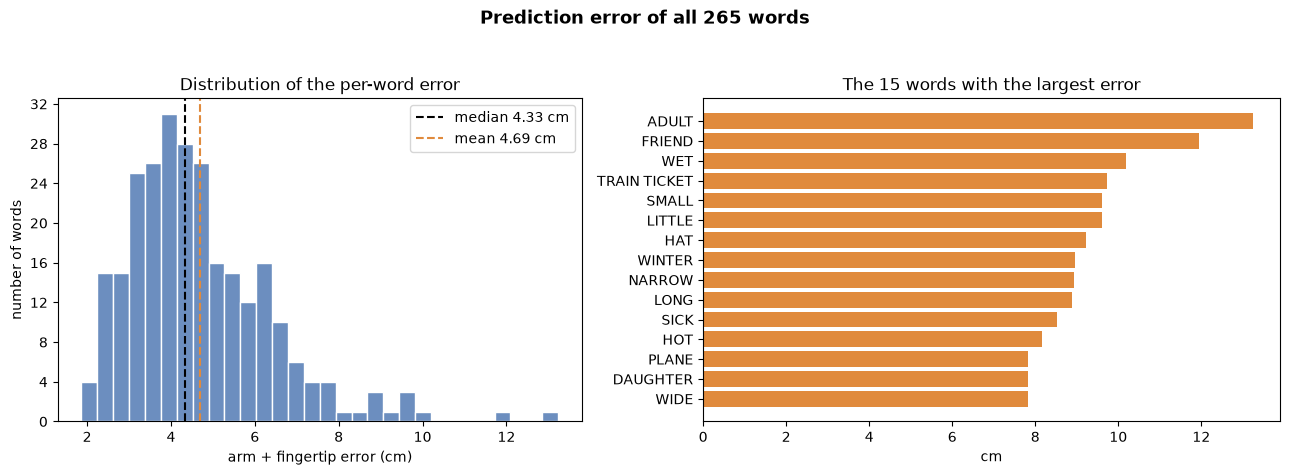

In [79]:
all_words_df = predict_all_words()

Reading ../output/include\all_words_evaluation.csv (saved 2026-11-17 22:25)
Error of 265 predicted words against all their recordings (cm, time-aligned):
                  median  mean  worst
arm + fingertips    4.33  4.69  13.23
wrists              3.18  3.54  11.75
handshape           3.28  3.47   7.07
head                1.18  1.25   2.58


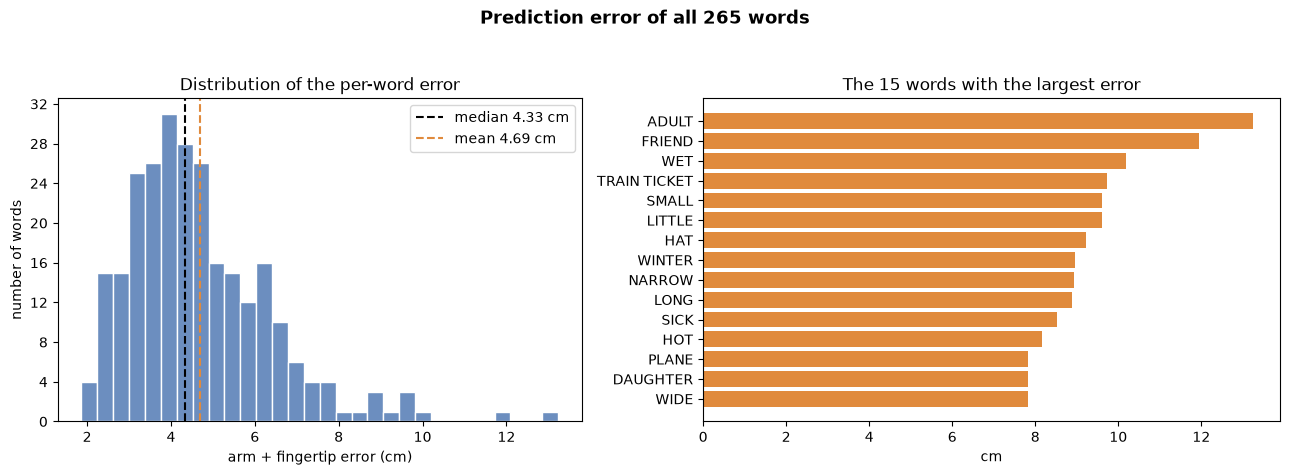

In [80]:
if os.path.exists(_all_words_csv()):
    plot_all_words_report()
else:
    print(
        "No all_words_evaluation.csv yet: run the next cell (predict every word) first."
    )

In [81]:
# Preview videos of the 5 words with the largest error
all_words_csv = os.path.join(SMPLX_OUTPUT_DIR, "all_words_evaluation.csv")
df = pd.read_csv(all_words_csv)

for g in df["gloss"].head(5):
    npz_file = os.path.join(PREDICTED_NPZ_DIR, f"{g.replace(' ', '_')}.npz")
    out = os.path.join(PREDICTED_DIR, f"{g.replace(' ', '_')}_skeleton_preview.mp4")
    render_npz_skeleton_preview(npz_file, out)
    print(f"Rendered {out}")

Rendering 65 frames to ../output/include\skeleton\predicted\ADULT_skeleton_preview.mp4...
Render complete!
Rendered ../output/include\skeleton\predicted\ADULT_skeleton_preview.mp4
Rendering 49 frames to ../output/include\skeleton\predicted\FRIEND_skeleton_preview.mp4...
Render complete!
Rendered ../output/include\skeleton\predicted\FRIEND_skeleton_preview.mp4
Rendering 49 frames to ../output/include\skeleton\predicted\WET_skeleton_preview.mp4...
Render complete!
Rendered ../output/include\skeleton\predicted\WET_skeleton_preview.mp4
Rendering 68 frames to ../output/include\skeleton\predicted\TRAIN_TICKET_skeleton_preview.mp4...
Render complete!
Rendered ../output/include\skeleton\predicted\TRAIN_TICKET_skeleton_preview.mp4
Rendering 37 frames to ../output/include\skeleton\predicted\SMALL_skeleton_preview.mp4...
Render complete!
Rendered ../output/include\skeleton\predicted\SMALL_skeleton_preview.mp4


# Pipeline for sentence


In [49]:
# Motion synthesis (1/5): turns per-gloss specifications into ONE continuous motion:
#   * decides how long every sign lasts (sign's natural duration, sentence rhythm, affect, phrase-final lengthening)
#   * performs each sign naturally (slow-in / slow-out timing, torso stays upright)
#   * joins consecutive signs with adaptive, velocity-matched (C1) transitions, and starts / ends at a
#     neutral hands-down pose
# The MotionSynthesisAgent (section 6) wraps this engine.
def join_motions(motion1, motion2, trans_frames=5):
    """Plain SLERP join of two SMPL-X motion vectors (kept for reference; the synthesizer is used instead)."""
    return join_smplx_motions(motion1, motion2, trans_frames)


def tokenize_gloss(gloss_sequence, vocab, verbose=True, fingerspell=None):
    """
    Splits an ALL-CAPS gloss sequence into vocabulary entries. Multi-word glosses ("GOOD MORNING") are
    matched greedily (longest first), so they are not broken into two unknown words.
    A word that is not in the vocabulary is kept and FINGERSPELLED (when FINGERSPELL_FALLBACK is on and the
    word has letters A-Z); otherwise it is skipped.
    """
    fingerspell = FINGERSPELL_FALLBACK if fingerspell is None else fingerspell
    words = gloss_key(gloss_sequence).split()
    out, i = [], 0
    while i < len(words):
        for n in range(min(4, len(words) - i), 0, -1):
            cand = " ".join(words[i : i + n])
            if cand in vocab:
                out.append(cand)
                i += n
                break
        else:
            if fingerspell and spell_letters(words[i]):
                if verbose:
                    print(
                        f"Note: '{words[i]}' is not in the vocabulary -> it will be fingerspelled."
                    )
                out.append(words[i])
            elif verbose:
                print(
                    f"Warning: Gloss '{words[i]}' not found in the vocabulary. Skipping."
                )
            i += 1
    return out


# ---------------------------------------------------------------------
# per-gloss specification
# ---------------------------------------------------------------------
@dataclass
class GlossSpec:
    """What the planner knows about one sign: the sign itself at its natural speed + where it came from."""

    gloss: str
    motion: (
        np.ndarray
    )  # (T, 292) the sign performed at its natural speed (upright torso)
    nominal_frames: float  # natural duration (median of the recordings)
    source: str = "motion_bank"  # motion_bank | dataset | fingerspell | rest
    n_recordings: int = 0
    hands_only: bool = (
        False  # True for fingerspelling: torso / head / face are filled from the neighbours
    )


# emotional context -> tempo multiplier on every sign's duration (< 1 = faster)
AFFECT_TEMPO = {
    "excited": 0.88,
    "angry": 0.90,
    "happy": 0.95,
    "neutral": 1.0,
    "questioning": 1.0,
    "calm": 1.08,
    "sad": 1.15,
}


def _pose_R(frame):
    return rot6d_to_rotmat(
        np.asarray(frame[:ROT_DIMS], np.float64).reshape(NUM_MOTION_JOINTS, 6)
    )


def _rv(Ra, Rb):
    """rotation vector of Ra^T Rb, per joint: (47,3,3),(47,3,3) -> (47,3)."""
    return Rot.from_matrix(np.einsum("jki,jkl->jil", Ra, Rb)).as_rotvec()


def _clip_norm(v, lim):
    n = np.linalg.norm(v, axis=-1, keepdims=True)
    return v * np.minimum(1.0, lim / np.maximum(n, 1e-9))


def _wrists_rel(motion):
    """Wrist positions relative to the shoulder mid-point, in shoulder widths: (T, 2, 3)."""
    P = fk_points(np.asarray(motion, np.float32))
    shoulder_mid = 0.5 * (P[:, 16] + P[:, 17])
    return (P[:, [20, 21]] - shoulder_mid[:, None]) / _shoulder_width()


def hand_activity_curve(motion, neutral=None):
    """
    How far the more active wrist is from the hands-down rest pose, per frame (shoulder widths).
    ~0 = hands down; > 0.25 = hands are up and signing. The rest pose is the neutral pose when given,
    otherwise the average of the first and last frames.
    """
    w = _wrists_rel(motion)
    if neutral is not None:
        ref = _wrists_rel(np.asarray(neutral, np.float32).reshape(1, -1))[0]
    else:
        ref = 0.5 * (w[:2].mean(0) + w[-2:].mean(0))
    return np.linalg.norm(w - ref[None], axis=-1).max(1)


def rest_dips(motion, neutral=None, thr=0.25):
    """Times the hands drop back to rest BETWEEN the first and the last moment of signing."""
    e = hand_activity_curve(motion, neutral)
    act = np.where(e >= thr)[0]
    if len(act) == 0:
        return {"frames": 0, "runs": 0}
    low = e[act[0] : act[-1] + 1] < thr
    runs, run = 0, 0
    for v in low:
        run = run + 1 if v else 0
        if run == 3:  # a dip = at least 3 consecutive frames with the hands at rest
            runs += 1
    return {"frames": int(low.sum()), "runs": int(runs)}


def motion_continuity(motion, fps=TARGET_FPS):
    """
    How smooth the motion is for EVERY landmark (all upper-body joints, fingertips and face points):
    max speed (cm/frame) and max acceleration (cm/frame^2) of any point. A sudden jump at a word boundary
    shows up as a spike in the acceleration.
    """
    P = fk_points(np.asarray(motion, np.float32))
    pts = (
        [j for j in range(55) if j not in LEG_JOINTS]
        + [55, 56, 57, 58, 59]
        + list(range(66, 76))
    )
    P = P[:, pts] * 100.0
    if len(P) < 3:
        return {"max_speed_cm_per_frame": 0.0, "max_accel_cm_per_frame2": 0.0}
    v = np.linalg.norm(np.diff(P, axis=0), axis=-1)
    a = np.linalg.norm(P[2:] - 2 * P[1:-1] + P[:-2], axis=-1)
    return {
        "max_speed_cm_per_frame": float(v.max()),
        "max_accel_cm_per_frame2": float(a.max()),
        "p99_accel_cm_per_frame2": float(np.percentile(a.max(1), 99)),
    }

In [50]:
# Motion synthesis (2/5): MotionSynthesizer
class MotionSynthesizer:
    """Specifications -> one continuous motion (durations, performance, transitions)."""

    def __init__(
        self,
        fps=TARGET_FPS,
        base_speed=1.0,
        min_sign_frames=10,
        max_sign_frames=140,
        final_lengthening=1.15,
        tempo_spread=(0.6, 1.7),
        min_transition=3,
        max_transition=14,
        transition_gain=4.0,
        natural=True,
        neutral_pose=None,
        lead_frames=6,
        tail_frames=8,
        fixed_transition=None,
        coarticulate=True,
        trim_threshold=0.30,
        trim_distance=0.7,
        trim_margin=1,
        junction_smoothing=True,
        junction_radius=4,
        junction_sigma=1.2,
    ):
        self.fps, self.base_speed = fps, base_speed
        self.min_sign, self.max_sign = min_sign_frames, max_sign_frames
        self.final_lengthening, self.tempo_spread = final_lengthening, tempo_spread
        self.min_t, self.max_t, self.gain = (
            min_transition,
            max_transition,
            transition_gain,
        )
        self.natural, self.fixed_transition = natural, fixed_transition
        self.neutral = (
            None
            if neutral_pose is None
            else np.asarray(neutral_pose, np.float32).reshape(1, -1)
        )
        self.lead_frames, self.tail_frames = lead_frames, tail_frames
        # co-articulation: every word template starts and ends with the hands at rest (that is how the
        # recordings were cut). Inside a sentence those rest parts are removed so the hands go straight
        # from the end of one sign to the start of the next, instead of dropping down between words.
        self.coarticulate, self.trim_threshold, self.trim_margin = (
            coarticulate,
            trim_threshold,
            trim_margin,
        )
        self.trim_distance = trim_distance  # hands must be this far (shoulder widths) from rest to count as signing
        # light low-pass filter applied only around the joins (removes acceleration spikes at the boundaries)
        self.junction_smoothing = junction_smoothing
        self.junction_radius, self.junction_sigma = junction_radius, junction_sigma

    # ------------------------- 0. the part of a sign where the hands are actually signing -------------------------
    def active_window(self, motion):
        """(first, last) frame of the signing part of a template; the rest before / after is not needed mid-sentence."""
        T = len(motion)
        e = hand_activity_curve(motion, self.neutral)
        emax = float(e.max())
        if emax < 0.3:  # hands barely move: keep everything
            return 0, T - 1
        act = np.where(
            e >= max(0.15, min(self.trim_distance, self.trim_threshold * emax))
        )[0]
        a0, a1 = max(0, int(act[0]) - self.trim_margin), min(
            T - 1, int(act[-1]) + self.trim_margin
        )
        need = max(8, int(0.5 * T))  # never keep less than about half of the sign
        while a1 - a0 + 1 < need and (a0 > 0 or a1 < T - 1):
            a0, a1 = max(0, a0 - 1), min(T - 1, a1 + 1)
        return a0, a1

    def trim_specs(self, specs):
        """Co-articulation: cut the hands-down start/end of every INNER boundary; the sentence's own start and end stay."""
        n, out, trims = len(specs), [], []
        for i, s in enumerate(specs):
            if not self.coarticulate or n < 2 or s.source in ("rest", "fingerspell"):
                out.append(s)
                trims.append((0, 0))
                continue
            a0, a1 = self.active_window(s.motion)
            t0 = a0 if i > 0 else 0
            t1 = a1 if i < n - 1 else len(s.motion) - 1
            core = s.motion[t0 : t1 + 1]
            out.append(
                replace(
                    s,
                    motion=core,
                    nominal_frames=s.nominal_frames * len(core) / len(s.motion),
                )
            )
            trims.append((t0, len(s.motion) - 1 - t1))
        return out, trims

    # ------------------------- 1. how long does each sign last? -------------------------
    def decide_durations(self, specs, sentence_type="declarative", affect="neutral"):
        nominal = np.array([s.nominal_frames for s in specs], float)
        spelled = np.array([s.source == "fingerspell" for s in specs])
        med = (
            float(np.median(nominal[~spelled]))
            if np.any(~spelled)
            else float(np.median(nominal))
        )
        lo, hi = self.tempo_spread
        d = np.clip(
            nominal, lo * med, hi * med
        )  # rhythm: no sign far shorter / longer than its neighbours
        d[spelled] = nominal[
            spelled
        ]  # a spelled word keeps its letter timing (it is not squeezed to one sign)
        d = d * AFFECT_TEMPO.get(str(affect).lower(), 1.0) / self.base_speed
        extra = (
            0.05 if sentence_type in ("interrogative", "negation") else 0.0
        )  # marked final sign is held longer
        d[-1] *= self.final_lengthening + extra  # phrase-final lengthening
        for i, s in enumerate(specs):
            if s.source == "rest":  # unknown sign -> short pause, not a long still
                d[i] = self.min_sign
        upper = np.where(spelled, np.inf, self.max_sign)
        return np.clip(np.round(d), self.min_sign, upper).astype(int)

    # ------------------------- 2. natural performance of one sign -------------------------
    def perform(self, spec, n_frames):
        m, T, n = np.asarray(spec.motion, np.float32), len(spec.motion), int(n_frames)
        tau = np.linspace(0.0, 1.0, n)
        if self.natural and T > 4 and spec.source not in ("rest", "fingerspell"):
            a = 0.12  # slow-in / slow-out: speed 1-a at both ends of the sign, 1+a in the middle
            ph = tau - a * np.sin(2 * np.pi * tau) / (2 * np.pi)
            tau = (ph - ph[0]) / (ph[-1] - ph[0])
        idx = tau * (T - 1)
        i0 = np.floor(idx).astype(int)
        i1 = np.minimum(i0 + 1, T - 1)
        w = (idx - i0)[:, None].astype(np.float32)
        return project_motion_vector((1 - w) * m[i0] + w * m[i1])

    # ------------------------- 3. transitions between two signs -------------------------
    def decide_transition(self, end_frame, start_frame, lo=None, hi=None):
        if self.fixed_transition is not None:
            return int(self.fixed_transition)
        lo = self.min_t if lo is None else lo
        hi = self.max_t if hi is None else hi
        fa, fb = clip_features(end_frame[None]), clip_features(start_frame[None])
        dist = float(
            np.linalg.norm((fa - fb).reshape(-1, 3), axis=-1).mean()
        )  # shoulder-widths
        return int(np.clip(round(lo + self.gain * dist), lo, hi))

    def transition(self, prev, nxt, n):
        """
        n frames strictly between prev[-1] and nxt[0]; cubic Hermite in rotation space that matches the
        angular velocity at the end of `prev` and at the start of `nxt` (no speed jump, no stop-and-go).
        """
        if n <= 0:
            return np.empty((0, MOTION_DIM), np.float32)
        RA1, RA0 = _pose_R(prev[-1]), _pose_R(prev[-2] if len(prev) > 1 else prev[-1])
        RB0, RB1 = _pose_R(nxt[0]), _pose_R(nxt[1] if len(nxt) > 1 else nxt[0])
        delta, wA, wB = _rv(RA1, RB0), _rv(RA0, RA1), _rv(RB0, RB1)
        span = n + 1
        lim = 1.5 * np.linalg.norm(delta, axis=-1, keepdims=True) + 0.05  # no overshoot
        m0, m1 = _clip_norm(wA * span, lim), _clip_norm(wB * span, lim)
        tau = (np.arange(1, n + 1) / span)[:, None, None]
        h10, h01, h11 = (
            tau**3 - 2 * tau**2 + tau,
            -2 * tau**3 + 3 * tau**2,
            tau**3 - tau**2,
        )
        x = h10 * m0[None] + h01 * delta[None] + h11 * m1[None]  # (n,47,3)
        Rt = RA1[None] @ Rot.from_rotvec(x.reshape(-1, 3)).as_matrix().reshape(
            n, NUM_MOTION_JOINTS, 3, 3
        )
        eA1 = prev[-1][EXPR_SLICE].astype(np.float64)
        eA0 = (prev[-2] if len(prev) > 1 else prev[-1])[EXPR_SLICE].astype(np.float64)
        eB0 = nxt[0][EXPR_SLICE].astype(np.float64)
        eB1 = (nxt[1] if len(nxt) > 1 else nxt[0])[EXPR_SLICE].astype(np.float64)
        t1 = tau[:, :, 0]
        g10, g01, g11 = t1**3 - 2 * t1**2 + t1, -2 * t1**3 + 3 * t1**2, t1**3 - t1**2
        e = (
            eA1
            + g10 * (eA1 - eA0) * span
            + g01 * (eB0 - eA1)
            + g11 * (eB1 - eB0) * span
        )
        return R_to_motion(Rt, np.clip(e, -EXPRESSION_CLIP, EXPRESSION_CLIP))

    # ------------------------- 3b. body / face of fingerspelled words -------------------------
    def fill_hands_only(self, specs, signs):
        """
        Fingerspelling moves only the arms and hands. The torso, head and face of a spelled word (or a run of
        spelled words) are taken from the signs around it: they glide smoothly from the last frame of the
        previous recorded sign to the first frame of the next one (held when only one side exists, neutral
        and static when the sentence has no recorded sign at all).
        """
        neutral = self.neutral[0] if self.neutral is not None else rest_motion(1)[0]
        known = [
            k for k, s in enumerate(specs) if s.source not in ("fingerspell", "rest")
        ]
        n, i = len(specs), 0
        while i < n:
            if not specs[i].hands_only:
                i += 1
                continue
            j = i
            while j + 1 < n and specs[j + 1].hands_only:
                j += 1
            prev = max((k for k in known if k < i), default=None)
            nxt = min((k for k in known if k > j), default=None)
            A = signs[prev][-1] if prev is not None else None
            B = signs[nxt][0] if nxt is not None else None
            if A is None and B is None:
                A = B = neutral
            elif A is None:
                A = B
            elif B is None:
                B = A
            lengths = [len(signs[k]) for k in range(i, j + 1)]
            t = np.linspace(0.0, 1.0, sum(lengths))
            w = t * t * (3 - 2 * t)
            RA = motion_to_R(np.asarray(A)[None])[0][BODY_SLOTS]
            RB = motion_to_R(np.asarray(B)[None])[0][BODY_SLOTS]
            Rb = _slerp_R(RA, RB, w)
            eb = (1 - w)[:, None] * np.asarray(A)[EXPR_SLICE] + w[:, None] * np.asarray(
                B
            )[EXPR_SLICE]
            off = 0
            for k, L in zip(range(i, j + 1), lengths):
                R = motion_to_R(signs[k])
                R[:, BODY_SLOTS] = Rb[off : off + L]
                signs[k] = R_to_motion(R, eb[off : off + L])
                off += L
            i = j + 1
        return signs

    def smooth_junctions(self, motion, junctions):
        """Blend a Gaussian-smoothed copy into the frames around every join (weight 1 at the join, 0 beyond the radius)."""
        if not self.junction_smoothing or not junctions or len(motion) < 5:
            return motion
        r = self.junction_radius
        sm = gaussian_filter1d(motion, self.junction_sigma, axis=0, mode="nearest")
        w = np.zeros(len(motion))
        for b in junctions:
            idx = np.arange(max(0, b - r), min(len(motion), b + r + 1))
            w[idx] = np.maximum(w[idx], 1.0 - np.abs(idx - b) / (r + 1.0))
        return project_motion_vector((1 - w[:, None]) * motion + w[:, None] * sm)

    # ------------------------- 4. everything together -------------------------
    def synthesize(self, specs, sentence_type="declarative", affect="neutral"):
        """Returns (motion (T,292), info). info['signs'] / ['transitions'] / ['segments'] hold the timeline."""
        if not specs:
            raise ValueError("No gloss specifications to synthesize.")
        specs, trims = self.trim_specs(specs)
        durs = self.decide_durations(specs, sentence_type, affect)
        signs = []
        for i, (s, d) in enumerate(zip(specs, durs)):
            if (
                s.source == "rest" and i > 0 and self.coarticulate
            ):  # unknown sign: keep the hands where they are
                signs.append(np.repeat(signs[-1][-1:], int(d), 0))
            else:
                signs.append(self.perform(s, d))
        signs = self.fill_hands_only(specs, signs)
        parts, segs, sign_info, trans_info = [], [], [], []
        cursor = 0

        def add(arr, kind, label):
            nonlocal cursor
            if len(arr) == 0:
                return
            parts.append(arr)
            segs.append(
                {
                    "type": kind,
                    "label": label,
                    "start": cursor,
                    "end": cursor + len(arr),
                }
            )
            cursor += len(arr)

        prev = None
        if (
            self.neutral is not None and self.lead_frames > 0
        ):  # start from the hands-down pose
            lead = np.repeat(self.neutral, max(self.lead_frames, 2), 0)
            add(lead, "lead", "neutral")
            prev = lead
        for i, (spec, sg) in enumerate(zip(specs, signs)):
            if prev is not None:
                n = self.decide_transition(
                    prev[-1],
                    sg[0],
                    lo=self.min_t + (3 if i == 0 else 0),
                    hi=self.max_t + (4 if i == 0 else 0),
                )
                tr = self.transition(prev, sg, n)
                add(tr, "transition", "->")
                if len(tr):
                    trans_info.append(
                        {
                            "after": i - 1,
                            "start": segs[-1]["start"],
                            "end": segs[-1]["end"],
                            "frames": len(tr),
                        }
                    )
            start = cursor
            add(sg, "sign", spec.gloss)
            sign_info.append(
                {
                    "index": i,
                    "gloss": spec.gloss,
                    "source": spec.source,
                    "start": start,
                    "end": cursor,
                    "frames": len(sg),
                    "nominal_frames": float(spec.nominal_frames),
                    "n_recordings": spec.n_recordings,
                    "trimmed_start": trims[i][0],
                    "trimmed_end": trims[i][1],
                }
            )
            prev = sg
        if (
            self.neutral is not None and self.tail_frames > 0
        ):  # return to the hands-down pose
            tail = np.repeat(self.neutral, max(self.tail_frames, 2), 0)
            n = self.decide_transition(
                prev[-1], tail[0], lo=self.min_t + 3, hi=self.max_t + 4
            )
            tr = self.transition(prev, tail, n)
            add(tr, "transition", "->")
            if len(tr):
                trans_info.append(
                    {
                        "after": len(specs) - 1,
                        "start": segs[-1]["start"],
                        "end": segs[-1]["end"],
                        "frames": len(tr),
                    }
                )
            add(tail, "tail", "neutral")
        motion = project_motion_vector(np.concatenate(parts))
        joins = sorted({b for t in trans_info for b in (t["start"], t["end"])})
        motion = enforce_limits(self.smooth_junctions(motion, joins))
        info = {
            "fps": self.fps,
            "sentence_type": sentence_type,
            "affect": affect,
            "durations": durs.tolist(),
            "signs": sign_info,
            "transitions": trans_info,
            "segments": segs,
            "total_frames": len(motion),
            "coarticulate": self.coarticulate,
            "rest_dips": rest_dips(motion, self.neutral),
            "fingerspelled": [s.gloss for s in specs if s.source == "fingerspell"],
            "continuity": motion_continuity(motion),
        }
        return motion, info

In [51]:
# Sentence generation (3/5): gloss sequence -> motion
LAST_SENTENCE_INFO = (
    {}
)  # timeline of the most recent generate_sentence_motion() call (used by the graphs)
LAST_TRANSLATION = (
    {}
)  # English sentence -> gloss -> tokens of the most recent translate_sentence_to_motion() call


def fingerspell_spec(word, neutral=None):
    """GlossSpec of a fingerspelled word (hands only; the synthesizer fills torso / head / face)."""
    m = fingerspell_motion(word, body_frame=neutral)
    return GlossSpec(
        gloss=gloss_key(word),
        motion=m,
        nominal_frames=float(len(m)),
        source="fingerspell",
        n_recordings=0,
        hands_only=True,
    )


def build_gloss_specs(tokens, bank):
    """Gloss list -> GlossSpec list using the motion bank (each sign at its natural speed); unknown words are spelled."""
    specs = []
    neutral = bank.meta.get("neutral_pose")
    for key in tokens:
        if key not in bank.templates:
            specs.append(fingerspell_spec(key, neutral))
            continue
        t = bank.templates[key]
        specs.append(
            GlossSpec(
                gloss=key,
                motion=bank.generate(key),
                nominal_frames=t["n_frames"],
                source="motion_bank",
                n_recordings=t["n_clips"],
            )
        )
    return specs


def generate_sentence_motion(
    gloss_sequence,
    trans_frames=None,
    fps=TARGET_FPS,
    speed=1.0,
    bank=None,
    sentence_type="declarative",
    affect="neutral",
    natural=True,
    rest_ends=True,
    coarticulate=True,
    name=None,
    verbose_tokens=True,
):
    """
    Generates ONE continuous SMPL-X motion for a sequence of ALL-CAPS gloss words.
    trans_frames=None -> adaptive transition length (recommended); an int forces a fixed length.
    coarticulate=True -> the hands go straight from one sign to the next (no return to the hands-down pose
    between words); the sentence still starts and ends at the neutral pose when rest_ends=True.
    The timeline of the result is stored in LAST_SENTENCE_INFO.
    For ENGLISH input use translate_sentence_to_motion().
    """
    global LAST_SENTENCE_INFO
    bank = bank or get_motion_bank()
    tokens = tokenize_gloss(gloss_sequence, bank.templates, verbose=verbose_tokens)
    if not tokens:
        raise ValueError(
            f"No valid glosses generated for sequence: '{gloss_sequence}'."
        )
    neutral = bank.meta.get("neutral_pose") if rest_ends else None
    specs = build_gloss_specs(tokens, bank)

    def make(co):
        return MotionSynthesizer(
            fps=fps,
            base_speed=speed,
            natural=natural,
            neutral_pose=neutral,
            fixed_transition=trans_frames,
            coarticulate=co,
        ).synthesize(specs, sentence_type, affect)

    final_motion, info = make(coarticulate)
    if (
        coarticulate and len(tokens) > 1
    ):  # how much worse would it be if every word went back to rest?
        base_motion, base_info = make(False)
        info["baseline"] = {
            "rest_dips": base_info["rest_dips"],
            "activity": hand_activity_curve(base_motion, neutral).tolist(),
            "total_frames": base_info["total_frames"],
        }
    info["activity"] = hand_activity_curve(final_motion, neutral).tolist()
    LAST_SENTENCE_INFO = info

    os.makedirs(PREDICTED_NPZ_DIR, exist_ok=True)
    safe_filename = (name or gloss_key(gloss_sequence)).replace(" ", "_")
    save_predicted_motion(
        os.path.join(PREDICTED_NPZ_DIR, f"{safe_filename}.npz"),
        final_motion,
        fps=fps,
        gloss_sequence=np.array(gloss_key(gloss_sequence)),
    )
    print(
        f"Generated {final_motion.shape[0]} frames ({final_motion.shape[0] / fps:.1f}s) | "
        f"signs: {[(s['gloss'], s['frames']) for s in info['signs']]}"
    )
    print(
        f"Transitions (frames): {[t['frames'] for t in info['transitions']]} | "
        f"saved to {PREDICTED_NPZ_DIR}/{safe_filename}.npz"
    )
    if "baseline" in info:
        print(
            f"Hands dropping back to rest between words: {info['rest_dips']['runs']} times "
            f"(without co-articulation it would be {info['baseline']['rest_dips']['runs']})."
        )
    if info["fingerspelled"]:
        print(f"Fingerspelled (not in the vocabulary): {info['fingerspelled']}")
    c = info["continuity"]
    print(
        f"Continuity of every landmark: max speed {c['max_speed_cm_per_frame']:.1f} cm/frame, "
        f"max acceleration {c['max_accel_cm_per_frame2']:.1f} cm/frame^2"
    )
    return final_motion

In [52]:
# English sentence -> gloss -> motion (4/5)
def detect_sentence_type(text):
    """Same rule as the NLU & Context Agent: interrogative / negation / declarative."""
    cleaned = " ".join(str(text).strip().split())
    if cleaned.endswith("?"):
        return "interrogative"
    if " not " in f" {cleaned.lower()} " or cleaned.lower().startswith("no "):
        return "negation"
    return "declarative"


class GlossTranslator:
    """
    English -> ISL gloss with the Flan-T5 model trained in the Gloss section (same prefix, beams and
    ALL-CAPS output as generate_gloss). Loaded lazily and only once. Self-contained, so it also works after a
    kernel restart as long as the trained model folder exists.
    """

    def __init__(self, model_dir=None, prefix=None, num_beams=None):
        self.model_dir = model_dir or globals().get(
            "MODEL_OUTPUT_DIR", os.path.join(BASE_DIR, "model/include")
        )
        self.prefix = prefix or globals().get(
            "PREFIX", "translate English to ISL gloss: "
        )
        self.num_beams = num_beams or globals().get("NUM_BEAMS", 4)
        self.model = self.tokenizer = None
        self._loaded = False

    def _load(self):
        self._loaded = True
        if not os.path.exists(os.path.join(self.model_dir, "config.json")):
            print(
                f"[Warning] No trained gloss model in '{self.model_dir}': every English word is used as a gloss "
                f"(train the Gloss section first for a real translation)."
            )
            return
        from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.tokenizer = AutoTokenizer.from_pretrained(self.model_dir)
        self.model = (
            AutoModelForSeq2SeqLM.from_pretrained(self.model_dir).to(self.device).eval()
        )

    @torch.no_grad()
    def translate(self, text):
        if not self._loaded:
            self._load()
        cleaned = " ".join(str(text).split())
        if self.model is None:
            return " ".join(cleaned.upper().replace("?", "").split())
        enc = self.tokenizer(
            [self.prefix + cleaned],
            max_length=globals().get("MAX_SRC_LEN", 64),
            truncation=True,
            padding=True,
            return_tensors="pt",
        ).to(self.device)
        out = self.model.generate(
            **enc,
            max_new_tokens=globals().get("MAX_TGT_LEN", 64),
            num_beams=self.num_beams,
        )
        return " ".join(
            self.tokenizer.batch_decode(out, skip_special_tokens=True)[0]
            .strip()
            .split()
        ).upper()


GLOSS_TRANSLATOR = GlossTranslator()


def translate_sentence_to_motion(
    english_sentence, context=None, bank=None, translator=None, **kwargs
):
    """
    ENGLISH sentence -> ISL gloss -> one continuous avatar motion.
        sentence type (question / negation) + emotion  ->  decide tempo and holds
        Flan-T5                                        ->  ISL gloss
        motion bank + motion synthesizer               ->  signs joined without returning to rest
    context: e.g. {"emotion": "excited"}. Extra keyword arguments go to generate_sentence_motion.
    Everything (English, gloss, kept / skipped words) is stored in LAST_TRANSLATION.
    """
    global LAST_TRANSLATION
    bank = bank or get_motion_bank()
    cleaned = " ".join(str(english_sentence).strip().split())
    if not cleaned:
        raise ValueError("Empty sentence.")
    sentence_type = detect_sentence_type(cleaned)
    affect = (context or {}).get("emotion", "neutral")
    gloss = (translator or GLOSS_TRANSLATOR).translate(cleaned)
    tokens = tokenize_gloss(gloss, bank.templates)
    if not tokens:
        raise ValueError(
            f"None of the glosses '{gloss}' is in the motion vocabulary or can be spelled."
        )
    kept = set(" ".join(tokens).split())
    skipped = [w for w in gloss_key(gloss).split() if w not in kept]
    spelled = [t for t in tokens if t not in bank.templates]
    slug = re.sub(r"[^A-Za-z0-9]+", "_", gloss_key(gloss)).strip("_")[:60] or "sentence"
    LAST_TRANSLATION = {
        "english": cleaned,
        "gloss": gloss_key(gloss),
        "tokens": tokens,
        "skipped": skipped,
        "fingerspelled": spelled,
        "sentence_type": sentence_type,
        "affect": affect,
        "name": slug,
    }
    print(f'English : "{cleaned}"   [{sentence_type}, affect: {affect}]')
    print(
        f"Gloss   : {gloss_key(gloss)}"
        + (f"   (not in the vocabulary, skipped: {skipped})" if skipped else "")
        + (f"   (fingerspelled: {spelled})" if spelled else "")
    )
    return generate_sentence_motion(
        " ".join(tokens),
        bank=bank,
        sentence_type=sentence_type,
        affect=affect,
        name=slug,
        verbose_tokens=False,
        **kwargs,
    )

In [53]:
# Sentence-level evaluation (5/5)
LAST_SENTENCE_EVAL = None  # per-word table of the most recent evaluate_sentence() call (used by the graphs)


def calculate_motion_metrics(pred_motion, target_motion):
    """Aligns sequence lengths via interpolation and computes MSE, Cosine Similarity and joint angle error."""
    p_tensor = (
        torch.tensor(pred_motion, dtype=torch.float32).unsqueeze(0).transpose(1, 2)
    )
    t_tensor = (
        torch.tensor(target_motion, dtype=torch.float32).unsqueeze(0).transpose(1, 2)
    )
    p_aligned = F.interpolate(
        p_tensor, size=t_tensor.shape[2], mode="linear", align_corners=False
    )
    mse = F.mse_loss(p_aligned, t_tensor).item()
    cos_sim = (
        F.cosine_similarity(
            p_aligned.squeeze(0).transpose(0, 1),
            t_tensor.squeeze(0).transpose(0, 1),
            dim=1,
        )
        .mean()
        .item()
    )
    p_np = project_motion_vector(p_aligned.squeeze(0).transpose(0, 1).numpy())
    t_np = np.asarray(target_motion)
    T = t_np.shape[0]
    rot_p = rot6d_to_rotmat(p_np[:, :ROT_DIMS].reshape(T, NUM_MOTION_JOINTS, 6))
    rot_t = rot6d_to_rotmat(t_np[:, :ROT_DIMS].reshape(T, NUM_MOTION_JOINTS, 6))
    return mse, cos_sim, float(np.mean(geodesic_angle_deg(rot_p, rot_t)))


def evaluate_sentence(gloss_sequence, data_dir=NPZ_DIR, bank=None):
    """
    Evaluates every word of a sentence (as the model generates it) against a real recording, then averages.
    (The recording is the first clip of the word, in the same canonical torso form as the model.
    These clips were part of the training data, so use the held-out benchmark for an unbiased score.)
    The per-word table is kept in LAST_SENTENCE_EVAL for the graphs.
    """
    global clips, LAST_SENTENCE_EVAL
    import pandas as pd

    bank = bank or get_motion_bank()
    if "clips" not in globals() or clips is None:
        clips = load_clips(data_dir)
    tokens = tokenize_gloss(gloss_sequence, bank.templates)
    rows = []
    print(f"Evaluating Sequence: '{gloss_key(gloss_sequence)}'")
    print("-" * 78)
    for key in tokens:
        if key not in clips:
            reason = (
                "fingerspelled, no recording to compare"
                if key not in bank.templates
                else "no ground truth clip found"
            )
            print(f"[{key}] Skipped: {reason}.")
            continue
        target = clips[key][0]["motion"]
        pred = bank.generate(key)
        mse, sim, angle = calculate_motion_metrics(pred, target)
        cm = evaluate_prediction(pred, target)
        rows.append(
            {"gloss": key, "mse": mse, "cos_sim": sim, "joint_angle_deg": angle, **cm}
        )
        print(
            f"{key:<15} | MSE {mse:.4f} | CosSim {sim:.4f} | joint err {angle:5.2f} deg | "
            f"arm/hand err {cm['mpjpe_dtw_cm']:5.2f} cm | head above shoulders {cm['head_above_pct']:.0f}%"
        )
    if not rows:
        print("No valid ground truth words were found to evaluate.")
        return None, None
    df = pd.DataFrame(rows)
    LAST_SENTENCE_EVAL = df
    print("-" * 78)
    print("SENTENCE MACRO-AVERAGE")
    print(f"Average MSE             : {df['mse'].mean():.4f}")
    print(f"Average Cosine Sim      : {df['cos_sim'].mean():.4f}")
    print(f"Average Joint Angle Err : {df['joint_angle_deg'].mean():.2f} deg")
    print(
        f"Average arm/hand error  : {df['mpjpe_dtw_cm'].mean():.2f} cm (time-aligned)"
    )
    print(f"Head above shoulders    : {df['head_above_pct'].mean():.0f}% of frames")
    print("-" * 78)
    return float(df["mse"].mean()), float(df["cos_sim"].mean())

In [54]:
# Visualisation (1/3): helpers, skeleton preview video, snapshots
_SIGN_COLORS = plt.cm.tab10.colors


def _draw_skeleton_2d(ax, pts, origin, lw=1.6):
    """Front view (x right = subject's left, y up) of one SMPL-X frame."""
    P = pts - origin
    for edges, color in (
        (BODY_EDGES_SMPLX, "blue"),
        (FACE_EDGES_SMPLX, "orange"),
        (LEFT_HAND_EDGES_SMPLX, "magenta"),
        (RIGHT_HAND_EDGES_SMPLX, "cyan"),
    ):
        for a, b in edges:
            ax.plot(
                [P[a, 0], P[b, 0]],
                [P[a, 1], P[b, 1]],
                c=color,
                lw=lw,
                solid_capstyle="round",
            )
    ax.set_xlim(-0.75, 0.75)
    ax.set_ylim(-0.55, 0.55)
    ax.set_aspect("equal")
    ax.axis("off")


def _prepare_viz_context(motion, info=None, title="", gloss=None, save_dir=None):
    """Shared setup so each visualization function can run standalone."""
    info = info or LAST_SENTENCE_INFO
    if not info:
        raise ValueError("No timeline found: run generate_sentence_motion(...) first.")
    save_dir = save_dir or PLOTS_INCLUDE_DIR
    os.makedirs(save_dir, exist_ok=True)
    motion = np.asarray(motion, np.float32)
    tag = (
        re.sub(r"[^A-Za-z0-9]+", "_", gloss or title or "sentence").strip("_")[:60]
        or "sentence"
    )
    heading = f'"{title}"' + (f"  ->  {gloss}" if gloss else "")
    return motion, info, save_dir, tag, heading


# ---------------------------------------------------------------------
# 1. SKELETON PREVIEW VIDEO
# ---------------------------------------------------------------------
def render_sentence_video(motion, info=None, title="", gloss=None, out_path=None):
    """Render and display the 3D SMPL-X skeleton preview video for a sentence."""
    motion, info, _, tag, _ = _prepare_viz_context(
        motion, info=info, title=title, gloss=gloss
    )
    fps, T = info["fps"], len(motion)

    out = os.path.join(PREDICTED_DIR, f"{tag}_sentence_skeleton_preview.mp4")
    print(f"Rendering {T} frames to {out} ...")
    render_smplx_skeleton_video(
        motion_vector_to_smplx(project_motion_vector(motion)),
        out,
        fps=fps,
        title=f"Predicted sentence: {title}",
    )
    try:
        from IPython.display import Video, display

        display(Video(out, embed=True, width=520))
    except Exception:
        print("Preview saved (open the file to watch it).")
    return out


# ---------------------------------------------------------------------
# 2. ONE SNAPSHOT PER SIGN
# ---------------------------------------------------------------------
def plot_sentence_snapshots(
    motion,
    info=None,
    title="",
    gloss=None,
    save_dir=None,
    P=None,
):
    """Plot and save 2D skeleton snapshots at the start, middle of each sign, and end."""
    motion, info, save_dir, tag, heading = _prepare_viz_context(
        motion, info=info, title=title, gloss=gloss, save_dir=save_dir
    )
    fps, T = info["fps"], len(motion)
    signs = info["signs"]

    P = fk_points(motion) if P is None else P
    origin = P[:, 9].mean(0)
    frames = (
        [("start", 0)]
        + [(s["gloss"], (s["start"] + s["end"]) // 2) for s in signs]
        + [("end", T - 1)]
    )
    fig, axs = plt.subplots(1, len(frames), figsize=(2.6 * len(frames), 3.4))
    for ax, (name, f) in zip(np.atleast_1d(axs), frames):
        _draw_skeleton_2d(ax, P[f], origin)
        ax.set_title(f"{name}\nframe {f} ({f / fps:.1f}s)", fontsize=9)
    fig.suptitle(
        f"Skeleton at the middle of every sign: {heading}",
        fontsize=12,
        fontweight="bold",
    )
    plt.tight_layout(rect=(0, 0, 1, 0.92))
    out_file = os.path.join(save_dir, f"{tag}_snapshots.png")
    fig.savefig(out_file, dpi=130)
    plt.show()
    return out_file

In [55]:
# Visualisation (2/3): analysis panels
def plot_sentence_analysis(
    motion,
    info=None,
    eval_df=None,
    title="",
    gloss=None,
    save_dir=None,
    P=None,
):
    """Plot the 6-panel sentence analysis graphs and return summary metrics."""
    motion, info, save_dir, tag, heading = _prepare_viz_context(
        motion, info=info, title=title, gloss=gloss, save_dir=save_dir
    )
    fps, T = info["fps"], len(motion)
    t = np.arange(T) / fps
    signs, trans, segs = info["signs"], info["transitions"], info["segments"]

    P = fk_points(motion) if P is None else P
    pts = P[:, [20, 21]]  # wrists
    speed = np.linalg.norm(np.diff(pts, axis=0), axis=-1) * fps * 100  # cm/s, (T-1, 2)
    feat = clip_features(motion)
    fspeed = np.linalg.norm(np.diff(feat, axis=0), axis=1)  # shoulder widths / frame

    def jumps(speed_series, boundaries):
        return [
            abs(speed_series[b] - speed_series[b - 1])
            for b in boundaries
            if 1 <= b < len(speed_series)
        ]

    new_jump = jumps(fspeed, [x for tr in trans for x in (tr["start"], tr["end"])])
    # baseline: the very same performed signs, joined with a plain 5-frame SLERP
    base = np.empty((0, MOTION_DIM), np.float32)
    b_bounds = []
    for s in signs:
        seg = motion[s["start"] : s["end"]]
        if len(base):
            b_bounds += [len(base), len(base) + 5]
        base = join_smplx_motions(base, seg, 5)
    base_jump = jumps(
        np.linalg.norm(np.diff(clip_features(base), axis=0), axis=1), b_bounds
    )

    fig, ax = plt.subplots(2, 3, figsize=(19, 9.5))
    fig.suptitle(
        f"Sentence pipeline results: {heading}", fontsize=14, fontweight="bold"
    )

    a = ax[0, 0]  # (1) timeline
    for i, s in enumerate(signs):
        a.barh(
            0,
            (s["end"] - s["start"]) / fps,
            left=s["start"] / fps,
            color=_SIGN_COLORS[i % 10],
            edgecolor="k",
        )
        a.text(
            (s["start"] + s["end"]) / 2 / fps,
            0,
            f"{s['gloss']}\n{s['frames']}f",
            ha="center",
            va="center",
            fontsize=8,
        )
        a.plot(
            [s["start"] / fps, (s["start"] + s["nominal_frames"]) / fps],
            [-0.62, -0.62],
            color=_SIGN_COLORS[i % 10],
            lw=4,
        )
    for tr in trans:
        a.barh(
            0,
            (tr["end"] - tr["start"]) / fps,
            left=tr["start"] / fps,
            color="lightgray",
            edgecolor="gray",
            hatch="//",
        )
    for sg in segs:
        if sg["type"] in ("lead", "tail"):
            a.barh(
                0,
                (sg["end"] - sg["start"]) / fps,
                left=sg["start"] / fps,
                color="#eeeeee",
                edgecolor="gray",
            )
    a.set_ylim(-0.9, 0.6)
    a.set_yticks([])
    a.set_xlabel("time (s)")
    a.set_title(
        "Timeline: decided sign durations, transitions (hatched), neutral ends\nline below = the sign's natural duration"
    )
    a.legend(
        handles=[Patch(fc="lightgray", ec="gray", hatch="//", label="transition")],
        loc="upper right",
        fontsize=8,
    )

    a = ax[0, 1]  # (2) wrist speed
    a.plot(t[1:], speed[:, 0], color="magenta", label="left wrist")
    a.plot(t[1:], speed[:, 1], color="cyan", label="right wrist")
    for tr in trans:
        a.axvspan(tr["start"] / fps, tr["end"] / fps, color="gray", alpha=0.2)
    for s in signs:
        a.axvline(s["start"] / fps, color="k", lw=0.5, ls=":")
    a.set_title("Wrist speed (grey = transitions)")
    a.set_xlabel("time (s)")
    a.set_ylabel("cm/s")
    a.legend(fontsize=8)

    a = ax[0, 2]  # (3) per-gloss error
    df = eval_df if eval_df is not None else LAST_SENTENCE_EVAL
    if df is not None and len(df):
        x = np.arange(len(df))
        a.bar(
            x - 0.2,
            df["mpjpe_dtw_cm"],
            0.4,
            color=C_BEST,
            label="arm + hand error (cm)",
        )
        a.set_xticks(x)
        a.set_xticklabels(df["gloss"], rotation=30)
        a.set_ylabel("cm")
        a3 = a.twinx()
        a3.bar(
            x + 0.2,
            df["joint_angle_deg"],
            0.4,
            color=C_OTHER,
            label="joint angle error (deg)",
        )
        a3.set_ylabel("deg")
        a.set_ylim(0, a.get_ylim()[1] * 1.35)  # head room for the legend
        a3.set_ylim(0, a3.get_ylim()[1] * 1.35)
        h1, l1 = a.get_legend_handles_labels()
        h2, l2 = a3.get_legend_handles_labels()
        a.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper right")
        a.set_title("Error of every word vs a real recording")
    else:
        a.axis("off")
        a.text(
            0.5,
            0.5,
            "Run evaluate_sentence(...) first\nto see the per-word error here.",
            ha="center",
            va="center",
        )

    a = ax[1, 0]  # (4) continuity vs plain SLERP
    vals = [
        np.mean(base_jump) if base_jump else 0.0,
        np.mean(new_jump) if new_jump else 0.0,
    ]
    bars = a.bar(
        ["plain SLERP join\n(5 frames)", "adaptive Hermite\ntransitions"],
        vals,
        color=[C_ACCENT, C_BEST],
    )
    a.bar_label(bars, fmt="%.3f")
    a.set_title("Speed jump at sign boundaries (same signs)\nlower = smoother")
    a.set_ylabel("|speed change| (shoulder widths / frame)")

    a = ax[1, 1]  # (5) do the hands drop back to rest between the words?
    act = np.asarray(info.get("activity") or [])
    base_info = info.get("baseline")
    if base_info:
        a.plot(
            np.arange(len(base_info["activity"])) / fps,
            base_info["activity"],
            color="#d9534f",
            lw=1.4,
            ls="--",
            label=f"without co-articulation: {base_info['rest_dips']['runs']} drops to rest",
        )
    if len(act):
        a.plot(
            np.arange(len(act)) / fps,
            act,
            color=C_BEST,
            lw=2.2,
            label=f"with co-articulation: {info['rest_dips']['runs']} drops to rest",
        )
    a.axhline(0.25, color="k", lw=1, ls=":")
    a.text(
        0.01,
        0.27,
        "hands at rest (below this line)",
        fontsize=8,
        transform=a.get_yaxis_transform(),
    )
    for s_ in signs:
        a.axvline(s_["start"] / fps, color="gray", lw=0.5, ls=":")
    a.set_title("Hands stay up between the words")
    a.set_xlabel("time (s)")
    a.set_ylabel("distance from rest (shoulder widths)")
    a.legend(fontsize=8)
    a.grid(alpha=0.3)

    a = ax[1, 2]  # (6) torso / head
    Rm = motion_to_R(motion)
    chest = np.degrees(
        np.linalg.norm(Rot.from_matrix(Rm[:, _KJ["pelvis"]]).as_rotvec(), axis=1)
    )
    spine = max(
        np.degrees(
            np.linalg.norm(Rot.from_matrix(Rm[:, _KJ[n]]).as_rotvec(), axis=1)
        ).max()
        for n in ("spine1", "spine2", "spine3")
    )
    nose = _chest_points(motion)[:, NOSE, 1] * 100
    a.plot(t, chest, color=C_OTHER, label=f"chest sway (deg)  max {chest.max():.1f}")
    a.axhline(spine, color="r", ls=":", label=f"spine-joint bend (deg) = {spine:.1f}")
    a.set_xlabel("time (s)")
    a.set_ylabel("degrees")
    a2 = a.twinx()
    a2.plot(
        t,
        nose,
        color=C_ACCENT,
        label=f"nose above shoulders (cm)  min {nose.min():.1f}",
    )
    a2.set_ylabel("cm")
    a.set_title("Torso stays straight, head stays on the body")
    h1, l1 = a.get_legend_handles_labels()
    h2, l2 = a2.get_legend_handles_labels()
    a.legend(
        h1 + h2, l1 + l2, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17)
    )

    plt.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(os.path.join(save_dir, f"{tag}_analysis.png"), dpi=130)
    plt.show()
    print(
        f"Sentence: {T} frames ({T / fps:.1f}s) | signs {len(signs)} | transitions {len(trans)} "
        f"(avg {np.mean([x['frames'] for x in trans]) if trans else 0:.1f} frames) | max spine-joint bend {spine:.1f} deg | "
        f"min nose-above-shoulder {nose.min():.1f} cm | boundary speed jump: SLERP {vals[0]:.3f} -> adaptive {vals[1]:.3f} | "
        f"drops to rest between words: {info['rest_dips']['runs']}"
    )
    return {
        "spine_bend_deg": float(spine),
        "min_nose_above_shoulder_cm": float(nose.min()),
        "speed_jump_slerp": float(vals[0]),
        "speed_jump_adaptive": float(vals[1]),
    }

In [56]:
# Visualisation (3/3): combined pipeline
def visualize_sentence(
    motion,
    info=None,
    eval_df=None,
    title="",
    gloss=None,
    render_video=True,
    save_dir=None,
):
    """
    motion  : (T,292) sentence motion (e.g. the result of translate_sentence_to_motion)
    info    : its timeline (LAST_SENTENCE_INFO); eval_df : per-word evaluation (LAST_SENTENCE_EVAL, optional)
    title   : the English sentence; gloss : its ISL gloss (both only used for titles and file names)
    """
    motion, info, save_dir, _, _ = _prepare_viz_context(
        motion, info=info, title=title, gloss=gloss, save_dir=save_dir
    )

    # 1. Skeleton preview video
    if render_video:
        render_sentence_video(motion, info=info, title=title, gloss=gloss)

    # Precompute forward kinematics once for both plotting functions
    P = fk_points(motion)

    # 2. One snapshot per sign
    plot_sentence_snapshots(
        motion, info=info, title=title, gloss=gloss, save_dir=save_dir, P=P
    )

    # 3. Analysis panels
    return plot_sentence_analysis(
        motion,
        info=info,
        eval_df=eval_df,
        title=title,
        gloss=gloss,
        save_dir=save_dir,
        P=P,
    )

In [57]:
# Export helpers (SMPL-X .npz -> Blender / mesh animation)
def check_smplx_npz(npz_path):
    """Print the keys / shapes of an SMPL-X .npz and check it for NaNs / Infs."""
    data = np.load(npz_path, allow_pickle=True)

    print(f"Keys found: {data.files}\n" + "-" * 40)

    for key in data.files:
        arr = data[key]
        print(f"Key: '{key}' | Shape: {arr.shape} | Type: {arr.dtype}")

        # Check for corrupted numbers (NaNs or Infinities)
        if np.issubdtype(arr.dtype, np.number):
            has_nan = np.isnan(arr).any()
            has_inf = np.isinf(arr).any()
            print(
                f"   Min: {arr.min():.4f}, Max: {arr.max():.4f} | NaNs: {has_nan}, Infs: {has_inf}"
            )


def export_blender_npz(input_path, output_path):
    """Combine the SMPL-X parameters into the (T, 165) `poses` layout expected by the smplx_blender_addon."""
    data = np.load(input_path, allow_pickle=True)

    num_frames = data["global_orient"].shape[0]  # <-- Fixed: added [0] to get 274

    # Combine into (274, 165)
    poses = np.concatenate(
        [
            data["global_orient"].reshape(num_frames, 3),
            data["body_pose"].reshape(num_frames, 63),
            data["jaw_pose"].reshape(num_frames, 3),
            data["leye_pose"].reshape(num_frames, 3),
            data["reye_pose"].reshape(num_frames, 3),
            data["left_hand_pose"].reshape(num_frames, 45),
            data["right_hand_pose"].reshape(num_frames, 45),
        ],
        axis=1,
    ).astype(np.float32)

    # Clean gender string ('neutral', 'male', or 'female')
    gender_str = str(data["smplx_gender"].item()).lower().strip()
    if gender_str not in ["neutral", "male", "female"]:
        gender_str = "neutral"

    # Save with exact types expected by smplx_blender_addon
    np.savez(
        output_path,
        poses=poses,
        betas=data["betas"].reshape(-1).astype(np.float32),
        trans=data["transl"].reshape(num_frames, 3).astype(np.float32),
        expression=data["expression"].reshape(num_frames, 10).astype(np.float32),
        gender=np.array(gender_str),
        mocap_framerate=np.array(25, dtype=np.int32),
        surface_model_type=np.array("smplx"),
    )

    print(f"Saved {output_path} successfully!")


def export_mesh_animation(npz_path, smplx_model_path, output_path):
    """Run the SMPL-X model for every frame and save the vertices + faces (for Blender)."""
    import smplx

    # 1. Load your original sign language .npz file
    data = np.load(npz_path, allow_pickle=True)

    num_frames = len(data["global_orient"])  # <-- Fixed: extracts integer 274

    # 2. Point to your SMPLX_NEUTRAL.npz file (or its parent folder)

    model = smplx.create(
        model_path=smplx_model_path,
        model_type="smplx",
        gender=str(data["smplx_gender"].item()),
        use_pca=bool(data["smplx_use_pca"].item()),
        flat_hand_mean=bool(data["smplx_flat_hand_mean"].item()),
        batch_size=num_frames,
        ext="npz",  # <-- Added so smplx knows it's loading an .npz model file
    )

    # 3. Generate the 3D human body vertices for all 274 frames
    with torch.no_grad():
        output = model(
            betas=torch.tensor(data["betas"], dtype=torch.float32)
            .unsqueeze(0)
            .repeat(num_frames, 1),
            global_orient=torch.tensor(data["global_orient"], dtype=torch.float32),
            body_pose=torch.tensor(data["body_pose"], dtype=torch.float32),
            jaw_pose=torch.tensor(data["jaw_pose"], dtype=torch.float32),
            leye_pose=torch.tensor(data["leye_pose"], dtype=torch.float32),
            reye_pose=torch.tensor(data["reye_pose"], dtype=torch.float32),
            left_hand_pose=torch.tensor(data["left_hand_pose"], dtype=torch.float32),
            right_hand_pose=torch.tensor(data["right_hand_pose"], dtype=torch.float32),
            expression=torch.tensor(data["expression"], dtype=torch.float32),
            transl=torch.tensor(data["transl"], dtype=torch.float32),
        )

    verts = output.vertices.numpy()  # Shape: (274, 10475, 3)
    faces = model.faces  # Shape: (20908, 3)

    # 4. Save clean vertices + faces for Blender
    np.savez(output_path, verts=verts, faces=faces, fps=25)
    print(f"Saved {output_path}! Vertices:", verts.shape)

In [58]:
# 1. ENGLISH sentence -> ISL gloss (Flan-T5) -> one continuous SMPL-X motion
english_sentence = "Today, the child's brown shirt is new and clean."
motion_tensor = translate_sentence_to_motion(
    english_sentence,
    context={"emotion": "neutral"},  # optional: excited, happy, calm, sad, angry ...
)
# SMPL-X parameters for the avatar
SENTENCE_SMPLX_NPZ = os.path.join(PREDICTED_NPZ_DIR, f"{LAST_TRANSLATION['name']}.npz")
print("Sentence file:", SENTENCE_SMPLX_NPZ)

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 4438.47it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


English : "Today, the child's brown shirt is new and clean."   [declarative, affect: neutral]
Gloss   : TODAY CHILD SHIRT BROWN NEW CLEAN
Generated 270 frames (10.8s) | signs: [('TODAY', 26), ('CHILD', 31), ('SHIRT', 50), ('BROWN', 41), ('NEW', 29), ('CLEAN', 46)]
Transitions (frames): [6, 4, 4, 4, 4, 4, 7] | saved to ../output/include\predicted_npz/TODAY_CHILD_SHIRT_BROWN_NEW_CLEAN.npz
Hands dropping back to rest between words: 0 times (without co-articulation it would be 5).
Continuity of every landmark: max speed 16.4 cm/frame, max acceleration 7.4 cm/frame^2
Sentence file: ../output/include\predicted_npz\TODAY_CHILD_SHIRT_BROWN_NEW_CLEAN.npz


In [92]:
# 2. Evaluate the generation quality against Ground Truth (every word of the produced gloss vs a real recording)
avg_mse, avg_sim = evaluate_sentence(
    gloss_sequence=" ".join(LAST_TRANSLATION["tokens"]),
    data_dir=NPZ_DIR,  # folder with one sub-folder per gloss (e.g. .../npz/Hello/*.npz)
)
print(avg_mse)
print(avg_sim)

Evaluating Sequence: 'TODAY CHILD SHIRT BROWN NEW CLEAN'
------------------------------------------------------------------------------
TODAY           | MSE 0.0384 | CosSim 0.9410 | joint err 13.25 deg | arm/hand err  2.98 cm | head above shoulders 100%
CHILD           | MSE 0.0225 | CosSim 0.9663 | joint err 11.14 deg | arm/hand err  3.24 cm | head above shoulders 100%
SHIRT           | MSE 0.0509 | CosSim 0.9211 | joint err 17.29 deg | arm/hand err  3.59 cm | head above shoulders 100%
BROWN           | MSE 0.0749 | CosSim 0.8862 | joint err 20.49 deg | arm/hand err  5.94 cm | head above shoulders 100%
NEW             | MSE 0.0217 | CosSim 0.9707 | joint err  9.10 deg | arm/hand err  3.79 cm | head above shoulders 100%
CLEAN           | MSE 0.0211 | CosSim 0.9683 | joint err  9.74 deg | arm/hand err  3.22 cm | head above shoulders 100%
------------------------------------------------------------------------------
SENTENCE MACRO-AVERAGE
Average MSE             : 0.0383
Average Cosine 

### Visualise the predicted sentence

Skeleton preview video of the generated sequence, a snapshot of every sign, and graphs of the sentence pipeline results (timeline, speed continuity at the joins, wrist paths, torso / head check, per-word error).


Rendering 270 frames to ../output/include\skeleton\predicted\TODAY_CHILD_SHIRT_BROWN_NEW_CLEAN_sentence_skeleton_preview.mp4 ...


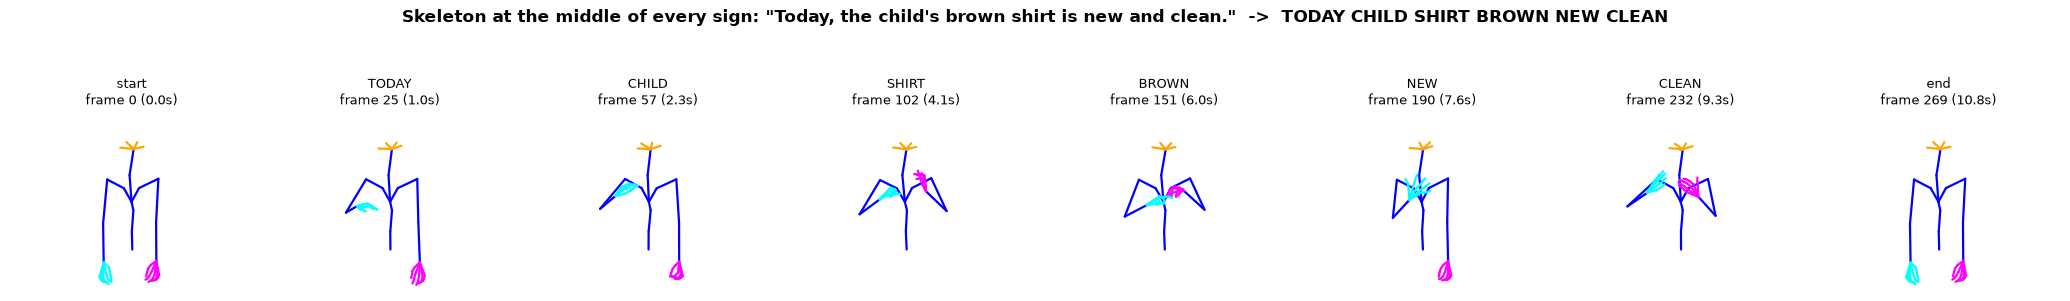

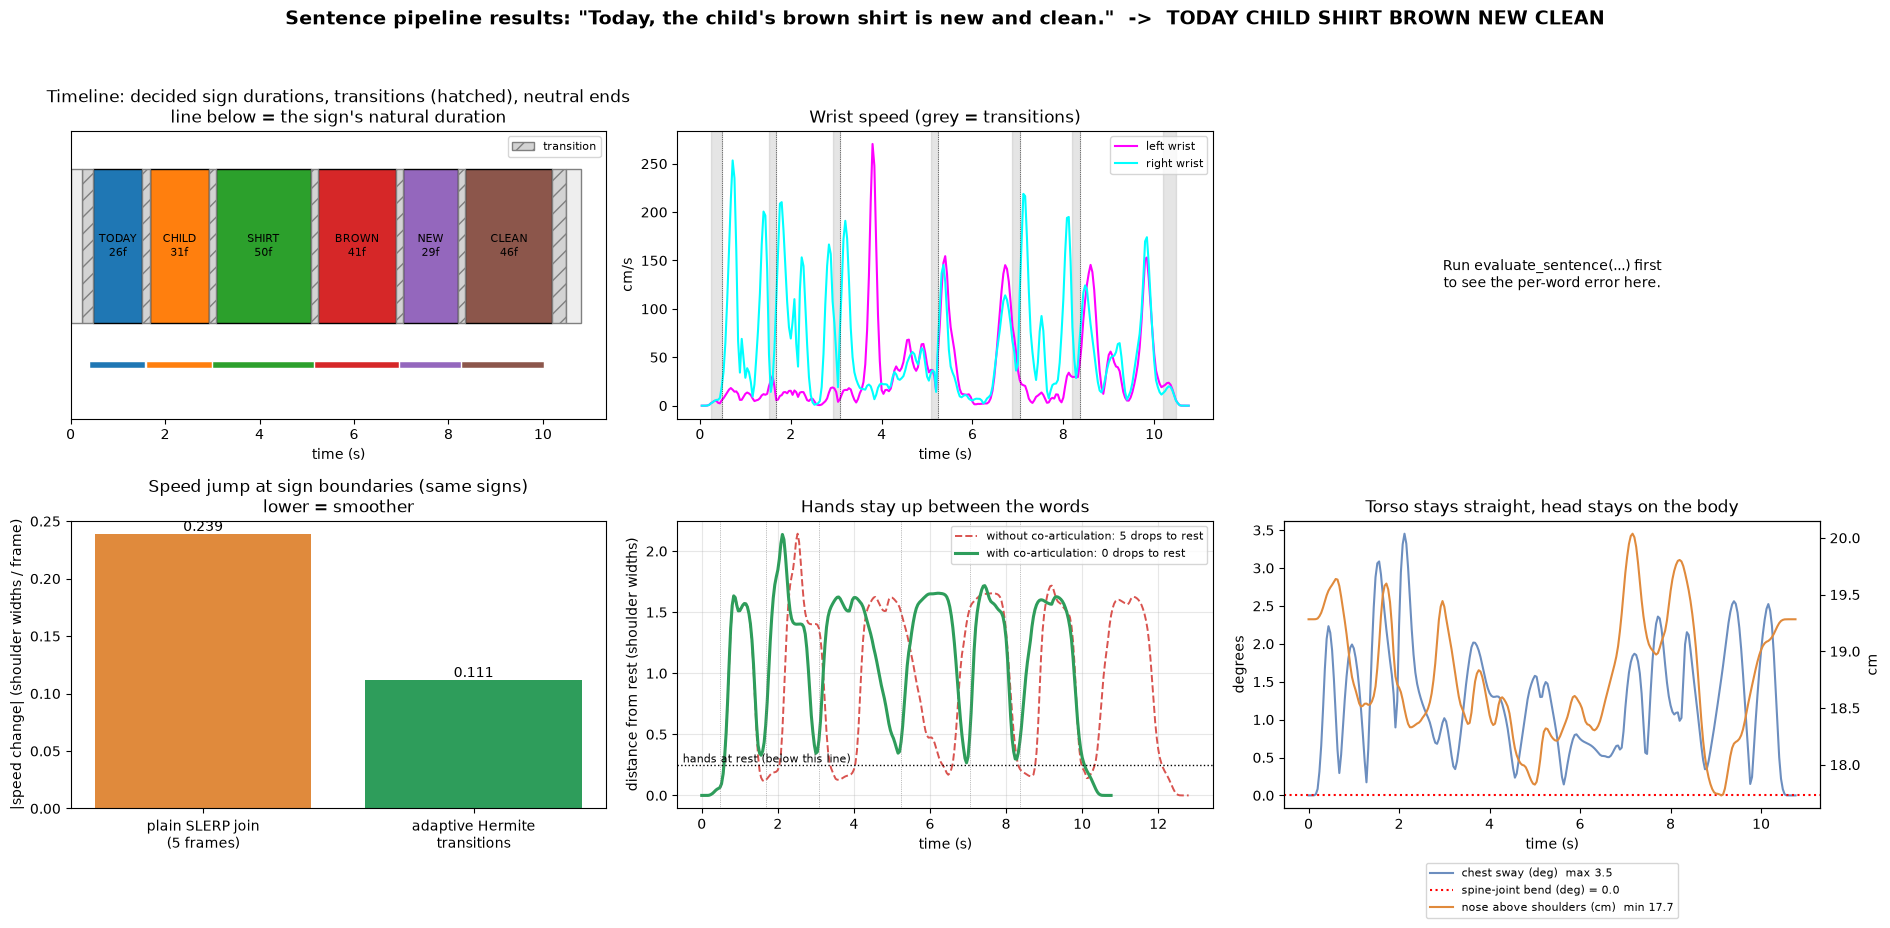

Sentence: 270 frames (10.8s) | signs 6 | transitions 7 (avg 4.7 frames) | max spine-joint bend 0.0 deg | min nose-above-shoulder 17.7 cm | boundary speed jump: SLERP 0.239 -> adaptive 0.111 | drops to rest between words: 0


In [59]:
sentence_viz = visualize_sentence(
    motion_tensor,
    LAST_SENTENCE_INFO,
    LAST_SENTENCE_EVAL,
    title=LAST_TRANSLATION["english"],
    gloss=LAST_TRANSLATION["gloss"],
)

In [ ]:
check_smplx_npz(SENTENCE_SMPLX_NPZ)

In [ ]:
export_blender_npz(SENTENCE_SMPLX_NPZ, "blender_ready_smplx.npz")

In [60]:
export_mesh_animation(SENTENCE_SMPLX_NPZ, SMPLX_MODEL_FILE, "ready_mesh_animation.npz")

Saved ready_mesh_animation.npz! Vertices: (270, 10475, 3)


# Context-aware text-to-sign translation pipeline (agentic)

7 agents: 1 NLU & Context → 2 Sign Grammar → 3 Gesture Planning (per-gloss specifications) → 4 Motion Synthesis → 5 Facial Expression → 6 Validation → 7 3D Avatar Rendering. Each agent encapsulates its own domain, state validation and execution logic.

Requires the definitions and the trained models on disk.


In [ ]:
from dataclasses import dataclass, field
from typing import Any, Dict, List, Optional, Tuple

from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

In [ ]:
# =====================================================================
# PIPELINE BLACKBOARD STATE
# =====================================================================
@dataclass
class SignTranslationState:
    """Shared state object passed along and modified across the agentic pipeline."""

    raw_input_text: str
    user_context: Dict[str, Any] = field(default_factory=dict)

    # Produced by Agent 1: NLU & Context
    disambiguated_text: Optional[str] = None
    extracted_entities: Dict[str, str] = field(default_factory=dict)
    sentence_type: str = "declarative"  # declarative, question, imperative, negation
    affect_context: str = "neutral"

    # Produced by Agent 2: Sign Grammar
    isl_gloss_sequence: List[str] = field(default_factory=list)
    raw_gloss_string: Optional[str] = None

    # Produced by Agent 3: Gesture Planning (one specification per gloss)
    gloss_specs: List[Any] = field(default_factory=list)  # GlossSpec per sign

    # Produced by Agent 4: Motion Synthesis (SMPL-X)
    motion_vector: Optional[np.ndarray] = (
        None  # (T, MOTION_DIM) 6D joint rotations + expression
    )
    smplx_params: Optional[Dict[str, np.ndarray]] = (
        None  # SMPL-X parameters (axis-angle)
    )
    gloss_sources: List[str] = field(
        default_factory=list
    )  # motion_bank / dataset / rest per gloss
    stroke_boundaries: Optional[Tuple[int, int]] = None
    fps: float = 25.0
    synthesis_timeline: List[Dict[str, Any]] = field(
        default_factory=list
    )  # lead / sign / transition / tail
    synthesis_report: Dict[str, Any] = field(default_factory=dict)

    # Produced by Agent 5: Facial Expression (writes into smplx_params)
    facial_markers: List[str] = field(default_factory=list)

    # Produced by Agent 6: Validation
    is_valid: bool = False
    validation_report: Dict[str, Any] = field(default_factory=dict)

    # Produced by Agent 7: 3D Avatar Rendering
    rendering_output_path: Optional[str] = None

In [ ]:
# =====================================================================
# AGENT 1: NLU & CONTEXT AGENT
# =====================================================================
class NLUContextAgent:
    """
    Agent 1: Disambiguates text based on context, determines question/negation
    markers, and resolves spatial or pronominal referents.

    Status: BASE IMPLEMENTATION (To be connected to LLM/Context Knowledge Base in future).
    """

    def __init__(self, use_llm_reasoning: bool = False):
        self.use_llm_reasoning = use_llm_reasoning

    def process(self, state: SignTranslationState) -> SignTranslationState:
        # FUTURE IMPLEMENTATION:
        # 1. Connect to an LLM or dependency parser to resolve ambiguities (e.g., polysemy).
        # 2. Extract conversational history / spatial deictic references.
        # 3. Detect sentence polarity (affirmative/negative) and punctuation markers.

        cleaned_text = " ".join(state.raw_input_text.strip().split())

        # Rule-based fallback for demo/pipeline connectivity
        sentence_type = detect_sentence_type(
            cleaned_text
        )  # same rule as translate_sentence_to_motion

        state.disambiguated_text = cleaned_text
        state.sentence_type = sentence_type
        state.affect_context = state.user_context.get("emotion", "neutral")

        return state


# =====================================================================
# AGENT 2: SIGN GRAMMAR AGENT
# =====================================================================
class SignGrammarAgent:
    """
    Agent 2: Converts disambiguated natural English into Indian Sign Language (ISL) gloss
    syntax (typically Time-Subject-Object-Verb), omitting functional stop words.

    Status: FULLY FUNCTIONAL (Uses your fine-tuned Flan-T5 model).
    """

    def __init__(
        self,
        model_dir: str = os.path.join(BASE_DIR, "model/include"),
        prefix: str = "translate English to ISL gloss: ",
    ):
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.prefix = prefix
        self.model_dir = model_dir

        if os.path.exists(os.path.join(model_dir, "config.json")):
            self.tokenizer = AutoTokenizer.from_pretrained(model_dir)
            self.model = (
                AutoModelForSeq2SeqLM.from_pretrained(model_dir).to(self.device).eval()
            )
        else:
            self.tokenizer = None
            self.model = None
            print(
                f"[Warning] No trained gloss model in '{model_dir}' (config.json missing): English words are used as glosses."
            )

    @torch.no_grad()
    def process(self, state: SignTranslationState) -> SignTranslationState:
        if not state.disambiguated_text:
            state.disambiguated_text = state.raw_input_text

        if self.model is None or self.tokenizer is None:
            # Fallback mock for development pipeline testing
            mock_gloss = state.disambiguated_text.upper().replace("?", "").split()
            state.raw_gloss_string = " ".join(mock_gloss)
            state.isl_gloss_sequence = mock_gloss
            return state

        input_chunk = [self.prefix + state.disambiguated_text]
        enc = self.tokenizer(
            input_chunk,
            max_length=64,
            truncation=True,
            padding=True,
            return_tensors="pt",
        ).to(self.device)

        out = self.model.generate(**enc, max_new_tokens=64, num_beams=4)
        generated_gloss = self.tokenizer.batch_decode(out, skip_special_tokens=True)[0]

        state.raw_gloss_string = " ".join(generated_gloss.strip().split()).upper()
        state.isl_gloss_sequence = state.raw_gloss_string.split()
        return state

In [ ]:
# =====================================================================
# AGENT 3: GESTURE PLANNING AGENT
# =====================================================================
class GesturePlanningAgent:
    """
    Agent 3: Maps every gloss to a per-gloss SPECIFICATION (GlossSpec): the sign performed at its natural
    speed in SMPL-X form, its natural duration, and where it came from. It does NOT join the signs; that
    is the job of the Motion Synthesis Agent (Agent 4).

    Status: FUNCTIONAL
      1. Uses the motion bank (per-word templates learned from all recordings of the word, upright
         torso guaranteed). Glosses are ALL CAPS; multi-word glosses ("GOOD MORNING") are matched as one sign.
      2. Falls back to one recorded clip of the sign from the SMPL-X .npz repository
         (one folder per gloss, case-insensitive match), with the same canonical torso and signer
         normalisation (dominant hand, resting face / head removed) as the motion bank.
      3. FINGERSPELLS (A-Z) a gloss that has no sign: hands only, the Motion Synthesis Agent takes the
         torso / head / face from the neighbouring signs (or keeps them neutral and still).
      4. Falls back to a short neutral pause for tokens that cannot be spelled (no letters A-Z).
    """

    def __init__(
        self,
        dataset_npz_dir: str = NPZ_DIR,
        motion_bank_path: str = MODEL_PATH,
        rest_frames: int = 12,
    ):
        self.dataset_npz_dir = dataset_npz_dir
        self.motion_bank_path = motion_bank_path
        self.rest_frames = rest_frames
        self._gloss_dirs = None
        self._bank = None

    def _find_gloss_dir(self, gloss: str) -> Optional[str]:
        if self._gloss_dirs is None:
            self._gloss_dirs = {}
            if os.path.isdir(self.dataset_npz_dir):
                for d in os.listdir(self.dataset_npz_dir):
                    if os.path.isdir(os.path.join(self.dataset_npz_dir, d)):
                        self._gloss_dirs[gloss_key(d)] = os.path.join(
                            self.dataset_npz_dir, d
                        )
        return self._gloss_dirs.get(gloss_key(gloss))

    def _get_bank(self):
        if self._bank is None:
            try:
                self._bank = get_motion_bank(self.motion_bank_path)
            except Exception as exc:
                print(f"[Gesture Agent] Motion bank unavailable: {exc}")
                self._bank = False
        return self._bank

    def _from_bank(self, gloss: str) -> Optional["GlossSpec"]:
        bank = self._get_bank()
        if not bank or gloss not in bank:
            return None
        key = gloss_key(gloss)
        t = bank.templates[key]
        return GlossSpec(
            key, bank.generate(key), t["n_frames"], "motion_bank", t["n_clips"]
        )

    def _from_dataset(self, gloss: str) -> Optional["GlossSpec"]:
        gloss_dir = self._find_gloss_dir(gloss)
        if gloss_dir is None:
            return None
        for npz_file in sorted(glob.glob(os.path.join(gloss_dir, "*.npz"))):
            data = np.load(npz_file)
            if data["motion_vector"].shape[-1] != MOTION_DIM:
                continue
            seg, _ = load_npz_clip(npz_file)  # canonical torso + signer normalisation
            if seg is None:
                continue
            return GlossSpec(gloss_key(gloss), seg, len(seg), "dataset", 1)
        return None

    def _fingerspell(self, gloss: str) -> Optional["GlossSpec"]:
        if not FINGERSPELL_FALLBACK or not spell_letters(gloss):
            return None
        bank = self._get_bank()
        return fingerspell_spec(gloss, bank.meta.get("neutral_pose") if bank else None)

    def _rest_spec(self, gloss: str) -> "GlossSpec":
        bank = self._get_bank()
        neutral = bank.meta.get("neutral_pose") if bank else None
        pause = (
            np.repeat(neutral, self.rest_frames, 0)
            if neutral is not None
            else rest_motion(self.rest_frames)
        )
        return GlossSpec(
            gloss_key(gloss), pause.astype(np.float32), self.rest_frames, "rest", 0
        )

    def _group(self, glosses: List[str]) -> List[str]:
        """Greedy longest match so that multi-word glosses stay one sign."""
        bank = self._get_bank()
        known = set(bank.templates) if bank else set()
        self._find_gloss_dir("")  # builds the gloss-folder index
        known |= set(self._gloss_dirs or {})
        words, out, i = [gloss_key(g) for g in glosses], [], 0
        while i < len(words):
            for n in range(min(4, len(words) - i), 0, -1):
                cand = " ".join(words[i : i + n])
                if n == 1 or cand in known:
                    out.append(cand)
                    i += n
                    break
        return out

    def process(self, state: SignTranslationState) -> SignTranslationState:
        specs = []
        for gloss in self._group(state.isl_gloss_sequence):
            spec = (
                self._from_bank(gloss)
                or self._from_dataset(gloss)
                or self._fingerspell(gloss)
                or self._rest_spec(gloss)
            )
            specs.append(spec)
        state.gloss_specs = specs
        state.gloss_sources = [f"{s.gloss}:{s.source}" for s in specs]
        state.fps = TARGET_FPS
        return state

In [ ]:
# =====================================================================
# AGENT 4: MOTION SYNTHESIS AGENT
# =====================================================================
class MotionSynthesisAgent:
    """
    Agent 4: Turns a sequence of per-gloss specifications into ONE continuous motion.

      1. DURATION   decides how long every sign lasts: its natural duration (median of the recordings),
                    normalised to the rhythm of the sentence, scaled by the emotional context (affect),
                    with phrase-final lengthening (a little longer for questions / negations).
      2. PERFORMANCE performs each sign naturally: slow-in / slow-out timing, torso upright, hands and
                    face exactly as learned from the recordings.
      3. TRANSITIONS generates a transition between every two consecutive signs. Its length adapts to how
                    far the hands have to travel, and it is a cubic Hermite curve in rotation space that
                    matches the speed at the end of one sign and at the start of the next (no jump, no
                    stop-and-go). The sentence starts and ends at a neutral hands-down pose.

    Output: state.motion_vector / state.smplx_params (one continuous animation), state.stroke_boundaries
    (first to last frame of signing), state.synthesis_timeline (every segment with its frames) and
    state.synthesis_report (durations, transitions, smoothness).

    Status: FUNCTIONAL (engine = MotionSynthesizer, defined in the sentence cell)
    """

    def __init__(
        self,
        motion_bank_path: str = MODEL_PATH,
        base_speed: float = 1.0,
        natural: bool = True,
        rest_ends: bool = True,
        fixed_transition: Optional[int] = None,
    ):
        self.motion_bank_path = motion_bank_path
        self.base_speed = base_speed
        self.natural = natural
        self.rest_ends = rest_ends
        self.fixed_transition = fixed_transition

    def _neutral_pose(self) -> Optional[np.ndarray]:
        if not self.rest_ends:
            return None
        try:
            return get_motion_bank(self.motion_bank_path).meta.get("neutral_pose")
        except Exception:
            return None

    def process(self, state: SignTranslationState) -> SignTranslationState:
        if not state.gloss_specs:
            print(
                "[Motion Synthesis Agent] No gloss specifications received -> nothing to synthesize."
            )
            return state

        synth = MotionSynthesizer(
            fps=state.fps,
            base_speed=self.base_speed,
            natural=self.natural,
            neutral_pose=self._neutral_pose(),
            fixed_transition=self.fixed_transition,
        )
        motion, info = synth.synthesize(
            state.gloss_specs,
            sentence_type=state.sentence_type,
            affect=state.affect_context,
        )

        signs, trans = info["signs"], info["transitions"]
        feat_speed = np.linalg.norm(np.diff(clip_features(motion), axis=0), axis=1)
        jumps = [
            abs(feat_speed[b] - feat_speed[b - 1])
            for tr in trans
            for b in (tr["start"], tr["end"])
            if 1 <= b < len(feat_speed)
        ]
        state.motion_vector = motion
        state.smplx_params = motion_vector_to_smplx(motion)
        state.stroke_boundaries = (signs[0]["start"], signs[-1]["end"] - 1)
        state.synthesis_timeline = info["segments"]
        state.synthesis_report = {
            "total_frames": info["total_frames"],
            "total_seconds": round(info["total_frames"] / state.fps, 2),
            "sign_frames": {s["gloss"]: s["frames"] for s in signs},
            "natural_frames": {
                s["gloss"]: round(s["nominal_frames"], 1) for s in signs
            },
            "transition_frames": [t["frames"] for t in trans],
            "hands_dropped_to_rest_between_signs": info["rest_dips"]["runs"],
            "fingerspelled": info["fingerspelled"],
            "continuity": {k: round(v, 2) for k, v in info["continuity"].items()},
            "mean_boundary_speed_jump": (
                round(float(np.mean(jumps)), 4) if jumps else 0.0
            ),
            "tempo_context": {
                "sentence_type": state.sentence_type,
                "affect": state.affect_context,
            },
        }
        return state

In [ ]:
# =====================================================================
# AGENT 5: FACIAL EXPRESSION AGENT
# =====================================================================
def expression_for_brow_raise(
    amount_m: float = 0.008, device: str = "cpu"
) -> Optional[np.ndarray]:
    """
    SMPL-X expression vector that raises both eyebrows by `amount_m` metres while keeping
    the other face landmarks still. Solved by ridge least squares on the expression basis.
    Returns None when the SMPL-X model file is not available.
    """
    model = get_smplx_model(device)
    if model is None:
        return None
    with torch.no_grad():
        basis = torch.cat(
            [torch.zeros(1, SMPLX_NUM_EXPRESSION), torch.eye(SMPLX_NUM_EXPRESSION)]
        ).to(device)
        lm = (
            smplx_face_landmarks(
                model, basis, torch.zeros(len(basis), 3, device=device)
            )
            .cpu()
            .numpy()
        )
    J = (lm[1:] - lm[:1]).reshape(SMPLX_NUM_EXPRESSION, -1).T  # (51*3, 10)
    target = np.zeros((51, 3))
    target[FACE_BROW_51, 1] = amount_m
    weights = np.full((51, 3), 0.3)
    weights[FACE_BROW_51] = 1.0
    W = weights.reshape(-1)
    A = J * W[:, None]
    b = target.reshape(-1) * W
    lam = 1e-6
    psi = np.linalg.solve(A.T @ A + lam * np.eye(SMPLX_NUM_EXPRESSION), A.T @ b)
    return np.clip(psi, -EXPRESSION_CLIP, EXPRESSION_CLIP).astype(np.float32)


class FacialExpressionAgent:
    """
    Agent 5: Adds grammatical non-manual markers on top of the signed motion:
      - questions: raised eyebrows (SMPL-X expression)
      - negation:  side-to-side head shake (SMPL-X head joint, yaw)
    The expression and head motion recorded with each sign are kept.

    Status: BASE IMPLEMENTATION
    """

    def __init__(
        self,
        brow_raise_m: float = 0.008,
        shake_amplitude_rad: float = 0.25,
        shake_cycles: float = 2.0,
    ):
        self.brow_raise_m = brow_raise_m
        self.shake_amplitude_rad = shake_amplitude_rad
        self.shake_cycles = shake_cycles
        self._brow_expr = None

    def process(self, state: SignTranslationState) -> SignTranslationState:
        if state.smplx_params is None:
            return state

        params = {k: np.array(v, copy=True) for k, v in state.smplx_params.items()}
        total_frames = params["global_orient"].shape[0]
        markers = []

        # In ISL: Questions require raised eyebrows; negations require head-shaking
        if state.sentence_type == "interrogative":
            if self._brow_expr is None:
                self._brow_expr = expression_for_brow_raise(self.brow_raise_m)
            if self._brow_expr is not None:
                params["expression"] = np.clip(
                    params["expression"] + self._brow_expr[None, :],
                    -EXPRESSION_CLIP,
                    EXPRESSION_CLIP,
                )
                markers.append("brow_raise")
            else:
                print("[Facial Agent] SMPL-X model not found -> brow raise skipped.")
        elif state.sentence_type == "negation":
            # shake only while the signs are performed (not during the neutral lead-in / tail), faded in and out
            s0, s1 = state.stroke_boundaries or (0, total_frames - 1)
            n_span = max(int(s1 - s0 + 1), 2)
            t = np.zeros(total_frames)
            t[s0 : s1 + 1] = np.linspace(0, 2 * np.pi * self.shake_cycles, n_span)
            envelope = np.zeros(total_frames)
            envelope[s0 : s1 + 1] = np.sin(np.pi * np.linspace(0, 1, n_span)) ** 0.5
            shake = R.from_rotvec(
                np.stack(
                    [
                        np.zeros_like(t),
                        self.shake_amplitude_rad * envelope * np.sin(t),
                        np.zeros_like(t),
                    ],
                    1,
                )
            )
            head_idx = (
                SMPLX_JOINT_INDEX["head"] - 1
            )  # body_pose index of the head joint
            head = R.from_rotvec(params["body_pose"][:, head_idx])
            params["body_pose"][:, head_idx] = (head * shake).as_rotvec()
            markers.append("head_shake")

        state.smplx_params = params
        state.motion_vector = smplx_to_motion_vector(params)
        state.facial_markers = markers
        return state

In [ ]:
# =====================================================================
# AGENT 6: VALIDATION AGENT
# =====================================================================
class ValidationAgent:
    """
    Agent 6: Validates generated SMPL-X animations for biomechanical continuity
    (joint speed from forward kinematics) and elbow joint limits.

    Status: BASE IMPLEMENTATION
    """

    def __init__(
        self,
        max_joint_speed_m_per_s: float = 6.0,
        max_elbow_deg: float = 170.0,
        max_landmark_accel_cm: float = 10.0,
    ):
        self.max_joint_speed = max_joint_speed_m_per_s
        self.max_elbow_deg = max_elbow_deg
        # a single-frame jump of any landmark (joint, fingertip or face point) between words shows up as a
        # spike in its acceleration; smooth signing stays far below this
        self.max_landmark_accel = max_landmark_accel_cm

    def process(self, state: SignTranslationState) -> SignTranslationState:
        has_motion = state.smplx_params is not None
        report = {
            "has_gloss": bool(state.isl_gloss_sequence),
            "has_motion": has_motion,
            "motion_frame_count": (
                state.smplx_params["global_orient"].shape[0] if has_motion else 0
            ),
            "gloss_sources": state.gloss_sources,
            "passed_kinematic_check": True,
        }

        if has_motion and report["motion_frame_count"] > 1:
            joints_3d, _ = smplx_forward_kinematics(state.smplx_params)
            upper = [j for j in range(55) if j not in LEG_JOINTS]
            speed = (
                np.linalg.norm(np.diff(joints_3d[:, upper], axis=0), axis=-1)
                * state.fps
            )
            report["max_joint_speed_m_per_s"] = float(np.max(speed))
            if report["max_joint_speed_m_per_s"] > self.max_joint_speed:
                report["passed_kinematic_check"] = False
                report["warning"] = "Jerky motion detected between sign boundaries."

            body = state.smplx_params["body_pose"]
            elbows = np.degrees(
                np.linalg.norm(body[:, [17, 18]], axis=-1)
            )  # SMPL-X joints 18/19
            report["max_elbow_deg"] = float(np.max(elbows))
            if report["max_elbow_deg"] > self.max_elbow_deg:
                report["passed_kinematic_check"] = False
                report["warning"] = (
                    report.get("warning", "") + " Elbow beyond joint limit."
                )

        # Continuity of EVERY landmark (no jitter / sudden change at the word boundaries)
        if (
            has_motion
            and state.motion_vector is not None
            and len(state.motion_vector) > 2
        ):
            cont = motion_continuity(state.motion_vector, state.fps)
            report["max_landmark_accel_cm_per_frame2"] = round(
                cont["max_accel_cm_per_frame2"], 2
            )
            report["passed_continuity_check"] = bool(
                cont["max_accel_cm_per_frame2"] <= self.max_landmark_accel
            )
            if not report["passed_continuity_check"]:
                report["warning"] = (
                    report.get("warning", "") + " Sudden landmark jump detected."
                )

        # Posture: spine must stay straight and the head on the body
        if (
            has_motion
            and state.motion_vector is not None
            and len(state.motion_vector) > 1
        ):
            mv = np.asarray(state.motion_vector, np.float32)
            Rm = motion_to_R(mv)
            spine_bend = max(
                np.degrees(
                    np.linalg.norm(R.from_matrix(Rm[:, _KJ[n]]).as_rotvec(), axis=1)
                ).max()
                for n in ("spine1", "spine2", "spine3")
            )
            report["max_spine_bend_deg"] = float(spine_bend)
            report["head_above_shoulders_pct"] = float(
                100 * head_above_shoulders_ratio(mv)
            )
            report["passed_posture_check"] = bool(
                spine_bend <= 5.0 and report["head_above_shoulders_pct"] >= 99.9
            )
            if not report["passed_posture_check"]:
                report["warning"] = (
                    report.get("warning", "") + " Torso bends or head leaves the body."
                )

        state.is_valid = (
            report["has_gloss"]
            and report["has_motion"]
            and report["passed_kinematic_check"]
            and report.get("passed_posture_check", True)
            and report.get("passed_continuity_check", True)
        )
        state.validation_report = report
        return state

In [ ]:
# =====================================================================
# AGENT 7: 3D AVATAR RENDERING AGENT
# =====================================================================
class AvatarRenderingAgent:
    """
    Agent 7: Exports the validated SMPL-X parameters for a 3D engine
    (Blender SMPL-X add-on, Unity/Unreal SMPL-X rigs, aitviewer, Three.js) and
    optionally renders a skeleton preview MP4.

    Status: FUNCTIONAL export + preview (mesh rendering is engine-side).
    """

    def __init__(
        self,
        output_dir: str = os.path.join(SMPLX_OUTPUT_DIR, "avatar"),
        render_preview: bool = False,
    ):
        self.output_dir = output_dir
        self.render_preview = render_preview

    def process(self, state: SignTranslationState) -> SignTranslationState:
        if not state.is_valid:
            print(
                f"[Render Agent] Aborting render: State validation failed: {state.validation_report}"
            )
            return state

        os.makedirs(self.output_dir, exist_ok=True)
        slug = (
            re.sub(r"[^A-Za-z0-9]+", "_", state.raw_gloss_string or "sentence").strip(
                "_"
            )[:60]
            or "sentence"
        )
        output_path = os.path.join(self.output_dir, f"{slug}.npz")

        # Standard SMPL-X parameter layout (neutral, flat_hand_mean=True, use_pca=False)
        save_smplx_npz(
            output_path,
            state.smplx_params,
            fps=state.fps,
            gloss_sequence=np.array(state.raw_gloss_string or ""),
            sentence_type=np.array(state.sentence_type),
            facial_markers=np.array(",".join(state.facial_markers)),
            motion_vector=state.motion_vector,
        )
        state.rendering_output_path = output_path
        print(f"[Render Agent] SMPL-X animation data compiled to {output_path}")

        if self.render_preview:
            preview = os.path.join(PREDICTED_DIR, f"{slug}_skeleton_preview.mp4")
            render_smplx_skeleton_video(
                state.smplx_params,
                preview,
                fps=state.fps,
                title=f"Gloss: {state.raw_gloss_string}",
            )
            print(f"[Render Agent] Skeleton preview saved to {preview}")
        return state

In [ ]:
# =====================================================================
# AGENT ORCHESTRATOR / PIPELINE COORDINATOR
# =====================================================================
class TextToSignAgenticPipeline:
    """Pipeline coordinator orchestrating sequential communication between all agents."""

    def __init__(
        self,
        model_dir: str = os.path.join(BASE_DIR, "model/include"),
        dataset_npz_dir: str = NPZ_DIR,
        render_preview: bool = False,
    ):
        self.nlu_agent = NLUContextAgent()
        self.grammar_agent = SignGrammarAgent(model_dir=model_dir)
        self.gesture_agent = GesturePlanningAgent(dataset_npz_dir=dataset_npz_dir)
        self.synthesis_agent = MotionSynthesisAgent()
        self.facial_agent = FacialExpressionAgent()
        self.validation_agent = ValidationAgent()
        self.render_agent = AvatarRenderingAgent(render_preview=render_preview)

    def translate(
        self, text: str, context: Optional[Dict[str, Any]] = None
    ) -> SignTranslationState:
        state = SignTranslationState(raw_input_text=text, user_context=context or {})

        # Sequentially route state through the agent chain
        state = self.nlu_agent.process(state)
        state = self.grammar_agent.process(state)
        state = self.gesture_agent.process(state)
        state = self.synthesis_agent.process(state)
        state = self.facial_agent.process(state)
        state = self.validation_agent.process(state)
        state = self.render_agent.process(state)

        return state

In [ ]:
# (named sign_pipeline so it does not overwrite transformers.pipeline used by the annotation cell)
sign_pipeline = TextToSignAgenticPipeline(
    model_dir=os.path.join(BASE_DIR, "model/include"), render_preview=True
)

input_sentence = "Will you go to the hospital tomorrow?"
context = {"emotion": "questioning", "signer_id": "avatar_01"}

print(f"\n--- Running Translation Pipeline for: '{input_sentence}' ---")
result_state = sign_pipeline.translate(input_sentence, context=context)

print("\n--- Pipeline Execution Summary ---")
print(f"Sentence Type Identified: {result_state.sentence_type}")
print(f"Predicted ISL Gloss:       {result_state.raw_gloss_string}")
print(f"Gloss Sources:             {result_state.gloss_sources}")
print(f"Synthesis Report:          {result_state.synthesis_report}")
print(f"Facial Markers:            {result_state.facial_markers}")
print(f"Validation Status:         {result_state.is_valid}")
print(f"Validation Report:         {result_state.validation_report}")
print(f"Render Output File:        {result_state.rendering_output_path}")

# Blender script

This cell must be run **inside Blender's Python console / text editor** (it needs `bpy`), not in Jupyter, after `ready_mesh_animation.npz` has been created. Adjust the Windows path to where that file was saved.


In [ ]:
# Run this inside Blender (needs bpy) - NOT in Jupyter.
import bpy
import numpy as np

# Load your generated mesh animation
data = np.load(
    r"ready_mesh_animation.npz"
)
verts = data["verts"]  # (274, 10475, 3)
faces = data["faces"].tolist()  # (20908, 3)

# Grab ONLY the first frame (10,475 vertices) safely using next(iter())
first_frame_verts = next(iter(verts)).tolist()

# Build the base 3D human mesh
mesh = bpy.data.meshes.new("SignAvatarMesh")
obj = bpy.data.objects.new("SignAvatar", mesh)
bpy.context.collection.objects.link(obj)
mesh.from_pydata(first_frame_verts, [], faces)
mesh.update()

# Rotate upright (SMPL-X is Y-up, Blender is Z-up)
obj.rotation_euler = (1.5708, 0.0, 0.0)

# Add Basis shape key + animate remaining frames
obj.shape_key_add(name="Basis", from_mix=False)

for i, frame_verts in enumerate(verts):
    if i == 0:
        continue
    sk = obj.shape_key_add(name=f"F_{i}", from_mix=False)
    sk.data.foreach_set("co", frame_verts.ravel())

    sk.value = 0.0
    sk.keyframe_insert("value", frame=i)
    sk.value = 1.0
    sk.keyframe_insert("value", frame=i + 1)
    sk.value = 0.0
    sk.keyframe_insert("value", frame=i + 2)

bpy.context.scene.frame_start = 1
bpy.context.scene.frame_end = len(verts)
bpy.context.scene.render.fps = 25
print("Success! Loaded all", len(verts), "frames.")